# Parotid Gland Segmentation — UltraSam (patient/group leakage-controlled)
## Corrected version of `21_UltraSam_Parotid_TransferLearning_FrozenBackbone.ipynb`

This notebook is adapted to the `DATASET PG` folder structure:

```text
DATASET PG/
├── NORMAL PG/
├── benign PG/
│   ├── DRAW IMAGE/
│   ├── IMAGE/
│   └── LABEL/
└── malignant PG/
    ├── DRAW IMAGE/
    ├── IMAGE/
    └── LABEL/
```

### Main corrections in this version
- The label encoding is handled explicitly. For the example labels (`0` background, `127` parotid, `255` lesion), the default target is **whole parotid**, so pixels `>=127` are foreground. Set `MASK_TARGET="lesion_only"` to segment only the white `255` lesion.
- COCO masks are exported as **RLE**, avoiding contour simplification errors.
- Disconnected foreground components are exported as separate instances, so left/right parotid glands receive separate boxes.
- The UltraSam ViT-B encoder is no longer completely frozen. The default unfreezes the last **4 transformer blocks + channel-reduction neck**, while keeping earlier image-encoder layers frozen.
- The image encoder uses a lower effective learning rate (`0.1 ×` the decoder/prompt LR).
- Training is extended to 20,000 iterations with validation every 250 iterations and best-checkpoint selection by validation Dice.
- The custom evaluator can **union all predicted instance masks** for whole-parotid segmentation rather than discarding the second gland.

**Important:** UltraSam was pretrained on ultrasound. If these data are MRI, this experiment is cross-modality transfer learning. Partial image-encoder adaptation is therefore intentional.

**Jupyter kernel:** `Python (UltraSam)`


**This revision replaces the previous slice-level split with leakage-controlled case grouping and duplicate-aware splitting.**


## UltraSam transfer learning — partial ViT fine-tuning

The released `UltraSam.pth` checkpoint is used for initialization. Instead of freezing the full ViT image encoder, this notebook freezes the early encoder and fine-tunes the last `UNFREEZE_LAST_N_BLOCKS` transformer blocks plus the channel-reduction module.

Default optimization:
- decoder / prompt modules: `BASE_LR = 1e-4`
- image encoder: `ENCODER_LR_MULT = 0.1` → effective LR `1e-5`
- AdamW weight decay: `1e-4`
- gradient accumulation: 8
- validation every 250 iterations
- checkpoint selection: `pg/Dice`

Validation/test remain **GT-box prompted**, so the results must be reported as prompted segmentation rather than fully automatic segmentation.


## 1. Setup: environment, imports, device check, experiment configuration

In [1]:
# UltraSam requires the dedicated OpenMMLab environment.
# Do not install/upgrade CUDA/PyTorch packages inside another benchmark environment.
#
# Required Jupyter kernel:
#     Python (UltraSam)

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
    print("Local Windows/Jupyter mode detected.")


Local Windows/Jupyter mode detected.


In [8]:
import os
import gc
import re
import json
import copy
import math
import time
import random
import datetime
import warnings
import hashlib
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from collections import defaultdict, Counter

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from scipy.ndimage import binary_erosion, distance_transform_edt, generate_binary_structure
from scipy.spatial.distance import directed_hausdorff

import albumentations as A
from tqdm.auto import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| Albumentations:", A.__version__)
print("Using device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0),
          f"({torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB)")
else:
    print("No GPU detected — training will run on CPU and AMP will be disabled.")

PyTorch: 2.0.0+cu118 | Albumentations: 1.4.18
Using device: cuda
GPU: NVIDIA GeForce RTX 4070 Laptop GPU (8.0 GB)


### Experiment configuration

The important settings for this corrected notebook are concentrated in the next cell.

| Setting | Default | Purpose |
|---|---:|---|
| `MASK_TARGET` | `whole_parotid` | uses gray (`127`) + white (`255`) label pixels |
| `UNFREEZE_LAST_N_BLOCKS` | 4 | adapts UltraSam to the parotid MRI appearance without full-backbone overfitting |
| `BASE_LR` | `1e-4` | prompt/mask-module learning rate |
| `ENCODER_LR_MULT` | `0.1` | ViT learning rate multiplier (`1e-5`) |
| `ULTRASAM_MAX_ITERS` | 20000 | longer adaptation than the original 10k run |
| `ULTRASAM_VAL_INTERVAL` | 250 | closer tracking of validation Dice |
| `MIN_COMPONENT_PIXELS` | 20 | removes tiny label speckles before instance export |

If your scientific target is specifically the tumor/lesion rather than the whole parotid, change only:

```python
MASK_TARGET = "lesion_only"
```

The rest of the pipeline will adapt automatically.


In [3]:
# =====================================================================
# IMPROVED ULTRASAM PAROTID CONFIGURATION
# =====================================================================
MODEL_NAME = "UltraSam-PartialFT"
MODEL_KEY = "ultrasam_box_prompt_partial_finetune"
PRETRAINED = True

# ---------------- data ----------------
IMAGE_SIZE = 1024
CMP_SIZE = 224
SPLIT_SEED = 42
SEED = 42
INCLUDE_NORMAL_IN_TRAINING = True

# ---------------- leakage-safe grouping/splitting ----------------
# The original notebook used a slice-level split. This version groups slices by
# inferred patient/case ID and additionally merges verified duplicate/near-duplicate
# images before splitting, so a case or duplicate cluster cannot cross splits.
SPLIT_MODE = "patient_group_no_leakage"
TRAIN_FRACTION = 0.80
VALID_FRACTION = 0.10
TEST_FRACTION = 0.10

# Case-ID inference removes the final numeric slice token from the filename.
# Examples:
#   209-1-8.png -> 209-1
#   94.1.4.png  -> 94.1
#   9.13.png    -> 9
# Category is included in the initial case key because case numbering may restart
# in NORMAL / benign / malignant folders. Verified duplicate matching can still
# merge groups across categories.
CASE_ID_MODE = "filename_without_last_numeric_token"

# Two-stage near-duplicate verification:
# 1) 16x16 difference-hash candidate filter
# 2) high SSIM confirmation on normalized 128x128 grayscale images
# This is deliberately stricter than using dHash<=5 alone, which can over-group
# anatomically similar MRI slices.
DUPLICATE_GROUPING = True
DUP_DHASH_SIZE = 16
DUP_DHASH_MAX = 6
DUP_SSIM_MIN = 0.985

# Exact same image appearing under conflicting clinical categories is quarantined
# from model development by default and written to a QC CSV.
EXCLUDE_EXACT_CROSS_CATEGORY_CONFLICTS = True

# A new split file is used; the old slice-level split is never overwritten.

# Label encoding seen in the supplied example:
#   0   = background
#   127 = parotid gland
#   255 = lesion/tumour annotation inside the gland
# Default notebook goal = PAROTID GLAND segmentation.
MASK_TARGET = "whole_parotid"      # choices: "whole_parotid", "lesion_only"
WHOLE_PAROTID_THRESHOLD = 127
LESION_THRESHOLD = 250
MIN_COMPONENT_PIXELS = 20

# ---------------- transfer learning ----------------
UNFREEZE_LAST_N_BLOCKS = 4         # ViT-B has 12 transformer blocks
BASE_LR = 1e-4
ENCODER_LR_MULT = 0.1              # backbone effective LR = 1e-5
WEIGHT_DECAY = 1e-4
GRAD_ACCUMULATION = 8
ULTRASAM_MAX_ITERS = 20000
ULTRASAM_VAL_INTERVAL = 250
WARMUP_ITERS = 500

# whole_parotid can have two prompts / two predicted masks, so union them for pixel metrics.
PREDICTION_AGGREGATION = "union" if MASK_TARGET == "whole_parotid" else "best"

# Reproducibility / Windows
DETERMINISTIC = False
NUM_WORKERS = 0 if os.name == "nt" else 2

# Optional smoke test
SMOKE_TEST = os.environ.get("PAROTID_SMOKE_TEST", "0") == "1"
if SMOKE_TEST:
    ULTRASAM_MAX_ITERS = 50
    ULTRASAM_VAL_INTERVAL = 25

if MASK_TARGET not in {"whole_parotid", "lesion_only"}:
    raise ValueError("MASK_TARGET must be 'whole_parotid' or 'lesion_only'.")
if not (0 <= UNFREEZE_LAST_N_BLOCKS <= 12):
    raise ValueError("UNFREEZE_LAST_N_BLOCKS must be between 0 and 12 for ViT-B.")

print(f"{MODEL_NAME} | target={MASK_TARGET} | {IMAGE_SIZE}px | seed={SEED}")
print(f"ViT blocks unfrozen: last {UNFREEZE_LAST_N_BLOCKS}/12")
print(f"LR decoder/prompt={BASE_LR:g} | encoder={BASE_LR*ENCODER_LR_MULT:g}")
print(f"Iterations={ULTRASAM_MAX_ITERS:,} | validation every {ULTRASAM_VAL_INTERVAL}")


UltraSam-PartialFT | target=whole_parotid | 1024px | seed=42
ViT blocks unfrozen: last 4/12
LR decoder/prompt=0.0001 | encoder=1e-05
Iterations=20,000 | validation every 250


## 2. Build the dataset DataFrame

The next two cells are copied **verbatim** from `08_CMUNeXt_Large_Parotid_FIXED.ipynb` (paths, `NORMAL PG / benign PG / malignant PG` layout, stem-based image/label pairing), so `df` and every relative path are identical to the CMUNeXt run. The third cell only inspects the masks before the COCO export.


In [4]:
# ============================================================
# PAROTID GLAND DATASET - COLAB + LOCAL MACHINE
# ============================================================
import os
import sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    project_root = "/content/drive/MyDrive/PGT-MRI"
    base_dir = "/content/drive/MyDrive/PGT-MRI/DATASET PG"
else:
    project_root = r"C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models"
    base_dir = r"C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models\DATASET PG"

project_root = os.environ.get("PAROTID_PROJECT_ROOT", project_root)
base_dir = os.environ.get("PAROTID_DATASET_ROOT", base_dir)

# Required by pretrained model builders.
weights_dir = os.path.join(project_root, "pretrained_weights")
benchmark_root = os.path.join(project_root, "parotid_pg_benchmark")
os.makedirs(weights_dir, exist_ok=True)
os.makedirs(benchmark_root, exist_ok=True)

normal_image_dir = os.path.join(base_dir, "NORMAL PG", "image")
normal_label_dir = os.path.join(base_dir, "NORMAL PG", "label")
normal_draw_dir = os.path.join(base_dir, "NORMAL PG", "draw image")
benign_image_dir = os.path.join(base_dir, "benign PG", "IMAGE")
benign_label_dir = os.path.join(base_dir, "benign PG", "LABEL")
benign_draw_dir = os.path.join(base_dir, "benign PG", "DRAW IMAGE")
malignant_image_dir = os.path.join(base_dir, "malignant PG", "IMAGE")
malignant_label_dir = os.path.join(base_dir, "malignant PG", "LABEL")
malignant_draw_dir = os.path.join(base_dir, "malignant PG", "DRAW IMAGE")

print("Environment:", "Colab" if IN_COLAB else "Local")
print("Dataset root:", base_dir)
print("Weights directory:", weights_dir)
print("Benchmark root:", benchmark_root)


Environment: Local
Dataset root: C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models\DATASET PG
Weights directory: C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models\pretrained_weights
Benchmark root: C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models\parotid_pg_benchmark


In [5]:
# ============================================================
# PAROTID DATA PIPELINE
# ============================================================
data = []
dataset_folders = {
    "normal": {"image": normal_image_dir, "label": normal_label_dir, "draw": normal_draw_dir},
    "benign": {"image": benign_image_dir, "label": benign_label_dir, "draw": benign_draw_dir},
    "malignant": {"image": malignant_image_dir, "label": malignant_label_dir, "draw": malignant_draw_dir},
}
VALID_EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

def _files_by_stem(folder):
    result = {}
    for filename in sorted(os.listdir(folder)):
        path = os.path.join(folder, filename)
        stem, ext = os.path.splitext(filename)
        if os.path.isfile(path) and ext.lower() in VALID_EXTENSIONS:
            result[stem.lower()] = path
    return result

for category, paths in dataset_folders.items():
    for kind, folder in paths.items():
        if not os.path.isdir(folder):
            raise FileNotFoundError(f"Missing {category} {kind} folder: {folder}")
    images = _files_by_stem(paths["image"])
    labels = _files_by_stem(paths["label"])
    draws = _files_by_stem(paths["draw"])
    common = sorted(set(images) & set(labels))
    if len(common) == 0:
        print(f"WARNING: no matched image/mask pairs for {category}")
    missing_masks = set(images) - set(labels)
    if missing_masks:
        print(f"WARNING [{category}]: {len(missing_masks)} image(s) have no matching mask.")
    for stem in common:
        data.append({
            "Category": category,
            "Image_Path": images[stem],
            "Label_Path": labels[stem],
            "Draw_Image_Path": draws.get(stem),
        })

if not data:
    raise RuntimeError("No matched image/mask pairs found in DATASET PG.")

df = pd.DataFrame(data)
df = df.sample(frac=1, random_state=SPLIT_SEED).reset_index(drop=True)
df["Rel_Image"] = df["Image_Path"].apply(lambda p: os.path.relpath(p, base_dir).replace("\\", "/"))
df["Rel_Label"] = df["Label_Path"].apply(lambda p: os.path.relpath(p, base_dir).replace("\\", "/"))
print(df["Category"].value_counts())
print("Total matched samples:", len(df))


WARNING [benign]: 5 image(s) have no matching mask.
Category
benign       1522
normal        366
malignant     217
Name: count, dtype: int64
Total matched samples: 2105


In [6]:
# ---------------------------------------------------------------------------
# Mask decoding + sanity check.
# ---------------------------------------------------------------------------
def label_to_binary(mask, target=MASK_TARGET):
    """Convert the original grayscale label into the selected binary target."""
    mask = np.asarray(mask)
    if target == "whole_parotid":
        # Includes both the gray gland (127) and white lesion (255).
        return (mask >= WHOLE_PAROTID_THRESHOLD).astype(np.uint8)
    if target == "lesion_only":
        # Keeps only the white lesion/tumour region.
        return (mask >= LESION_THRESHOLD).astype(np.uint8)
    raise ValueError(f"Unknown MASK_TARGET: {target}")

_stats = []
_unique_examples = set()
for r in tqdm(df.itertuples(index=False), total=len(df), desc="Checking masks"):
    m = cv2.imread(r.Label_Path, cv2.IMREAD_GRAYSCALE)
    im = cv2.imread(r.Image_Path, cv2.IMREAD_GRAYSCALE)
    if m is None or im is None:
        raise IOError(f"Cannot read {r.Image_Path} or {r.Label_Path}")
    vals = tuple(int(x) for x in np.unique(m))
    if len(_unique_examples) < 12:
        _unique_examples.add(vals)
    binary = label_to_binary(m)
    _stats.append({
        "Category": r.Category,
        "fg_pixels": int(binary.sum()),
        "mask_min": int(m.min()),
        "mask_max": int(m.max()),
        "unique_values": vals,
        "size_mismatch": m.shape != im.shape,
    })

mask_stats = pd.DataFrame(_stats)
mask_stats["has_object"] = mask_stats["fg_pixels"] > 0

print("MASK_TARGET:", MASK_TARGET)
print("Observed label-value patterns (sample):", sorted(_unique_examples)[:12])
print("\nImages with a non-empty selected target mask:")
print(pd.crosstab(mask_stats["Category"],
                  mask_stats["has_object"].map({True: "non-empty", False: "empty"}),
                  margins=True))

n_mis = int(mask_stats["size_mismatch"].sum())
print(f"\nMasks whose size differs from image: {n_mis}")

# Explicit warning for the supplied 0/127/255 encoding.
contains_127 = any(127 in vals for vals in mask_stats["unique_values"])
contains_255 = any(255 in vals for vals in mask_stats["unique_values"])
if contains_127 and contains_255:
    print("Detected masks containing both 127 and 255.")
    if MASK_TARGET == "whole_parotid":
        print("Correct behavior: both 127 and 255 are included as parotid foreground.")
    else:
        print("Lesion-only mode: 127 gland pixels are intentionally excluded; 255 is foreground.")


Checking masks: 100%|██████████| 2105/2105 [01:30<00:00, 23.28it/s]

MASK_TARGET: whole_parotid
Observed label-value patterns (sample): [(0, 32, 44, 53, 58, 61, 65, 69, 73, 85, 255), (0, 32, 44, 61, 65, 76, 85), (0, 36, 49, 59, 67, 127), (0, 36, 49, 59, 67, 127, 255), (0, 36, 59, 67, 127), (0, 36, 59, 67, 127, 255), (0, 49, 67, 127, 255), (0, 67, 127, 255), (0, 85), (0, 85, 255), (0, 127), (0, 127, 255)]

Images with a non-empty selected target mask:
has_object  empty  non-empty   All
Category                          
benign          0       1522  1522
malignant       0        217   217
normal        108        258   366
All           108       1997  2105

Masks whose size differs from image: 701
Detected masks containing both 127 and 255.
Correct behavior: both 127 and 255 are included as parotid foreground.



## 3. Leakage-safe patient/case-group split

This version **does not reuse the previous slice-level split**.

It first infers a case/patient key from each filename by removing the final numeric slice token. For example:

- `209-1-8.png` → case `209-1`
- `94.1.4.png` → case `94.1`
- `9.13.png` → case `9`

Because numbering can restart in `NORMAL PG`, `benign PG`, and `malignant PG`, the initial key includes the clinical folder/category.

Next, the notebook performs an additional image-level quality-control step. It detects exact duplicate images and verified near-duplicates using a two-stage rule: a 16×16 difference-hash candidate filter followed by a strict SSIM check. Duplicate-linked case groups are merged **before** the split, so the same patient/case or duplicate cluster cannot occur in train, validation, and test simultaneously.

Exact identical images that appear under conflicting clinical categories are quarantined by default and written to a QC CSV instead of being allowed to contaminate model development.

Finally, complete groups are assigned to approximately **80% train / 10% validation / 10% test** while balancing the category counts as closely as possible. A new split file is written; the original slice-level split remains untouched.


In [9]:

# ============================================================
# LEAKAGE-SAFE PATIENT/CASE GROUPING + DUPLICATE-AWARE SPLIT
# ============================================================
split_dir = os.path.join(benchmark_root, "splits")
qc_dir = os.path.join(benchmark_root, "quality_control")
os.makedirs(split_dir, exist_ok=True)
os.makedirs(qc_dir, exist_ok=True)

split_csv = os.path.join(
    split_dir,
    f"split_patient_group_noleak_seed{SPLIT_SEED}.csv"
)
group_csv = os.path.join(
    qc_dir,
    f"group_assignments_seed{SPLIT_SEED}.csv"
)
conflict_csv = os.path.join(
    qc_dir,
    f"quarantined_exact_cross_category_conflicts_seed{SPLIT_SEED}.csv"
)

def infer_case_id(rel_image):
    """Infer a case/patient ID by removing the final numeric slice token."""
    stem = os.path.splitext(os.path.basename(str(rel_image)))[0]
    # Split at the final separator only when the suffix is numeric.
    m = re.match(r"^(.*?)[._-](\d+)$", stem)
    if m and m.group(1):
        case = m.group(1)
    else:
        # Conservative fallback: use the full stem, so unrelated files are
        # never accidentally grouped just because parsing failed.
        case = stem
    return case.lower()

def decoded_image_sha256(path):
    """Hash decoded grayscale pixels rather than compressed file bytes."""
    im = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if im is None:
        raise FileNotFoundError(path)
    payload = (
        np.asarray(im.shape, dtype=np.int32).tobytes()
        + np.ascontiguousarray(im).tobytes()
    )
    return hashlib.sha256(payload).hexdigest()

def dhash_bits(path, hash_size=DUP_DHASH_SIZE):
    im = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if im is None:
        raise FileNotFoundError(path)
    im = cv2.resize(im, (hash_size + 1, hash_size), interpolation=cv2.INTER_AREA)
    return (im[:, 1:] > im[:, :-1]).reshape(-1)

def normalized_gray_128(path):
    im = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if im is None:
        raise FileNotFoundError(path)
    im = cv2.resize(im, (128, 128), interpolation=cv2.INTER_AREA).astype(np.float32)
    lo, hi = np.percentile(im, [1, 99])
    if hi > lo:
        im = np.clip((im - lo) / (hi - lo), 0.0, 1.0)
    else:
        im = np.zeros_like(im, dtype=np.float32)
    return im

def ssim_gray(a, b):
    """Small self-contained SSIM implementation for duplicate verification."""
    a = a.astype(np.float32)
    b = b.astype(np.float32)
    c1 = 0.01 ** 2
    c2 = 0.03 ** 2
    mu1 = cv2.GaussianBlur(a, (11, 11), 1.5)
    mu2 = cv2.GaussianBlur(b, (11, 11), 1.5)
    mu1_sq = mu1 * mu1
    mu2_sq = mu2 * mu2
    mu12 = mu1 * mu2
    sigma1_sq = cv2.GaussianBlur(a * a, (11, 11), 1.5) - mu1_sq
    sigma2_sq = cv2.GaussianBlur(b * b, (11, 11), 1.5) - mu2_sq
    sigma12 = cv2.GaussianBlur(a * b, (11, 11), 1.5) - mu12
    num = (2 * mu12 + c1) * (2 * sigma12 + c2)
    den = (mu1_sq + mu2_sq + c1) * (sigma1_sq + sigma2_sq + c2)
    return float(np.mean(num / np.maximum(den, 1e-12)))

# ------------------------------------------------------------
# A. Initial case groups from filenames
# ------------------------------------------------------------
df = df.copy()
df["Case_ID"] = df["Rel_Image"].map(infer_case_id)
df["Initial_Group"] = df["Category"].astype(str) + "::" + df["Case_ID"].astype(str)

print("Initial inferred cases:", df["Initial_Group"].nunique())
print(df.groupby("Category")["Initial_Group"].nunique().rename("n_cases"))

# ------------------------------------------------------------
# B. Exact decoded-image duplicate QC
# ------------------------------------------------------------
print("\nComputing decoded-image hashes for exact-duplicate QC ...")
df["Decoded_SHA256"] = [
    decoded_image_sha256(p) for p in tqdm(df["Image_Path"], desc="Exact hashes")
]

exact_groups = df.groupby("Decoded_SHA256", sort=False)
conflict_hashes = []
conflict_rows = []

for h, g in exact_groups:
    cats = sorted(g["Category"].unique().tolist())
    if len(g) > 1 and len(cats) > 1:
        conflict_hashes.append(h)
        for _, r in g.iterrows():
            conflict_rows.append({
                "Decoded_SHA256": h,
                "Category": r["Category"],
                "Rel_Image": r["Rel_Image"],
                "Rel_Label": r["Rel_Label"],
                "Initial_Group": r["Initial_Group"],
                "Categories_In_Conflict": "|".join(cats),
            })

pd.DataFrame(conflict_rows).to_csv(conflict_csv, index=False)

if conflict_hashes:
    print(f"Exact-image groups with cross-category conflict: {len(conflict_hashes)}")
    print(f"QC report: {conflict_csv}")
else:
    print("No exact cross-category image conflicts found.")

if EXCLUDE_EXACT_CROSS_CATEGORY_CONFLICTS and conflict_hashes:
    before = len(df)
    df = df[~df["Decoded_SHA256"].isin(conflict_hashes)].copy().reset_index(drop=True)
    print(f"Quarantined {before - len(df)} samples with exact cross-category conflicts.")
else:
    df = df.reset_index(drop=True)

if len(df) == 0:
    raise RuntimeError("All samples were removed during duplicate-conflict QC.")

# ------------------------------------------------------------
# C. Union-Find over initial case groups + verified duplicates
# ------------------------------------------------------------
initial_groups = sorted(df["Initial_Group"].unique())
parent = {g: g for g in initial_groups}
rank = {g: 0 for g in initial_groups}

def uf_find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x

def uf_union(a, b):
    ra, rb = uf_find(a), uf_find(b)
    if ra == rb:
        return
    if rank[ra] < rank[rb]:
        ra, rb = rb, ra
    parent[rb] = ra
    if rank[ra] == rank[rb]:
        rank[ra] += 1

# Exact duplicates (same category or otherwise non-quarantined) must stay together.
for _, g in df.groupby("Decoded_SHA256", sort=False):
    groups_here = g["Initial_Group"].unique().tolist()
    if len(groups_here) > 1:
        root = groups_here[0]
        for other in groups_here[1:]:
            uf_union(root, other)

verified_pairs = []

if DUPLICATE_GROUPING and len(df) > 1:
    print("\nComputing dHash fingerprints ...")
    hashes = np.stack([
        dhash_bits(p) for p in tqdm(df["Image_Path"], desc="dHash")
    ]).astype(np.bool_)

    # Candidate generation is block-wise to avoid allocating a huge N×N×bits array.
    block = 128
    n = len(df)
    candidate_pairs = []
    print("Finding near-duplicate candidates ...")
    for i0 in tqdm(range(0, n, block), desc="dHash blocks"):
        i1 = min(n, i0 + block)
        # XOR is only block × N × bits.
        dist = np.logical_xor(hashes[i0:i1, None, :], hashes[None, :, :]).sum(axis=2)
        for local_i in range(i1 - i0):
            i = i0 + local_i
            js = np.where((dist[local_i] <= DUP_DHASH_MAX) & (np.arange(n) > i))[0]
            # Same inferred case already belongs together; no need for SSIM verification.
            for j in js:
                if df.at[i, "Initial_Group"] != df.at[j, "Initial_Group"]:
                    candidate_pairs.append((i, int(j), int(dist[local_i, j])))

    print(f"dHash candidate pairs (different inferred cases): {len(candidate_pairs)}")

    # Cache normalized images only for candidate items.
    norm_cache = {}
    def get_norm(idx):
        if idx not in norm_cache:
            norm_cache[idx] = normalized_gray_128(df.at[idx, "Image_Path"])
        return norm_cache[idx]

    print("Verifying candidates with SSIM ...")
    for i, j, hd in tqdm(candidate_pairs, desc="SSIM verification"):
        sim = ssim_gray(get_norm(i), get_norm(j))
        if sim >= DUP_SSIM_MIN:
            g1 = df.at[i, "Initial_Group"]
            g2 = df.at[j, "Initial_Group"]
            uf_union(g1, g2)
            verified_pairs.append({
                "i": i,
                "j": j,
                "dhash_distance": hd,
                "ssim": sim,
                "category_i": df.at[i, "Category"],
                "category_j": df.at[j, "Category"],
                "rel_image_i": df.at[i, "Rel_Image"],
                "rel_image_j": df.at[j, "Rel_Image"],
                "initial_group_i": g1,
                "initial_group_j": g2,
            })

verified_pairs_csv = os.path.join(
    qc_dir, f"verified_near_duplicate_pairs_seed{SPLIT_SEED}.csv"
)
pd.DataFrame(verified_pairs).to_csv(verified_pairs_csv, index=False)

df["Leakage_Group"] = df["Initial_Group"].map(lambda x: uf_find(x))
# Renumber roots to compact stable IDs.
root_names = {r: f"G{idx:04d}" for idx, r in enumerate(sorted(df["Leakage_Group"].unique()))}
df["Leakage_Group"] = df["Leakage_Group"].map(root_names)

print(f"Verified near-duplicate pairs: {len(verified_pairs)}")
print(f"Final leakage-safe groups: {df['Leakage_Group'].nunique()}")
print("Largest group sizes:")
print(df.groupby("Leakage_Group").size().sort_values(ascending=False).head(10))

# ------------------------------------------------------------
# D. Group-aware 80/10/10 split with category balancing
# ------------------------------------------------------------
def make_group_table(frame):
    cats = sorted(frame["Category"].unique())
    rows = []
    for gid, g in frame.groupby("Leakage_Group", sort=True):
        row = {
            "Leakage_Group": gid,
            "n_total": len(g),
            "n_cases": g["Initial_Group"].nunique(),
        }
        for c in cats:
            row[f"n_{c}"] = int((g["Category"] == c).sum())
        rows.append(row)
    return pd.DataFrame(rows), cats

group_table, split_categories = make_group_table(df)

targets = {
    "train": TRAIN_FRACTION,
    "valid": VALID_FRACTION,
    "test": TEST_FRACTION,
}
if not np.isclose(sum(targets.values()), 1.0):
    raise ValueError("TRAIN_FRACTION + VALID_FRACTION + TEST_FRACTION must equal 1.")

total_n = len(df)
cat_totals = {c: int((df["Category"] == c).sum()) for c in split_categories}
target_n = {s: targets[s] * total_n for s in targets}
target_cat = {
    s: {c: targets[s] * cat_totals[c] for c in split_categories}
    for s in targets
}

def assignment_score(assign_counts, assign_cat):
    # Relative squared errors for total size and every category.
    score = 0.0
    for s in targets:
        score += ((assign_counts[s] - target_n[s]) / max(target_n[s], 1.0)) ** 2
        for c in split_categories:
            score += (
                (assign_cat[s][c] - target_cat[s][c])
                / max(target_cat[s][c], 1.0)
            ) ** 2
    return score

def greedy_group_split(group_table, seed):
    rng = np.random.default_rng(seed)
    # Hard groups first; random jitter only resolves ties reproducibly.
    gt = group_table.copy()
    gt["_jitter"] = rng.random(len(gt))
    gt = gt.sort_values(["n_total", "_jitter"], ascending=[False, True]).reset_index(drop=True)

    assign_counts = {s: 0 for s in targets}
    assign_cat = {s: {c: 0 for c in split_categories} for s in targets}
    assignment = {}

    for _, row in gt.iterrows():
        gid = row["Leakage_Group"]
        best_s, best_score = None, None
        for s in targets:
            c_counts = copy.deepcopy(assign_counts)
            c_cat = copy.deepcopy(assign_cat)
            c_counts[s] += int(row["n_total"])
            for c in split_categories:
                c_cat[s][c] += int(row[f"n_{c}"])
            sc = assignment_score(c_counts, c_cat)
            # Mild penalty for strongly overfilling a split.
            over = max(0.0, c_counts[s] - target_n[s]) / max(target_n[s], 1.0)
            sc += 0.25 * over * over
            if best_score is None or sc < best_score:
                best_score, best_s = sc, s

        assignment[gid] = best_s
        assign_counts[best_s] += int(row["n_total"])
        for c in split_categories:
            assign_cat[best_s][c] += int(row[f"n_{c}"])

    return assignment, assignment_score(assign_counts, assign_cat)

# Try multiple deterministic greedy orderings and keep the best balanced one.
best_assignment = None
best_score = None
for trial in range(200):
    a, sc = greedy_group_split(group_table, SPLIT_SEED + trial)
    if best_score is None or sc < best_score:
        best_assignment, best_score = a, sc

df["Split"] = df["Leakage_Group"].map(best_assignment)
if df["Split"].isna().any():
    raise RuntimeError("Some leakage groups were not assigned to a split.")

# Critical assertions: no case or leakage group may cross splits.
assert (df.groupby("Initial_Group")["Split"].nunique() <= 1).all()
assert (df.groupby("Leakage_Group")["Split"].nunique() <= 1).all()

# Save the new split and group/QC manifests.
save_cols = [
    "Category", "Rel_Image", "Rel_Label", "Case_ID", "Initial_Group",
    "Leakage_Group", "Decoded_SHA256", "Split"
]
df[save_cols].sort_values(["Split", "Category", "Leakage_Group", "Rel_Image"]).to_csv(
    split_csv, index=False
)
df[["Category", "Rel_Image", "Case_ID", "Initial_Group", "Leakage_Group", "Split"]].to_csv(
    group_csv, index=False
)

print("\nCreated leakage-safe split:")
print(split_csv)
print(f"Balance objective score: {best_score:.6f}")
print("\nSample distribution:")
print(pd.crosstab(df["Split"], df["Category"], margins=True))
print("\nUnique inferred cases:")
print(pd.crosstab(df["Split"], df["Category"], values=df["Initial_Group"],
                  aggfunc=pd.Series.nunique, margins=True).fillna(0).astype(int))
print("\nLeakage groups per split:")
print(df.groupby("Split")["Leakage_Group"].nunique())

def _paths(split, keep_normal=True):
    d = df[df["Split"] == split]
    if not keep_normal:
        d = d[d["Category"] != "normal"]
    return (
        d["Image_Path"].tolist(),
        d["Label_Path"].tolist(),
        d["Category"].tolist(),
    )

train_x, train_y, train_cat = _paths("train", keep_normal=INCLUDE_NORMAL_IN_TRAINING)
valid_x, valid_y, valid_cat = _paths("valid")
test_x, test_y, test_cat = _paths("test")

print(
    f"\nDataset Size after QC/group split:\n"
    f"Train: {len(train_x)} - Valid: {len(valid_x)} - Test: {len(test_x)}"
)


Initial inferred cases: 591
Category
benign       291
malignant     21
normal       279
Name: n_cases, dtype: int64

Computing decoded-image hashes for exact-duplicate QC ...


Exact hashes: 100%|██████████| 2105/2105 [00:40<00:00, 51.44it/s]


No exact cross-category image conflicts found.

Computing dHash fingerprints ...


dHash: 100%|██████████| 2105/2105 [00:48<00:00, 43.83it/s]


Finding near-duplicate candidates ...


dHash blocks: 100%|██████████| 17/17 [00:01<00:00,  9.06it/s]


dHash candidate pairs (different inferred cases): 12
Verifying candidates with SSIM ...


SSIM verification: 100%|██████████| 12/12 [00:00<00:00, 24.26it/s]


Verified near-duplicate pairs: 9
Final leakage-safe groups: 588
Largest group sizes:
Leakage_Group
G0298    19
G0309    17
G0292    15
G0306    14
G0300    13
G0231    12
G0295    12
G0305    12
G0291    11
G0342    11
dtype: int64

Created leakage-safe split:
C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models\parotid_pg_benchmark\splits\split_patient_group_noleak_seed42.csv
Balance objective score: 0.035973

Sample distribution:
Category  benign  malignant  normal   All
Split                                    
test         151         25      37   213
train       1220        168     292  1680
valid        151         24      37   212
All         1522        217     366  2105

Unique inferred cases:
Category  benign  malignant  normal  All
Split                                   
test          19          2       8   29
train        253         17     263  533
valid         19          2       8   29
All          291         21     279  591

Leakage groups per split:
Split
tes

In [10]:

# ============================================================
# POST-SPLIT LEAKAGE AUDIT
# ============================================================
# The split above is constructed on Leakage_Group, so case-level and verified
# duplicate leakage should be exactly zero. This cell independently verifies it.

case_cross = (
    df.groupby("Initial_Group")["Split"].nunique()
    .loc[lambda s: s > 1]
)
group_cross = (
    df.groupby("Leakage_Group")["Split"].nunique()
    .loc[lambda s: s > 1]
)

print("Case groups crossing splits:", len(case_cross))
print("Leakage groups crossing splits:", len(group_cross))

if len(case_cross) or len(group_cross):
    raise RuntimeError("Leakage-safe split invariant failed.")

# Exact decoded images crossing splits must also be zero.
exact_cross = (
    df.groupby("Decoded_SHA256")["Split"].nunique()
    .loc[lambda s: s > 1]
)
print("Exact decoded-image hashes crossing splits:", len(exact_cross))
if len(exact_cross):
    raise RuntimeError("Exact duplicate leakage remains across splits.")

# Independent verification of high-similarity cross-split candidates.
# We reuse the same strict two-stage duplicate criterion.
print("\nIndependent cross-split near-duplicate audit ...")
hashes = np.stack([dhash_bits(p) for p in tqdm(df["Image_Path"], desc="Audit dHash")]).astype(np.bool_)
split_arr = df["Split"].to_numpy()
n = len(df)
audit_pairs = []
norm_cache = {}

def audit_norm(idx):
    if idx not in norm_cache:
        norm_cache[idx] = normalized_gray_128(df.at[idx, "Image_Path"])
    return norm_cache[idx]

block = 128
for i0 in tqdm(range(0, n, block), desc="Audit blocks"):
    i1 = min(n, i0 + block)
    dist = np.logical_xor(hashes[i0:i1, None, :], hashes[None, :, :]).sum(axis=2)
    for local_i in range(i1 - i0):
        i = i0 + local_i
        # Only inspect items in different splits.
        js = np.where(
            (dist[local_i] <= DUP_DHASH_MAX)
            & (np.arange(n) > i)
            & (split_arr != split_arr[i])
        )[0]
        for j in js:
            sim = ssim_gray(audit_norm(i), audit_norm(int(j)))
            if sim >= DUP_SSIM_MIN:
                audit_pairs.append({
                    "split_i": split_arr[i],
                    "split_j": split_arr[j],
                    "dhash_distance": int(dist[local_i, j]),
                    "ssim": sim,
                    "rel_image_i": df.at[i, "Rel_Image"],
                    "rel_image_j": df.at[j, "Rel_Image"],
                    "group_i": df.at[i, "Leakage_Group"],
                    "group_j": df.at[j, "Leakage_Group"],
                })

audit_csv = os.path.join(
    qc_dir, f"cross_split_verified_near_duplicates_seed{SPLIT_SEED}.csv"
)
pd.DataFrame(audit_pairs).to_csv(audit_csv, index=False)

print("Verified near-duplicate pairs crossing splits:", len(audit_pairs))
print("Audit CSV:", audit_csv)

if audit_pairs:
    print(pd.DataFrame(audit_pairs).head(20).to_string(index=False))
    raise RuntimeError(
        "Verified near-duplicate leakage remains. Increase grouping strictness or "
        "inspect the reported pairs before training."
    )

print("\nLEAKAGE AUDIT PASSED:")
print("  ✓ no inferred patient/case crosses splits")
print("  ✓ no final leakage group crosses splits")
print("  ✓ no exact decoded image crosses splits")
print("  ✓ no verified high-SSIM near-duplicate crosses splits")


Case groups crossing splits: 0
Leakage groups crossing splits: 0
Exact decoded-image hashes crossing splits: 0

Independent cross-split near-duplicate audit ...


Audit blocks: 100%|██████████| 17/17 [00:01<00:00,  8.80it/s]

Verified near-duplicate pairs crossing splits: 0
Audit CSV: C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models\parotid_pg_benchmark\quality_control\cross_split_verified_near_duplicates_seed42.csv

LEAKAGE AUDIT PASSED:
  ✓ no inferred patient/case crosses splits
  ✓ no final leakage group crosses splits
  ✓ no exact decoded image crosses splits
  ✓ no verified high-SSIM near-duplicate crosses splits



### Important QC outputs

After the split cell runs, inspect the CSV files written under:

`parotid_pg_benchmark/quality_control/`

The most important files are:

- `quarantined_exact_cross_category_conflicts_seed42.csv`
- `verified_near_duplicate_pairs_seed42.csv`
- `group_assignments_seed42.csv`
- `cross_split_verified_near_duplicates_seed42.csv`

Training should continue only if the post-split audit reports **zero** cross-split case groups, exact duplicates, and verified near-duplicates.

The filename-based patient/case inference is intentionally printed and saved. If you have an official patient-ID table, replace the inferred `Case_ID` with that true identifier; this is preferable for the final publication experiment.


## 4. Utilities

In [11]:
def seeding(seed, deterministic=False):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = deterministic
    torch.backends.cudnn.benchmark = not deterministic

def create_dir(path):
    os.makedirs(path, exist_ok=True)

def epoch_time(start_time, end_time):
    elapsed_time = end_time - start_time
    elapsed_mins = int(elapsed_time / 60)
    elapsed_secs = int(elapsed_time - (elapsed_mins * 60))
    return elapsed_mins, elapsed_secs

def print_and_save(file_path, data_str):
    print(data_str)
    with open(file_path, "a") as file:
        file.write(data_str)
        file.write("\n")

def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

seeding(SEED, DETERMINISTIC)

## 5. Model — UltraSam with partial image-encoder adaptation

- **Source:** CAMMA-public/UltraSam official release.
- **Backbone:** SAM ViT-B adapted to ultrasound.
- **Pretraining:** UltraSam US-43d checkpoint.
- **Fine-tuning:** early ViT blocks frozen; last `UNFREEZE_LAST_N_BLOCKS` blocks + `channel_reduction` trainable.
- **Learning rates:** encoder receives `ENCODER_LR_MULT × BASE_LR`; decoder/prompt modules receive `BASE_LR`.
- **Prompt:** ground-truth bounding boxes at validation/test time.
- **Input:** SAM-style 1024×1024 resize/pad.
- **Modality:** if the images are MRI, this is cross-modality transfer from ultrasound to MRI.

The purpose of partial unfreezing is to let the high-level UltraSam image representation adapt to MRI contrast while retaining most pretrained low-level structure.


In [12]:
# ---------------------------------------------------------------------------
# UltraSam official source / checkpoint setup + strict environment diagnostic
# ---------------------------------------------------------------------------
import sys
import os
import shutil
import zipfile
import urllib.request
import subprocess
import importlib
from pathlib import Path

print("=" * 90)
print("PYTHON / CUDA / OPENMMLAB PREFLIGHT")
print("=" * 90)
print("Python executable :", sys.executable)
print("Python version    :", sys.version.split()[0])
print("PyTorch version   :", torch.__version__)
print("CUDA in PyTorch   :", torch.version.cuda)
print("CUDA available    :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU               :", torch.cuda.get_device_name(0))

# ---------------------------------------------------------------------------
# Your local UltraSam location.
# The code accepts either:
#   ...\Advanced model\Ultrasam                 <- repository itself
# or
#   ...\Advanced model\Ultrasam\UltraSam        <- repository nested one level
# ---------------------------------------------------------------------------
USER_ULTRASAM_HOME = Path(
    r"C:\Users\pro\Breast cancer aldubayani models\Advanced models\Ultrasam"
)

def is_ultrasam_repo(p: Path) -> bool:
    return (
        p.exists()
        and (p / "configs").exists()
        and (p / "configs" / "UltraSAM").exists()
    )

def locate_ultrasam_repo(base: Path) -> Path:
    candidates = [
        base,
        base / "UltraSam",
        base / "UltraSam-main",
        Path.cwd() / "UltraSam",
        Path.cwd() / "_external_models" / "UltraSam",
    ]
    for p in candidates:
        if is_ultrasam_repo(p):
            return p.resolve()

    # One-level recursive fallback.
    if base.exists():
        for p in base.iterdir():
            if p.is_dir() and is_ultrasam_repo(p):
                return p.resolve()

    searched = "\n".join(f"  - {p}" for p in candidates)
    raise FileNotFoundError(
        "Could not find the UltraSam repository root.\n"
        "A valid root must contain configs\\UltraSAM.\n"
        f"Searched:\n{searched}\n\n"
        f"Your configured folder is:\n  {base}"
    )

ULTRASAM_DIR = locate_ultrasam_repo(USER_ULTRASAM_HOME)
print("\nUltraSam repository:", ULTRASAM_DIR)

# Check core repository files before attempting training.
expected_repo_items = [
    ULTRASAM_DIR / "configs",
    ULTRASAM_DIR / "configs" / "UltraSAM",
    ULTRASAM_DIR / "configs" / "UltraSAM" / "UltraSAM_full",
    ULTRASAM_DIR / "configs" / "UltraSAM" / "UltraSAM_full" / "UltraSAM_box_refine.py",
]
for p in expected_repo_items:
    print(f"{'OK' if p.exists() else 'MISSING':7s} : {p}")

ULTRASAM_CONFIG = (
    ULTRASAM_DIR / "configs" / "UltraSAM" / "UltraSAM_full" / "UltraSAM_box_refine.py"
)
if not ULTRASAM_CONFIG.exists():
    raise FileNotFoundError(
        f"Official UltraSam config not found:\n{ULTRASAM_CONFIG}\n"
        "Check that the full GitHub repository was extracted into your UltraSam folder."
    )

# Store the released checkpoint in a stable local folder.
ULTRASAM_ASSETS = USER_ULTRASAM_HOME / "_assets"
ULTRASAM_ASSETS.mkdir(parents=True, exist_ok=True)
ULTRASAM_CKPT = ULTRASAM_ASSETS / "UltraSam.pth"
ULTRASAM_CKPT_URL = "https://s3.unistra.fr/camma_public/github/ultrasam/UltraSam.pth"

def _download(url, dst):
    dst = Path(dst)
    if dst.exists() and dst.stat().st_size > 1_000_000:
        print("Using existing checkpoint:", dst)
        return
    print("Downloading checkpoint:")
    print(" ", url)
    urllib.request.urlretrieve(url, dst)
    print("Saved:", dst, "| bytes:", dst.stat().st_size)

if PRETRAINED:
    _download(ULTRASAM_CKPT_URL, ULTRASAM_CKPT)

# ---------------------------------------------------------------------------
# OpenMMLab package diagnostic.
# Import each package independently and print its real error if import fails.
# ---------------------------------------------------------------------------
OPENMMLAB = ["mmengine", "mmcv", "mmdet", "mmpretrain", "mim"]
missing = []
versions = {}

print("\n" + "-" * 90)
print("PACKAGE CHECK")
print("-" * 90)
for name in OPENMMLAB:
    try:
        mod = importlib.import_module(name)
        ver = getattr(mod, "__version__", "installed")
        versions[name] = ver
        print(f"{name:12s}: OK   {ver}")
    except Exception as e:
        missing.append((name, type(e).__name__, str(e)))
        print(f"{name:12s}: FAIL {type(e).__name__}: {e}")

if missing:
    print("\n" + "=" * 90)
    print("ULTRASAM ENVIRONMENT IS NOT READY")
    print("=" * 90)
    print("Current kernel:")
    print(" ", sys.executable)
    print("\nFailed imports:")
    for name, typ, msg in missing:
        print(f"  {name}: {typ}: {msg}")
    raise RuntimeError(
        "OpenMMLab preflight failed. Make sure Jupyter is using the "
        "'Python (UltraSam)' kernel, then rerun from the first cell."
    )

# Force official repo onto Python path so `endosam.*` and project custom modules resolve.
_repo = str(ULTRASAM_DIR)
if _repo not in sys.path:
    sys.path.insert(0, _repo)

# Also pass it to subprocesses.
os.environ["PYTHONPATH"] = _repo + os.pathsep + os.environ.get("PYTHONPATH", "")

# Test that MMDetection can parse the official config NOW, before COCO training.
print("\n" + "-" * 90)
print("OFFICIAL CONFIG PARSE TEST")
print("-" * 90)
try:
    from mmengine.config import Config
    _cfg_test = Config.fromfile(str(ULTRASAM_CONFIG))
    print("Config parse: OK")
    print("Official config:", ULTRASAM_CONFIG)
except Exception as e:
    print("Config parse: FAILED")
    print(type(e).__name__ + ":", e)
    raise

print("\nUltraSam checkpoint:", ULTRASAM_CKPT)
print("UltraSam environment: READY")
print("=" * 90)

def build_model(pretrained=True):
    """Optional direct model construction check."""
    from mmdet.apis import init_detector
    checkpoint = str(ULTRASAM_CKPT) if pretrained else None
    return init_detector(str(ULTRASAM_CONFIG), checkpoint, device=str(device))

missing = []  # retained for compatibility with later notebook cells


PYTHON / CUDA / OPENMMLAB PREFLIGHT
Python executable : C:\Users\pro\anaconda3\envs\UltraSam\python.exe
Python version    : 3.8.20
PyTorch version   : 2.0.0+cu118
CUDA in PyTorch   : 11.8
CUDA available    : True
GPU               : NVIDIA GeForce RTX 4070 Laptop GPU

UltraSam repository: C:\Users\pro\Breast cancer aldubayani models\Advanced models\Ultrasam\UltraSam-main
OK      : C:\Users\pro\Breast cancer aldubayani models\Advanced models\Ultrasam\UltraSam-main\configs
OK      : C:\Users\pro\Breast cancer aldubayani models\Advanced models\Ultrasam\UltraSam-main\configs\UltraSAM
OK      : C:\Users\pro\Breast cancer aldubayani models\Advanced models\Ultrasam\UltraSam-main\configs\UltraSAM\UltraSAM_full
OK      : C:\Users\pro\Breast cancer aldubayani models\Advanced models\Ultrasam\UltraSam-main\configs\UltraSAM\UltraSAM_full\UltraSAM_box_refine.py
Using existing checkpoint: C:\Users\pro\Breast cancer aldubayani models\Advanced models\Ultrasam\_assets\UltraSam.pth

---------------------

## 6. Losses & metrics

UltraSam's official training configuration uses the SAM/MMDetection losses. For benchmark reporting, Dice/F1, Jaccard/IoU, precision, recall, specificity, accuracy and HD95 remain the same as in the CMUNeXt notebook.

**Protocol:** predictions require a lesion box prompt derived from the ground-truth mask.


In [13]:
# Benchmark metric functions are copied from the CMUNeXt parotid notebook (used again in Section 13).
# UltraSam itself is trained/evaluated through its official MMDetection losses/config.
PROMPT_MODE = "gt_box"
class BenchmarkDiceBCELoss(nn.Module):
    """CFFormer DiceCE loss for binary masks:  λ·BCE + (1-λ)·(1 - soft Dice),  λ = 0.5.

    The model output must be RAW LOGITS. Computed in float32 (AMP-safe).
    """
    def __init__(self, lam=0.5, smooth=1.0):
        super().__init__()
        self.lam = lam
        self.smooth = smooth

    def forward(self, logits, targets):
        logits = logits.float()
        targets = targets.float()
        bce = F.binary_cross_entropy_with_logits(logits, targets, reduction="mean")
        probs = torch.sigmoid(logits).reshape(-1)
        t = targets.reshape(-1)
        inter = (probs * t).sum()
        dice = (2.0 * inter + self.smooth) / (probs.sum() + t.sum() + self.smooth)
        return self.lam * bce + (1.0 - self.lam) * (1.0 - dice)


# ---- per-image metrics: SAME formulas as your FCN8 notebook (eps = 1e-15) ----
# empty GT + empty prediction -> F1 = IoU = 1 ; empty GT + any predicted pixel -> F1 = IoU = 0
METRIC_KEYS = ["jaccard", "f1", "recall", "precision", "acc", "f2"]
EPS = 1e-15

@torch.no_grad()
def batch_metric_sums(logits, y, thr=0.5):
    """GPU-vectorised per-image metrics, summed over the batch."""
    p = (torch.sigmoid(logits.float()) > thr).double().flatten(1)
    t = (y > 0.5).double().flatten(1)
    inter, ps, ts = (p * t).sum(1), p.sum(1), t.sum(1)
    prec = (inter + EPS) / (ps + EPS)
    rec = (inter + EPS) / (ts + EPS)
    m = {
        "jaccard": (inter + EPS) / (ps + ts - inter + EPS),
        "f1": (2 * inter + EPS) / (ps + ts + EPS),
        "recall": rec,
        "precision": prec,
        "acc": (p == t).double().mean(1),
        "f2": 5 * prec * rec / (4 * prec + rec + EPS),
    }
    return {k: v.sum().item() for k, v in m.items()}


def _surface(mask):
    return mask ^ binary_erosion(mask, structure=generate_binary_structure(2, 1), border_value=0)

def hd95(pred, gt):
    """95th-percentile symmetric Hausdorff distance between mask boundaries (pixels, medpy-style).
    Both empty -> 0. Exactly one empty -> NaN (excluded from the mean, counted separately)."""
    pred, gt = pred.astype(bool), gt.astype(bool)
    if not pred.any() and not gt.any():
        return 0.0
    if not pred.any() or not gt.any():
        return float("nan")
    sp, sg = _surface(pred), _surface(gt)
    d = np.concatenate([distance_transform_edt(~sg)[sp], distance_transform_edt(~sp)[sg]])
    return float(np.percentile(d, 95))

def image_metrics(gt, pred):
    """gt, pred: binary uint8 HxW arrays."""
    gt = gt.astype(np.float64).reshape(-1)
    pr = pred.astype(np.float64).reshape(-1)
    inter, ps, ts = (gt * pr).sum(), pr.sum(), gt.sum()
    prec = (inter + EPS) / (ps + EPS)
    rec = (inter + EPS) / (ts + EPS)
    return {
        "jaccard": (inter + EPS) / (ps + ts - inter + EPS),
        "f1": (2 * inter + EPS) / (ps + ts + EPS),
        "recall": rec,
        "precision": prec,
        "acc": float((gt == pr).mean()),
        "f2": (1 + 4.0) * prec * rec / (4.0 * prec + rec + EPS),
    }

## 7. Dataset & COCO export

The same saved train/validation/test split is reused for comparability. The export is corrected in two ways:

1. the selected label target is decoded consistently by `label_to_binary()`, and
2. the raster mask is stored as **COCO RLE** rather than simplified polygons.

For `whole_parotid`, disconnected left/right gland components are exported as separate instances with separate boxes. This gives UltraSam localized box prompts instead of one very large box spanning both glands.


In [14]:
# ---------------------------------------------------------------------------
# Lightweight image/mask utility.
# ---------------------------------------------------------------------------
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)

def load_pair(image_path, mask_path, size=IMAGE_SIZE):
    image = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
    if image is None:
        raise IOError(f"Cannot read image: {image_path}")
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
    if mask is None:
        raise IOError(f"Cannot read mask: {mask_path}")

    return image, label_to_binary(mask)

print("UltraSam will use the official MMDetection data pipeline.")
print("Selected segmentation target:", MASK_TARGET)
print("Train/valid/test sizes:", len(train_x), len(valid_x), len(test_x))


UltraSam will use the official MMDetection data pipeline.
Selected segmentation target: whole_parotid
Train/valid/test sizes: 1680 212 213


## 8. COCO export of the shared split — UltraSam prompted segmentation

UltraSam cannot be trained with the ordinary CMUNeXt `model(x)` loop because it consumes SAM/MMDetection prompt-aware data samples.

This cell exports the **exact** `train_x/train_y`, `valid_x/valid_y`, `test_x/test_y` lists from Section 3 to COCO format. Changes compared with the BUSI version:
- Every image is read with `cv2.imread(..., IMREAD_COLOR)` (the same reader CMUNeXt uses) and re-saved as PNG, so `.bmp/.tif/.jpg` sources and 16-bit files are handled the same way in both pipelines.
- A mask whose size differs from its image is resized to the image with nearest-neighbour, so the box prompt lands on the correct pixels.
- The manifest keeps the category and relative path of every exported image, which Section 13 uses to match results with CMUNeXt.


In [15]:
# UltraSam COCO export using the EXACT split already created in Section 3.
# Corrected export: explicit target decoding + RLE masks + connected-component instances.

import json, shutil
import cv2
from pycocotools import mask as mask_utils

ULTRA_COCO_ROOT = Path(benchmark_root) / MODEL_KEY / "coco"
ULTRA_COCO_ROOT.mkdir(parents=True, exist_ok=True)


def _imwrite_png(path, image):
    ok, buf = cv2.imencode(".png", image)
    if not ok:
        raise IOError(f"Cannot encode {path}")
    buf.tofile(str(path))


def _connected_components(binary, min_pixels=MIN_COMPONENT_PIXELS):
    """Return disconnected target regions as independent binary masks."""
    binary = (np.asarray(binary) > 0).astype(np.uint8)
    n, labels, stats, _ = cv2.connectedComponentsWithStats(binary, connectivity=8)
    components = []
    for lab in range(1, n):
        area = int(stats[lab, cv2.CC_STAT_AREA])
        if area < int(min_pixels):
            continue
        components.append((labels == lab).astype(np.uint8))
    return components


def _coco_rle(binary):
    """JSON-serializable compressed COCO RLE."""
    rle = mask_utils.encode(np.asfortranarray(binary.astype(np.uint8)))
    if isinstance(rle.get("counts"), bytes):
        rle["counts"] = rle["counts"].decode("ascii")
    return rle


def export_paths_to_coco(image_paths, mask_paths, categories, split_name):
    if not (len(image_paths) == len(mask_paths) == len(categories)):
        raise ValueError(f"{split_name}: image/mask/category count mismatch")

    out_dir = ULTRA_COCO_ROOT / split_name
    img_dir = out_dir / "images"
    if out_dir.exists():
        shutil.rmtree(out_dir)
    img_dir.mkdir(parents=True, exist_ok=True)

    coco = {
        "images": [],
        "annotations": [],
        "categories": [{"id": 1, "name": "object", "supercategory": "object"}],
    }
    manifest, skipped = [], []
    per_cat = {}
    resized_masks = 0

    for src_img, src_mask, cat in tqdm(list(zip(image_paths, mask_paths, categories)),
                                       desc=f"COCO export [{split_name}]", leave=False):
        stats_cat = per_cat.setdefault(cat, {"exported_images": 0, "instances": 0, "empty_skipped": 0})

        image = cv2.imread(str(src_img), cv2.IMREAD_COLOR)
        if image is None:
            raise IOError(f"Cannot read image: {src_img}")
        mask_raw = cv2.imread(str(src_mask), cv2.IMREAD_GRAYSCALE)
        if mask_raw is None:
            raise IOError(f"Cannot read mask: {src_mask}")
        h, w = image.shape[:2]

        binary = label_to_binary(mask_raw)
        if binary.shape != (h, w):
            binary = cv2.resize(binary, (w, h), interpolation=cv2.INTER_NEAREST)
            binary = (binary > 0).astype(np.uint8)
            resized_masks += 1

        components = _connected_components(binary)
        if not components:
            stats_cat["empty_skipped"] += 1
            skipped.append({
                "image_path": str(src_img), "mask_path": str(src_mask), "category": cat,
                "rel_image": os.path.relpath(str(src_img), base_dir).replace("\\", "/")
            })
            continue

        image_id = len(coco["images"]) + 1
        dst_name = f"{image_id:05d}_{cat}_{Path(src_img).stem}.png"
        _imwrite_png(img_dir / dst_name, image)
        coco["images"].append({"id": image_id, "file_name": dst_name, "width": w, "height": h})

        bboxes = []
        for comp in components:
            ys, xs = np.where(comp > 0)
            x0, y0 = int(xs.min()), int(ys.min())
            x1, y1 = int(xs.max()), int(ys.max())
            bw, bh = x1 - x0 + 1, y1 - y0 + 1
            rle = _coco_rle(comp)

            coco["annotations"].append({
                "id": len(coco["annotations"]) + 1,
                "image_id": image_id,
                "category_id": 1,
                "segmentation": rle,
                "area": int(comp.sum()),
                "bbox": [x0, y0, bw, bh],
                "iscrowd": 0,
            })
            bboxes.append([x0, y0, bw, bh])

        manifest.append({
            "image_id": image_id,
            "image_path": str(src_img),
            "mask_path": str(src_mask),
            "category": cat,
            "rel_image": os.path.relpath(str(src_img), base_dir).replace("\\", "/"),
            "bbox_xywh": bboxes,
            "n_instances": len(components),
            "target": MASK_TARGET,
        })
        stats_cat["exported_images"] += 1
        stats_cat["instances"] += len(components)

    ann_path = out_dir / f"{split_name}.json"
    ann_path.write_text(json.dumps(coco), encoding="utf-8")
    (out_dir / "manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
    (out_dir / "skipped_empty.json").write_text(json.dumps(skipped, indent=2), encoding="utf-8")

    print(f"{split_name:>5}: {len(coco['images'])} prompted images, "
          f"{len(coco['annotations'])} instances, {len(skipped)} empty masks skipped, "
          f"{resized_masks} masks resized -> {ann_path}")
    for c, st in sorted(per_cat.items()):
        print(f"         {c:<10s} images {st['exported_images']:5d} | "
              f"instances {st['instances']:5d} | empty {st['empty_skipped']:5d}")
    return ann_path


_required = ["train_x", "train_y", "train_cat", "valid_x", "valid_y", "valid_cat", "test_x", "test_y", "test_cat"]
_missing = [n for n in _required if n not in globals()]
if _missing:
    raise RuntimeError("Run Section 3 first. Missing variables: " + str(_missing))

TRAIN_COCO = export_paths_to_coco(train_x, train_y, train_cat, "train")
VAL_COCO   = export_paths_to_coco(valid_x, valid_y, valid_cat, "val")
TEST_COCO  = export_paths_to_coco(test_x, test_y, test_cat, "test")

print("\nUltraSam is using the saved parotid split:", split_csv)
print("Segmentation target:", MASK_TARGET)


def validate_ultrasam_coco(json_path, split_name):
    payload = json.loads(Path(json_path).read_text(encoding="utf-8"))
    category_names = [c.get("name") for c in payload.get("categories", [])]
    images = payload.get("images", [])
    annotations = payload.get("annotations", [])
    print(f"\n[{split_name}] categories={category_names}, images={len(images)}, annotations={len(annotations)}")
    if category_names != ["object"]:
        raise RuntimeError(f"{split_name}: expected category ['object'], got {category_names}")
    if not images or not annotations:
        raise RuntimeError(f"{split_name}: COCO export is empty.")
    image_ids = {im["id"] for im in images}
    if any(a["image_id"] not in image_ids for a in annotations):
        raise RuntimeError(f"{split_name}: annotation references a missing image ID.")
    # Decode a few RLE masks to ensure they are valid.
    for a in annotations[:5]:
        dec = mask_utils.decode(a["segmentation"])
        if int(dec.sum()) <= 0:
            raise RuntimeError(f"{split_name}: found an empty RLE annotation.")
    print("  status: OK")

validate_ultrasam_coco(TRAIN_COCO, "train")
validate_ultrasam_coco(VAL_COCO, "val")
validate_ultrasam_coco(TEST_COCO, "test")
print("\nCorrected COCO/RLE export: PASSED")


train: 1640 prompted images, 3139 instances, 40 empty masks skipped, 537 masks resized -> C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models\parotid_pg_benchmark\ultrasam_box_prompt_partial_finetune\coco\train\train.json
         benign     images  1220 | instances  2458 | empty     0
         malignant  images   168 | instances   172 | empty     0
         normal     images   252 | instances   509 | empty    40


  val: 178 prompted images, 334 instances, 34 empty masks skipped, 67 masks resized -> C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models\parotid_pg_benchmark\ultrasam_box_prompt_partial_finetune\coco\val\val.json
         benign     images   151 | instances   304 | empty     0
         malignant  images    24 | instances    24 | empty     0
         normal     images     3 | instances     6 | empty    34


 test: 179 prompted images, 334 instances, 34 empty masks skipped, 97 masks resized -> C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models\parotid_pg_benchmark\ultrasam_box_prompt_partial_finetune\coco\test\test.json
         benign     images   151 | instances   302 | empty     0
         malignant  images    25 | instances    26 | empty     0
         normal     images     3 | instances     6 | empty    34

UltraSam is using the saved parotid split: C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models\parotid_pg_benchmark\splits\split_patient_group_noleak_seed42.csv
Segmentation target: whole_parotid

[train] categories=['object'], images=1640, annotations=3139
  status: OK

[val] categories=['object'], images=178, annotations=334
  status: OK

[test] categories=['object'], images=179, annotations=334
  status: OK

Corrected COCO/RLE export: PASSED


## 9. Improved transfer-learning configuration


In [16]:
run_dir = os.path.join(benchmark_root, MODEL_KEY, f"seed{SEED}")
figures_dir = os.path.join(run_dir, "figures")
results_dir = os.path.join(run_dir, "results")
os.makedirs(figures_dir, exist_ok=True)
os.makedirs(results_dir, exist_ok=True)

# Training length and fine-tuning settings come from Section 2.
CUSTOM_CONFIG = Path(run_dir) / "UltraSam_Parotid_Transfer_PartialFineTune.py"

base_cfg = ULTRASAM_CONFIG.resolve().as_posix()
data_root = ULTRA_COCO_ROOT.resolve().as_posix()
pretrained_ckpt = ULTRASAM_CKPT.resolve().as_posix()
official_work = (Path(run_dir) / "official_work_transfer").resolve().as_posix()
# The test evaluator writes one predicted mask per image here (used by Section 13).
pred_mask_dir = (Path(run_dir) / "official_test_transfer" / "pred_masks").resolve().as_posix()

METRIC_MODULE = Path(ULTRASAM_DIR) / "parotid_ultrasam_metric.py"
TRANSFER_HOOK_MODULE = Path(ULTRASAM_DIR) / "parotid_transfer_hook.py"

METRIC_MODULE.write_text(r'''
import os
import json
import numpy as np
import cv2
import torch
from collections.abc import Mapping

from mmengine.evaluator import BaseMetric
from mmdet.registry import METRICS
from pycocotools.coco import COCO


def _field(obj, name, default=None):
    """Read a field from dict-like MMEngine objects or normal attributes."""
    if obj is None:
        return default
    if isinstance(obj, Mapping):
        return obj.get(name, default)
    try:
        if hasattr(obj, 'get'):
            value = obj.get(name, default)
            if value is not None:
                return value
    except Exception:
        pass
    try:
        return getattr(obj, name)
    except Exception:
        return default


def _sample_img_id(sample):
    """Extract img_id from DetDataSample or dict output."""
    value = _field(sample, 'img_id', None)
    if value is None:
        meta = _field(sample, 'metainfo', None)
        value = _field(meta, 'img_id', None)
    if torch.is_tensor(value):
        value = value.detach().cpu().item()
    if isinstance(value, np.ndarray) and value.size == 1:
        value = value.item()
    if value is None:
        raise KeyError(
            'ParotidSegMetric could not find img_id in the prediction sample. '
            'Keep img_id in PackPointDetInputs.meta_keys.'
        )
    return int(value)


def _as_numpy_masks(masks):
    """Convert MMDet/SAM mask containers to an (N,H,W) numpy array."""
    if masks is None:
        return np.zeros((0, 1, 1), dtype=np.uint8)

    if hasattr(masks, 'to_ndarray'):
        arr = masks.to_ndarray()
    elif hasattr(masks, 'tensor'):
        arr = masks.tensor
        if torch.is_tensor(arr):
            arr = arr.detach().cpu().numpy()
    elif torch.is_tensor(masks):
        arr = masks.detach().cpu().numpy()
    else:
        arr = np.asarray(masks)

    arr = np.asarray(arr)
    if arr.ndim == 4 and arr.shape[1] == 1:
        arr = arr[:, 0]
    if arr.ndim == 2:
        arr = arr[None, ...]
    if arr.ndim != 3:
        return np.zeros((0, 1, 1), dtype=np.uint8)
    return arr


def _binarize_mask(mask):
    """Binarize bool / uint8 / probability / logit masks safely."""
    x = np.asarray(mask)
    if x.dtype == np.bool_:
        return x.copy()

    x = x.astype(np.float32, copy=False)
    finite = x[np.isfinite(x)]
    if finite.size == 0:
        return np.zeros(x.shape, dtype=bool)

    lo = float(finite.min())
    hi = float(finite.max())
    if lo < 0.0:          # logits
        return x > 0.0
    if hi <= 1.0:         # probabilities / 0-1 masks
        return x >= 0.5
    return x > 127.0      # common 0/255 raster masks


def _resize_bool(mask, shape_hw):
    h, w = map(int, shape_hw)
    mask = np.asarray(mask, dtype=bool)
    if mask.shape == (h, w):
        return mask
    resized = cv2.resize(
        mask.astype(np.uint8), (w, h), interpolation=cv2.INTER_NEAREST
    )
    return resized.astype(bool)


def _prediction_scores(pred_instances, n_masks):
    if pred_instances is None or n_masks == 0:
        return None
    scores = _field(pred_instances, 'scores', None)
    if scores is None:
        return None
    if torch.is_tensor(scores):
        scores = scores.detach().cpu().numpy()
    scores = np.asarray(scores).reshape(-1)
    if len(scores) != n_masks:
        return None
    return scores.astype(np.float64, copy=False)


def _select_prediction(pred_instances, target_shape, aggregation='best'):
    """Convert model instance masks into one binary semantic mask.

    aggregation='union' is used for whole-parotid segmentation so that left and
    right prompted glands are both retained. aggregation='best' is used for a
    single lesion target.
    """
    if pred_instances is None:
        return np.zeros(target_shape, dtype=bool), 0, np.nan

    pred_masks = _field(pred_instances, 'masks', None)
    arr = _as_numpy_masks(pred_masks)
    n = int(arr.shape[0])
    if n == 0:
        return np.zeros(target_shape, dtype=bool), 0, np.nan

    scores = _prediction_scores(pred_instances, n)
    if aggregation == 'union':
        pred = np.zeros(target_shape, dtype=bool)
        for i in range(n):
            pred |= _resize_bool(_binarize_mask(arr[i]), target_shape)
        chosen_score = float(np.nanmean(scores)) if scores is not None and np.isfinite(scores).any() else np.nan
        return pred, n, chosen_score

    if aggregation != 'best':
        raise ValueError(f'Unknown prediction aggregation: {aggregation}')
    if scores is not None and np.isfinite(scores).any():
        safe = np.where(np.isfinite(scores), scores, -np.inf)
        idx = int(np.argmax(safe))
        chosen_score = float(scores[idx])
    else:
        idx = 0
        chosen_score = np.nan
    pred = _resize_bool(_binarize_mask(arr[idx]), target_shape)
    return pred, n, chosen_score

def _confusion_metrics(gt, pred, eps=1e-15):
    gt = np.asarray(gt, dtype=bool).reshape(-1)
    pred = np.asarray(pred, dtype=bool).reshape(-1)

    tp = float(np.logical_and(pred, gt).sum())
    tn = float(np.logical_and(~pred, ~gt).sum())
    fp = float(np.logical_and(pred, ~gt).sum())
    fn = float(np.logical_and(~pred, gt).sum())

    gt_pos = tp + fn
    pred_pos = tp + fp

    # For this lesion-only COCO benchmark, empty GT is NOT a valid perfect case.
    # It indicates a dataset/lookup problem (or a normal case that is outside the
    # lesion-segmentation protocol), so never reward empty-empty with Dice=1.
    if gt_pos == 0.0:
        dice = iou = precision = recall = 0.0
    else:
        dice = (2.0 * tp) / max(2.0 * tp + fp + fn, eps)
        iou = tp / max(tp + fp + fn, eps)
        precision = tp / max(tp + fp, eps) if pred_pos > 0.0 else 0.0
        recall = tp / max(tp + fn, eps)

    specificity = tn / max(tn + fp, eps)
    accuracy = (tp + tn) / max(tp + tn + fp + fn, eps)

    return dict(
        Dice=float(dice), IoU=float(iou), Precision=float(precision),
        Recall=float(recall), Specificity=float(specificity),
        Accuracy=float(accuracy), TP=tp, TN=tn, FP=fp, FN=fn,
    )


@METRICS.register_module(force=True)
class ParotidSegMetric(BaseMetric):
    """
    Parotid pixel-level segmentation metric aligned with the COCO evaluator.

    Ground truth is loaded directly from the same COCO annotation JSON used by
    CocoMetric, keyed by img_id. This is required because MMDetection prediction
    data_samples do not necessarily retain gt_instances during evaluation.

    One prompted image -> one final mask. If multiple model masks are emitted,
    choose the highest-confidence prediction (or first if scores are unavailable).
    Per-image metrics are macro-averaged across the split.
    """
    default_prefix = 'pg'

    def __init__(
        self,
        ann_file,
        collect_device='cpu',
        prefix=None,
        eps=1e-15,
        debug_first_n=3,
        save_dir=None,
        aggregation='best',
    ):
        super().__init__(collect_device=collect_device, prefix=prefix)
        self.ann_file = str(ann_file)
        self.eps = float(eps)
        self.debug_first_n = int(debug_first_n)
        self._seen = 0
        self.aggregation = str(aggregation)
        self.coco = COCO(self.ann_file)
        # Optional: write the selected binary prediction of every image as <img_id>.png
        self.save_dir = str(save_dir) if save_dir else None
        if self.save_dir:
            os.makedirs(self.save_dir, exist_ok=True)

    def _gt_from_coco(self, img_id):
        info = self.coco.loadImgs([int(img_id)])[0]
        h, w = int(info['height']), int(info['width'])
        gt = np.zeros((h, w), dtype=bool)
        ann_ids = self.coco.getAnnIds(imgIds=[int(img_id)], iscrowd=None)
        anns = self.coco.loadAnns(ann_ids)
        valid_anns = 0
        for ann in anns:
            if ann.get('iscrowd', 0):
                continue
            if 'segmentation' not in ann:
                continue
            mask = self.coco.annToMask(ann).astype(bool)
            if mask.shape != gt.shape:
                mask = _resize_bool(mask, gt.shape)
            gt |= mask
            valid_anns += 1
        return gt, valid_anns

    def process(self, data_batch, data_samples):
        for sample in data_samples:
            img_id = _sample_img_id(sample)
            gt, n_gt_ann = self._gt_from_coco(img_id)

            pred_instances = _field(sample, 'pred_instances', None)
            pred, n_pred, pred_score = _select_prediction(
                pred_instances, gt.shape, aggregation=self.aggregation
            )

            if self.save_dir:
                ok, buf = cv2.imencode('.png', pred.astype(np.uint8) * 255)
                if ok:
                    buf.tofile(os.path.join(self.save_dir, f'{int(img_id)}.png'))

            m = _confusion_metrics(gt, pred, eps=self.eps)
            missing_gt = int(gt.sum()) == 0

            self.results.append(dict(
                Dice=m['Dice'], IoU=m['IoU'], Precision=m['Precision'],
                Recall=m['Recall'], Specificity=m['Specificity'],
                Accuracy=m['Accuracy'], img_id=int(img_id),
                gt_pixels=int(gt.sum()), pred_pixels=int(pred.sum()),
                n_gt_ann=int(n_gt_ann), n_pred=int(n_pred),
                missing_gt=bool(missing_gt),
                pred_score=(float(pred_score) if np.isfinite(pred_score) else None),
            ))

            if self._seen < self.debug_first_n:
                print(
                    '[ParotidSegMetric debug] '
                    f'sample={self._seen + 1} img_id={img_id} '
                    f'n_gt_ann={n_gt_ann} n_pred={n_pred} '
                    f'score={pred_score if np.isfinite(pred_score) else "NA"} '
                    f'gt_px={int(gt.sum())} pred_px={int(pred.sum())} '
                    f'Dice={m["Dice"]:.6f} IoU={m["IoU"]:.6f}'
                )
            self._seen += 1

    def compute_metrics(self, results):
        if not results:
            return dict(
                Dice=0.0, IoU=0.0, Precision=0.0,
                Recall=0.0, Specificity=0.0, Accuracy=0.0,
                MeanPredCount=0.0, EmptyPredRate=1.0,
                MissingGTRate=1.0,
            )

        if self.save_dir:
            with open(os.path.join(self.save_dir, '_per_image_native.json'), 'w') as f:
                json.dump(results, f, indent=1)

        valid = [r for r in results if not bool(r['missing_gt'])]
        missing_gt_count = len(results) - len(valid)
        if missing_gt_count:
            print(
                f'[ParotidSegMetric WARNING] {missing_gt_count}/{len(results)} '
                'evaluated images had empty GT after COCO lookup. They are '
                'excluded from Dice/IoU macro averages and must be inspected.'
            )
        if not valid:
            raise RuntimeError(
                'ParotidSegMetric found no valid GT lesion masks. Check ann_file '
                'and img_id extraction before continuing training.'
            )

        metric_keys = [
            'Dice', 'IoU', 'Precision', 'Recall', 'Specificity', 'Accuracy'
        ]
        metrics = {
            k: float(np.mean([float(r[k]) for r in valid]))
            for k in metric_keys
        }
        metrics['MeanPredCount'] = float(
            np.mean([int(r['n_pred']) for r in valid])
        )
        metrics['EmptyPredRate'] = float(
            np.mean([int(r['pred_pixels']) == 0 for r in valid])
        )
        metrics['MissingGTRate'] = float(missing_gt_count / len(results))

        if metrics['EmptyPredRate'] >= 0.99:
            print(
                '[ParotidSegMetric WARNING] Nearly all predictions appear empty. '
                'If COCO segm AP is non-zero, inspect pred_instances field access.'
            )

        return metrics
''', encoding="utf-8")

print("Custom Parotid metric module:", METRIC_MODULE)

TRANSFER_HOOK_MODULE.write_text(r"""
from mmengine.hooks import Hook
from mmdet.registry import HOOKS


@HOOKS.register_module(force=True)
class PartialFineTuneUltraSamBackboneHook(Hook):
    '''Freeze early ViTSAM blocks and fine-tune the final blocks + output neck.'''
    priority = "VERY_HIGH"

    def __init__(self, unfreeze_last_n=4):
        self.unfreeze_last_n = int(unfreeze_last_n)

    @staticmethod
    def _unwrap(model):
        return model.module if hasattr(model, "module") else model

    def _configure_backbone(self, runner):
        model = self._unwrap(runner.model)
        if not hasattr(model, "backbone"):
            raise AttributeError("UltraSam model has no backbone.")
        backbone = model.backbone
        if not hasattr(backbone, "layers"):
            raise AttributeError("ViTSAM backbone has no 'layers' ModuleList.")

        # Freeze the complete image encoder first.
        for p in backbone.parameters():
            p.requires_grad_(False)

        n_layers = len(backbone.layers)
        n = max(0, min(self.unfreeze_last_n, n_layers))
        first_trainable = n_layers - n
        for idx in range(first_trainable, n_layers):
            for p in backbone.layers[idx].parameters():
                p.requires_grad_(True)

        # The SAM feature projection/output neck should adapt with the last blocks.
        if n > 0 and hasattr(backbone, "channel_reduction"):
            for p in backbone.channel_reduction.parameters():
                p.requires_grad_(True)

        # Keep frozen modules in eval mode, while trainable late blocks can train.
        if hasattr(backbone, "patch_embed"):
            backbone.patch_embed.eval()
        if hasattr(backbone, "drop_after_pos"):
            backbone.drop_after_pos.eval()
        for idx in range(first_trainable):
            backbone.layers[idx].eval()

        total = sum(p.numel() for p in model.parameters())
        trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
        bb_trainable = sum(p.numel() for p in backbone.parameters() if p.requires_grad)
        runner.logger.info(
            "[PARTIAL TRANSFER] ViTSAM layers "
            f"{first_trainable}..{n_layers-1} + channel_reduction trainable; "
            f"backbone trainable params={bb_trainable:,}; "
            f"all trainable params={trainable:,}/{total:,} "
            f"({100.0 * trainable / max(total,1):.2f}%)."
        )

    def before_train(self, runner):
        self._configure_backbone(runner)

    def before_train_iter(self, runner, batch_idx, data_batch=None):
        model = self._unwrap(runner.model)
        backbone = model.backbone
        n_layers = len(backbone.layers)
        first_trainable = n_layers - max(0, min(self.unfreeze_last_n, n_layers))
        if hasattr(backbone, "patch_embed"):
            backbone.patch_embed.eval()
        if hasattr(backbone, "drop_after_pos"):
            backbone.drop_after_pos.eval()
        for idx in range(first_trainable):
            backbone.layers[idx].eval()
""", encoding="utf-8")

print("Transfer-learning hook module:", TRANSFER_HOOK_MODULE)


from mmengine.config import Config
_base_cfg_obj = Config.fromfile(str(ULTRASAM_CONFIG))
_base_imports = list(_base_cfg_obj.custom_imports["imports"])
if "parotid_ultrasam_metric" not in _base_imports:
    _base_imports.append("parotid_ultrasam_metric")
if "parotid_transfer_hook" not in _base_imports:
    _base_imports.append("parotid_transfer_hook")

CUSTOM_CONFIG.write_text(f"""
_base_ = r'{base_cfg}'

load_from = r'{pretrained_ckpt}'
work_dir = r'{official_work}'

data_root = r'{data_root}/'

custom_imports = dict(
    imports={repr(_base_imports)},
    allow_failed_imports=False
)

env_cfg = dict(
    mp_cfg=dict(mp_start_method='spawn', opencv_num_threads=0)
)

dummy_metainfo = dict(classes=('object',))

train_dataloader = dict(
    batch_size=1,
    num_workers=0,
    persistent_workers=False,
    dataset=dict(
        data_root=data_root,
        ann_file='train/train.json',
        data_prefix=dict(img='train/images/'),
        metainfo=dict(classes=('object',)),
    )
)

val_dataloader = dict(
    batch_size=1,
    num_workers=0,
    persistent_workers=False,
    dataset=dict(
        data_root=data_root,
        ann_file='val/val.json',
        data_prefix=dict(img='val/images/'),
        metainfo=dict(classes=('object',)),
    )
)

test_dataloader = dict(
    batch_size=1,
    num_workers=0,
    persistent_workers=False,
    dataset=dict(
        data_root=data_root,
        ann_file='test/test.json',
        data_prefix=dict(img='test/images/'),
        metainfo=dict(classes=('object',)),
    )
)

optim_wrapper = dict(
    accumulative_counts={GRAD_ACCUMULATION},
    optimizer=dict(type='AdamW', lr={BASE_LR}, weight_decay={WEIGHT_DECAY}),
    clip_grad=dict(max_norm=0.1, norm_type=2),
    paramwise_cfg=dict(
        custom_keys={{
            'backbone': dict(lr_mult={ENCODER_LR_MULT}),
        }}
    )
)

# Transfer learning on the parotid split: partially fine-tune the ViTSAM image encoder together with the prompt/mask modules.
train_cfg = dict(
    type='IterBasedTrainLoop',
    max_iters={ULTRASAM_MAX_ITERS},
    val_interval={ULTRASAM_VAL_INTERVAL}
)

param_scheduler = [
    dict(
        type='LinearLR',
        start_factor=0.1,
        by_epoch=False,
        begin=0,
        end={WARMUP_ITERS}
    ),
    dict(
        type='MultiStepLR',
        begin=0,
        end={ULTRASAM_MAX_ITERS},
        by_epoch=False,
        milestones=[{int(0.7 * ULTRASAM_MAX_ITERS)}, {int(0.9 * ULTRASAM_MAX_ITERS)}],
        gamma=0.1
    )
]

custom_hooks = [
    dict(type='MonkeyPatchHook'),
    dict(type='PartialFineTuneUltraSamBackboneHook', unfreeze_last_n={UNFREEZE_LAST_N_BLOCKS}),
]

val_evaluator = [
    dict(
        type='CocoMetric',
        ann_file=r'{data_root}/val/val.json',
        metric=['bbox', 'segm'],
        classwise=True,
    ),
    dict(
        type='ParotidSegMetric',
        ann_file=r'{data_root}/val/val.json',
        prefix='pg',
        aggregation='{PREDICTION_AGGREGATION}'
    )
]

test_evaluator = [
    dict(
        type='CocoMetric',
        ann_file=r'{data_root}/test/test.json',
        metric=['bbox', 'segm'],
        classwise=True,
    ),
    dict(
        type='ParotidSegMetric',
        ann_file=r'{data_root}/test/test.json',
        prefix='pg',
        save_dir=r'{pred_mask_dir}',
        aggregation='{PREDICTION_AGGREGATION}'
    )
]

default_hooks = dict(
    checkpoint=dict(
        type='CheckpointHook',
        by_epoch=False,
        interval={ULTRASAM_VAL_INTERVAL},
        max_keep_ckpts=2,
        save_best='pg/Dice',
        rule='greater',
        save_optimizer=True,
    ),
    logger=dict(
        type='LoggerHook',
        interval=50,
        log_metric_by_epoch=False
    )
)
""", encoding="utf-8")

print("\nUltraSam Parotid config:", CUSTOM_CONFIG)
print("Initialization checkpoint:", ULTRASAM_CKPT)
print("New work directory:", official_work)
print("\nValidation settings:")
print(f"  validation interval : {ULTRASAM_VAL_INTERVAL} iterations")
print("  primary metric      : pg/Dice")
print("  secondary metric    : pg/IoU")
print("  best checkpoint by  : pg/Dice")
print("  train batch size    : 1")
print(f"  grad accumulation   : {GRAD_ACCUMULATION}")
print(f"  encoder LR multiplier: {ENCODER_LR_MULT}")
print(f"  prediction aggregation: {PREDICTION_AGGREGATION}")
print("  Windows workers     : 0")

_cfg = Config.fromfile(str(CUSTOM_CONFIG))

print("\nGenerated Parotid config parse: OK")
print("Resolved val_interval     :", _cfg.train_cfg.val_interval)
print("Resolved save_best        :", _cfg.default_hooks.checkpoint.save_best)
print("Resolved train batch size :", _cfg.train_dataloader.batch_size)
print("Resolved accumulation     :", _cfg.optim_wrapper.get("accumulative_counts", None))
print("Resolved max_iters        :", _cfg.train_cfg.max_iters)
print("Resolved custom hooks     :", [x["type"] for x in _cfg.custom_hooks])
print("Resolved evaluators       :", [x["type"] for x in _cfg.val_evaluator])
print("Test prediction masks     :", _cfg.test_evaluator[1].get("save_dir"))

assert _cfg.train_cfg.val_interval == ULTRASAM_VAL_INTERVAL
assert _cfg.train_cfg.max_iters == ULTRASAM_MAX_ITERS
assert any(x["type"] == "PartialFineTuneUltraSamBackboneHook" for x in _cfg.custom_hooks)
assert _cfg.default_hooks.checkpoint.save_best == "pg/Dice"
assert _cfg.train_dataloader.batch_size == 1
assert _cfg.train_dataloader.num_workers == 0

print("\nGenerated Parotid config compatibility: PASSED")


Custom Parotid metric module: C:\Users\pro\Breast cancer aldubayani models\Advanced models\Ultrasam\UltraSam-main\parotid_ultrasam_metric.py
Transfer-learning hook module: C:\Users\pro\Breast cancer aldubayani models\Advanced models\Ultrasam\UltraSam-main\parotid_transfer_hook.py

UltraSam Parotid config: C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models\parotid_pg_benchmark\ultrasam_box_prompt_partial_finetune\seed42\UltraSam_Parotid_Transfer_PartialFineTune.py
Initialization checkpoint: C:\Users\pro\Breast cancer aldubayani models\Advanced models\Ultrasam\_assets\UltraSam.pth
New work directory: C:/Users/pro/Pretoid Dataset Models/Pretoid Dataset Models/parotid_pg_benchmark/ultrasam_box_prompt_partial_finetune/seed42/official_work_transfer

Validation settings:
  validation interval : 250 iterations
  primary metric      : pg/Dice
  secondary metric    : pg/IoU
  best checkpoint by  : pg/Dice
  train batch size    : 1
  grad accumulation   : 8
  encoder LR multiplier: 0.1
  

### Final pre-training diagnostic

In [17]:
# ---------------------------------------------------------------------------
# FINAL PRE-TRAINING DIAGNOSTIC
# ---------------------------------------------------------------------------
import sys, json, importlib
from pathlib import Path

checks = {
    "UltraSam repo": Path(ULTRASAM_DIR).exists(),
    "Official config": Path(ULTRASAM_CONFIG).exists(),
    "Checkpoint": Path(ULTRASAM_CKPT).exists(),
    "Parotid custom config": Path(CUSTOM_CONFIG).exists(),
    "Parotid metric module": Path(METRIC_MODULE).exists(),
    "Transfer hook module": Path(TRANSFER_HOOK_MODULE).exists(),
    "Train COCO": Path(TRAIN_COCO).exists(),
    "Val COCO": Path(VAL_COCO).exists(),
    "Test COCO": Path(TEST_COCO).exists(),
}

print("Python kernel:", sys.executable)
print("Expected UltraSam env:",
      "\\envs\\UltraSam\\".lower() in sys.executable.lower())
print()

for name, ok in checks.items():
    print(f"{name:22s}: {'OK' if ok else 'MISSING'}")

failed = [k for k, v in checks.items() if not v]
if failed:
    raise RuntimeError("Pre-training diagnostic failed: " + ", ".join(failed))

import mmengine, mmcv, mmdet, mmpretrain
print("\nVersions:")
print("torch      :", torch.__version__)
print("mmengine   :", getattr(mmengine, "__version__", "?"))
print("mmcv       :", getattr(mmcv, "__version__", "?"))
print("mmdet      :", getattr(mmdet, "__version__", "?"))
print("mmpretrain :", getattr(mmpretrain, "__version__", "?"))

_repo = str(Path(ULTRASAM_DIR).resolve())
if _repo not in sys.path:
    sys.path.insert(0, _repo)

importlib.invalidate_caches()
_metric_mod = importlib.import_module("parotid_ultrasam_metric")
_transfer_mod = importlib.import_module("parotid_transfer_hook")
print("\nCustom ParotidSegMetric import: OK")
print("PartialFineTuneUltraSamBackboneHook import: OK")

for split_name, ann in [
    ("train", TRAIN_COCO),
    ("val", VAL_COCO),
    ("test", TEST_COCO),
]:
    payload = json.loads(Path(ann).read_text(encoding="utf-8"))
    cats = [x["name"] for x in payload["categories"]]
    n_img = len(payload["images"])
    n_ann = len(payload["annotations"])
    print(f"{split_name:5s}: categories={cats}, images={n_img}, annotations={n_ann}")
    if cats != ["object"]:
        raise RuntimeError(
            f"{split_name}: category mismatch; expected ['object'], got {cats}"
        )
    if n_img == 0 or n_ann == 0:
        raise RuntimeError(
            f"{split_name}: empty COCO data (images={n_img}, annotations={n_ann})"
        )

from mmengine.config import Config
from mmengine.registry import init_default_scope
from mmdet.registry import DATASETS, METRICS

cfg_check = Config.fromfile(str(CUSTOM_CONFIG))
init_default_scope("mmdet")

train_dataset = DATASETS.build(cfg_check.train_dataloader.dataset)
print("\nMMDetection train dataset length:", len(train_dataset))
if len(train_dataset) == 0:
    raise RuntimeError("MMDetection sees zero training samples.")

metric_check = METRICS.build(dict(type="ParotidSegMetric", ann_file=str(VAL_COCO), prefix="pg", aggregation=PREDICTION_AGGREGATION))
print("ParotidSegMetric registry build: OK ->", type(metric_check).__name__)

# Synthetic unit checks for the corrected pixel metric.
_m = _metric_mod._confusion_metrics(
    np.array([[1, 1], [0, 0]], dtype=bool),
    np.array([[1, 0], [0, 0]], dtype=bool),
)
assert abs(_m["Dice"] - (2/3)) < 1e-12
assert abs(_m["IoU"] - 0.5) < 1e-12

_m_perfect = _metric_mod._confusion_metrics(
    np.array([[1, 0], [0, 0]], dtype=bool),
    np.array([[1, 0], [0, 0]], dtype=bool),
)
assert _m_perfect["Dice"] == 1.0 and _m_perfect["IoU"] == 1.0

_m_empty_pred = _metric_mod._confusion_metrics(
    np.array([[1, 0], [0, 0]], dtype=bool),
    np.zeros((2, 2), dtype=bool),
)
assert _m_empty_pred["Dice"] == 0.0
assert _m_empty_pred["IoU"] == 0.0
assert _m_empty_pred["Recall"] == 0.0

_m_empty_both = _metric_mod._confusion_metrics(
    np.zeros((2, 2), dtype=bool),
    np.zeros((2, 2), dtype=bool),
)
assert _m_empty_both["Dice"] == 0.0
assert _m_empty_both["IoU"] == 0.0
print("ParotidSegMetric synthetic unit checks: PASSED")

# Confirm the metric's COCO GT lookup sees real foreground pixels.
_val_payload = json.loads(Path(VAL_COCO).read_text(encoding="utf-8"))
_first_val_id = int(_val_payload["images"][0]["id"])
_gt_probe, _n_probe = metric_check._gt_from_coco(_first_val_id)
print(f"ParotidSegMetric COCO GT probe: img_id={_first_val_id}, annotations={_n_probe}, foreground_pixels={int(_gt_probe.sum())}")
if int(_gt_probe.sum()) == 0:
    raise RuntimeError("ParotidSegMetric COCO GT probe is empty; stop before training.")

print("\nTransfer-learning max iterations:", cfg_check.train_cfg.max_iters)
print(f"Partial fine-tuning: last {UNFREEZE_LAST_N_BLOCKS} ViTSAM blocks + channel_reduction")
print(f"Encoder LR: {BASE_LR * ENCODER_LR_MULT:g}; decoder/prompt LR: {BASE_LR:g}")
print("Validation interval:", cfg_check.train_cfg.val_interval)
print("Best checkpoint metric:", cfg_check.default_hooks.checkpoint.save_best)

print("\nPRE-TRAINING DIAGNOSTIC: PASSED")
print(f"Expected during training every {cfg_check.train_cfg.val_interval} iterations:")
print("  pg/Dice")
print("  pg/IoU")
print("  pg/Precision")
print("  pg/Recall")
print("  pg/Specificity")
print("  pg/Accuracy")


Python kernel: C:\Users\pro\anaconda3\envs\UltraSam\python.exe
Expected UltraSam env: True

UltraSam repo         : OK
Official config       : OK
Checkpoint            : OK
Parotid custom config : OK
Parotid metric module : OK
Transfer hook module  : OK
Train COCO            : OK
Val COCO              : OK
Test COCO             : OK

Versions:
torch      : 2.0.0+cu118
mmengine   : 0.10.7
mmcv       : 2.1.0
mmdet      : 3.3.0
mmpretrain : 1.2.0

Custom ParotidSegMetric import: OK
PartialFineTuneUltraSamBackboneHook import: OK
train: categories=['object'], images=1640, annotations=3139
val  : categories=['object'], images=178, annotations=334
test : categories=['object'], images=179, annotations=334
loading annotations into memory...
Done (t=0.04s)
creating index...
index created!

MMDetection train dataset length: 1640
loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
ParotidSegMetric registry build: OK -> ParotidSegMetric
ParotidSegMetric synthetic unit

## 10. UltraSam fine-tuning on the parotid dataset

This cell starts training through the official MMDetection runner. The model is initialized from `UltraSam.pth`.

The corrected configuration fine-tunes:
- prompt encoder / mask decoder at `BASE_LR`, and
- the final ViT blocks + feature projection at `BASE_LR × ENCODER_LR_MULT`.

The official UltraSam training pipeline still randomly alternates point and box prompts. Validation/test use GT-derived box prompts. The best checkpoint is selected by `pg/Dice`.


### What you should see during training

Training loss is logged every 50 iterations. Validation runs every `ULTRASAM_VAL_INTERVAL` iterations and reports:

```text
pg/Dice
pg/IoU
pg/Precision
pg/Recall
pg/Specificity
pg/Accuracy
```

For `whole_parotid`, the evaluator unions the predicted instance masks so that both left and right glands contribute to the semantic Dice/IoU. For `lesion_only`, the highest-confidence predicted mask is used.

The checkpoint hook uses **`pg/Dice`** as the selection criterion.


In [18]:
# ---------------------------------------------------------------------------
# ACTUAL TRAINING — full diagnostic version.
# If training fails, this cell prints the REAL mmdet/mmcv/UltraSam traceback.
# ---------------------------------------------------------------------------
import os
import sys
import subprocess
from pathlib import Path

_ultra_repo = str(ULTRASAM_DIR.resolve())
if _ultra_repo not in sys.path:
    sys.path.insert(0, _ultra_repo)

TRAIN_COMMAND = [
    sys.executable,
    "-m", "mim",
    "train", "mmdet",
    str(CUSTOM_CONFIG),
    "--work-dir", str(Path(run_dir) / "official_work_transfer"),
]

print("=" * 100)
print("STARTING ULTRASAM TRANSFER LEARNING ON Parotid")
print("Partial ViT fine-tuning: last blocks + channel_reduction + prompt/mask modules.")
print(f"{ULTRASAM_MAX_ITERS:,} iterations; validation every {ULTRASAM_VAL_INTERVAL}; best checkpoint by pg/Dice.")
print("=" * 100)
print("Python     :", sys.executable)
print("Repo       :", ULTRASAM_DIR)
print("Config     :", CUSTOM_CONFIG)
print("Init ckpt  :", ULTRASAM_CKPT)
print("Train cases:", len(train_x))
print("Valid cases:", len(valid_x))
print("Test cases :", len(test_x))
print("Work dir   :", Path(run_dir) / "official_work_transfer")
print("\nCommand:")
print(" ".join(f'"{str(x)}"' if " " in str(x) else str(x) for x in TRAIN_COMMAND))
print("=" * 100)

env = os.environ.copy()
env["PYTHONPATH"] = _ultra_repo + os.pathsep + env.get("PYTHONPATH", "")

log_dir = Path(run_dir) / "diagnostic_logs"
log_dir.mkdir(parents=True, exist_ok=True)
train_log = log_dir / "ultrasam_transfer_train.log"

print("\nTraining output is also saved to:")
print(train_log)
print("\nPlease wait; MMDetection can take some time before printing the first iteration.\n")

# Capture output instead of check=True so the root error is visible.
proc = subprocess.Popen(
    TRAIN_COMMAND,
    cwd=str(ULTRASAM_DIR),
    env=env,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1,
    universal_newlines=True,
)

lines = []
with train_log.open("w", encoding="utf-8", errors="replace") as f:
    assert proc.stdout is not None
    for line in proc.stdout:
        print(line, end="")
        f.write(line)
        f.flush()
        lines.append(line)

return_code = proc.wait()

print("\n" + "=" * 100)
print("TRAIN PROCESS FINISHED")
print("Return code:", return_code)
print("=" * 100)

if return_code != 0:
    tail = "".join(lines[-120:])
    print("\n" + "#" * 100)
    print("REAL TRAINING ERROR — LAST 120 OUTPUT LINES")
    print("#" * 100)
    print(tail)
    print("#" * 100)
    print("\nFull log saved at:")
    print(train_log)
    raise RuntimeError(
        f"UltraSam training failed with return code {return_code}. "
        "Send the output printed above under 'REAL TRAINING ERROR'."
    )

print("\nUltraSam Parotid training completed successfully.")


STARTING ULTRASAM TRANSFER LEARNING ON Parotid
Partial ViT fine-tuning: last blocks + channel_reduction + prompt/mask modules.
20,000 iterations; validation every 250; best checkpoint by pg/Dice.
Python     : C:\Users\pro\anaconda3\envs\UltraSam\python.exe
Repo       : C:\Users\pro\Breast cancer aldubayani models\Advanced models\Ultrasam\UltraSam-main
Config     : C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models\parotid_pg_benchmark\ultrasam_box_prompt_partial_finetune\seed42\UltraSam_Parotid_Transfer_PartialFineTune.py
Init ckpt  : C:\Users\pro\Breast cancer aldubayani models\Advanced models\Ultrasam\_assets\UltraSam.pth
Train cases: 1680
Valid cases: 212
Test cases : 213
Work dir   : C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models\parotid_pg_benchmark\ultrasam_box_prompt_partial_finetune\seed42\official_work_transfer

Command:
C:\Users\pro\anaconda3\envs\UltraSam\python.exe -m mim train mmdet "C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models\parotid_pg_

## 11. Training outputs, logs & checkpoint selection

In [19]:
# ---------------------------------------------------------------------------
# Locate the best checkpoint selected by validation Dice.
# ---------------------------------------------------------------------------
from pathlib import Path

official_work_dir = Path(run_dir) / "official_work_transfer"
print("Checkpoint directory:", official_work_dir)

all_ckpts = sorted(
    official_work_dir.glob("*.pth"),
    key=lambda p: p.stat().st_mtime
)

if not all_ckpts:
    raise FileNotFoundError(
        f"No trained checkpoints found in:\n{official_work_dir}\n"
        "Complete at least one validation/checkpoint interval first."
    )

print("\nAvailable checkpoints:")
for p in all_ckpts:
    print(" ", p.name)

best_candidates = [
    p for p in all_ckpts
    if p.name.lower().startswith("best_")
]

if best_candidates:
    BEST_ULTRASAM_CKPT = max(best_candidates, key=lambda p: p.stat().st_mtime)
else:
    BEST_ULTRASAM_CKPT = max(all_ckpts, key=lambda p: p.stat().st_mtime)

print("\nSelected checkpoint:")
print(BEST_ULTRASAM_CKPT)


Checkpoint directory: C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models\parotid_pg_benchmark\ultrasam_box_prompt_partial_finetune\seed42\official_work_transfer

Available checkpoints:
  best_pg_Dice_iter_18000.pth
  best_pg_Dice_iter_15250.pth
  iter_19750.pth
  iter_20000.pth

Selected checkpoint:
C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models\parotid_pg_benchmark\ultrasam_box_prompt_partial_finetune\seed42\official_work_transfer\best_pg_Dice_iter_15250.pth


## 12. Test-set evaluation — trained UltraSam

This section evaluates the selected checkpoint on the fixed parotid test split with the official **GT box-prompt** pipeline. MMDetection reports COCO metrics and `pg/*` pixel metrics, writes visualisations, and the test evaluator saves one predicted mask per image to `official_test_transfer/pred_masks/` for Section 13.


In [20]:
# ---------------------------------------------------------------------------
# TEST trained UltraSam — full diagnostic output.
# ---------------------------------------------------------------------------
import os
import sys
import subprocess
import shutil
from pathlib import Path

# Remove masks of a previous test run so Section 13 only sees this checkpoint's predictions.
shutil.rmtree(pred_mask_dir, ignore_errors=True)

TEST_COMMAND = [
    sys.executable,
    "-m", "mim",
    "test", "mmdet",
    str(CUSTOM_CONFIG),
    "--checkpoint", str(BEST_ULTRASAM_CKPT),
    "--work-dir", str(Path(run_dir) / "official_test_transfer"),
    "--show-dir", str(Path(run_dir) / "official_test_transfer" / "visualizations"),
]

print("=" * 100)
print("TESTING TRAINED ULTRASAM ON FIXED Parotid TEST SPLIT")
print("=" * 100)
print("Checkpoint :", BEST_ULTRASAM_CKPT)
print("Prompt mode: GT bounding box")
print("Command:")
print(" ".join(f'"{str(x)}"' if " " in str(x) else str(x) for x in TEST_COMMAND))

env = os.environ.copy()
env["PYTHONPATH"] = str(ULTRASAM_DIR.resolve()) + os.pathsep + env.get("PYTHONPATH", "")

log_dir = Path(run_dir) / "diagnostic_logs"
log_dir.mkdir(parents=True, exist_ok=True)
test_log = log_dir / "ultrasam_transfer_test.log"

proc = subprocess.Popen(
    TEST_COMMAND,
    cwd=str(ULTRASAM_DIR),
    env=env,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1,
    universal_newlines=True,
)

lines = []
with test_log.open("w", encoding="utf-8", errors="replace") as f:
    assert proc.stdout is not None
    for line in proc.stdout:
        print(line, end="")
        f.write(line)
        f.flush()
        lines.append(line)

return_code = proc.wait()

print("\nReturn code:", return_code)

if return_code != 0:
    tail = "".join(lines[-120:])
    print("\n" + "#" * 100)
    print("REAL TEST ERROR — LAST 120 OUTPUT LINES")
    print("#" * 100)
    print(tail)
    print("#" * 100)
    print("\nFull log saved at:")
    print(test_log)
    raise RuntimeError(
        f"UltraSam test failed with return code {return_code}. "
        "Send the output printed above under 'REAL TEST ERROR'."
    )

print("\nUltraSam Parotid test evaluation completed successfully.")


TESTING TRAINED ULTRASAM ON FIXED Parotid TEST SPLIT
Checkpoint : C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models\parotid_pg_benchmark\ultrasam_box_prompt_partial_finetune\seed42\official_work_transfer\best_pg_Dice_iter_15250.pth
Prompt mode: GT bounding box
Command:
C:\Users\pro\anaconda3\envs\UltraSam\python.exe -m mim test mmdet "C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models\parotid_pg_benchmark\ultrasam_box_prompt_partial_finetune\seed42\UltraSam_Parotid_Transfer_PartialFineTune.py" --checkpoint "C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models\parotid_pg_benchmark\ultrasam_box_prompt_partial_finetune\seed42\official_work_transfer\best_pg_Dice_iter_15250.pth" --work-dir "C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models\parotid_pg_benchmark\ultrasam_box_prompt_partial_finetune\seed42\official_test_transfer" --show-dir "C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models\parotid_pg_benchmark\ultrasam_box_prompt_partial_finetune\seed4

In [21]:
test_work = Path(run_dir) / "official_test_transfer"
print("Test output directory:", test_work)
if test_work.exists():
    result_files = [p for p in test_work.rglob("*") if p.is_file()]
    print("Generated test files:", len(result_files))
    for p in result_files[-30:]:
        print("  ", p)


Test output directory: C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models\parotid_pg_benchmark\ultrasam_box_prompt_partial_finetune\seed42\official_test_transfer
Generated test files: 564
   C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models\parotid_pg_benchmark\ultrasam_box_prompt_partial_finetune\seed42\official_test_transfer\visualizations\00174_benign_11.1.2.png
   C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models\parotid_pg_benchmark\ultrasam_box_prompt_partial_finetune\seed42\official_test_transfer\visualizations\00174_benign_207-2-11.png
   C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models\parotid_pg_benchmark\ultrasam_box_prompt_partial_finetune\seed42\official_test_transfer\visualizations\00175_benign_1.47.5.png
   C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models\parotid_pg_benchmark\ultrasam_box_prompt_partial_finetune\seed42\official_test_transfer\visualizations\00175_malignant_8.10.png
   C:\Users\pro\Pretoid Dataset Models\Pretoi

Qualitative visualization directory: C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models\parotid_pg_benchmark\ultrasam_box_prompt_partial_finetune\seed42\official_test_transfer\visualizations
Generated visualizations: 375
00001_benign_1.52.13.png


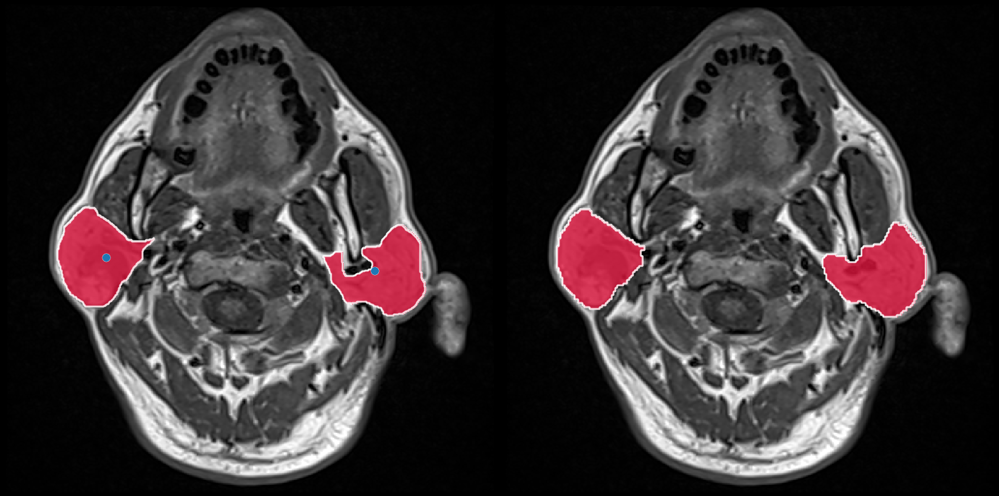

00002_benign_1.50.9.png


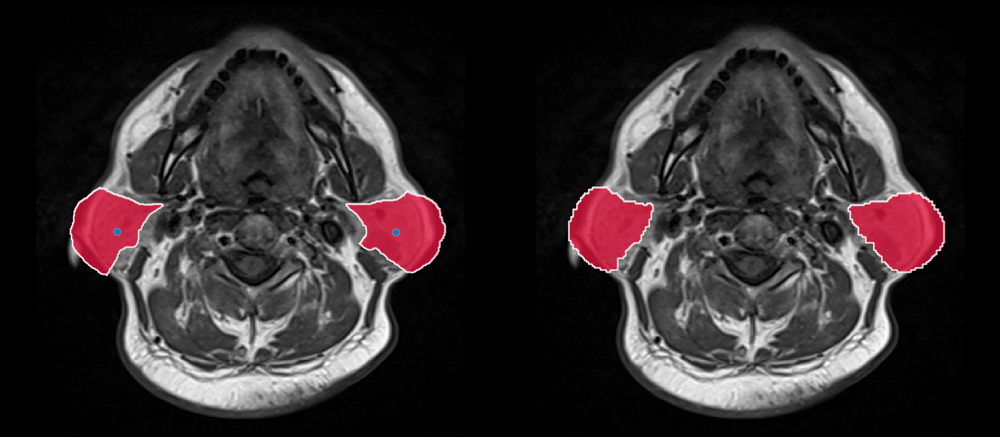

00002_benign_105.1.7.png


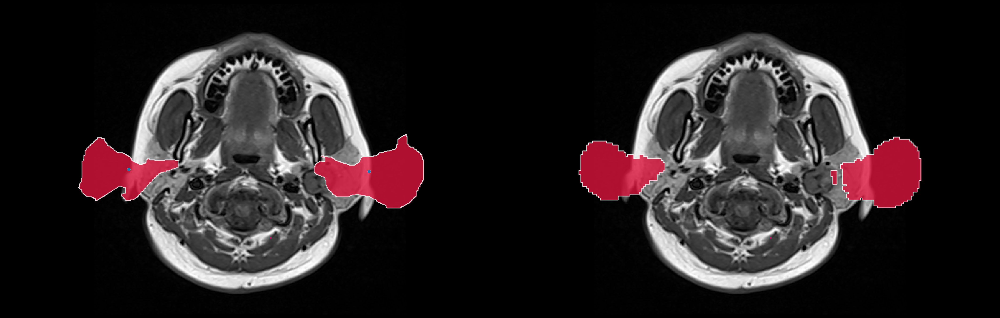

00003_benign_1.47.12.png


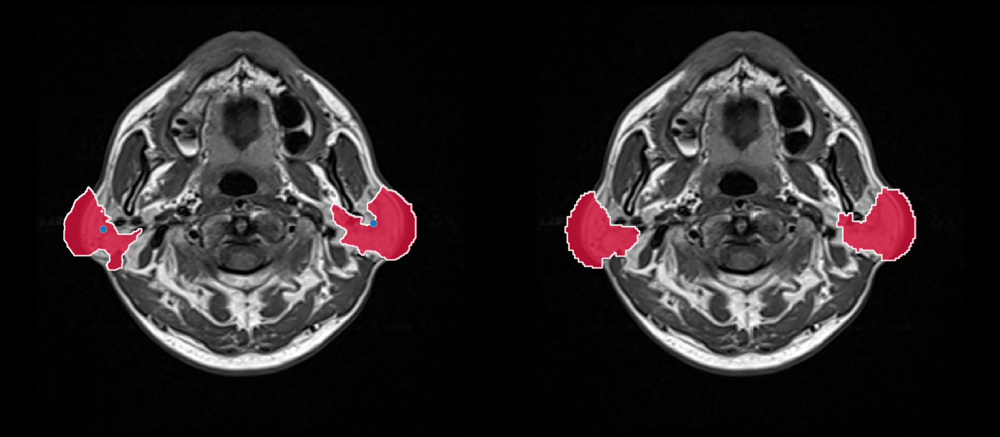

00003_benign_214-2-10.png


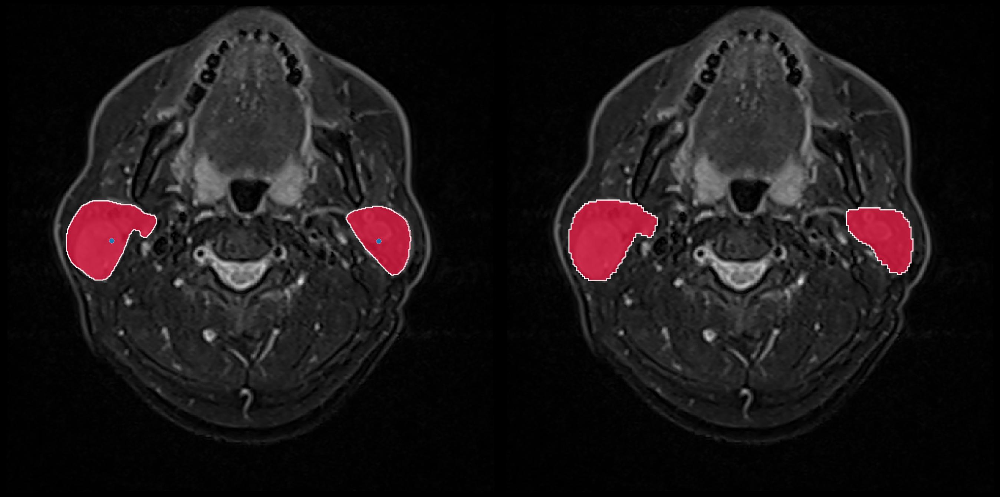

00004_benign_211-1-8.png


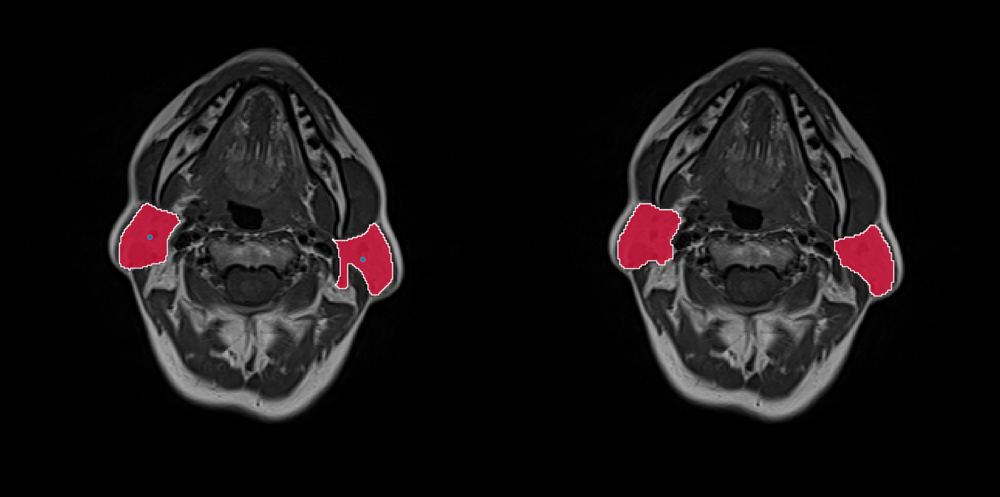

00004_benign_28.1.1.png


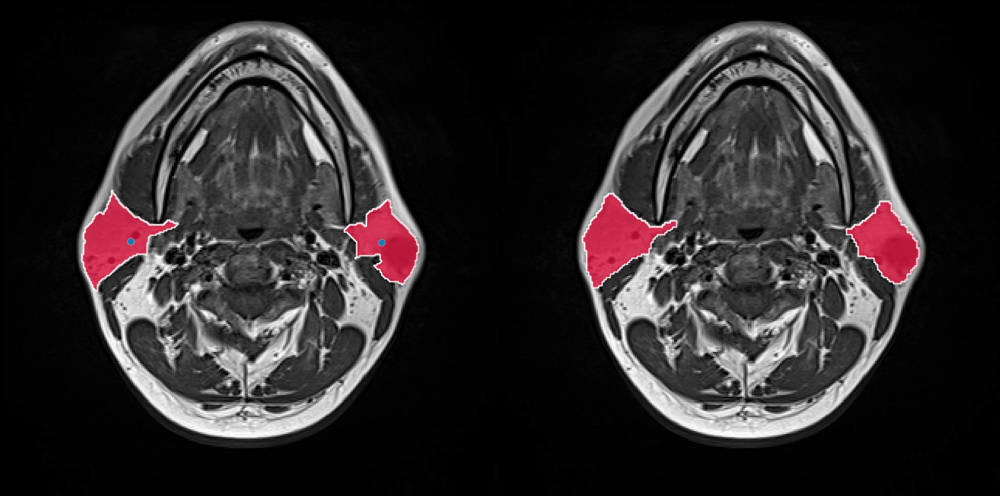

00005_benign_1.52.10.png


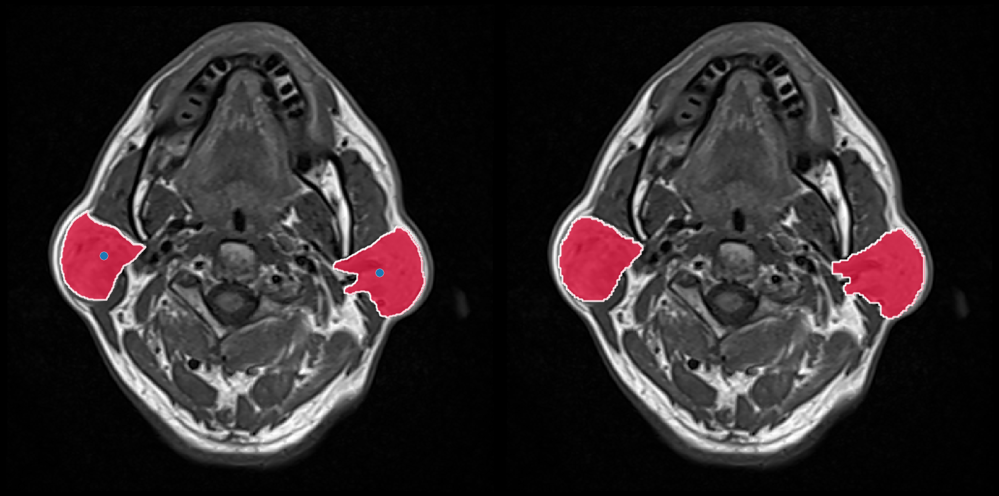

In [22]:
# Qualitative outputs generated by the official UltraSam visualizer.
vis_dir = Path(run_dir) / "official_test_transfer" / "visualizations"
print("Qualitative visualization directory:", vis_dir)

if vis_dir.exists():
    imgs = [p for p in vis_dir.rglob("*")
            if p.suffix.lower() in {".png", ".jpg", ".jpeg"}]
    print("Generated visualizations:", len(imgs))
    if imgs:
        from IPython.display import display
        from PIL import Image as PILImage
        for p in imgs[:8]:
            print(p.name)
            display(PILImage.open(p))
else:
    print("No visualization directory found.")


## 13. Comparable test metrics

This section evaluates the saved UltraSam masks at 224×224 using the same metric formulas as the comparison notebook.

The ground-truth conversion now uses the **same `label_to_binary()` target definition used for training and COCO export**. This removes the previous inconsistency where gray `127` parotid pixels could be discarded by `>127`.

The output files remain:
- `results/per_image_metrics.csv`
- `results/summary_by_group.csv`
- `results/summary.json`
- `results/not_evaluated_empty_masks.csv`

Remember that UltraSam is still evaluated with GT-derived box prompts.


In [23]:
from scipy.stats import wilcoxon

pred_dir = Path(pred_mask_dir)
test_manifest = json.loads((ULTRA_COCO_ROOT / "test" / "manifest.json").read_text(encoding="utf-8"))
test_skipped = json.loads((ULTRA_COCO_ROOT / "test" / "skipped_empty.json").read_text(encoding="utf-8"))
if not pred_dir.is_dir() or not any(pred_dir.glob("*.png")):
    raise FileNotFoundError(f"No predicted masks in {pred_dir}. Run Section 12 (test) first.")

def _imread_gray(path):
    return cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), cv2.IMREAD_GRAYSCALE)

joint_dir = Path(results_dir) / "joint"
joint_dir.mkdir(parents=True, exist_ok=True)
rows, missing_pred = [], []

for item in tqdm(test_manifest, desc="UltraSam test (CMUNeXt metrics)"):
    pred_path = pred_dir / f"{item['image_id']}.png"
    if not pred_path.exists():
        missing_pred.append(item["rel_image"])
        continue
    pred_native = (_imread_gray(pred_path) > 127).astype(np.uint8)

    # Ground truth uses the SAME target decoding as training/export.
    gt_raw = cv2.imread(item["mask_path"], cv2.IMREAD_GRAYSCALE)
    gt_bin = label_to_binary(gt_raw)
    gt = cv2.resize(gt_bin, (CMP_SIZE, CMP_SIZE), interpolation=cv2.INTER_NEAREST).astype(np.uint8)
    pred = cv2.resize(pred_native, (CMP_SIZE, CMP_SIZE), interpolation=cv2.INTER_NEAREST)

    m = image_metrics(gt, pred)
    m["hd95"] = hd95(pred, gt)
    m["hd_legacy"] = directed_hausdorff(gt, pred)[0]

    # native-resolution Dice for reference (label aligned to the prediction size)
    gt_nat = cv2.resize(label_to_binary(gt_raw), pred_native.shape[::-1], interpolation=cv2.INTER_NEAREST).astype(np.uint8)
    m["f1_native"] = image_metrics(gt_nat, pred_native)["f1"]

    name = os.path.splitext(os.path.basename(item["mask_path"]))[0]
    cat = item["category"]
    rows.append({"image": item["rel_image"], "name": name, "category": cat,
                 "gt_area": int(gt.sum()), "pred_area": int(pred.sum()), **m, "prompt": PROMPT_MODE})

    image = cv2.resize(cv2.imread(item["image_path"], cv2.IMREAD_COLOR), (CMP_SIZE, CMP_SIZE),
                       interpolation=cv2.INTER_LINEAR)
    line = np.ones((CMP_SIZE, 10, 3), dtype=np.uint8) * 255
    joint = np.concatenate([image, line, np.repeat(gt[..., None] * 255, 3, 2), line,
                            np.repeat(pred[..., None] * 255, 3, 2)], axis=1).astype(np.uint8)
    cv2.imwrite(str(joint_dir / f"{cat}_{name}.jpg"), joint)

if missing_pred:
    print(f"WARNING: {len(missing_pred)} prompted test images have no saved prediction, e.g. {missing_pred[:3]}")

per_image = pd.DataFrame(rows)
per_image.to_csv(os.path.join(results_dir, "per_image_metrics.csv"), index=False)
pd.DataFrame(test_skipped).to_csv(os.path.join(results_dir, "not_evaluated_empty_masks.csv"), index=False)

# ---- same groups / summary as the CMUNeXt notebook ----
GROUPS = {"all": None, "lesion (benign+malignant)": ["benign", "malignant"],
          "benign": ["benign"], "malignant": ["malignant"], "normal": ["normal"]}

def summarise(per_image):
    out = []
    for gname, cats in GROUPS.items():
        d = per_image if cats is None else per_image[per_image["category"].isin(cats)]
        if len(d) == 0:
            continue
        row = {"group": gname, "n": len(d)}
        for k in METRIC_KEYS:
            row[k] = d[k].mean()
            row[f"{k}_std"] = d[k].std()
        row["hd95"] = d["hd95"].mean()
        row["hd95_n_valid"] = int(d["hd95"].notna().sum())
        row["empty_prediction_rate"] = float((d["pred_area"] == 0).mean())
        out.append(row)
    return pd.DataFrame(out)

summary = summarise(per_image)
summary.to_csv(os.path.join(results_dir, "summary_by_group.csv"), index=False)

report = {
    "model": MODEL_NAME, "model_key": MODEL_KEY, "prompt": PROMPT_MODE, "checkpoint": str(BEST_ULTRASAM_CKPT),
    "eval_size": CMP_SIZE, "seed": SEED, "split_csv": split_csv, "max_iters": ULTRASAM_MAX_ITERS, "mask_target": MASK_TARGET, "unfreeze_last_n_blocks": UNFREEZE_LAST_N_BLOCKS,
    "n_test_split": len(test_x), "n_test_prompted": len(test_manifest), "n_test_evaluated": len(per_image),
    "n_test_empty_mask_not_evaluated": len(test_skipped),
    "test": summary.set_index("group").to_dict(orient="index"),
}
with open(os.path.join(results_dir, "summary.json"), "w") as f:
    json.dump(report, f, indent=2, default=float)

show = summary[["group", "n", "f1", "jaccard", "precision", "recall", "acc", "f2", "hd95", "empty_prediction_rate"]].copy()
for c in ["f1", "jaccard", "precision", "recall", "acc", "f2", "empty_prediction_rate"]:
    show[c] = (100 * show[c]).round(2)
show["hd95"] = show["hd95"].round(2)
print(f"\n{MODEL_NAME} (GT-box prompt) — test set at {CMP_SIZE}x{CMP_SIZE}, metrics in %")
print(f"evaluated {len(per_image)} of {len(test_x)} test images "
      f"({len(test_skipped)} with empty masks have no prompt and are not evaluated)")
print(show.to_string(index=False))
print(f"Native-resolution mean Dice: {100 * per_image['f1_native'].mean():.2f}%")
print("\nPer-image results:", os.path.join(results_dir, "per_image_metrics.csv"))

# ---- paired comparison with CMUNeXt-Large on the same images ----
cmu_csv = os.path.join(benchmark_root, "cmunext_l", f"seed{SEED}", "results", "per_image_metrics.csv")
if os.path.exists(cmu_csv):
    cmu = pd.read_csv(cmu_csv)
    both = per_image.merge(cmu, on=["image", "category"], suffixes=("_ultrasam", "_cmunext"))
    print(f"\nPaired comparison with CMUNeXt-Large on {len(both)} common test images ({cmu_csv})")
    comp = []
    for gname, cats in GROUPS.items():
        d = both if cats is None else both[both["category"].isin(cats)]
        if len(d) < 2:
            continue
        r = {"group": gname, "n": len(d)}
        for k in ["f1", "jaccard"]:
            a, b = d[f"{k}_ultrasam"], d[f"{k}_cmunext"]
            r[f"{k}_ultrasam"] = round(100 * a.mean(), 2)
            r[f"{k}_cmunext"] = round(100 * b.mean(), 2)
            try:
                r[f"{k}_wilcoxon_p"] = wilcoxon(a, b).pvalue if (a != b).any() else 1.0
            except ValueError:
                r[f"{k}_wilcoxon_p"] = float("nan")
        comp.append(r)
    comp = pd.DataFrame(comp)
    comp.to_csv(os.path.join(results_dir, "paired_vs_cmunext_l.csv"), index=False)
    print(comp.to_string(index=False))
    print("Reminder: UltraSam receives the ground-truth box, CMUNeXt does not; the comparison is not symmetric.")
else:
    print(f"\nCMUNeXt results not found at {cmu_csv}; run section 12 of the CMUNeXt notebook to enable the paired test.")


UltraSam test (CMUNeXt metrics): 100%|██████████| 179/179 [00:12<00:00, 13.89it/s]



UltraSam-PartialFT (GT-box prompt) — test set at 224x224, metrics in %
evaluated 179 of 213 test images (34 with empty masks have no prompt and are not evaluated)
                    group   n    f1  jaccard  precision  recall   acc    f2  hd95  empty_prediction_rate
                      all 179 89.03    80.77      86.04   92.78 99.39 91.16  3.71                    0.0
lesion (benign+malignant) 176 89.02    80.75      86.07   92.71 99.39 91.12  3.72                    0.0
                   benign 151 91.00    83.67      88.75   93.54 99.37 92.48  3.41                    0.0
                malignant  25 77.07    63.15      69.93   87.70 99.47 82.85  5.61                    0.0
                   normal   3 89.87    81.61      83.84   96.92 99.47 93.96  3.10                    0.0
Native-resolution mean Dice: 89.00%

Per-image results: C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models\parotid_pg_benchmark\ultrasam_box_prompt_partial_finetune\seed42\results\per_image_metrics.

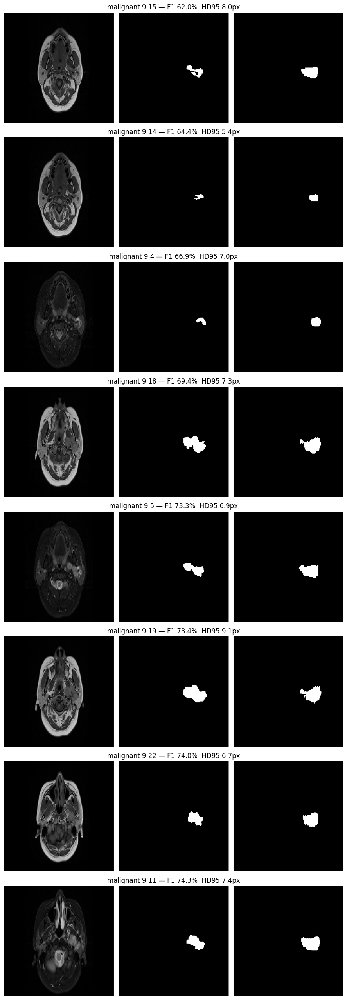

In [24]:
# Qualitative check: the 8 lowest-F1 lesion images (image | ground truth | UltraSam prediction), 224x224
worst = per_image[per_image["category"] != "normal"].nsmallest(8, "f1")
if len(worst):
    fig, axes = plt.subplots(len(worst), 1, figsize=(9, 3.2 * len(worst)))
    axes = np.atleast_1d(axes)
    for ax, (_, r) in zip(axes, worst.iterrows()):
        joint = cv2.imread(str(joint_dir / f"{r['category']}_{r['name']}.jpg"))[..., ::-1]
        ax.imshow(joint); ax.axis("off")
        ax.set_title(f"{r['category']} {r['name']} — F1 {100 * r['f1']:.1f}%  HD95 {r['hd95']:.1f}px")
    plt.tight_layout(); plt.savefig(os.path.join(figures_dir, "worst_cases.png"), dpi=120); plt.show()


## Notes

- **Model:** UltraSam initialized from the official released checkpoint.
- **Target:** default is `whole_parotid`, using label values `127` and `255` as foreground. Change `MASK_TARGET` to `lesion_only` if the scientific target is only the white lesion.
- **COCO representation:** RLE masks; disconnected components are separate instances/prompts.
- **Transfer strategy:** early ViT layers frozen; last transformer blocks plus `channel_reduction` are fine-tuned with a smaller LR than the prompt/mask modules.
- **Prompting:** validation/test use GT-derived boxes. Report the method as **prompted segmentation**.
- **Modality:** if the scans are MRI, state that this is cross-modality transfer from an ultrasound-pretrained foundation model.
- **Split:** this version uses an inferred patient/case-group split and merges verified duplicate/near-duplicate clusters before assignment. No inferred case, exact decoded image, or verified high-SSIM near-duplicate is allowed to cross train/validation/test. Exact cross-category image conflicts are quarantined by default.
- **Best checkpoint:** selected only from validation Dice; the test set is used once for final reporting.
- **If training fails:** inspect `diagnostic_logs/ultrasam_transfer_train.log` in the run directory.


SELECTED PAROTID TEST SAMPLE
Sample Index     : 7
Image ID         : 8
Image            : 2.57.6.png
Mask             : 2.57.6.png
Category         : benign
Target           : whole_parotid
Number of boxes  : 2
Bounding boxes   :
  Box 1: [133, 315, 140, 128]
  Box 2: [506, 331, 95, 102]

UltraSam-Parotid prediction found:
C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models\parotid_pg_benchmark\ultrasam_box_prompt_partial_finetune\seed42\official_test_transfer\pred_masks\8.png

FINAL DATA CHECK
Original MRI shape       : (819, 824, 3)
GT mask shape            : (819, 824)
Prediction shape         : (819, 824)
GT foreground pixels     : 17507
Predicted foreground px  : 17379

FINAL PAROTID FIGURE SAVED SUCCESSFULLY
Sample Index : 7
Image ID     : 8
Image        : 2.57.6.png
Prediction   : C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models\parotid_pg_benchmark\ultrasam_box_prompt_partial_finetune\seed42\official_test_transfer\pred_masks\8.png

Saved to:
C:\Users\pro\Pretoi

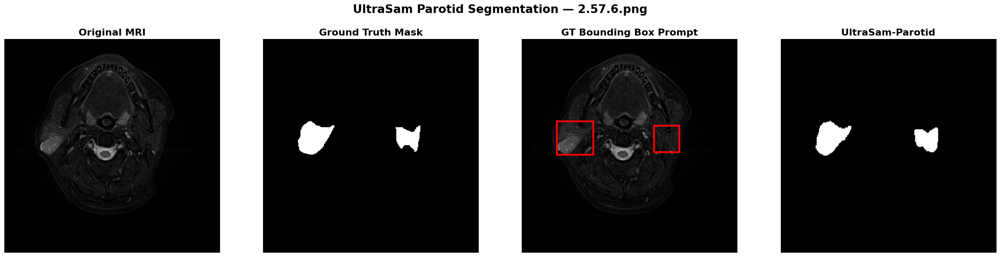

In [26]:
# ============================================================
# UltraSam-PAROTID — FINAL QUALITATIVE VISUALIZATION
#
# DISPLAY:
# 1. Original MRI Image
# 2. Ground Truth Mask
# 3. Original MRI + GT Bounding Box Prompt(s)
# 4. UltraSam-Parotid Prediction
#
# IMPORTANT:
# - No new inference is performed.
# - The prediction generated by the official UltraSam-Parotid
#   test is loaded from the existing pred_masks directory.
# - Multiple GT bounding boxes are supported.
# ============================================================

import json
import cv2
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from matplotlib.patches import Rectangle


# ============================================================
# 1. SELECT TEST SAMPLE
# ============================================================

SAMPLE_INDEX = 7

# Change to:
# 0, 1, 2, 3, 4, ...
#
# The index refers to the sample position inside:
# ULTRA_COCO_ROOT/test/manifest.json


# ============================================================
# 2. PATHS
# ============================================================

# ------------------------------------------------------------
# Test manifest
# ------------------------------------------------------------

manifest_path = (
    Path(ULTRA_COCO_ROOT)
    / "test"
    / "manifest.json"
)


# ------------------------------------------------------------
# Existing UltraSam-Parotid predicted masks
# ------------------------------------------------------------
#
# The official test/evaluation cell stores binary prediction
# masks inside:
#
# run_dir/
#     official_test_transfer/
#         pred_masks/
#
# If pred_mask_dir already exists in the notebook, use it.
# Otherwise construct the path automatically.
# ------------------------------------------------------------

if "pred_mask_dir" in globals():

    prediction_dir = Path(
        pred_mask_dir
    )

else:

    prediction_dir = (
        Path(run_dir)
        / "official_test_transfer"
        / "pred_masks"
    )


# ------------------------------------------------------------
# SAVE DIRECTORY
# ------------------------------------------------------------
#
# Final publication-quality figures will be stored here.
# Change this path if you want another location.
# ------------------------------------------------------------

save_dir = (
    Path(run_dir)
    / "figures"
    / "final_qualitative"
)


# Create directory automatically if it does not exist

save_dir.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 3. CHECK REQUIRED PATHS
# ============================================================

if not manifest_path.exists():

    raise FileNotFoundError(
        f"Manifest not found:\n"
        f"{manifest_path}"
    )


if not prediction_dir.exists():

    raise FileNotFoundError(
        f"Prediction directory not found:\n"
        f"{prediction_dir}\n\n"
        "Run the official UltraSam-Parotid TEST cell first."
    )


# ============================================================
# 4. READ TEST MANIFEST
# ============================================================

with open(
    manifest_path,
    "r",
    encoding="utf-8"
) as f:

    manifest = json.load(f)


# ------------------------------------------------------------
# Check manifest
# ------------------------------------------------------------

if len(manifest) == 0:

    raise RuntimeError(
        "Test manifest is empty."
    )


if SAMPLE_INDEX < 0 or SAMPLE_INDEX >= len(manifest):

    raise IndexError(
        f"SAMPLE_INDEX={SAMPLE_INDEX}, "
        f"but the test manifest contains "
        f"{len(manifest)} samples."
    )


# ============================================================
# 5. SELECT TEST SAMPLE
# ============================================================

sample = manifest[
    SAMPLE_INDEX
]


# ------------------------------------------------------------
# Image ID
# ------------------------------------------------------------

image_id = int(
    sample["image_id"]
)


# ------------------------------------------------------------
# Original MRI image path
# ------------------------------------------------------------

image_path = Path(
    sample["image_path"]
)


# ------------------------------------------------------------
# Ground-truth mask path
# ------------------------------------------------------------

mask_path = Path(
    sample["mask_path"]
)


# ------------------------------------------------------------
# Optional metadata
# ------------------------------------------------------------

category = sample.get(
    "category",
    "unknown"
)


target = sample.get(
    "target",
    globals().get(
        "MASK_TARGET",
        "unknown"
    )
)


# ============================================================
# 6. GET GROUND-TRUTH BOUNDING BOXES
# ============================================================
#
# IMPORTANT:
#
# For the Parotid dataset, bbox_xywh may contain multiple
# bounding boxes.
#
# Example:
#
# [
#     [x1, y1, w1, h1],
#     [x2, y2, w2, h2]
# ]
#
# This is important for whole-parotid segmentation because
# left and right parotid glands can appear as disconnected
# components.
# ============================================================

if "bbox_xywh" not in sample:

    raise KeyError(
        "The selected manifest sample does not contain "
        "'bbox_xywh'."
    )


bboxes_raw = sample[
    "bbox_xywh"
]


# ------------------------------------------------------------
# Normalize bounding-box format
# ------------------------------------------------------------
#
# This also supports a single box stored as:
#
# [x, y, w, h]
#
# instead of:
#
# [[x, y, w, h]]
# ------------------------------------------------------------

if (
    isinstance(bboxes_raw, list)
    and len(bboxes_raw) == 4
    and all(
        isinstance(
            value,
            (int, float)
        )
        for value in bboxes_raw
    )
):

    bboxes_raw = [
        bboxes_raw
    ]


if len(bboxes_raw) == 0:

    raise RuntimeError(
        f"No GT bounding boxes found "
        f"for image ID {image_id}."
    )


# Convert all coordinates to integers

bboxes = []


for bbox in bboxes_raw:

    if len(bbox) != 4:

        raise ValueError(
            f"Invalid bounding box:\n"
            f"{bbox}\n\n"
            "Expected format: [x, y, w, h]"
        )


    x, y, w, h = bbox


    bboxes.append(
        [
            int(round(x)),
            int(round(y)),
            int(round(w)),
            int(round(h))
        ]
    )


# ============================================================
# 7. PRINT SELECTED SAMPLE INFORMATION
# ============================================================

print(
    "=" * 90
)

print(
    "SELECTED PAROTID TEST SAMPLE"
)

print(
    "=" * 90
)


print(
    "Sample Index     :",
    SAMPLE_INDEX
)


print(
    "Image ID         :",
    image_id
)


print(
    "Image            :",
    image_path.name
)


print(
    "Mask             :",
    mask_path.name
)


print(
    "Category         :",
    category
)


print(
    "Target           :",
    target
)


print(
    "Number of boxes  :",
    len(bboxes)
)


print(
    "Bounding boxes   :"
)


for i, bbox in enumerate(
    bboxes,
    start=1
):

    print(
        f"  Box {i}: {bbox}"
    )


print(
    "=" * 90
)


# ============================================================
# 8. CHECK ORIGINAL IMAGE AND GT MASK PATHS
# ============================================================

if not image_path.exists():

    raise FileNotFoundError(
        f"Original MRI image not found:\n"
        f"{image_path}"
    )


if not mask_path.exists():

    raise FileNotFoundError(
        f"Ground-truth mask not found:\n"
        f"{mask_path}"
    )


# ============================================================
# 9. LOAD ORIGINAL MRI IMAGE
# ============================================================
#
# Completely clean original image:
#
# - No mask
# - No bounding box
# - No prediction
# ============================================================

original_bgr = cv2.imread(
    str(image_path),
    cv2.IMREAD_COLOR
)


if original_bgr is None:

    raise FileNotFoundError(
        f"Cannot read original MRI image:\n"
        f"{image_path}"
    )


# OpenCV loads images as BGR.
# Convert to RGB for Matplotlib.

original_rgb = cv2.cvtColor(
    original_bgr,
    cv2.COLOR_BGR2RGB
)


# Original image dimensions

image_h, image_w = (
    original_rgb.shape[:2]
)


# ============================================================
# 10. LOAD GROUND-TRUTH MASK
# ============================================================

gt_mask_raw = cv2.imread(
    str(mask_path),
    cv2.IMREAD_GRAYSCALE
)


if gt_mask_raw is None:

    raise FileNotFoundError(
        f"Cannot read GT mask:\n"
        f"{mask_path}"
    )


# ============================================================
# 11. CONVERT GT LABELS TO BINARY MASK
# ============================================================
#
# Use the SAME label conversion function used by the
# Parotid experiment whenever it is available.
#
# This preserves the notebook's definition of:
#
#   MASK_TARGET = "whole_parotid"
#
# or:
#
#   MASK_TARGET = "lesion_only"
#
# ============================================================

if "label_to_binary" in globals():

    gt_mask = label_to_binary(
        gt_mask_raw
    )

else:

    print(
        "\nWARNING:"
        " label_to_binary() was not found."
    )

    print(
        "Using all non-zero GT pixels as foreground."
    )


    gt_mask = (
        gt_mask_raw > 0
    ).astype(
        np.uint8
    )


# Ensure binary 0/1

gt_mask = (
    np.asarray(gt_mask) > 0
).astype(
    np.uint8
)


# ============================================================
# 12. MATCH GT MASK SIZE TO ORIGINAL IMAGE
# ============================================================

if gt_mask.shape != (
    image_h,
    image_w
):

    print(
        "\nResizing GT mask:"
    )

    print(
        "Original GT shape:",
        gt_mask.shape
    )

    print(
        "Target shape     :",
        (
            image_h,
            image_w
        )
    )


    gt_mask = cv2.resize(

        gt_mask,

        (
            image_w,
            image_h
        ),

        interpolation=cv2.INTER_NEAREST
    )


# ============================================================
# 13. FIND EXISTING ULTRASAM-PAROTID PREDICTION
# ============================================================
#
# Primary expected format:
#
# pred_masks/
#     {image_id}.png
#
# Example:
#
# pred_masks/
#     7.png
#
# ============================================================

prediction_path = (
    prediction_dir
    / f"{image_id}.png"
)


# ------------------------------------------------------------
# If exact image_id filename is not found, try several
# alternative naming conventions.
# ------------------------------------------------------------

if not prediction_path.exists():

    prediction_files = sorted([
        p
        for p in prediction_dir.rglob("*")
        if p.suffix.lower()
        in [
            ".png",
            ".jpg",
            ".jpeg",
            ".bmp",
            ".tif",
            ".tiff"
        ]
    ])


    print(
        "\nExact prediction filename not found:"
    )

    print(
        prediction_path
    )


    print(
        "\nSearching prediction directory..."
    )


    matched_prediction = None


    # --------------------------------------------------------
    # METHOD 1
    # Exact original image filename
    # --------------------------------------------------------

    for p in prediction_files:

        if p.name == image_path.name:

            matched_prediction = p
            break


    # --------------------------------------------------------
    # METHOD 2
    # Exact image stem
    # --------------------------------------------------------

    if matched_prediction is None:

        for p in prediction_files:

            if p.stem == image_path.stem:

                matched_prediction = p
                break


    # --------------------------------------------------------
    # METHOD 3
    # Image ID with zero padding
    # --------------------------------------------------------

    if matched_prediction is None:

        possible_ids = [
            str(image_id),
            f"{image_id:04d}",
            f"{image_id:05d}",
            f"{image_id:06d}"
        ]


        for p in prediction_files:

            if p.stem in possible_ids:

                matched_prediction = p
                break


    # --------------------------------------------------------
    # METHOD 4
    # Original stem contained in prediction filename
    # --------------------------------------------------------

    if matched_prediction is None:

        for p in prediction_files:

            if image_path.stem in p.stem:

                matched_prediction = p
                break


    # --------------------------------------------------------
    # Final result
    # --------------------------------------------------------

    if matched_prediction is not None:

        prediction_path = (
            matched_prediction
        )


    else:

        print(
            "\nFirst available prediction files:"
        )


        for p in prediction_files[:20]:

            print(
                "  ",
                p.name
            )


        raise FileNotFoundError(
            "\nCould not automatically match "
            f"a prediction for image ID {image_id}.\n\n"
            f"Prediction directory:\n"
            f"{prediction_dir}"
        )


# ============================================================
# 14. LOAD EXISTING PREDICTION MASK
# ============================================================

print(
    "\nUltraSam-Parotid prediction found:"
)

print(
    prediction_path
)


prediction_raw = cv2.imread(
    str(prediction_path),
    cv2.IMREAD_GRAYSCALE
)


if prediction_raw is None:

    raise FileNotFoundError(
        f"Cannot read prediction mask:\n"
        f"{prediction_path}"
    )


# Convert prediction to binary 0/1

prediction_mask = (
    prediction_raw > 127
).astype(
    np.uint8
)


# ============================================================
# 15. MATCH PREDICTION SIZE TO ORIGINAL IMAGE
# ============================================================

if prediction_mask.shape != (
    image_h,
    image_w
):

    print(
        "\nResizing prediction mask:"
    )

    print(
        "Original prediction shape:",
        prediction_mask.shape
    )

    print(
        "Target shape             :",
        (
            image_h,
            image_w
        )
    )


    prediction_mask = cv2.resize(

        prediction_mask,

        (
            image_w,
            image_h
        ),

        interpolation=cv2.INTER_NEAREST
    )


# ============================================================
# 16. FINAL DATA CHECK
# ============================================================

print(
    "\n" + "=" * 90
)

print(
    "FINAL DATA CHECK"
)

print(
    "=" * 90
)


print(
    "Original MRI shape       :",
    original_rgb.shape
)


print(
    "GT mask shape            :",
    gt_mask.shape
)


print(
    "Prediction shape         :",
    prediction_mask.shape
)


print(
    "GT foreground pixels     :",
    int(
        gt_mask.sum()
    )
)


print(
    "Predicted foreground px  :",
    int(
        prediction_mask.sum()
    )
)


print(
    "=" * 90
)


# ============================================================
# 17. CREATE FINAL FIGURE
# ============================================================

fig, axes = plt.subplots(

    1,

    4,

    figsize=(
        24,
        6
    )
)


# ============================================================
# PANEL 1
# ORIGINAL MRI IMAGE — CLEAN
# ============================================================

axes[0].imshow(
    original_rgb
)


axes[0].set_title(

    "Original MRI",

    fontsize=16,

    fontweight="bold"
)


axes[0].axis(
    "off"
)


# ============================================================
# PANEL 2
# GROUND TRUTH MASK
# ============================================================

axes[1].imshow(

    gt_mask,

    cmap="gray",

    vmin=0,

    vmax=1
)


axes[1].set_title(

    "Ground Truth Mask",

    fontsize=16,

    fontweight="bold"
)


axes[1].axis(
    "off"
)


# ============================================================
# PANEL 3
# ORIGINAL MRI + GT BOUNDING BOX PROMPT(S)
# ============================================================

axes[2].imshow(
    original_rgb
)


# ------------------------------------------------------------
# Draw ALL GT bounding boxes
# ------------------------------------------------------------
#
# This is particularly important for whole-parotid
# segmentation because left/right glands can be separate
# connected components.
# ------------------------------------------------------------

for (
    x,
    y,
    w,
    h
) in bboxes:

    bbox_rectangle = Rectangle(

        (
            x,
            y
        ),

        w,

        h,

        fill=False,

        edgecolor="red",

        linewidth=3
    )


    axes[2].add_patch(
        bbox_rectangle
    )


axes[2].set_title(

    "GT Bounding Box Prompt",

    fontsize=16,

    fontweight="bold"
)


axes[2].axis(
    "off"
)


# ============================================================
# PANEL 4
# ULTRASAM-PAROTID PREDICTION
# ============================================================

axes[3].imshow(

    prediction_mask,

    cmap="gray",

    vmin=0,

    vmax=1
)


axes[3].set_title(

    "UltraSam-Parotid",

    fontsize=16,

    fontweight="bold"
)


axes[3].axis(
    "off"
)


# ============================================================
# 18. MAIN TITLE
# ============================================================

plt.suptitle(

    (
        f"UltraSam Parotid Segmentation — "
        f"{image_path.name}"
    ),

    fontsize=19,

    fontweight="bold"
)


# Adjust spacing while preserving main title

plt.tight_layout(

    rect=[
        0,
        0,
        1,
        0.94
    ]
)


# ============================================================
# 19. SAVE FINAL FIGURE
# ============================================================

# Clean category name for filename

safe_category = str(
    category
).replace(
    " ",
    "_"
).replace(
    "/",
    "_"
).replace(
    "\\",
    "_"
)


# Example:
#
# UltraSam_Parotid_Result_patient_001_slice_025.png
#

save_path = (

    save_dir

    / (
        f"UltraSam_Parotid_Result_"
        f"{safe_category}_"
        f"{image_path.stem}.png"
    )
)


plt.savefig(

    save_path,

    dpi=300,

    bbox_inches="tight",

    facecolor="white"
)


# ============================================================
# 20. CONFIRM SAVE LOCATION
# ============================================================

print(
    "\n" + "=" * 90
)


print(
    "FINAL PAROTID FIGURE SAVED SUCCESSFULLY"
)


print(
    "=" * 90
)


print(
    "Sample Index :",
    SAMPLE_INDEX
)


print(
    "Image ID     :",
    image_id
)


print(
    "Image        :",
    image_path.name
)


print(
    "Prediction   :",
    prediction_path
)


print(
    "\nSaved to:"
)


print(
    save_path
)


print(
    "=" * 90
)


# ============================================================
# 21. DISPLAY FINAL FIGURE
# ============================================================

plt.show()

In [27]:
# ============================================================
# FIGURE 1 — WORKFLOW INFORMATION + VISUAL ASSET EXPORT
# UltraSam Parotid Study
#
# PURPOSE:
#   Export everything needed to construct a publication-quality
#   overall workflow figure directly from the executed notebook.
#
# IMPORTANT:
#   - NO training is performed.
#   - NO new inference is performed.
#   - Existing test predictions are used.
# ============================================================

import os
import json
import shutil
import cv2
import numpy as np
import pandas as pd

from pathlib import Path


# ============================================================
# 1. OUTPUT DIRECTORY
# ============================================================

FIG1_DIR = (
    Path(run_dir)
    / "figures"
    / "Figure1_workflow_assets"
)

FIG1_DIR.mkdir(
    parents=True,
    exist_ok=True
)

summary = {}


# ============================================================
# 2. DATASET INFORMATION
# ============================================================

summary["dataset"] = {
    "total_matched_images": int(len(df)),
    "category_counts": {
        str(k): int(v)
        for k, v in
        df["Category"].value_counts().to_dict().items()
    },
    "mask_target": str(
        globals().get(
            "MASK_TARGET",
            "unknown"
        )
    )
}


# ------------------------------------------------------------
# Non-empty / empty target masks
# ------------------------------------------------------------

if "mask_stats" in globals():

    summary["dataset"]["non_empty_target_masks"] = int(
        mask_stats["has_object"].sum()
    )

    summary["dataset"]["empty_target_masks"] = int(
        (~mask_stats["has_object"]).sum()
    )

    summary["dataset"]["image_mask_size_mismatches"] = int(
        mask_stats["size_mismatch"].sum()
    )


# ============================================================
# 3. CASE / LEAKAGE-SAFE GROUPING
# ============================================================

grouping_info = {}

if "Initial_Group" in df.columns:

    grouping_info["initial_inferred_cases"] = int(
        df["Initial_Group"].nunique()
    )

elif "Case_ID" in df.columns:

    grouping_info["initial_inferred_cases"] = int(
        df["Case_ID"].nunique()
    )


if "Leakage_Group" in df.columns:

    grouping_info["final_leakage_safe_groups"] = int(
        df["Leakage_Group"].nunique()
    )


if "verified_pairs" in globals():

    grouping_info["verified_near_duplicate_pairs"] = int(
        len(verified_pairs)
    )


if "candidate_pairs" in globals():

    grouping_info["dhash_candidate_pairs"] = int(
        len(candidate_pairs)
    )


# ------------------------------------------------------------
# Leakage audit
# ------------------------------------------------------------

if "case_cross" in globals():

    grouping_info["cases_crossing_splits"] = int(
        len(case_cross)
    )


if "group_cross" in globals():

    grouping_info["leakage_groups_crossing_splits"] = int(
        len(group_cross)
    )


if "exact_cross" in globals():

    grouping_info["exact_hashes_crossing_splits"] = int(
        len(exact_cross)
    )


if "audit_pairs" in globals():

    grouping_info[
        "verified_near_duplicates_crossing_splits"
    ] = int(
        len(audit_pairs)
    )


summary["case_grouping_and_leakage_control"] = grouping_info


# ============================================================
# 4. ORIGINAL TRAIN / VALIDATION / TEST SPLIT
# ============================================================

split_info = {}

for split_name in [
    "train",
    "valid",
    "test"
]:

    subset = df[
        df["Split"] == split_name
    ]

    split_info[split_name] = {

        "images": int(
            len(subset)
        ),

        "category_counts": {
            str(k): int(v)
            for k, v in
            subset["Category"]
            .value_counts()
            .to_dict()
            .items()
        }
    }


summary["leakage_safe_split"] = split_info


# ============================================================
# 5. PROMPTABLE COCO DATA
# ============================================================

coco_info = {}

split_mapping = {
    "train": "train",
    "validation": "val",
    "test": "test"
}


original_split_mapping = {
    "train": "train",
    "validation": "valid",
    "test": "test"
}


for display_name, coco_name in split_mapping.items():

    coco_json = (
        Path(ULTRA_COCO_ROOT)
        / coco_name
        / f"{coco_name}.json"
    )

    manifest_json = (
        Path(ULTRA_COCO_ROOT)
        / coco_name
        / "manifest.json"
    )

    if coco_json.exists():

        with open(
            coco_json,
            "r",
            encoding="utf-8"
        ) as f:

            coco = json.load(f)


        original_split_name = (
            original_split_mapping[
                display_name
            ]
        )

        original_count = int(
            (
                df["Split"]
                == original_split_name
            ).sum()
        )

        prompted_count = int(
            len(
                coco.get(
                    "images",
                    []
                )
            )
        )

        instance_count = int(
            len(
                coco.get(
                    "annotations",
                    []
                )
            )
        )


        coco_info[display_name] = {

            "original_split_images":
                original_count,

            "prompted_images":
                prompted_count,

            "instances":
                instance_count,

            "empty_masks_skipped":
                int(
                    original_count
                    - prompted_count
                )
        }


        if manifest_json.exists():

            with open(
                manifest_json,
                "r",
                encoding="utf-8"
            ) as f:

                this_manifest = json.load(f)


            category_counts = {}

            for item in this_manifest:

                cat = str(
                    item.get(
                        "category",
                        "unknown"
                    )
                )

                category_counts[cat] = (
                    category_counts.get(
                        cat,
                        0
                    )
                    + 1
                )


            coco_info[
                display_name
            ][
                "prompted_category_counts"
            ] = category_counts


summary[
    "prompted_coco_data"
] = coco_info


# ============================================================
# 6. MODEL / TRANSFER LEARNING INFORMATION
# ============================================================

def get_global(
    name,
    default=None
):

    return globals().get(
        name,
        default
    )


model_info = {

    "model_name":
        str(
            get_global(
                "MODEL_NAME",
                "UltraSam"
            )
        ),

    "pretrained":
        bool(
            get_global(
                "PRETRAINED",
                True
            )
        ),

    "unfreeze_last_n_vit_blocks":
        int(
            get_global(
                "UNFREEZE_LAST_N_BLOCKS",
                -1
            )
        ),

    "base_learning_rate":
        float(
            get_global(
                "BASE_LR",
                np.nan
            )
        ),

    "encoder_lr_multiplier":
        float(
            get_global(
                "ENCODER_LR_MULT",
                np.nan
            )
        ),

    "max_iterations":
        int(
            get_global(
                "ULTRASAM_MAX_ITERS",
                -1
            )
        ),

    "validation_interval":
        int(
            get_global(
                "ULTRASAM_VAL_INTERVAL",
                -1
            )
        ),

    "gradient_accumulation":
        int(
            get_global(
                "GRAD_ACCUMULATION",
                -1
            )
        ),

    "image_size":
        int(
            get_global(
                "IMAGE_SIZE",
                -1
            )
        ),

    "evaluation_size":
        int(
            get_global(
                "CMP_SIZE",
                -1
            )
        ),

    "split_seed":
        int(
            get_global(
                "SPLIT_SEED",
                -1
            )
        )
}


if "BEST_ULTRASAM_CKPT" in globals():

    model_info[
        "checkpoint_used_for_test"
    ] = Path(
        BEST_ULTRASAM_CKPT
    ).name


summary[
    "model_and_training"
] = model_info


# ============================================================
# 7. FINAL TEST RESULTS
# ============================================================

if (
    "per_image" in globals()
    and len(per_image) > 0
):

    eps = 1e-12

    test_results = {

        "evaluated_images":
            int(
                len(per_image)
            ),

        "mean_dice_percent":
            float(
                100
                * per_image[
                    "f1"
                ].mean()
            ),

        "mean_iou_percent":
            float(
                100
                * per_image[
                    "jaccard"
                ].mean()
            ),

        "mean_precision_percent":
            float(
                100
                * per_image[
                    "precision"
                ].mean()
            ),

        "mean_recall_percent":
            float(
                100
                * per_image[
                    "recall"
                ].mean()
            ),

        "mean_accuracy_percent":
            float(
                100
                * per_image[
                    "acc"
                ].mean()
            ),

        "mean_hd95_pixels":
            float(
                per_image[
                    "hd95"
                ].mean()
            )
    }


    if "f1_native" in per_image.columns:

        test_results[
            "native_resolution_mean_dice_percent"
        ] = float(
            100
            * per_image[
                "f1_native"
            ].mean()
        )


    summary[
        "final_test_results"
    ] = test_results


# ============================================================
# 8. LOAD TEST MANIFEST
# ============================================================

manifest_path = (
    Path(ULTRA_COCO_ROOT)
    / "test"
    / "manifest.json"
)


if not manifest_path.exists():

    raise FileNotFoundError(
        f"Test manifest not found:\n"
        f"{manifest_path}"
    )


with open(
    manifest_path,
    "r",
    encoding="utf-8"
) as f:

    test_manifest = json.load(f)


# ============================================================
# 9. CHOOSE REPRESENTATIVE TEST SAMPLE
# ============================================================
#
# Preference:
# 1. Existing SAMPLE_INDEX from notebook
# 2. Otherwise first image containing >= 2 GT boxes
#
# This is useful for whole-parotid segmentation because
# left and right glands can have separate prompts.
# ============================================================

sample_index = globals().get(
    "SAMPLE_INDEX",
    None
)


if (
    sample_index is None
    or sample_index < 0
    or sample_index >= len(test_manifest)
):

    sample_index = None


    for idx, item in enumerate(
        test_manifest
    ):

        boxes = item.get(
            "bbox_xywh",
            []
        )


        if (
            isinstance(
                boxes,
                list
            )
            and len(boxes) >= 2
            and isinstance(
                boxes[0],
                list
            )
        ):

            sample_index = idx
            break


if sample_index is None:

    sample_index = 0


sample = test_manifest[
    sample_index
]


image_id = int(
    sample["image_id"]
)

image_path = Path(
    sample["image_path"]
)

mask_path = Path(
    sample["mask_path"]
)

category = str(
    sample.get(
        "category",
        "unknown"
    )
)


# ============================================================
# 10. NORMALIZE GT BOUNDING BOXES
# ============================================================

bboxes = sample.get(
    "bbox_xywh",
    []
)


if (
    isinstance(
        bboxes,
        list
    )
    and len(bboxes) == 4
    and all(
        isinstance(
            x,
            (int, float)
        )
        for x in bboxes
    )
):

    bboxes = [
        bboxes
    ]


bboxes = [
    [
        int(round(v))
        for v in box
    ]
    for box in bboxes
]


# ============================================================
# 11. LOAD ORIGINAL MRI
# ============================================================

image_bgr = cv2.imread(
    str(image_path),
    cv2.IMREAD_COLOR
)


if image_bgr is None:

    raise FileNotFoundError(
        f"Cannot read:\n"
        f"{image_path}"
    )


image_rgb = cv2.cvtColor(
    image_bgr,
    cv2.COLOR_BGR2RGB
)

H, W = image_rgb.shape[:2]


# ============================================================
# 12. LOAD RAW REFERENCE MASK
# ============================================================

gt_raw = cv2.imread(
    str(mask_path),
    cv2.IMREAD_GRAYSCALE
)


if gt_raw is None:

    raise FileNotFoundError(
        f"Cannot read:\n"
        f"{mask_path}"
    )


if gt_raw.shape != (
    H,
    W
):

    gt_raw_resized = cv2.resize(
        gt_raw,
        (W, H),
        interpolation=cv2.INTER_NEAREST
    )

else:

    gt_raw_resized = gt_raw.copy()


# Same target definition as the experiment

if "label_to_binary" in globals():

    gt_binary = label_to_binary(
        gt_raw
    )

else:

    gt_binary = (
        gt_raw > 0
    ).astype(
        np.uint8
    )


if gt_binary.shape != (
    H,
    W
):

    gt_binary = cv2.resize(
        gt_binary.astype(
            np.uint8
        ),
        (W, H),
        interpolation=cv2.INTER_NEAREST
    )


gt_binary = (
    gt_binary > 0
).astype(
    np.uint8
)


# ============================================================
# 13. LOAD EXISTING ULTRASAM PREDICTION
# ============================================================

if "pred_mask_dir" in globals():

    prediction_dir = Path(
        pred_mask_dir
    )

else:

    prediction_dir = (
        Path(run_dir)
        / "official_test_transfer"
        / "pred_masks"
    )


prediction_path = (
    prediction_dir
    / f"{image_id}.png"
)


if not prediction_path.exists():

    candidates = list(
        prediction_dir.rglob(
            "*.png"
        )
    )


    matched = None


    # Match original image stem

    for p in candidates:

        if (
            p.stem
            == image_path.stem
        ):

            matched = p
            break


    if matched is None:

        raise FileNotFoundError(
            f"Prediction not found for "
            f"image ID {image_id}.\n"
            f"Expected:\n"
            f"{prediction_path}"
        )


    prediction_path = matched


pred_raw = cv2.imread(
    str(prediction_path),
    cv2.IMREAD_GRAYSCALE
)


pred_binary = (
    pred_raw > 127
).astype(
    np.uint8
)


if pred_binary.shape != (
    H,
    W
):

    pred_binary = cv2.resize(
        pred_binary,
        (W, H),
        interpolation=cv2.INTER_NEAREST
    )


# ============================================================
# 14. CREATE BOUNDING-BOX PROMPT IMAGE
# ============================================================

bbox_image = image_bgr.copy()


for x, y, w, h in bboxes:

    cv2.rectangle(
        bbox_image,
        (x, y),
        (x + w, y + h),
        (0, 0, 255),
        max(
            2,
            round(
                min(H, W)
                / 250
            )
        )
    )


# ============================================================
# 15. CREATE GT OVERLAY
# ============================================================

gt_overlay = image_rgb.copy().astype(
    np.float32
)

gt_colour = np.zeros_like(
    gt_overlay
)

# Red/pink GT overlay
gt_colour[..., 0] = 235
gt_colour[..., 1] = 70
gt_colour[..., 2] = 80

alpha = 0.42

mask_bool = gt_binary.astype(
    bool
)

gt_overlay[
    mask_bool
] = (
    (
        1 - alpha
    )
    * gt_overlay[
        mask_bool
    ]
    + alpha
    * gt_colour[
        mask_bool
    ]
)

gt_overlay = np.clip(
    gt_overlay,
    0,
    255
).astype(
    np.uint8
)


# ============================================================
# 16. CREATE PREDICTION OVERLAY
# ============================================================

pred_overlay = image_rgb.copy().astype(
    np.float32
)

pred_colour = np.zeros_like(
    pred_overlay
)

# Green prediction overlay
pred_colour[..., 0] = 45
pred_colour[..., 1] = 200
pred_colour[..., 2] = 110

pred_bool = pred_binary.astype(
    bool
)

pred_overlay[
    pred_bool
] = (
    (
        1 - alpha
    )
    * pred_overlay[
        pred_bool
    ]
    + alpha
    * pred_colour[
        pred_bool
    ]
)

pred_overlay = np.clip(
    pred_overlay,
    0,
    255
).astype(
    np.uint8
)


# ============================================================
# 17. SAVE INDIVIDUAL FIGURE ASSETS
# ============================================================

cv2.imwrite(
    str(
        FIG1_DIR
        / "01_original_MRI.png"
    ),
    image_bgr
)


cv2.imwrite(
    str(
        FIG1_DIR
        / "02_raw_reference_annotation.png"
    ),
    gt_raw_resized
)


cv2.imwrite(
    str(
        FIG1_DIR
        / "03_binary_reference_mask.png"
    ),
    gt_binary * 255
)


cv2.imwrite(
    str(
        FIG1_DIR
        / "04_GT_bounding_box_prompt.png"
    ),
    bbox_image
)


cv2.imwrite(
    str(
        FIG1_DIR
        / "05_prediction_mask.png"
    ),
    pred_binary * 255
)


cv2.imwrite(
    str(
        FIG1_DIR
        / "06_GT_overlay.png"
    ),
    cv2.cvtColor(
        gt_overlay,
        cv2.COLOR_RGB2BGR
    )
)


cv2.imwrite(
    str(
        FIG1_DIR
        / "07_prediction_overlay.png"
    ),
    cv2.cvtColor(
        pred_overlay,
        cv2.COLOR_RGB2BGR
    )
)


# ============================================================
# 18. REPRESENTATIVE SAMPLE INFORMATION
# ============================================================

intersection = np.logical_and(
    gt_binary,
    pred_binary
).sum()

denominator = (
    gt_binary.sum()
    + pred_binary.sum()
)

sample_dice = (
    2.0
    * intersection
    / denominator
    if denominator > 0
    else 1.0
)


union = np.logical_or(
    gt_binary,
    pred_binary
).sum()

sample_iou = (
    intersection
    / union
    if union > 0
    else 1.0
)


summary[
    "representative_test_example"
] = {

    "sample_index":
        int(sample_index),

    "image_id":
        int(image_id),

    "filename":
        image_path.name,

    "category":
        category,

    "image_shape":
        [
            int(H),
            int(W)
        ],

    "number_of_GT_boxes":
        int(len(bboxes)),

    "GT_boxes_xywh":
        bboxes,

    "GT_foreground_pixels":
        int(
            gt_binary.sum()
        ),

    "prediction_foreground_pixels":
        int(
            pred_binary.sum()
        ),

    "sample_dice_percent":
        float(
            100
            * sample_dice
        ),

    "sample_iou_percent":
        float(
            100
            * sample_iou
        )
}


# ============================================================
# 19. SAVE MACHINE-READABLE SUMMARY
# ============================================================

summary_path = (
    FIG1_DIR
    / "workflow_summary.json"
)


with open(
    summary_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        summary,
        f,
        indent=4,
        ensure_ascii=False
    )


# ============================================================
# 20. PRINT COMPLETE SUMMARY
# ============================================================

print(
    "\n"
    + "=" * 100
)

print(
    "FIGURE 1 — EXECUTED NOTEBOOK WORKFLOW SUMMARY"
)

print(
    "=" * 100
)

print(
    json.dumps(
        summary,
        indent=4,
        ensure_ascii=False
    )
)

print(
    "=" * 100
)


# ============================================================
# 21. CREATE ONE ZIP FILE FOR CHATGPT
# ============================================================

zip_base = (
    Path(run_dir)
    / "figures"
    / "Figure1_workflow_assets"
)


zip_path = shutil.make_archive(
    str(zip_base),
    "zip",
    root_dir=str(FIG1_DIR)
)


print(
    "\nFIGURE 1 ASSETS SAVED TO:"
)

print(
    FIG1_DIR
)


print(
    "\nZIP FILE:"
)

print(
    zip_path
)


print(
    "\nFILES:"
)

for p in sorted(
    FIG1_DIR.iterdir()
):

    print(
        "  -",
        p.name
    )


print(
    "\nDONE — upload Figure1_workflow_assets.zip to ChatGPT."
)


FIGURE 1 — EXECUTED NOTEBOOK WORKFLOW SUMMARY
{
    "dataset": {
        "total_matched_images": 2105,
        "category_counts": {
            "benign": 1522,
            "normal": 366,
            "malignant": 217
        },
        "mask_target": "whole_parotid",
        "non_empty_target_masks": 1997,
        "empty_target_masks": 108,
        "image_mask_size_mismatches": 701
    },
    "case_grouping_and_leakage_control": {
        "initial_inferred_cases": 591,
        "final_leakage_safe_groups": 588,
        "verified_near_duplicate_pairs": 9,
        "dhash_candidate_pairs": 12,
        "cases_crossing_splits": 0,
        "leakage_groups_crossing_splits": 0,
        "exact_hashes_crossing_splits": 0,
        "verified_near_duplicates_crossing_splits": 0
    },
    "leakage_safe_split": {
        "train": {
            "images": 1680,
            "category_counts": {
                "benign": 1220,
                "normal": 292,
                "malignant": 168
            }


In [3]:
# ============================================================
# FIGURE 6 — LEAKAGE-CONTROL MECHANISM
# ROBUST EXPORT CELL
#
# This cell can work after a kernel restart by restoring the
# saved leakage-safe split and audit outputs from disk.
# ============================================================

import os
import json
import shutil
import cv2
import numpy as np
import pandas as pd

from pathlib import Path


# ============================================================
# 1. DEFAULT CONFIGURATION
# ============================================================

if "SPLIT_SEED" not in globals():
    SPLIT_SEED = 42

if "SEED" not in globals():
    SEED = 42

if "MODEL_KEY" not in globals():
    MODEL_KEY = "ultrasam_box_prompt_partial_finetune"

if "DUP_DHASH_SIZE" not in globals():
    DUP_DHASH_SIZE = 16

if "DUP_DHASH_MAX" not in globals():
    DUP_DHASH_MAX = 6

if "DUP_SSIM_MIN" not in globals():
    DUP_SSIM_MIN = 0.985

if "TRAIN_FRACTION" not in globals():
    TRAIN_FRACTION = 0.80

if "VALID_FRACTION" not in globals():
    VALID_FRACTION = 0.10

if "TEST_FRACTION" not in globals():
    TEST_FRACTION = 0.10

if "CASE_ID_MODE" not in globals():
    CASE_ID_MODE = "filename_without_last_numeric_token"


# ============================================================
# 2. RESTORE PROJECT PATHS IF NEEDED
# ============================================================

if "benchmark_root" not in globals() or "base_dir" not in globals():

    import sys

    in_colab = "google.colab" in sys.modules

    if in_colab:

        project_root_default = (
            "/content/drive/MyDrive/PGT-MRI"
        )

        base_dir_default = (
            "/content/drive/MyDrive/PGT-MRI/DATASET PG"
        )

    else:

        project_root_default = (
            r"C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models"
        )

        base_dir_default = (
            r"C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models\DATASET PG"
        )

    if "project_root" not in globals():

        project_root = os.environ.get(
            "PAROTID_PROJECT_ROOT",
            project_root_default
        )

    if "base_dir" not in globals():

        base_dir = os.environ.get(
            "PAROTID_DATASET_ROOT",
            base_dir_default
        )

    if "benchmark_root" not in globals():

        benchmark_root = os.path.join(
            project_root,
            "parotid_pg_benchmark"
        )


if "run_dir" not in globals():

    run_dir = os.path.join(
        benchmark_root,
        MODEL_KEY,
        f"seed{SEED}"
    )


# ============================================================
# 3. FILE LOCATIONS
# ============================================================

split_dir = os.path.join(
    benchmark_root,
    "splits"
)

qc_dir = os.path.join(
    benchmark_root,
    "quality_control"
)

split_csv = os.path.join(
    split_dir,
    f"split_patient_group_noleak_seed{SPLIT_SEED}.csv"
)

verified_pairs_csv = os.path.join(
    qc_dir,
    f"verified_near_duplicate_pairs_seed{SPLIT_SEED}.csv"
)

audit_csv = os.path.join(
    qc_dir,
    f"cross_split_verified_near_duplicates_seed{SPLIT_SEED}.csv"
)

conflict_csv = os.path.join(
    qc_dir,
    f"quarantined_exact_cross_category_conflicts_seed{SPLIT_SEED}.csv"
)


# ============================================================
# 4. RESTORE df IF KERNEL WAS RESTARTED
# ============================================================

if "df" not in globals():

    if not os.path.isfile(split_csv):

        raise RuntimeError(
            "The leakage-safe split CSV was not found.\n\n"
            f"Expected file:\n{split_csv}\n\n"
            "Run the leakage-safe grouping/split cell first."
        )

    print(
        "Restoring saved leakage-safe split manifest..."
    )

    df = pd.read_csv(
        split_csv
    )

    required_columns = {
        "Category",
        "Rel_Image",
        "Rel_Label",
        "Initial_Group",
        "Leakage_Group",
        "Decoded_SHA256",
        "Split",
    }

    missing_columns = sorted(
        required_columns
        - set(df.columns)
    )

    if missing_columns:

        raise RuntimeError(
            "The saved split CSV is missing columns:\n"
            f"{missing_columns}"
        )

    df["Image_Path"] = df[
        "Rel_Image"
    ].map(
        lambda p:
            os.path.normpath(
                os.path.join(
                    base_dir,
                    str(p).replace(
                        "/",
                        os.sep
                    )
                )
            )
    )

    df["Label_Path"] = df[
        "Rel_Label"
    ].map(
        lambda p:
            os.path.normpath(
                os.path.join(
                    base_dir,
                    str(p).replace(
                        "/",
                        os.sep
                    )
                )
            )
    )

    df = df.reset_index(
        drop=True
    )


# ============================================================
# 5. RESTORE VERIFIED NEAR-DUPLICATE PAIRS
# ============================================================

if "verified_pairs" not in globals():

    verified_pairs = []

    if os.path.isfile(
        verified_pairs_csv
    ):

        if os.path.getsize(
            verified_pairs_csv
        ) == 0:

            print(
                "Verified-pairs CSV is empty."
            )

        else:

            try:

                vp = pd.read_csv(
                    verified_pairs_csv
                )

            except pd.errors.EmptyDataError:

                vp = pd.DataFrame()

            if not vp.empty:

                rel_to_idx = {
                    str(rel): int(idx)
                    for idx, rel
                    in df[
                        "Rel_Image"
                    ].items()
                }

                for row in vp.to_dict(
                    orient="records"
                ):

                    rel_i = str(
                        row.get(
                            "rel_image_i",
                            ""
                        )
                    )

                    rel_j = str(
                        row.get(
                            "rel_image_j",
                            ""
                        )
                    )

                    if (
                        rel_i not in rel_to_idx
                        or rel_j not in rel_to_idx
                    ):

                        raise RuntimeError(
                            "A saved verified pair refers to an image "
                            "not present in the split manifest:\n"
                            f"{rel_i}\n"
                            f"{rel_j}"
                        )

                    row["i"] = (
                        rel_to_idx[
                            rel_i
                        ]
                    )

                    row["j"] = (
                        rel_to_idx[
                            rel_j
                        ]
                    )

                    row[
                        "dhash_distance"
                    ] = int(
                        row[
                            "dhash_distance"
                        ]
                    )

                    row[
                        "ssim"
                    ] = float(
                        row[
                            "ssim"
                        ]
                    )

                    verified_pairs.append(
                        row
                    )

        print(
            "Verified near-duplicate pairs restored:",
            len(
                verified_pairs
            )
        )

    else:

        print(
            "WARNING: verified-pairs CSV not found."
        )


# ============================================================
# 6. REBUILD SPLIT-CROSSING AUDITS
# ============================================================

case_cross = (
    df.groupby(
        "Initial_Group"
    )[
        "Split"
    ]
    .nunique()
)

case_cross = (
    case_cross[
        case_cross > 1
    ]
)


group_cross = (
    df.groupby(
        "Leakage_Group"
    )[
        "Split"
    ]
    .nunique()
)

group_cross = (
    group_cross[
        group_cross > 1
    ]
)


exact_cross = (
    df.groupby(
        "Decoded_SHA256"
    )[
        "Split"
    ]
    .nunique()
)

exact_cross = (
    exact_cross[
        exact_cross > 1
    ]
)


# ============================================================
# 7. RESTORE POST-SPLIT NEAR-DUPLICATE AUDIT
#
# IMPORTANT:
# An empty CSV file is interpreted as:
# 0 cross-split verified near-duplicate pairs.
# ============================================================

audit_pairs = []


if os.path.isfile(
    audit_csv
):

    if os.path.getsize(
        audit_csv
    ) == 0:

        print(
            "Post-split audit file is empty -> "
            "0 cross-split verified near-duplicate pairs."
        )

        audit_pairs = []

    else:

        try:

            audit_df = pd.read_csv(
                audit_csv
            )

            if not audit_df.empty:

                audit_pairs = (
                    audit_df.to_dict(
                        orient="records"
                    )
                )

        except pd.errors.EmptyDataError:

            print(
                "Post-split audit CSV contains no rows -> "
                "0 cross-split verified near-duplicate pairs."
            )

            audit_pairs = []


    print(
        "Cross-split near-duplicate audit pairs:",
        len(
            audit_pairs
        )
    )

else:

    raise RuntimeError(
        "Post-split leakage audit CSV not found.\n\n"
        f"Expected file:\n{audit_csv}\n\n"
        "Run the POST-SPLIT LEAKAGE AUDIT cell once."
    )


# ============================================================
# 8. RESTORE EXACT CROSS-CATEGORY CONFLICT HASHES
# ============================================================

conflict_hashes = []


if os.path.isfile(
    conflict_csv
):

    if os.path.getsize(
        conflict_csv
    ) > 0:

        try:

            conflict_df = pd.read_csv(
                conflict_csv
            )

        except pd.errors.EmptyDataError:

            conflict_df = (
                pd.DataFrame()
            )

        if (
            not conflict_df.empty
            and
            "Decoded_SHA256"
            in conflict_df.columns
        ):

            conflict_hashes = (
                conflict_df[
                    "Decoded_SHA256"
                ]
                .dropna()
                .astype(str)
                .unique()
                .tolist()
            )


# ============================================================
# 9. FINAL LEAKAGE SAFETY CHECK
# ============================================================

print(
    "\n"
    + "=" * 80
)

print(
    "POST-SPLIT LEAKAGE AUDIT"
)

print(
    "=" * 80
)

print(
    "Case groups crossing splits:",
    len(
        case_cross
    )
)

print(
    "Leakage groups crossing splits:",
    len(
        group_cross
    )
)

print(
    "Exact hashes crossing splits:",
    len(
        exact_cross
    )
)

print(
    "Verified near-duplicates crossing splits:",
    len(
        audit_pairs
    )
)


if (
    len(
        case_cross
    ) > 0
    or
    len(
        group_cross
    ) > 0
    or
    len(
        exact_cross
    ) > 0
    or
    len(
        audit_pairs
    ) > 0
):

    raise RuntimeError(
        "Leakage audit FAILED.\n\n"
        f"case_cross = {len(case_cross)}\n"
        f"group_cross = {len(group_cross)}\n"
        f"exact_cross = {len(exact_cross)}\n"
        f"audit_pairs = {len(audit_pairs)}"
    )


print(
    "\nLEAKAGE AUDIT PASSED."
)

print(
    "=" * 80
)


# ============================================================
# 10. OUTPUT DIRECTORY
# ============================================================

FIG6_DIR = (
    Path(
        run_dir
    )
    / "figures"
    / "Figure6_leakage_assets"
)


FIG6_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 11. BASIC EXECUTED COUNTS
# ============================================================

summary = {}


summary[
    "dataset"
] = {

    "total_images_after_qc":
        int(
            len(
                df
            )
        ),

    "categories": {

        str(k):
            int(v)

        for k, v
        in df[
            "Category"
        ]
        .value_counts()
        .to_dict()
        .items()
    }
}


# ============================================================
# 12. CASE-KEY INFORMATION
# ============================================================

summary[
    "case_inference"
] = {

    "method":
        str(
            CASE_ID_MODE
        ),

    "initial_inferred_cases":
        int(
            df[
                "Initial_Group"
            ]
            .nunique()
        ),

    "cases_by_category": {

        str(k):
            int(v)

        for k, v
        in df.groupby(
            "Category"
        )[
            "Initial_Group"
        ]
        .nunique()
        .to_dict()
        .items()
    },

    "examples": {
        "209-1-8.png": "209-1",
        "94.1.4.png": "94.1",
        "9.13.png": "9"
    }
}


# ============================================================
# 13. EXACT DUPLICATE INFORMATION
# ============================================================

exact_group_sizes = (
    df.groupby(
        "Decoded_SHA256"
    )
    .size()
)


duplicate_exact_groups = (
    exact_group_sizes[
        exact_group_sizes
        > 1
    ]
)


n_exact_duplicate_groups = (
    int(
        len(
            duplicate_exact_groups
        )
    )
)


n_images_in_exact_duplicate_groups = (
    int(
        duplicate_exact_groups.sum()
    )
)


n_exact_duplicate_pairs = (
    int(
        sum(
            int(
                n
                * (
                    n - 1
                )
                / 2
            )

            for n
            in duplicate_exact_groups.values
        )
    )
)


summary[
    "exact_duplicate_qc"
] = {

    "method":
        "SHA-256 of decoded grayscale image pixels and image shape",

    "duplicate_hash_groups":
        n_exact_duplicate_groups,

    "images_inside_duplicate_hash_groups":
        n_images_in_exact_duplicate_groups,

    "pairwise_exact_duplicate_pairs":
        n_exact_duplicate_pairs,

    "cross_category_exact_conflict_groups":
        int(
            len(
                conflict_hashes
            )
        )
}


# ============================================================
# 14. dHash + SSIM INFORMATION
# ============================================================

candidate_pairs_local = (
    globals().get(
        "candidate_pairs",
        []
    )
)


summary[
    "near_duplicate_verification"
] = {

    "dhash_size":
        int(
            DUP_DHASH_SIZE
        ),

    "dhash_max_distance":
        int(
            DUP_DHASH_MAX
        ),

    "ssim_resize":
        "128x128",

    "ssim_minimum":
        float(
            DUP_SSIM_MIN
        ),

    "dhash_candidate_pairs":
        int(
            len(
                candidate_pairs_local
            )
        ),

    "ssim_verified_pairs":
        int(
            len(
                verified_pairs
            )
        )
}


# ============================================================
# 15. UNION-FIND / FINAL GROUPS
# ============================================================

summary[
    "union_find"
] = {

    "initial_groups":
        int(
            df[
                "Initial_Group"
            ]
            .nunique()
        ),

    "final_leakage_safe_groups":
        int(
            df[
                "Leakage_Group"
            ]
            .nunique()
        )
}


# ============================================================
# 16. FINAL TRAIN / VALIDATION / TEST SPLIT
# ============================================================

split_summary = {}


for split_name in [
    "train",
    "valid",
    "test"
]:

    d = df[
        df[
            "Split"
        ]
        == split_name
    ]


    split_summary[
        split_name
    ] = {

        "images":
            int(
                len(
                    d
                )
            ),

        "inferred_cases":
            int(
                d[
                    "Initial_Group"
                ]
                .nunique()
            ),

        "leakage_groups":
            int(
                d[
                    "Leakage_Group"
                ]
                .nunique()
            ),

        "categories": {

            str(k):
                int(v)

            for k, v
            in d[
                "Category"
            ]
            .value_counts()
            .to_dict()
            .items()
        }
    }


summary[
    "groupwise_split"
] = (
    split_summary
)


summary[
    "split_configuration"
] = {

    "seed":
        int(
            SPLIT_SEED
        ),

    "train_fraction":
        float(
            TRAIN_FRACTION
        ),

    "validation_fraction":
        float(
            VALID_FRACTION
        ),

    "test_fraction":
        float(
            TEST_FRACTION
        )
}


# ============================================================
# 17. INDEPENDENT POST-SPLIT AUDIT
# ============================================================

summary[
    "independent_audit"
] = {

    "inferred_case_groups_crossing_splits":
        int(
            len(
                case_cross
            )
        ),

    "leakage_groups_crossing_splits":
        int(
            len(
                group_cross
            )
        ),

    "exact_hashes_crossing_splits":
        int(
            len(
                exact_cross
            )
        ),

    "verified_near_duplicate_pairs_crossing_splits":
        int(
            len(
                audit_pairs
            )
        ),

    "passed":
        bool(
            len(
                case_cross
            ) == 0
            and
            len(
                group_cross
            ) == 0
            and
            len(
                exact_cross
            ) == 0
            and
            len(
                audit_pairs
            ) == 0
        )
}


# ============================================================
# 18. SELECT BEST VERIFIED NEAR-DUPLICATE PAIR
# ============================================================

if len(
    verified_pairs
) == 0:

    print(
        "\nWARNING: No verified near-duplicate pairs available."
    )

    best_pair = None

else:

    best_pair = max(
        verified_pairs,
        key=lambda x:
            float(
                x[
                    "ssim"
                ]
            )
    )


# ============================================================
# 19. EXPORT REPRESENTATIVE VERIFIED PAIR
# ============================================================

if best_pair is not None:

    i = int(
        best_pair[
            "i"
        ]
    )

    j = int(
        best_pair[
            "j"
        ]
    )


    path_a = Path(
        df.at[
            i,
            "Image_Path"
        ]
    )

    path_b = Path(
        df.at[
            j,
            "Image_Path"
        ]
    )


    img_a = cv2.imread(
        str(
            path_a
        ),
        cv2.IMREAD_GRAYSCALE
    )

    img_b = cv2.imread(
        str(
            path_b
        ),
        cv2.IMREAD_GRAYSCALE
    )


    if img_a is None:

        raise FileNotFoundError(
            f"Could not read image:\n{path_a}"
        )


    if img_b is None:

        raise FileNotFoundError(
            f"Could not read image:\n{path_b}"
        )


    cv2.imwrite(
        str(
            FIG6_DIR
            / "01_verified_near_duplicate_A.png"
        ),
        img_a
    )


    cv2.imwrite(
        str(
            FIG6_DIR
            / "02_verified_near_duplicate_B.png"
        ),
        img_b
    )


    display_size = 512


    A = cv2.resize(
        img_a,
        (
            display_size,
            display_size
        ),
        interpolation=cv2.INTER_AREA
    )


    B = cv2.resize(
        img_b,
        (
            display_size,
            display_size
        ),
        interpolation=cv2.INTER_AREA
    )


    difference = cv2.absdiff(
        A,
        B
    )


    difference_visual = (
        cv2.normalize(
            difference,
            None,
            0,
            255,
            cv2.NORM_MINMAX
        )
    )


    cv2.imwrite(
        str(
            FIG6_DIR
            / "03_verified_pair_absolute_difference.png"
        ),
        difference_visual
    )


    separator = np.full(
        (
            display_size,
            18
        ),
        255,
        dtype=np.uint8
    )


    montage = np.concatenate(
        [
            A,
            separator,
            B,
            separator,
            difference_visual
        ],
        axis=1
    )


    cv2.imwrite(
        str(
            FIG6_DIR
            / "04_verified_pair_montage.png"
        ),
        montage
    )


    summary[
        "representative_verified_pair"
    ] = {

        "image_A":
            str(
                df.at[
                    i,
                    "Rel_Image"
                ]
            ),

        "image_B":
            str(
                df.at[
                    j,
                    "Rel_Image"
                ]
            ),

        "category_A":
            str(
                df.at[
                    i,
                    "Category"
                ]
            ),

        "category_B":
            str(
                df.at[
                    j,
                    "Category"
                ]
            ),

        "initial_group_A":
            str(
                df.at[
                    i,
                    "Initial_Group"
                ]
            ),

        "initial_group_B":
            str(
                df.at[
                    j,
                    "Initial_Group"
                ]
            ),

        "final_leakage_group_A":
            str(
                df.at[
                    i,
                    "Leakage_Group"
                ]
            ),

        "final_leakage_group_B":
            str(
                df.at[
                    j,
                    "Leakage_Group"
                ]
            ),

        "dhash_distance":
            int(
                best_pair[
                    "dhash_distance"
                ]
            ),

        "ssim":
            float(
                best_pair[
                    "ssim"
                ]
            )
    }


# ============================================================
# 20. OPTIONAL EXACT-DUPLICATE EXAMPLE
# ============================================================

exact_example = None


for hash_value, g in df.groupby(
    "Decoded_SHA256",
    sort=False
):

    if len(
        g
    ) < 2:

        continue


    if (
        g[
            "Initial_Group"
        ]
        .nunique()
        > 1
    ):

        exact_example = (
            g.iloc[
                :2
            ]
        )

        break


if exact_example is None:

    for hash_value, g in df.groupby(
        "Decoded_SHA256",
        sort=False
    ):

        if len(
            g
        ) >= 2:

            exact_example = (
                g.iloc[
                    :2
                ]
            )

            break


if exact_example is not None:

    row_a = (
        exact_example.iloc[
            0
        ]
    )

    row_b = (
        exact_example.iloc[
            1
        ]
    )


    exact_a = cv2.imread(
        str(
            row_a[
                "Image_Path"
            ]
        ),
        cv2.IMREAD_GRAYSCALE
    )


    exact_b = cv2.imread(
        str(
            row_b[
                "Image_Path"
            ]
        ),
        cv2.IMREAD_GRAYSCALE
    )


    if exact_a is not None:

        cv2.imwrite(
            str(
                FIG6_DIR
                / "05_exact_duplicate_A.png"
            ),
            exact_a
        )


    if exact_b is not None:

        cv2.imwrite(
            str(
                FIG6_DIR
                / "06_exact_duplicate_B.png"
            ),
            exact_b
        )


    summary[
        "representative_exact_duplicate"
    ] = {

        "image_A":
            str(
                row_a[
                    "Rel_Image"
                ]
            ),

        "image_B":
            str(
                row_b[
                    "Rel_Image"
                ]
            ),

        "initial_group_A":
            str(
                row_a[
                    "Initial_Group"
                ]
            ),

        "initial_group_B":
            str(
                row_b[
                    "Initial_Group"
                ]
            ),

        "same_initial_group":
            bool(
                row_a[
                    "Initial_Group"
                ]
                ==
                row_b[
                    "Initial_Group"
                ]
            )
    }


# ============================================================
# 21. SAVE SPLIT TABLE
# ============================================================

split_table = (
    df.groupby(
        [
            "Split",
            "Category"
        ]
    )
    .size()
    .unstack(
        fill_value=0
    )
)


split_table[
    "Total"
] = split_table.sum(
    axis=1
)


split_table.to_csv(
    FIG6_DIR
    / "split_summary.csv"
)


# ============================================================
# 22. SAVE VERIFIED PAIRS TABLE
# ============================================================

if len(
    verified_pairs
) > 0:

    pd.DataFrame(
        verified_pairs
    ).to_csv(
        FIG6_DIR
        / "all_verified_near_duplicate_pairs.csv",
        index=False
    )


# ============================================================
# 23. SAVE SUMMARY JSON
# ============================================================

summary_path = (
    FIG6_DIR
    / "leakage_figure_summary.json"
)


with open(
    summary_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        summary,
        f,
        indent=4,
        ensure_ascii=False
    )


# ============================================================
# 24. PRINT COMPLETE SUMMARY
# ============================================================

print(
    "\n"
    + "=" * 95
)

print(
    "FIGURE 6 — LEAKAGE-CONTROL DATA"
)

print(
    "=" * 95
)


print(
    json.dumps(
        summary,
        indent=4,
        ensure_ascii=False
    )
)


print(
    "=" * 95
)


# ============================================================
# 25. ZIP EVERYTHING
# ============================================================

zip_base = (
    Path(
        run_dir
    )
    / "figures"
    / "Figure6_leakage_assets"
)


zip_path = shutil.make_archive(
    str(
        zip_base
    ),
    "zip",
    root_dir=str(
        FIG6_DIR
    )
)


# ============================================================
# 26. FINAL OUTPUT
# ============================================================

print(
    "\nSaved Figure 6 assets:"
)


for p in sorted(
    FIG6_DIR.iterdir()
):

    print(
        " -",
        p.name
    )


print(
    "\nZIP FILE:"
)

print(
    zip_path
)


print(
    "\n"
    + "=" * 95
)

print(
    "DONE — FIGURE 6 LEAKAGE-CONTROL EXPORT COMPLETED SUCCESSFULLY"
)

print(
    "=" * 95
)

Post-split audit CSV contains no rows -> 0 cross-split verified near-duplicate pairs.
Cross-split near-duplicate audit pairs: 0

POST-SPLIT LEAKAGE AUDIT
Case groups crossing splits: 0
Leakage groups crossing splits: 0
Exact hashes crossing splits: 0
Verified near-duplicates crossing splits: 0

LEAKAGE AUDIT PASSED.

FIGURE 6 — LEAKAGE-CONTROL DATA
{
    "dataset": {
        "total_images_after_qc": 2105,
        "categories": {
            "benign": 1522,
            "normal": 366,
            "malignant": 217
        }
    },
    "case_inference": {
        "method": "filename_without_last_numeric_token",
        "initial_inferred_cases": 591,
        "cases_by_category": {
            "benign": 291,
            "malignant": 21,
            "normal": 279
        },
        "examples": {
            "209-1-8.png": "209-1",
            "94.1.4.png": "94.1",
            "9.13.png": "9"
        }
    },
    "exact_duplicate_qc": {
        "method": "SHA-256 of decoded grayscale image pix

In [5]:
# ============================================================
# FIGURE 2 — DATASET + LEAKAGE-CONTROL PIPELINE
# ROBUST EXPORT CELL
#
# PURPOSE
# -------
# Export:
#   1. Executed dataset statistics
#   2. Mask-QC statistics
#   3. Leakage-safe split statistics
#   4. Representative MRI/mask examples
#   5. Representative verified near-duplicate pair
#   6. CSV/JSON summaries
#   7. ZIP file containing all Figure 2 assets
#
# IMPORTANT
# ---------
# - NO model training
# - NO model inference
# - NO split modification
# - NO rerunning dHash/SSIM search
#
# This version can recover many variables after a kernel restart.
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

import os
import sys
import json
import shutil
from pathlib import Path

import cv2
import numpy as np
import pandas as pd


# ============================================================
# 1. BASIC CONFIGURATION
# ============================================================

if "SPLIT_SEED" not in globals():
    SPLIT_SEED = 42

if "SEED" not in globals():
    SEED = 42

if "MODEL_KEY" not in globals():
    MODEL_KEY = "ultrasam_box_prompt_partial_finetune"

if "TRAIN_FRACTION" not in globals():
    TRAIN_FRACTION = 0.80

if "VALID_FRACTION" not in globals():
    VALID_FRACTION = 0.10

if "TEST_FRACTION" not in globals():
    TEST_FRACTION = 0.10

if "DUP_DHASH_SIZE" not in globals():
    DUP_DHASH_SIZE = 16

if "DUP_DHASH_MAX" not in globals():
    DUP_DHASH_MAX = 6

if "DUP_SSIM_MIN" not in globals():
    DUP_SSIM_MIN = 0.985


# ============================================================
# 2. RESTORE PROJECT PATHS
# ============================================================

in_colab = "google.colab" in sys.modules


if in_colab:

    project_root_default = (
        "/content/drive/MyDrive/PGT-MRI"
    )

    base_dir_default = (
        "/content/drive/MyDrive/PGT-MRI/DATASET PG"
    )

else:

    project_root_default = (
        r"C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models"
    )

    base_dir_default = (
        r"C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models\DATASET PG"
    )


if "project_root" not in globals():

    project_root = os.environ.get(
        "PAROTID_PROJECT_ROOT",
        project_root_default
    )


if "base_dir" not in globals():

    base_dir = os.environ.get(
        "PAROTID_DATASET_ROOT",
        base_dir_default
    )


if "benchmark_root" not in globals():

    benchmark_root = os.path.join(
        project_root,
        "parotid_pg_benchmark"
    )


if "run_dir" not in globals():

    run_dir = os.path.join(
        benchmark_root,
        MODEL_KEY,
        f"seed{SEED}"
    )


# ============================================================
# 3. SAVED FILE LOCATIONS
# ============================================================

split_dir = os.path.join(
    benchmark_root,
    "splits"
)

qc_dir = os.path.join(
    benchmark_root,
    "quality_control"
)


split_csv = os.path.join(
    split_dir,
    f"split_patient_group_noleak_seed{SPLIT_SEED}.csv"
)


verified_pairs_csv = os.path.join(
    qc_dir,
    f"verified_near_duplicate_pairs_seed{SPLIT_SEED}.csv"
)


audit_csv = os.path.join(
    qc_dir,
    f"cross_split_verified_near_duplicates_seed{SPLIT_SEED}.csv"
)


conflict_csv = os.path.join(
    qc_dir,
    f"quarantined_exact_cross_category_conflicts_seed{SPLIT_SEED}.csv"
)


# ============================================================
# 4. RESTORE DATAFRAME df IF NECESSARY
# ============================================================

if "df" not in globals():

    if not os.path.isfile(
        split_csv
    ):

        raise RuntimeError(
            "Cannot restore the leakage-safe dataset.\n\n"
            f"Expected split file:\n{split_csv}\n\n"
            "Run the leakage-safe grouping/split cell once."
        )


    print(
        "Restoring saved leakage-safe split manifest..."
    )


    df = pd.read_csv(
        split_csv
    )


    required_split_columns = {
        "Category",
        "Rel_Image",
        "Rel_Label",
        "Initial_Group",
        "Leakage_Group",
        "Decoded_SHA256",
        "Split",
    }


    missing_columns = sorted(
        required_split_columns
        - set(
            df.columns
        )
    )


    if missing_columns:

        raise RuntimeError(
            "Saved split CSV is missing required columns:\n"
            f"{missing_columns}"
        )


    # Reconstruct absolute MRI paths.
    df["Image_Path"] = (
        df[
            "Rel_Image"
        ]
        .astype(str)
        .map(
            lambda p:
                os.path.normpath(
                    os.path.join(
                        base_dir,
                        p.replace(
                            "/",
                            os.sep
                        )
                    )
                )
        )
    )


    # Reconstruct absolute label paths.
    df["Label_Path"] = (
        df[
            "Rel_Label"
        ]
        .astype(str)
        .map(
            lambda p:
                os.path.normpath(
                    os.path.join(
                        base_dir,
                        p.replace(
                            "/",
                            os.sep
                        )
                    )
                )
        )
    )


    df = df.reset_index(
        drop=True
    )


else:

    print(
        "Using existing df from notebook memory."
    )


# ============================================================
# 5. VALIDATE df
# ============================================================

required_df_columns = {
    "Category",
    "Image_Path",
    "Label_Path",
    "Initial_Group",
    "Leakage_Group",
    "Decoded_SHA256",
    "Split",
    "Rel_Image",
    "Rel_Label",
}


missing_df_columns = sorted(
    required_df_columns
    - set(
        df.columns
    )
)


if missing_df_columns:

    raise RuntimeError(
        "df is missing required columns:\n"
        f"{missing_df_columns}"
    )


print(
    "Dataset images:",
    len(df)
)


# ============================================================
# 6. MASK CONFIGURATION
# ============================================================
#
# Original label interpretation used here:
#
#   0   = background
#   127 = parotid gland
#   255 = lesion/tumour
#
# For whole-parotid segmentation:
#   127 + 255 are foreground.
#
# For lesion-only segmentation:
#   only approximately 255 is foreground.
# ============================================================

if "MASK_TARGET" not in globals():

    MASK_TARGET = "whole_parotid"

    print(
        "MASK_TARGET was not in memory."
    )

    print(
        "Using default MASK_TARGET = 'whole_parotid'"
    )


if "WHOLE_PAROTID_THRESHOLD" not in globals():
    WHOLE_PAROTID_THRESHOLD = 127


if "LESION_THRESHOLD" not in globals():
    LESION_THRESHOLD = 250


if MASK_TARGET not in {
    "whole_parotid",
    "lesion_only"
}:

    raise ValueError(
        "MASK_TARGET must be either "
        "'whole_parotid' or 'lesion_only'."
    )


print(
    "MASK_TARGET:",
    MASK_TARGET
)


# ============================================================
# 7. RESTORE label_to_binary()
# ============================================================

if "label_to_binary" not in globals():

    def label_to_binary(
        mask,
        target=None
    ):

        """
        Convert original grayscale label into a binary mask.
        """

        if target is None:
            target = MASK_TARGET


        mask = np.asarray(
            mask
        )


        if target == "whole_parotid":

            binary = (
                mask
                >= WHOLE_PAROTID_THRESHOLD
            )


        elif target == "lesion_only":

            binary = (
                mask
                >= LESION_THRESHOLD
            )


        else:

            raise ValueError(
                f"Unknown mask target: {target}"
            )


        return binary.astype(
            np.uint8
        )


    print(
        "Restored label_to_binary()."
    )


# ============================================================
# 8. REBUILD mask_stats IF NECESSARY
# ============================================================
#
# This is QC only.
#
# It does NOT train anything.
# It does NOT modify the split.
# ============================================================

if "mask_stats" not in globals():

    print(
        "\nmask_stats is not available in memory."
    )

    print(
        "Rebuilding mask statistics from the saved dataset..."
    )


    mask_records = []


    for row_number, row in enumerate(
        df.itertuples(
            index=False
        ),
        start=1
    ):

        image_path = str(
            row.Image_Path
        )

        label_path = str(
            row.Label_Path
        )


        image = cv2.imread(
            image_path,
            cv2.IMREAD_GRAYSCALE
        )


        raw_mask = cv2.imread(
            label_path,
            cv2.IMREAD_GRAYSCALE
        )


        if image is None:

            raise FileNotFoundError(
                "Could not read MRI image:\n"
                f"{image_path}"
            )


        if raw_mask is None:

            raise FileNotFoundError(
                "Could not read mask:\n"
                f"{label_path}"
            )


        binary = label_to_binary(
            raw_mask
        )


        unique_values = tuple(
            int(v)
            for v
            in np.unique(
                raw_mask
            )
        )


        mask_records.append(
            {
                "Category":
                    str(
                        row.Category
                    ),

                "Rel_Image":
                    str(
                        row.Rel_Image
                    ),

                "Rel_Label":
                    str(
                        row.Rel_Label
                    ),

                "fg_pixels":
                    int(
                        binary.sum()
                    ),

                "has_object":
                    bool(
                        binary.sum()
                        > 0
                    ),

                "size_mismatch":
                    bool(
                        image.shape
                        != raw_mask.shape
                    ),

                "image_height":
                    int(
                        image.shape[
                            0
                        ]
                    ),

                "image_width":
                    int(
                        image.shape[
                            1
                        ]
                    ),

                "mask_height":
                    int(
                        raw_mask.shape[
                            0
                        ]
                    ),

                "mask_width":
                    int(
                        raw_mask.shape[
                            1
                        ]
                    ),

                "mask_min":
                    int(
                        raw_mask.min()
                    ),

                "mask_max":
                    int(
                        raw_mask.max()
                    ),

                "unique_values":
                    unique_values,
            }
        )


        if (
            row_number % 250 == 0
            or
            row_number == len(df)
        ):

            print(
                f"  checked "
                f"{row_number:,}/"
                f"{len(df):,}"
            )


    mask_stats = pd.DataFrame(
        mask_records
    )


    print(
        "\nmask_stats rebuilt successfully."
    )


else:

    print(
        "Using existing mask_stats from notebook memory."
    )


# ============================================================
# 9. VALIDATE mask_stats
# ============================================================

required_mask_columns = {
    "Category",
    "fg_pixels",
    "has_object",
    "size_mismatch",
}


missing_mask_columns = sorted(
    required_mask_columns
    - set(
        mask_stats.columns
    )
)


if missing_mask_columns:

    raise RuntimeError(
        "mask_stats is missing required columns:\n"
        f"{missing_mask_columns}"
    )


if len(
    mask_stats
) != len(
    df
):

    raise RuntimeError(
        "mask_stats and df have different numbers of rows.\n\n"
        f"df rows        : {len(df)}\n"
        f"mask_stats rows: {len(mask_stats)}"
    )


# ============================================================
# 10. RESTORE VERIFIED NEAR-DUPLICATE PAIRS
# ============================================================

if "verified_pairs" not in globals():

    verified_pairs = []


    if os.path.isfile(
        verified_pairs_csv
    ):


        if os.path.getsize(
            verified_pairs_csv
        ) > 0:


            try:

                vp = pd.read_csv(
                    verified_pairs_csv
                )


            except pd.errors.EmptyDataError:

                vp = pd.DataFrame()


            if not vp.empty:


                rel_to_idx = {
                    str(rel):
                        int(idx)

                    for idx, rel
                    in df[
                        "Rel_Image"
                    ].items()
                }


                for pair in vp.to_dict(
                    orient="records"
                ):


                    rel_i = str(
                        pair.get(
                            "rel_image_i",
                            ""
                        )
                    )


                    rel_j = str(
                        pair.get(
                            "rel_image_j",
                            ""
                        )
                    )


                    if (
                        rel_i
                        not in rel_to_idx
                        or
                        rel_j
                        not in rel_to_idx
                    ):

                        raise RuntimeError(
                            "Saved verified pair does not match "
                            "the current split manifest:\n"
                            f"{rel_i}\n"
                            f"{rel_j}"
                        )


                    pair[
                        "i"
                    ] = rel_to_idx[
                        rel_i
                    ]


                    pair[
                        "j"
                    ] = rel_to_idx[
                        rel_j
                    ]


                    if "dhash_distance" in pair:

                        pair[
                            "dhash_distance"
                        ] = int(
                            pair[
                                "dhash_distance"
                            ]
                        )


                    if "ssim" in pair:

                        pair[
                            "ssim"
                        ] = float(
                            pair[
                                "ssim"
                            ]
                        )


                    verified_pairs.append(
                        pair
                    )


    print(
        "Verified near-duplicate pairs restored:",
        len(
            verified_pairs
        )
    )


# ============================================================
# 11. REBUILD BASIC CROSS-SPLIT AUDIT
# ============================================================

case_cross = (
    df.groupby(
        "Initial_Group"
    )[
        "Split"
    ]
    .nunique()
)


case_cross = (
    case_cross[
        case_cross > 1
    ]
)


group_cross = (
    df.groupby(
        "Leakage_Group"
    )[
        "Split"
    ]
    .nunique()
)


group_cross = (
    group_cross[
        group_cross > 1
    ]
)


exact_cross = (
    df.groupby(
        "Decoded_SHA256"
    )[
        "Split"
    ]
    .nunique()
)


exact_cross = (
    exact_cross[
        exact_cross > 1
    ]
)


# ============================================================
# 12. RESTORE POST-SPLIT VERIFIED NEAR-DUPLICATE AUDIT
# ============================================================
#
# IMPORTANT:
# A zero-byte audit CSV is treated as:
#
#       zero cross-split verified near-duplicate pairs
#
# rather than causing pandas EmptyDataError.
# ============================================================

audit_pairs = []


if os.path.isfile(
    audit_csv
):


    if os.path.getsize(
        audit_csv
    ) == 0:


        print(
            "Post-split audit CSV is empty -> "
            "0 cross-split near-duplicate pairs."
        )


    else:


        try:

            audit_df = pd.read_csv(
                audit_csv
            )


            if not audit_df.empty:

                audit_pairs = (
                    audit_df.to_dict(
                        orient="records"
                    )
                )


        except pd.errors.EmptyDataError:

            audit_pairs = []


    print(
        "Cross-split verified near-duplicate pairs:",
        len(
            audit_pairs
        )
    )


else:

    raise RuntimeError(
        "Post-split leakage audit CSV was not found.\n\n"
        f"Expected:\n{audit_csv}\n\n"
        "Run the POST-SPLIT LEAKAGE AUDIT cell once."
    )


# ============================================================
# 13. RESTORE EXACT-CONFLICT INFORMATION
# ============================================================

conflict_hashes = []


if os.path.isfile(
    conflict_csv
):


    if os.path.getsize(
        conflict_csv
    ) > 0:


        try:

            conflict_df = pd.read_csv(
                conflict_csv
            )


        except pd.errors.EmptyDataError:

            conflict_df = pd.DataFrame()


        if (
            not conflict_df.empty
            and
            "Decoded_SHA256"
            in conflict_df.columns
        ):


            conflict_hashes = (
                conflict_df[
                    "Decoded_SHA256"
                ]
                .dropna()
                .astype(str)
                .unique()
                .tolist()
            )


# ============================================================
# 14. FINAL LEAKAGE SAFETY CHECK
# ============================================================

print(
    "\n"
    + "=" * 90
)

print(
    "LEAKAGE SAFETY CHECK"
)

print(
    "=" * 90
)


print(
    "Case groups crossing splits:",
    len(
        case_cross
    )
)


print(
    "Leakage groups crossing splits:",
    len(
        group_cross
    )
)


print(
    "Exact hashes crossing splits:",
    len(
        exact_cross
    )
)


print(
    "Verified near-duplicates crossing splits:",
    len(
        audit_pairs
    )
)


audit_passed = bool(
    len(
        case_cross
    ) == 0
    and
    len(
        group_cross
    ) == 0
    and
    len(
        exact_cross
    ) == 0
    and
    len(
        audit_pairs
    ) == 0
)


if not audit_passed:

    raise RuntimeError(
        "LEAKAGE AUDIT FAILED.\n\n"
        "Figure 2 export has been stopped."
    )


print(
    "\nLEAKAGE AUDIT PASSED."
)

print(
    "=" * 90
)


# ============================================================
# 15. RESTORE FILE-FOLDER UTILITIES
# ============================================================

VALID_EXTENSIONS = {
    ".png",
    ".jpg",
    ".jpeg",
    ".bmp",
    ".tif",
    ".tiff",
}


def _files_by_stem(
    folder
):

    folder = Path(
        folder
    )


    result = {}


    if not folder.exists():

        return result


    for p in sorted(
        folder.iterdir()
    ):


        if (
            p.is_file()
            and
            p.suffix.lower()
            in VALID_EXTENSIONS
        ):

            result[
                p.stem.lower()
            ] = str(
                p
            )


    return result


# ============================================================
# 16. RECONSTRUCT dataset_folders FROM df
# ============================================================

if "dataset_folders" not in globals():

    dataset_folders = {}


    for category in sorted(
        df[
            "Category"
        ]
        .dropna()
        .unique()
        .tolist()
    ):


        category_rows = df[
            df[
                "Category"
            ]
            == category
        ]


        if len(
            category_rows
        ) == 0:

            continue


        row = (
            category_rows
            .iloc[
                0
            ]
        )


        dataset_folders[
            str(
                category
            )
        ] = {

            "image":
                str(
                    Path(
                        row[
                            "Image_Path"
                        ]
                    )
                    .parent
                ),

            "label":
                str(
                    Path(
                        row[
                            "Label_Path"
                        ]
                    )
                    .parent
                )
        }


# ============================================================
# 17. OUTPUT DIRECTORY
# ============================================================

FIG2_DIR = (
    Path(
        run_dir
    )
    / "figures"
    / "Figure2_dataset_assets"
)


FIG2_DIR.mkdir(
    parents=True,
    exist_ok=True
)


print(
    "\nFigure 2 output directory:"
)

print(
    FIG2_DIR
)


# ============================================================
# 18. INITIAL SUMMARY
# ============================================================

summary = {}


summary[
    "dataset"
] = {

    "total_matched_pairs":
        int(
            len(
                df
            )
        ),

    "category_counts": {

        str(k):
            int(v)

        for k, v
        in df[
            "Category"
        ]
        .value_counts()
        .to_dict()
        .items()
    },

    "mask_target":
        str(
            MASK_TARGET
        )
}


# ============================================================
# 19. RECHECK SOURCE IMAGE/MASK MATCHING
# ============================================================

source_matching = {}


for category, paths in dataset_folders.items():


    images = _files_by_stem(
        paths[
            "image"
        ]
    )


    labels = _files_by_stem(
        paths[
            "label"
        ]
    )


    common = (
        set(
            images
        )
        &
        set(
            labels
        )
    )


    missing_masks = (
        set(
            images
        )
        -
        set(
            labels
        )
    )


    source_matching[
        category
    ] = {

        "images_found":
            int(
                len(
                    images
                )
            ),

        "labels_found":
            int(
                len(
                    labels
                )
            ),

        "matched_pairs":
            int(
                len(
                    common
                )
            ),

        "images_without_matching_mask":
            int(
                len(
                    missing_masks
                )
            )
    }


summary[
    "source_matching"
] = source_matching


# ============================================================
# 20. MASK-LEVEL QC SUMMARY
# ============================================================

mask_qc = {}


category_order = [
    c
    for c
    in [
        "normal",
        "benign",
        "malignant"
    ]
    if c
    in set(
        mask_stats[
            "Category"
        ]
    )
]


for category in category_order:


    m = mask_stats[
        mask_stats[
            "Category"
        ]
        == category
    ]


    mask_qc[
        category
    ] = {

        "total":
            int(
                len(
                    m
                )
            ),

        "non_empty_target":
            int(
                m[
                    "has_object"
                ]
                .sum()
            ),

        "empty_target":
            int(
                (
                    ~m[
                        "has_object"
                    ]
                )
                .sum()
            ),

        "image_mask_size_mismatch":
            int(
                m[
                    "size_mismatch"
                ]
                .sum()
            )
    }


mask_qc[
    "overall"
] = {

    "total":
        int(
            len(
                mask_stats
            )
        ),

    "non_empty_target":
        int(
            mask_stats[
                "has_object"
            ]
            .sum()
        ),

    "empty_target":
        int(
            (
                ~mask_stats[
                    "has_object"
                ]
            )
            .sum()
        ),

    "image_mask_size_mismatch":
        int(
            mask_stats[
                "size_mismatch"
            ]
            .sum()
        )
}


summary[
    "mask_qc"
] = mask_qc


# ============================================================
# 21. GROUP-LEVEL INFORMATION
# ============================================================

group_info = {

    "initial_inferred_cases":
        int(
            df[
                "Initial_Group"
            ]
            .nunique()
        ),

    "final_leakage_safe_groups":
        int(
            df[
                "Leakage_Group"
            ]
            .nunique()
        ),

    "inferred_cases_by_category": {

        str(k):
            int(v)

        for k, v
        in df.groupby(
            "Category"
        )[
            "Initial_Group"
        ]
        .nunique()
        .to_dict()
        .items()
    },

    "verified_near_duplicate_pairs":
        int(
            len(
                verified_pairs
            )
        ),

    "dhash_size":
        int(
            DUP_DHASH_SIZE
        ),

    "dhash_max_distance":
        int(
            DUP_DHASH_MAX
        ),

    "ssim_minimum":
        float(
            DUP_SSIM_MIN
        )
}


if "candidate_pairs" in globals():

    group_info[
        "dhash_candidate_pairs"
    ] = int(
        len(
            candidate_pairs
        )
    )


summary[
    "group_level"
] = group_info


# ============================================================
# 22. EXACT-DUPLICATE INFORMATION
# ============================================================

exact_sizes = (
    df.groupby(
        "Decoded_SHA256"
    )
    .size()
)


exact_duplicate_groups = (
    exact_sizes[
        exact_sizes > 1
    ]
)


cross_category_exact_conflicts = (
    df.groupby(
        "Decoded_SHA256"
    )[
        "Category"
    ]
    .nunique()
    .gt(
        1
    )
    .sum()
)


summary[
    "exact_duplicate_qc"
] = {

    "exact_duplicate_groups":
        int(
            len(
                exact_duplicate_groups
            )
        ),

    "images_inside_exact_duplicate_groups":
        int(
            exact_duplicate_groups.sum()
        ),

    "cross_category_exact_conflicts":
        int(
            cross_category_exact_conflicts
        )
}


# ============================================================
# 23. PARTITION INFORMATION
# ============================================================

split_info = {}


for split_name in [
    "train",
    "valid",
    "test"
]:


    d = df[
        df[
            "Split"
        ]
        == split_name
    ]


    split_info[
        split_name
    ] = {

        "images":
            int(
                len(
                    d
                )
            ),

        "category_counts": {

            str(k):
                int(v)

            for k, v
            in d[
                "Category"
            ]
            .value_counts()
            .to_dict()
            .items()
        },

        "inferred_cases":
            int(
                d[
                    "Initial_Group"
                ]
                .nunique()
            ),

        "leakage_groups":
            int(
                d[
                    "Leakage_Group"
                ]
                .nunique()
            )
    }


summary[
    "partition"
] = split_info


summary[
    "split_configuration"
] = {

    "seed":
        int(
            SPLIT_SEED
        ),

    "train_fraction":
        float(
            TRAIN_FRACTION
        ),

    "validation_fraction":
        float(
            VALID_FRACTION
        ),

    "test_fraction":
        float(
            TEST_FRACTION
        )
}


# ============================================================
# 24. POST-SPLIT AUDIT SUMMARY
# ============================================================

summary[
    "post_split_audit"
] = {

    "case_groups_crossing_splits":
        int(
            len(
                case_cross
            )
        ),

    "leakage_groups_crossing_splits":
        int(
            len(
                group_cross
            )
        ),

    "exact_hashes_crossing_splits":
        int(
            len(
                exact_cross
            )
        ),

    "verified_near_duplicates_crossing_splits":
        int(
            len(
                audit_pairs
            )
        ),

    "passed":
        bool(
            audit_passed
        )
}


# ============================================================
# 25. SELECT A REAL FILENAME-DERIVED CASE EXAMPLE
# ============================================================

case_example = None


for preferred_category in [
    "benign",
    "malignant",
    "normal"
]:


    sub = df[
        df[
            "Category"
        ]
        == preferred_category
    ]


    sizes = (
        sub.groupby(
            "Initial_Group"
        )
        .size()
        .sort_values(
            ascending=False
        )
    )


    eligible = sizes[
        sizes
        >= 3
    ]


    if len(
        eligible
    ) > 0:


        selected_group = (
            eligible.index[
                0
            ]
        )


        case_rows = (
            sub[
                sub[
                    "Initial_Group"
                ]
                == selected_group
            ]
            .sort_values(
                "Rel_Image"
            )
            .head(
                4
            )
        )


        case_example = {

            "category":
                preferred_category,

            "inferred_group":
                str(
                    selected_group
                ),

            "filenames": [

                Path(
                    p
                ).name

                for p
                in case_rows[
                    "Rel_Image"
                ]
                .tolist()
            ]
        }


        break


summary[
    "real_case_group_example"
] = case_example


# ============================================================
# 26. PREPARE REPRESENTATIVE SAMPLE TABLE
# ============================================================

tmp = df.copy()


tmp[
    "_fg_pixels"
] = (
    mask_stats[
        "fg_pixels"
    ]
    .to_numpy()
)


tmp[
    "_has_object"
] = (
    mask_stats[
        "has_object"
    ]
    .astype(bool)
    .to_numpy()
)


tmp[
    "_size_mismatch"
] = (
    mask_stats[
        "size_mismatch"
    ]
    .astype(bool)
    .to_numpy()
)


# ============================================================
# 27. FUNCTION TO EXPORT MRI / MASK / OVERLAY
# ============================================================

def save_category_sample(
    category,
    row,
    prefix
):


    image_path = Path(
        row[
            "Image_Path"
        ]
    )


    mask_path = Path(
        row[
            "Label_Path"
        ]
    )


    image = cv2.imread(
        str(
            image_path
        ),
        cv2.IMREAD_COLOR
    )


    raw_mask = cv2.imread(
        str(
            mask_path
        ),
        cv2.IMREAD_GRAYSCALE
    )


    if image is None:

        raise FileNotFoundError(
            image_path
        )


    if raw_mask is None:

        raise FileNotFoundError(
            mask_path
        )


    h, w = image.shape[
        :2
    ]


    binary = label_to_binary(
        raw_mask
    )


    if binary.shape != (
        h,
        w
    ):


        binary = cv2.resize(
            binary.astype(
                np.uint8
            ),
            (
                w,
                h
            ),
            interpolation=cv2.INTER_NEAREST
        )


    binary = (
        binary
        > 0
    ).astype(
        np.uint8
    )


    # --------------------------------------------------------
    # Build red transparent overlay
    # --------------------------------------------------------

    rgb = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    ).astype(
        np.float32
    )


    overlay = rgb.copy()


    colour = np.zeros_like(
        overlay
    )


    colour[
        ...,
        0
    ] = 230


    colour[
        ...,
        1
    ] = 70


    colour[
        ...,
        2
    ] = 80


    fg = (
        binary
        > 0
    )


    alpha = 0.42


    overlay[
        fg
    ] = (

        (
            1
            -
            alpha
        )
        *
        overlay[
            fg
        ]

        +

        alpha
        *
        colour[
            fg
        ]
    )


    overlay = np.clip(
        overlay,
        0,
        255
    ).astype(
        np.uint8
    )


    # --------------------------------------------------------
    # Save images
    # --------------------------------------------------------

    mri_out = (
        FIG2_DIR
        /
        f"{prefix}_{category}_MRI.png"
    )


    mask_out = (
        FIG2_DIR
        /
        f"{prefix}_{category}_binary_mask.png"
    )


    overlay_out = (
        FIG2_DIR
        /
        f"{prefix}_{category}_overlay.png"
    )


    cv2.imwrite(
        str(
            mri_out
        ),
        image
    )


    cv2.imwrite(
        str(
            mask_out
        ),
        binary
        *
        255
    )


    cv2.imwrite(
        str(
            overlay_out
        ),
        cv2.cvtColor(
            overlay,
            cv2.COLOR_RGB2BGR
        )
    )


    return {

        "category":
            str(
                category
            ),

        "filename":
            image_path.name,

        "relative_image":
            str(
                row[
                    "Rel_Image"
                ]
            ),

        "inferred_case_group":
            str(
                row[
                    "Initial_Group"
                ]
            ),

        "leakage_group":
            str(
                row[
                    "Leakage_Group"
                ]
            ),

        "split":
            str(
                row[
                    "Split"
                ]
            ),

        "foreground_pixels":
            int(
                binary.sum()
            ),

        "image_shape": [
            int(
                h
            ),
            int(
                w
            ),
        ],
    }


# ============================================================
# 28. EXPORT REPRESENTATIVE SAMPLE PER CATEGORY
# ============================================================

representative_samples = {}


for idx, category in enumerate(
    [
        "normal",
        "benign",
        "malignant",
    ],
    start=1
):


    if category not in set(
        tmp[
            "Category"
        ]
    ):

        continue


    candidates = (
        tmp[
            (
                tmp[
                    "Category"
                ]
                == category
            )
            &
            (
                tmp[
                    "_has_object"
                ]
            )
            &
            (
                ~tmp[
                    "_size_mismatch"
                ]
            )
        ]
        .copy()
    )


    # --------------------------------------------------------
    # Fallback 1:
    # allow size mismatch if required.
    # --------------------------------------------------------

    if len(
        candidates
    ) == 0:


        candidates = (
            tmp[
                (
                    tmp[
                        "Category"
                    ]
                    == category
                )
                &
                (
                    tmp[
                        "_has_object"
                    ]
                )
            ]
            .copy()
        )


    # --------------------------------------------------------
    # Fallback 2:
    # for a category whose target is legitimately empty,
    # select an empty sample.
    # --------------------------------------------------------

    if len(
        candidates
    ) == 0:


        candidates = (
            tmp[
                tmp[
                    "Category"
                ]
                == category
            ]
            .copy()
        )


    if len(
        candidates
    ) == 0:


        print(
            f"WARNING: no sample available for {category}"
        )


        continue


    median_fg = float(
        candidates[
            "_fg_pixels"
        ]
        .median()
    )


    candidates[
        "_distance_to_median"
    ] = (

        candidates[
            "_fg_pixels"
        ]
        -
        median_fg

    ).abs()


    selected = (
        candidates
        .sort_values(
            [
                "_distance_to_median",
                "Rel_Image",
            ]
        )
        .iloc[
            0
        ]
    )


    representative_samples[
        category
    ] = save_category_sample(
        category,
        selected,
        f"{idx:02d}"
    )


summary[
    "representative_samples"
] = representative_samples


# ============================================================
# 29. EXPORT ONE EMPTY NORMAL TARGET IF AVAILABLE
# ============================================================

empty_normal = (
    tmp[
        (
            tmp[
                "Category"
            ]
            == "normal"
        )
        &
        (
            ~tmp[
                "_has_object"
            ]
        )
    ]
    .sort_values(
        "Rel_Image"
    )
)


if len(
    empty_normal
) > 0:


    row = (
        empty_normal
        .iloc[
            0
        ]
    )


    image = cv2.imread(
        str(
            row[
                "Image_Path"
            ]
        ),
        cv2.IMREAD_COLOR
    )


    raw_mask = cv2.imread(
        str(
            row[
                "Label_Path"
            ]
        ),
        cv2.IMREAD_GRAYSCALE
    )


    if (
        image is not None
        and
        raw_mask is not None
    ):


        binary = label_to_binary(
            raw_mask
        )


        h, w = image.shape[
            :2
        ]


        if binary.shape != (
            h,
            w
        ):


            binary = cv2.resize(
                binary.astype(
                    np.uint8
                ),
                (
                    w,
                    h
                ),
                interpolation=cv2.INTER_NEAREST
            )


        cv2.imwrite(
            str(
                FIG2_DIR
                /
                "04_normal_empty_target_MRI.png"
            ),
            image
        )


        cv2.imwrite(
            str(
                FIG2_DIR
                /
                "04_normal_empty_target_mask.png"
            ),
            (
                binary
                > 0
            ).astype(
                np.uint8
            )
            *
            255
        )


        summary[
            "empty_normal_example"
        ] = {

            "filename":
                Path(
                    row[
                        "Image_Path"
                    ]
                ).name,

            "relative_image":
                str(
                    row[
                        "Rel_Image"
                    ]
                )
        }


# ============================================================
# 30. EXPORT REAL VERIFIED NEAR-DUPLICATE PAIR
# ============================================================

if len(
    verified_pairs
) > 0:


    pair = max(
        verified_pairs,
        key=lambda p:
            float(
                p[
                    "ssim"
                ]
            )
    )


    i = int(
        pair[
            "i"
        ]
    )


    j = int(
        pair[
            "j"
        ]
    )


    image_a = cv2.imread(
        str(
            df.at[
                i,
                "Image_Path"
            ]
        ),
        cv2.IMREAD_GRAYSCALE
    )


    image_b = cv2.imread(
        str(
            df.at[
                j,
                "Image_Path"
            ]
        ),
        cv2.IMREAD_GRAYSCALE
    )


    if (
        image_a is None
        or
        image_b is None
    ):

        raise RuntimeError(
            "Could not read the representative "
            "verified near-duplicate images."
        )


    cv2.imwrite(
        str(
            FIG2_DIR
            /
            "05_near_duplicate_A.png"
        ),
        image_a
    )


    cv2.imwrite(
        str(
            FIG2_DIR
            /
            "06_near_duplicate_B.png"
        ),
        image_b
    )


    summary[
        "representative_near_duplicate_pair"
    ] = {

        "image_A":
            str(
                df.at[
                    i,
                    "Rel_Image"
                ]
            ),

        "image_B":
            str(
                df.at[
                    j,
                    "Rel_Image"
                ]
            ),

        "initial_group_A":
            str(
                df.at[
                    i,
                    "Initial_Group"
                ]
            ),

        "initial_group_B":
            str(
                df.at[
                    j,
                    "Initial_Group"
                ]
            ),

        "final_group_A":
            str(
                df.at[
                    i,
                    "Leakage_Group"
                ]
            ),

        "final_group_B":
            str(
                df.at[
                    j,
                    "Leakage_Group"
                ]
            ),

        "dhash_distance":
            int(
                pair[
                    "dhash_distance"
                ]
            ),

        "ssim":
            float(
                pair[
                    "ssim"
                ]
            )
    }


# ============================================================
# 31. SAVE SPLIT × CATEGORY TABLE
# ============================================================

split_category_table = pd.crosstab(
    df[
        "Split"
    ],
    df[
        "Category"
    ],
    margins=True
)


split_category_table.to_csv(
    FIG2_DIR
    /
    "split_category_counts.csv"
)


# ============================================================
# 32. SAVE CASE COUNTS BY SPLIT × CATEGORY
# ============================================================

case_table = (
    df.groupby(
        [
            "Split",
            "Category",
        ]
    )[
        "Initial_Group"
    ]
    .nunique()
    .unstack(
        fill_value=0
    )
)


case_table[
    "Total"
] = (
    case_table.sum(
        axis=1
    )
)


case_table.to_csv(
    FIG2_DIR
    /
    "split_inferred_case_counts.csv"
)


# ============================================================
# 33. SAVE MASK QC TABLE
# ============================================================

mask_stats.to_csv(
    FIG2_DIR
    /
    "mask_qc_statistics.csv",
    index=False
)


# ============================================================
# 34. SAVE VERIFIED NEAR-DUPLICATE TABLE
# ============================================================

if len(
    verified_pairs
) > 0:


    pd.DataFrame(
        verified_pairs
    ).to_csv(
        FIG2_DIR
        /
        "verified_near_duplicate_pairs.csv",
        index=False
    )


# ============================================================
# 35. SAVE SUMMARY JSON
# ============================================================

summary_path = (
    FIG2_DIR
    /
    "figure2_dataset_summary.json"
)


with open(
    summary_path,
    "w",
    encoding="utf-8"
) as f:


    json.dump(
        summary,
        f,
        indent=4,
        ensure_ascii=False
    )


# ============================================================
# 36. PRINT MASK QC SUMMARY
# ============================================================

print(
    "\n"
    + "=" * 100
)

print(
    "MASK QC SUMMARY"
)

print(
    "=" * 100
)


print(
    "\nTarget:",
    MASK_TARGET
)


print(
    "\nCategory × target status:"
)


target_status = (
    mask_stats[
        "has_object"
    ]
    .map(
        {
            True:
                "non-empty",

            False:
                "empty",
        }
    )
)


print(
    pd.crosstab(
        mask_stats[
            "Category"
        ],
        target_status,
        margins=True
    )
)


print(
    "\nImage/mask size mismatches:",
    int(
        mask_stats[
            "size_mismatch"
        ]
        .sum()
    )
)


# ============================================================
# 37. PRINT DATASET/SPLIT TABLE
# ============================================================

print(
    "\n"
    + "=" * 100
)

print(
    "IMAGE DISTRIBUTION"
)

print(
    "=" * 100
)


print(
    split_category_table
)


print(
    "\n"
    + "=" * 100
)

print(
    "INFERRED CASE DISTRIBUTION"
)

print(
    "=" * 100
)


print(
    case_table
)


# ============================================================
# 38. PRINT COMPLETE FIGURE 2 SUMMARY
# ============================================================

print(
    "\n"
    + "=" * 100
)

print(
    "FIGURE 2 — DATASET AND LEAKAGE-CONTROL SUMMARY"
)

print(
    "=" * 100
)


print(
    json.dumps(
        summary,
        indent=4,
        ensure_ascii=False
    )
)


print(
    "=" * 100
)


# ============================================================
# 39. ZIP ALL FIGURE 2 ASSETS
# ============================================================

zip_base = (
    Path(
        run_dir
    )
    /
    "figures"
    /
    "Figure2_dataset_assets"
)


zip_path = shutil.make_archive(
    str(
        zip_base
    ),
    "zip",
    root_dir=str(
        FIG2_DIR
    )
)


# ============================================================
# 40. FINAL FILE LIST
# ============================================================

print(
    "\nFILES SAVED:"
)


for p in sorted(
    FIG2_DIR.iterdir()
):


    print(
        " -",
        p.name
    )


print(
    "\nZIP FILE:"
)

print(
    zip_path
)


print(
    "\n"
    + "=" * 100
)

print(
    "DONE — FIGURE 2 DATASET ASSETS EXPORTED SUCCESSFULLY"
)

print(
    "=" * 100
)

print(
    "\nPlease send me:"
)

print(
    "Figure2_dataset_assets.zip"
)

print(
    "\nI can then create the final scientific Figure 2 "
    "in the same publication-quality design style as "
    "the Leakage-Control Mechanism figure."
)

Using existing df from notebook memory.
Dataset images: 2105
MASK_TARGET was not in memory.
Using default MASK_TARGET = 'whole_parotid'
MASK_TARGET: whole_parotid
Restored label_to_binary().

mask_stats is not available in memory.
Rebuilding mask statistics from the saved dataset...
  checked 250/2,105
  checked 500/2,105
  checked 750/2,105
  checked 1,000/2,105
  checked 1,250/2,105
  checked 1,500/2,105
  checked 1,750/2,105
  checked 2,000/2,105
  checked 2,105/2,105

mask_stats rebuilt successfully.
Cross-split verified near-duplicate pairs: 0

LEAKAGE SAFETY CHECK
Case groups crossing splits: 0
Leakage groups crossing splits: 0
Exact hashes crossing splits: 0
Verified near-duplicates crossing splits: 0

LEAKAGE AUDIT PASSED.

Figure 2 output directory:
C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models\parotid_pg_benchmark\ultrasam_box_prompt_partial_finetune\seed42\figures\Figure2_dataset_assets

MASK QC SUMMARY

Target: whole_parotid

Category × target status:
has_objec

In [8]:
# ============================================================
# FIGURE 4 — PROPOSED ULTRASAM ARCHITECTURE
# ROBUST EXTRACTION / EXPORT CELL
#
# OUTPUT:
# C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models\
# parotid_pg_benchmark\
# ultrasam_box_prompt_partial_finetune\
# seed42\
# figures\
# Figure4_proposed_assets
#
# IMPORTANT:
# - DOES NOT RETRAIN THE MODEL
# - DOES NOT RERUN THE FULL TEST SET
# - USES EXISTING CONFIG / CHECKPOINT / PREDICTIONS
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

import os
import sys
import re
import json
import gc
import shutil
from pathlib import Path

import cv2
import numpy as np
import pandas as pd


# ============================================================
# 1. FIXED PROJECT / OUTPUT PATHS
# ============================================================

RUN_DIR = Path(
    r"C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models"
    r"\parotid_pg_benchmark"
    r"\ultrasam_box_prompt_partial_finetune"
    r"\seed42"
)

run_dir = str(RUN_DIR)


FIGURES_ROOT = (
    RUN_DIR
    / "figures"
)

FIGURES_ROOT.mkdir(
    parents=True,
    exist_ok=True
)


FIG4_DIR = (
    FIGURES_ROOT
    / "Figure4_proposed_assets"
)

FIG4_DIR.mkdir(
    parents=True,
    exist_ok=True
)


print("=" * 100)
print("FIGURE 4 OUTPUT DIRECTORY")
print("=" * 100)
print(FIG4_DIR)


# ============================================================
# 2. BASIC EXPERIMENT SETTINGS
# ============================================================

if "MODEL_NAME" not in globals():
    MODEL_NAME = "UltraSam-PartialFT"

if "MODEL_KEY" not in globals():
    MODEL_KEY = "ultrasam_box_prompt_partial_finetune"

if "SEED" not in globals():
    SEED = 42

if "SPLIT_SEED" not in globals():
    SPLIT_SEED = 42

if "IMAGE_SIZE" not in globals():
    IMAGE_SIZE = 1024

if "PRETRAINED" not in globals():
    PRETRAINED = True

if "PROMPT_MODE" not in globals():
    PROMPT_MODE = "gt_box"

if "MASK_TARGET" not in globals():
    MASK_TARGET = "whole_parotid"

if "MIN_COMPONENT_PIXELS" not in globals():
    MIN_COMPONENT_PIXELS = 20


# ============================================================
# 3. MASK CONVERSION
# ============================================================

if "WHOLE_PAROTID_THRESHOLD" not in globals():
    WHOLE_PAROTID_THRESHOLD = 127

if "LESION_THRESHOLD" not in globals():
    LESION_THRESHOLD = 250


if "label_to_binary" not in globals():

    def label_to_binary(mask, target=None):

        if target is None:
            target = MASK_TARGET

        mask = np.asarray(mask)

        if target == "whole_parotid":

            return (
                mask >= WHOLE_PAROTID_THRESHOLD
            ).astype(
                np.uint8
            )

        elif target == "lesion_only":

            return (
                mask >= LESION_THRESHOLD
            ).astype(
                np.uint8
            )

        else:

            raise ValueError(
                f"Unknown mask target: {target}"
            )


# ============================================================
# 4. LOCATE ULTRASAM REPOSITORY
# ============================================================

def is_ultrasam_repo(path):

    path = Path(path)

    return (
        path.exists()
        and
        (path / "configs").exists()
        and
        (path / "configs" / "UltraSAM").exists()
    )


if "ULTRASAM_DIR" not in globals():

    ultrasam_candidates = [

        Path(
            r"C:\Users\pro\Breast cancer aldubayani models"
            r"\Advanced models\Ultrasam"
        ),

        Path(
            r"C:\Users\pro\Breast cancer aldubayani models"
            r"\Advanced models\Ultrasam\UltraSam"
        ),

        Path(
            r"C:\Users\pro\UltraSam"
        ),

        Path.cwd() / "UltraSam",

        Path.cwd(),
    ]


    ULTRASAM_DIR = None


    for candidate in ultrasam_candidates:

        if is_ultrasam_repo(candidate):

            ULTRASAM_DIR = candidate.resolve()

            break


    if ULTRASAM_DIR is None:

        # Wider search in likely parent folder.

        search_roots = [

            Path(
                r"C:\Users\pro\Breast cancer aldubayani models"
            ),

            Path(
                r"C:\Users\pro\Pretoid Dataset Models"
            ),
        ]


        for root in search_roots:

            if not root.exists():
                continue


            try:

                for candidate in root.rglob("UltraSam"):

                    if (
                        candidate.is_dir()
                        and
                        is_ultrasam_repo(candidate)
                    ):

                        ULTRASAM_DIR = candidate.resolve()

                        break

            except Exception:
                pass


            if ULTRASAM_DIR is not None:
                break


    if ULTRASAM_DIR is None:

        raise FileNotFoundError(
            "UltraSam repository could not be found.\n\n"
            "Set manually, for example:\n\n"
            "ULTRASAM_DIR = Path(r'C:\\path\\to\\UltraSam')"
        )


else:

    ULTRASAM_DIR = Path(
        ULTRASAM_DIR
    ).resolve()


print("\nUltraSam repository:")
print(ULTRASAM_DIR)


# ============================================================
# 5. ADD ULTRASAM TO PYTHON PATH
# ============================================================

ultra_repo = str(
    ULTRASAM_DIR
)


if ultra_repo not in sys.path:

    sys.path.insert(
        0,
        ultra_repo
    )


# ============================================================
# 6. LOCATE CUSTOM CONFIG
# ============================================================

def find_custom_config():

    preferred_names = [

        "UltraSam_Parotid_Transfer_PartialFineTune.py",

        "ultrasam_parotid_transfer_partialfinetune.py",

        "custom_ultrasam_config.py",
    ]


    # Direct preferred names.

    for name in preferred_names:

        p = RUN_DIR / name

        if p.exists():
            return p


    # Search all Python files inside run directory.

    configs = list(
        RUN_DIR.rglob("*.py")
    )


    preferred = [

        p
        for p in configs
        if (
            "ultrasam" in p.name.lower()
            and
            (
                "transfer" in p.name.lower()
                or
                "partial" in p.name.lower()
            )
        )
    ]


    if preferred:

        return sorted(
            preferred
        )[0]


    if configs:

        return sorted(
            configs
        )[0]


    return None


if "CUSTOM_CONFIG" not in globals():

    CUSTOM_CONFIG = find_custom_config()


if CUSTOM_CONFIG is None:

    raise FileNotFoundError(
        "Could not locate the generated UltraSam custom config "
        f"inside:\n{RUN_DIR}"
    )


CUSTOM_CONFIG = Path(
    CUSTOM_CONFIG
)


print("\nCustom UltraSam config:")
print(CUSTOM_CONFIG)


# ============================================================
# 7. READ CONFIG TEXT
# ============================================================

config_text = ""


try:

    config_text = CUSTOM_CONFIG.read_text(
        encoding="utf-8",
        errors="replace"
    )

except Exception:

    config_text = ""


# ============================================================
# 8. HELPER — EXTRACT SIMPLE CONFIG VALUES
# ============================================================

def extract_number(
    text,
    names,
    default,
    cast=float
):

    for name in names:

        patterns = [

            rf"\b{name}\s*=\s*([0-9.eE+\-]+)",

            rf"['\"]{name}['\"]\s*:\s*([0-9.eE+\-]+)",
        ]


        for pattern in patterns:

            m = re.search(
                pattern,
                text,
                flags=re.IGNORECASE
            )


            if m:

                try:

                    return cast(
                        float(
                            m.group(1)
                        )
                    )

                except Exception:
                    pass


    return default


# ============================================================
# 9. RESTORE TRAINING CONFIGURATION
# ============================================================
#
# If values still exist in memory, use them.
# Otherwise try to extract them from the saved config.
# Final fallback values reproduce the experiment configuration
# used by this notebook workflow.
# ============================================================

if "UNFREEZE_LAST_N_BLOCKS" not in globals():

    UNFREEZE_LAST_N_BLOCKS = extract_number(
        config_text,
        [
            "UNFREEZE_LAST_N_BLOCKS",
            "unfreeze_last_n_blocks",
        ],
        4,
        int
    )


if "BASE_LR" not in globals():

    BASE_LR = extract_number(
        config_text,
        [
            "BASE_LR",
            "base_lr",
        ],
        1e-4,
        float
    )


if "ENCODER_LR_MULT" not in globals():

    ENCODER_LR_MULT = extract_number(
        config_text,
        [
            "ENCODER_LR_MULT",
            "encoder_lr_mult",
        ],
        0.1,
        float
    )


if "WEIGHT_DECAY" not in globals():

    WEIGHT_DECAY = extract_number(
        config_text,
        [
            "WEIGHT_DECAY",
            "weight_decay",
        ],
        1e-4,
        float
    )


if "GRAD_ACCUMULATION" not in globals():

    GRAD_ACCUMULATION = extract_number(
        config_text,
        [
            "GRAD_ACCUMULATION",
            "gradient_accumulation",
            "accumulative_counts",
        ],
        8,
        int
    )


if "ULTRASAM_MAX_ITERS" not in globals():

    ULTRASAM_MAX_ITERS = extract_number(
        config_text,
        [
            "ULTRASAM_MAX_ITERS",
            "max_iters",
        ],
        20000,
        int
    )


if "ULTRASAM_VAL_INTERVAL" not in globals():

    ULTRASAM_VAL_INTERVAL = extract_number(
        config_text,
        [
            "ULTRASAM_VAL_INTERVAL",
            "val_interval",
        ],
        250,
        int
    )


if "WARMUP_ITERS" not in globals():

    WARMUP_ITERS = extract_number(
        config_text,
        [
            "WARMUP_ITERS",
            "warmup_iters",
        ],
        0,
        int
    )


if "PREDICTION_AGGREGATION" not in globals():

    if MASK_TARGET == "whole_parotid":

        PREDICTION_AGGREGATION = "union"

    else:

        PREDICTION_AGGREGATION = "best"


# ============================================================
# 10. LOCATE COCO DATA ROOT
# ============================================================

def find_coco_root():

    candidates = [

        RUN_DIR / "coco",

        RUN_DIR / "UltraSAM_COCO",

        RUN_DIR / "ultrasam_coco",

        RUN_DIR / "coco_dataset",
    ]


    for candidate in candidates:

        if (
            candidate.exists()
            and
            (
                candidate
                / "test"
                / "manifest.json"
            ).exists()
        ):

            return candidate


    for manifest in RUN_DIR.rglob(
        "manifest.json"
    ):

        if (
            manifest.parent.name.lower()
            == "test"
        ):

            return manifest.parent.parent


    return None


if "ULTRA_COCO_ROOT" not in globals():

    ULTRA_COCO_ROOT = find_coco_root()


if ULTRA_COCO_ROOT is None:

    raise FileNotFoundError(
        "Could not locate the UltraSam COCO test manifest "
        f"inside:\n{RUN_DIR}"
    )


ULTRA_COCO_ROOT = Path(
    ULTRA_COCO_ROOT
)


print("\nUltraSam COCO root:")
print(ULTRA_COCO_ROOT)


# ============================================================
# 11. LOCATE BEST TRAINED CHECKPOINT
# ============================================================

def extract_iteration(path):

    m = re.search(
        r"iter[_\-]?(\d+)",
        path.name,
        flags=re.IGNORECASE
    )

    if m:

        return int(
            m.group(1)
        )

    return -1


def find_best_checkpoint():

    all_checkpoints = list(
        RUN_DIR.rglob(
            "*.pth"
        )
    )


    if not all_checkpoints:

        return None


    best_dice = [

        p
        for p in all_checkpoints
        if (
            "best" in p.name.lower()
            and
            "dice" in p.name.lower()
        )
    ]


    if best_dice:

        return max(
            best_dice,
            key=lambda p: (
                extract_iteration(p),
                p.stat().st_mtime
            )
        )


    best_any = [

        p
        for p in all_checkpoints
        if "best" in p.name.lower()
    ]


    if best_any:

        return max(
            best_any,
            key=lambda p:
                p.stat().st_mtime
        )


    return max(
        all_checkpoints,
        key=lambda p:
            p.stat().st_mtime
    )


if "BEST_ULTRASAM_CKPT" not in globals():

    BEST_ULTRASAM_CKPT = find_best_checkpoint()


if BEST_ULTRASAM_CKPT is None:

    raise FileNotFoundError(
        "No trained UltraSam .pth checkpoint could be found "
        f"inside:\n{RUN_DIR}"
    )


BEST_ULTRASAM_CKPT = Path(
    BEST_ULTRASAM_CKPT
)


print("\nBest checkpoint:")
print(BEST_ULTRASAM_CKPT)


# ============================================================
# 12. LOCATE SAVED PREDICTIONS
# ============================================================

prediction_dir_candidates = [

    RUN_DIR
    / "official_test_transfer"
    / "pred_masks",

    RUN_DIR
    / "pred_masks",

    RUN_DIR
    / "test_predictions",
]


if "pred_mask_dir" in globals():

    prediction_dir_candidates.insert(
        0,
        Path(
            pred_mask_dir
        )
    )


prediction_dir = None


for candidate in prediction_dir_candidates:

    candidate = Path(
        candidate
    )

    if candidate.exists():

        prediction_dir = candidate

        break


if prediction_dir is None:

    prediction_dir = (
        RUN_DIR
        / "official_test_transfer"
        / "pred_masks"
    )


pred_mask_dir = prediction_dir


print("\nPrediction directory:")
print(prediction_dir)

print(
    "Prediction files:",
    len(
        list(
            prediction_dir.glob(
                "*.png"
            )
        )
    )
    if prediction_dir.exists()
    else 0
)


# ============================================================
# 13. FINAL CONFIGURATION CHECK
# ============================================================

required = [

    "run_dir",
    "ULTRASAM_DIR",
    "CUSTOM_CONFIG",
    "ULTRA_COCO_ROOT",
    "BEST_ULTRASAM_CKPT",
    "UNFREEZE_LAST_N_BLOCKS",
    "BASE_LR",
    "ENCODER_LR_MULT",
    "WEIGHT_DECAY",
    "GRAD_ACCUMULATION",
    "ULTRASAM_MAX_ITERS",
    "ULTRASAM_VAL_INTERVAL",
    "MASK_TARGET",
    "PREDICTION_AGGREGATION",
    "label_to_binary",
]


missing = [

    name

    for name
    in required

    if name
    not in globals()
]


if missing:

    raise RuntimeError(
        "Figure 4 prerequisites could not be restored.\n"
        f"Missing variables: {missing}"
    )


print(
    "\n"
    + "=" * 100
)

print(
    "RESTORED FIGURE 4 CONFIGURATION"
)

print(
    "=" * 100
)

print(
    "Model:",
    MODEL_NAME
)

print(
    "Mask target:",
    MASK_TARGET
)

print(
    "Last ViT blocks unfrozen:",
    UNFREEZE_LAST_N_BLOCKS
)

print(
    "Base LR:",
    BASE_LR
)

print(
    "Encoder LR multiplier:",
    ENCODER_LR_MULT
)

print(
    "Effective encoder LR:",
    BASE_LR
    * ENCODER_LR_MULT
)

print(
    "Weight decay:",
    WEIGHT_DECAY
)

print(
    "Gradient accumulation:",
    GRAD_ACCUMULATION
)

print(
    "Maximum iterations:",
    ULTRASAM_MAX_ITERS
)

print(
    "Validation interval:",
    ULTRASAM_VAL_INTERVAL
)

print(
    "Prediction aggregation:",
    PREDICTION_AGGREGATION
)

print(
    "=" * 100
)


# ============================================================
# 14. SUMMARY
# ============================================================

summary = {}


summary[
    "experiment_configuration"
] = {

    "model_name":
        str(
            MODEL_NAME
        ),

    "model_key":
        str(
            MODEL_KEY
        ),

    "mask_target":
        str(
            MASK_TARGET
        ),

    "image_size":
        int(
            IMAGE_SIZE
        ),

    "pretrained":
        bool(
            PRETRAINED
        ),

    "unfreeze_last_n_vit_blocks":
        int(
            UNFREEZE_LAST_N_BLOCKS
        ),

    "base_lr_decoder_prompt":
        float(
            BASE_LR
        ),

    "encoder_lr_multiplier":
        float(
            ENCODER_LR_MULT
        ),

    "effective_encoder_lr":
        float(
            BASE_LR
            * ENCODER_LR_MULT
        ),

    "weight_decay":
        float(
            WEIGHT_DECAY
        ),

    "gradient_accumulation":
        int(
            GRAD_ACCUMULATION
        ),

    "max_iterations":
        int(
            ULTRASAM_MAX_ITERS
        ),

    "validation_interval":
        int(
            ULTRASAM_VAL_INTERVAL
        ),

    "warmup_iterations":
        int(
            WARMUP_ITERS
        ),

    "prediction_aggregation":
        str(
            PREDICTION_AGGREGATION
        ),

    "validation_test_prompt":
        str(
            PROMPT_MODE
        ),

    "training_prompt_policy":
        (
            "official UltraSam training pipeline "
            "alternates point and box prompts"
        ),

    "checkpoint_selection_metric":
        "pg/Dice"
}


# ============================================================
# 15. CHECKPOINT INFORMATION
# ============================================================

best_ckpt = Path(
    BEST_ULTRASAM_CKPT
)


summary[
    "checkpoint"
] = {

    "path":
        str(
            best_ckpt
        ),

    "filename":
        best_ckpt.name,

    "exists":
        bool(
            best_ckpt.exists()
        )
}


iter_match = re.search(
    r"iter[_\-]?(\d+)",
    best_ckpt.name,
    flags=re.IGNORECASE
)


if iter_match:

    summary[
        "checkpoint"
    ][
        "selected_iteration"
    ] = int(
        iter_match.group(
            1
        )
    )


# ============================================================
# 16. READ ACTUAL TRAINING LOG
# ============================================================

train_log = (
    RUN_DIR
    / "diagnostic_logs"
    / "ultrasam_transfer_train.log"
)


summary[
    "training_log"
] = {

    "path":
        str(
            train_log
        ),

    "exists":
        bool(
            train_log.exists()
        )
}


if train_log.exists():

    log_text = train_log.read_text(
        encoding="utf-8",
        errors="replace"
    )


    transfer_lines = [

        line.strip()

        for line
        in log_text.splitlines()

        if "[PARTIAL TRANSFER]"
        in line
    ]


    if transfer_lines:

        msg = transfer_lines[
            -1
        ]


        summary[
            "training_log"
        ][
            "partial_transfer_message"
        ] = msg


        layer_match = re.search(
            r"layers\s+(\d+)\.\.(\d+)",
            msg
        )


        if layer_match:

            summary[
                "training_log"
            ][
                "first_trainable_vit_block_zero_based"
            ] = int(
                layer_match.group(
                    1
                )
            )


            summary[
                "training_log"
            ][
                "last_trainable_vit_block_zero_based"
            ] = int(
                layer_match.group(
                    2
                )
            )


        bb_match = re.search(
            r"backbone trainable params=([\d,]+)",
            msg
        )


        if bb_match:

            summary[
                "training_log"
            ][
                "backbone_trainable_parameters"
            ] = int(
                bb_match.group(
                    1
                ).replace(
                    ",",
                    ""
                )
            )


        all_match = re.search(
            r"all trainable params=([\d,]+)/([\d,]+)"
            r"\s+\(([\d.]+)%",
            msg
        )


        if all_match:

            summary[
                "training_log"
            ][
                "all_trainable_parameters"
            ] = int(
                all_match.group(
                    1
                ).replace(
                    ",",
                    ""
                )
            )


            summary[
                "training_log"
            ][
                "total_parameters"
            ] = int(
                all_match.group(
                    2
                ).replace(
                    ",",
                    ""
                )
            )


            summary[
                "training_log"
            ][
                "trainable_percentage"
            ] = float(
                all_match.group(
                    3
                )
            )


# ============================================================
# 17. LOAD ARCHITECTURE ON CPU
# ============================================================

architecture_error = None

module_rows = []


try:

    from mmdet.apis import init_detector


    print(
        "\nLoading UltraSam architecture on CPU..."
    )


    model = init_detector(
        str(
            CUSTOM_CONFIG
        ),
        checkpoint=None,
        device="cpu"
    )


    if hasattr(
        model,
        "module"
    ):

        model_core = model.module

    else:

        model_core = model


    summary[
        "model_architecture"
    ] = {

        "model_class":
            model_core.__class__.__name__,

        "top_level_modules": [

            name

            for name, _
            in model_core.named_children()
        ]
    }


    # --------------------------------------------------------
    # Backbone
    # --------------------------------------------------------

    if not hasattr(
        model_core,
        "backbone"
    ):

        raise AttributeError(
            "UltraSam model has no backbone."
        )


    backbone = model_core.backbone


    if not hasattr(
        backbone,
        "layers"
    ):

        raise AttributeError(
            "ViTSAM backbone has no 'layers' ModuleList."
        )


    n_vit_layers = len(
        backbone.layers
    )


    # Freeze complete encoder first.

    for p in backbone.parameters():

        p.requires_grad_(
            False
        )


    n_unfreeze = max(
        0,
        min(
            int(
                UNFREEZE_LAST_N_BLOCKS
            ),
            n_vit_layers
        )
    )


    first_trainable = (
        n_vit_layers
        -
        n_unfreeze
    )


    # Unfreeze last N blocks.

    for idx in range(
        first_trainable,
        n_vit_layers
    ):

        for p in (
            backbone.layers[
                idx
            ].parameters()
        ):

            p.requires_grad_(
                True
            )


    # Channel reduction follows the same fine-tuning rule.

    has_channel_reduction = hasattr(
        backbone,
        "channel_reduction"
    )


    if (
        n_unfreeze > 0
        and
        has_channel_reduction
    ):

        for p in (
            backbone
            .channel_reduction
            .parameters()
        ):

            p.requires_grad_(
                True
            )


    # --------------------------------------------------------
    # Whole-model parameter counts
    # --------------------------------------------------------

    total_params = sum(

        p.numel()

        for p
        in model_core.parameters()
    )


    trainable_params = sum(

        p.numel()

        for p
        in model_core.parameters()

        if p.requires_grad
    )


    frozen_params = (
        total_params
        -
        trainable_params
    )


    backbone_total = sum(

        p.numel()

        for p
        in backbone.parameters()
    )


    backbone_trainable = sum(

        p.numel()

        for p
        in backbone.parameters()

        if p.requires_grad
    )


    summary[
        "model_architecture"
    ].update(
        {

            "vit_blocks":
                int(
                    n_vit_layers
                ),

            "frozen_vit_blocks":
                int(
                    first_trainable
                ),

            "trainable_vit_blocks":
                int(
                    n_unfreeze
                ),

            "trainable_vit_block_indices_zero_based":
                list(
                    range(
                        first_trainable,
                        n_vit_layers
                    )
                ),

            "trainable_vit_block_numbers_one_based":
                [

                    i + 1

                    for i
                    in range(
                        first_trainable,
                        n_vit_layers
                    )
                ],

            "has_channel_reduction":
                bool(
                    has_channel_reduction
                ),

            "total_parameters":
                int(
                    total_params
                ),

            "trainable_parameters":
                int(
                    trainable_params
                ),

            "frozen_parameters":
                int(
                    frozen_params
                ),

            "trainable_percentage":
                float(
                    100.0
                    *
                    trainable_params
                    /
                    max(
                        total_params,
                        1
                    )
                ),

            "backbone_total_parameters":
                int(
                    backbone_total
                ),

            "backbone_trainable_parameters":
                int(
                    backbone_trainable
                ),
        }
    )


    # --------------------------------------------------------
    # Save entire architecture text
    # --------------------------------------------------------

    (
        FIG4_DIR
        / "model_structure.txt"
    ).write_text(
        str(
            model_core
        ),
        encoding="utf-8"
    )


    # --------------------------------------------------------
    # Module inventory
    # --------------------------------------------------------

    for name, module in (
        model_core.named_modules()
    ):


        direct_params = list(
            module.parameters(
                recurse=False
            )
        )


        if len(
            direct_params
        ) == 0:

            continue


        n_total = sum(

            p.numel()

            for p
            in direct_params
        )


        n_trainable = sum(

            p.numel()

            for p
            in direct_params

            if p.requires_grad
        )


        if n_trainable == 0:

            status = "frozen"
            lr = 0.0


        elif n_trainable == n_total:

            status = "trainable"

            lr = (
                BASE_LR
                *
                ENCODER_LR_MULT

                if name.startswith(
                    "backbone"
                )

                else
                BASE_LR
            )


        else:

            status = "mixed"

            lr = (
                BASE_LR
                *
                ENCODER_LR_MULT

                if name.startswith(
                    "backbone"
                )

                else
                BASE_LR
            )


        module_rows.append(
            {

                "module":
                    name,

                "class":
                    module.__class__.__name__,

                "direct_parameters":
                    int(
                        n_total
                    ),

                "direct_trainable_parameters":
                    int(
                        n_trainable
                    ),

                "status":
                    status,

                "effective_lr_if_trainable":
                    float(
                        lr
                    )
            }
        )


    module_df = pd.DataFrame(
        module_rows
    )


    module_df.to_csv(
        FIG4_DIR
        / "module_inventory.csv",
        index=False
    )


    # --------------------------------------------------------
    # High-level module summary
    # --------------------------------------------------------

    def summarize_module(
        module_name,
        module
    ):

        total = sum(

            p.numel()

            for p
            in module.parameters()
        )


        trainable = sum(

            p.numel()

            for p
            in module.parameters()

            if p.requires_grad
        )


        if trainable == 0:

            status = "frozen"

        elif trainable == total:

            status = "trainable"

        else:

            status = "mixed"


        if trainable == 0:

            effective_lr = 0.0

        elif module_name.startswith(
            "backbone"
        ):

            effective_lr = (
                BASE_LR
                *
                ENCODER_LR_MULT
            )

        else:

            effective_lr = BASE_LR


        return {

            "module":
                module_name,

            "class":
                module.__class__.__name__,

            "parameters":
                int(
                    total
                ),

            "trainable_parameters":
                int(
                    trainable
                ),

            "frozen_parameters":
                int(
                    total
                    -
                    trainable
                ),

            "status":
                status,

            "effective_lr":
                float(
                    effective_lr
                ),
        }


    high_level_rows = []


    high_level_rows.append(
        summarize_module(
            "backbone",
            backbone
        )
    )


    for idx, block in enumerate(
        backbone.layers
    ):

        high_level_rows.append(
            summarize_module(
                f"backbone.layers.{idx}",
                block
            )
        )


    if has_channel_reduction:

        high_level_rows.append(
            summarize_module(
                "backbone.channel_reduction",
                backbone.channel_reduction
            )
        )


    for name, child in (
        model_core.named_children()
    ):

        if name == "backbone":
            continue


        high_level_rows.append(
            summarize_module(
                name,
                child
            )
        )


    high_level_df = pd.DataFrame(
        high_level_rows
    )


    high_level_df.to_csv(
        FIG4_DIR
        / "high_level_module_summary.csv",
        index=False
    )


    # --------------------------------------------------------
    # Prompt / decoder / mask-related modules
    # --------------------------------------------------------

    relevant_keywords = [

        "prompt",
        "decoder",
        "mask",
        "iou",
    ]


    relevant_modules = []


    for name, module in (
        model_core.named_modules()
    ):

        low = name.lower()


        if not any(
            k in low
            for k in relevant_keywords
        ):

            continue


        total = sum(

            p.numel()

            for p
            in module.parameters()
        )


        if total == 0:

            continue


        trainable = sum(

            p.numel()

            for p
            in module.parameters()

            if p.requires_grad
        )


        if trainable == 0:

            status = "frozen"

        elif trainable == total:

            status = "trainable"

        else:

            status = "mixed"


        relevant_modules.append(
            {

                "module":
                    name,

                "class":
                    module.__class__.__name__,

                "parameters":
                    int(
                        total
                    ),

                "trainable_parameters":
                    int(
                        trainable
                    ),

                "status":
                    status,

                "effective_lr":
                    (
                        float(
                            BASE_LR
                            *
                            ENCODER_LR_MULT
                        )

                        if (
                            trainable > 0
                            and
                            name.startswith(
                                "backbone"
                            )
                        )

                        else
                        float(
                            BASE_LR
                        )

                        if trainable > 0

                        else
                        0.0
                    ),
            }
        )


    pd.DataFrame(
        relevant_modules
    ).to_csv(
        FIG4_DIR
        / "prompt_decoder_mask_modules.csv",
        index=False
    )


    summary[
        "model_architecture"
    ][
        "prompt_decoder_mask_module_names"
    ] = [

        row[
            "module"
        ]

        for row
        in relevant_modules
    ]


    del model
    del model_core
    del backbone

    gc.collect()


except Exception as e:

    architecture_error = (
        f"{type(e).__name__}: {e}"
    )


    summary[
        "architecture_inspection_error"
    ] = architecture_error


    print(
        "\nWARNING:"
    )

    print(
        "Architecture inspection failed, but "
        "the remaining Figure 4 assets will "
        "still be exported."
    )

    print(
        architecture_error
    )


# ============================================================
# 18. LOAD TEST MANIFEST
# ============================================================

manifest_path = (
    ULTRA_COCO_ROOT
    / "test"
    / "manifest.json"
)


if not manifest_path.exists():

    raise FileNotFoundError(
        f"Test manifest not found:\n"
        f"{manifest_path}"
    )


with open(
    manifest_path,
    "r",
    encoding="utf-8"
) as f:

    manifest = json.load(
        f
    )


if len(
    manifest
) == 0:

    raise RuntimeError(
        "Test manifest is empty."
    )


print(
    "\nTest manifest items:",
    len(
        manifest
    )
)


# ============================================================
# 19. SELECT REPRESENTATIVE TEST SAMPLE
# ============================================================

candidates = []


for item in manifest:

    image_id = int(
        item[
            "image_id"
        ]
    )


    pred_exists = (
        prediction_dir
        / f"{image_id}.png"
    ).exists()


    candidates.append(
        (
            item,
            pred_exists
        )
    )


with_prediction = [

    x

    for x
    in candidates

    if x[
        1
    ]
]


pool = (

    with_prediction

    if len(
        with_prediction
    ) > 0

    else
    candidates
)


multi_component = [

    x

    for x
    in pool

    if int(
        x[
            0
        ].get(
            "n_instances",
            len(
                x[
                    0
                ].get(
                    "bbox_xywh",
                    []
                )
            )
        )
    ) >= 2
]


if len(
    multi_component
) > 0:

    pool = multi_component


selected_item = sorted(

    pool,

    key=lambda pair: (

        -int(
            pair[
                0
            ].get(
                "n_instances",
                len(
                    pair[
                        0
                    ].get(
                        "bbox_xywh",
                        []
                    )
                )
            )
        ),

        int(
            pair[
                0
            ][
                "image_id"
            ]
        )
    )
)[
    0
][
    0
]


# ============================================================
# 20. REPRESENTATIVE SAMPLE INFORMATION
# ============================================================

image_id = int(
    selected_item[
        "image_id"
    ]
)


image_path = Path(
    selected_item[
        "image_path"
    ]
)


mask_path = Path(
    selected_item[
        "mask_path"
    ]
)


category = str(
    selected_item.get(
        "category",
        "unknown"
    )
)


boxes = selected_item.get(
    "bbox_xywh",
    []
)


# Normalize one box into list-of-boxes.

if (
    isinstance(
        boxes,
        list
    )
    and
    len(
        boxes
    ) == 4
    and
    all(
        isinstance(
            x,
            (
                int,
                float
            )
        )
        for x
        in boxes
    )
):

    boxes = [
        boxes
    ]


boxes = [

    [

        int(
            round(
                v
            )
        )

        for v
        in box
    ]

    for box
    in boxes
]


summary[
    "representative_test_sample"
] = {

    "image_id":
        image_id,

    "image_filename":
        image_path.name,

    "mask_filename":
        mask_path.name,

    "category":
        category,

    "target":
        str(
            selected_item.get(
                "target",
                MASK_TARGET
            )
        ),

    "number_of_gt_boxes":
        int(
            len(
                boxes
            )
        ),

    "gt_boxes_xywh":
        boxes,

    "manifest_n_instances":
        int(
            selected_item.get(
                "n_instances",
                len(
                    boxes
                )
            )
        ),
}


# ============================================================
# 21. LOAD REAL MRI + GT MASK
# ============================================================

image_bgr = cv2.imread(
    str(
        image_path
    ),
    cv2.IMREAD_COLOR
)


if image_bgr is None:

    raise FileNotFoundError(
        image_path
    )


gt_raw = cv2.imread(
    str(
        mask_path
    ),
    cv2.IMREAD_GRAYSCALE
)


if gt_raw is None:

    raise FileNotFoundError(
        mask_path
    )


h, w = image_bgr.shape[
    :2
]


gt_binary = label_to_binary(
    gt_raw
)


if gt_binary.shape != (
    h,
    w
):

    gt_binary = cv2.resize(
        gt_binary.astype(
            np.uint8
        ),
        (
            w,
            h
        ),
        interpolation=cv2.INTER_NEAREST
    )


gt_binary = (
    gt_binary
    > 0
).astype(
    np.uint8
)


# ============================================================
# 22. SAVE ORIGINAL MRI
# ============================================================

cv2.imwrite(
    str(
        FIG4_DIR
        / "01_test_MRI.png"
    ),
    image_bgr
)


# ============================================================
# 23. SAVE REFERENCE MASK
# ============================================================

cv2.imwrite(
    str(
        FIG4_DIR
        / "02_reference_mask.png"
    ),
    gt_binary
    *
    255
)


# ============================================================
# 24. SAVE GT BOX PROMPTS
# ============================================================

box_image = image_bgr.copy()


box_colours = [

    (
        0,
        0,
        255
    ),

    (
        0,
        165,
        255
    ),

    (
        255,
        0,
        255
    ),

    (
        0,
        255,
        255
    ),
]


for idx, (
    x,
    y,
    bw,
    bh
) in enumerate(
    boxes
):


    colour = box_colours[
        idx
        %
        len(
            box_colours
        )
    ]


    thickness = max(
        2,
        round(
            min(
                h,
                w
            )
            /
            250
        )
    )


    cv2.rectangle(
        box_image,
        (
            x,
            y
        ),
        (
            x + bw,
            y + bh
        ),
        colour,
        thickness
    )


    cv2.putText(
        box_image,
        f"Box {idx + 1}",
        (
            x,
            max(
                20,
                y - 8
            )
        ),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.55,
        colour,
        2,
        cv2.LINE_AA
    )


cv2.imwrite(
    str(
        FIG4_DIR
        / "03_GT_box_prompts.png"
    ),
    box_image
)


# ============================================================
# 25. RECONSTRUCT GT CONNECTED COMPONENTS
# ============================================================

n_labels, labels, stats, _ = (
    cv2.connectedComponentsWithStats(
        gt_binary,
        connectivity=8
    )
)


components = []


for lab in range(
    1,
    n_labels
):

    area = int(
        stats[
            lab,
            cv2.CC_STAT_AREA
        ]
    )


    if area < int(
        MIN_COMPONENT_PIXELS
    ):

        continue


    component = (
        labels
        ==
        lab
    ).astype(
        np.uint8
    )


    ys, xs = np.where(
        component > 0
    )


    components.append(
        {

            "mask":
                component,

            "area":
                area,

            "x_min":
                int(
                    xs.min()
                ),

            "y_min":
                int(
                    ys.min()
                ),

            "x_max":
                int(
                    xs.max()
                ),

            "y_max":
                int(
                    ys.max()
                ),
        }
    )


components = sorted(
    components,
    key=lambda x:
        x[
            "x_min"
        ]
)


summary[
    "representative_test_sample"
][
    "reconstructed_gt_connected_components"
] = int(
    len(
        components
    )
)


component_rows = []


for idx, comp in enumerate(
    components,
    start=1
):


    cv2.imwrite(
        str(
            FIG4_DIR
            /
            f"04_GT_component_{idx}.png"
        ),
        comp[
            "mask"
        ]
        *
        255
    )


    component_rows.append(
        {

            "component":
                idx,

            "area_pixels":
                int(
                    comp[
                        "area"
                    ]
                ),

            "x_min":
                int(
                    comp[
                        "x_min"
                    ]
                ),

            "y_min":
                int(
                    comp[
                        "y_min"
                    ]
                ),

            "x_max":
                int(
                    comp[
                        "x_max"
                    ]
                ),

            "y_max":
                int(
                    comp[
                        "y_max"
                    ]
                ),
        }
    )


pd.DataFrame(
    component_rows
).to_csv(
    FIG4_DIR
    / "GT_component_geometry.csv",
    index=False
)


# ============================================================
# 26. GT COMPONENT OVERLAY
# ============================================================

component_overlay = (
    image_bgr
    .copy()
    .astype(
        np.float32
    )
)


display_colours_bgr = [

    np.array(
        [
            80,
            80,
            240
        ],
        dtype=np.float32
    ),

    np.array(
        [
            50,
            180,
            255
        ],
        dtype=np.float32
    ),

    np.array(
        [
            220,
            90,
            220
        ],
        dtype=np.float32
    ),
]


alpha = 0.45


for idx, comp in enumerate(
    components
):

    fg = (
        comp[
            "mask"
        ]
        >
        0
    )


    colour = display_colours_bgr[
        idx
        %
        len(
            display_colours_bgr
        )
    ]


    component_overlay[
        fg
    ] = (

        (
            1.0
            -
            alpha
        )
        *
        component_overlay[
            fg
        ]

        +

        alpha
        *
        colour
    )


component_overlay = np.clip(
    component_overlay,
    0,
    255
).astype(
    np.uint8
)


cv2.imwrite(
    str(
        FIG4_DIR
        / "05_GT_components_overlay.png"
    ),
    component_overlay
)


# ============================================================
# 27. SAVE GT SEMANTIC UNION
# ============================================================

cv2.imwrite(
    str(
        FIG4_DIR
        / "06_GT_semantic_union.png"
    ),
    gt_binary
    *
    255
)


# ============================================================
# 28. LOAD SAVED FINAL SEMANTIC PREDICTION
# ============================================================

pred_path = (
    prediction_dir
    / f"{image_id}.png"
)


if pred_path.exists():


    pred_raw = cv2.imread(
        str(
            pred_path
        ),
        cv2.IMREAD_GRAYSCALE
    )


    if pred_raw is None:

        raise RuntimeError(
            f"Could not read prediction:\n"
            f"{pred_path}"
        )


    pred_binary = (
        pred_raw
        >
        127
    ).astype(
        np.uint8
    )


    if pred_binary.shape != (
        h,
        w
    ):

        pred_binary = cv2.resize(
            pred_binary,
            (
                w,
                h
            ),
            interpolation=cv2.INTER_NEAREST
        )


    cv2.imwrite(
        str(
            FIG4_DIR
            / "07_final_semantic_prediction.png"
        ),
        pred_binary
        *
        255
    )


    # --------------------------------------------------------
    # Prediction overlay
    # --------------------------------------------------------

    prediction_overlay = (
        image_bgr
        .copy()
        .astype(
            np.float32
        )
    )


    fg = (
        pred_binary
        >
        0
    )


    pred_colour = np.array(
        [
            80,
            200,
            80
        ],
        dtype=np.float32
    )


    prediction_overlay[
        fg
    ] = (

        0.55
        *
        prediction_overlay[
            fg
        ]

        +

        0.45
        *
        pred_colour
    )


    prediction_overlay = np.clip(
        prediction_overlay,
        0,
        255
    ).astype(
        np.uint8
    )


    cv2.imwrite(
        str(
            FIG4_DIR
            / "08_final_prediction_overlay.png"
        ),
        prediction_overlay
    )


    # --------------------------------------------------------
    # Connected regions of saved UNION mask
    # VISUALIZATION ONLY.
    # --------------------------------------------------------

    pn, plabels, pstats, _ = (
        cv2.connectedComponentsWithStats(
            pred_binary,
            connectivity=8
        )
    )


    visual_pred_components = 0


    for lab in range(
        1,
        pn
    ):


        area = int(
            pstats[
                lab,
                cv2.CC_STAT_AREA
            ]
        )


        if area < int(
            MIN_COMPONENT_PIXELS
        ):

            continue


        visual_pred_components += 1


        pmask = (
            plabels
            ==
            lab
        ).astype(
            np.uint8
        )


        cv2.imwrite(
            str(
                FIG4_DIR
                /
                (
                    "09_prediction_union_component_"
                    f"{visual_pred_components}"
                    "_VISUAL_ONLY.png"
                )
            ),
            pmask
            *
            255
        )


    summary[
        "representative_test_sample"
    ][
        "saved_final_prediction"
    ] = True


    summary[
        "representative_test_sample"
    ][
        "connected_regions_in_saved_union_prediction"
    ] = int(
        visual_pred_components
    )


    summary[
        "representative_test_sample"
    ][
        "important_prediction_note"
    ] = (
        "The notebook saves the final UNION semantic prediction. "
        "Connected prediction components exported here are "
        "visualization-only components of the saved union mask, "
        "not preserved raw per-prompt model instance outputs."
    )


else:


    print(
        "\nWARNING:"
    )

    print(
        "Saved prediction not found for representative image:"
    )

    print(
        pred_path
    )


    summary[
        "representative_test_sample"
    ][
        "saved_final_prediction"
    ] = False


    summary[
        "representative_test_sample"
    ][
        "prediction_path_expected"
    ] = str(
        pred_path
    )


# ============================================================
# 29. COPY OFFICIAL ULTRASAM VISUALIZATION IF AVAILABLE
# ============================================================

vis_dir = (
    RUN_DIR
    / "official_test_transfer"
    / "visualizations"
)


copied_visualization = None


if vis_dir.exists():


    image_stem = (
        image_path.stem.lower()
    )


    vis_candidates = [

        p

        for p
        in vis_dir.rglob(
            "*"
        )

        if p.suffix.lower()
        in {
            ".png",
            ".jpg",
            ".jpeg"
        }
    ]


    exact_vis = [

        p

        for p
        in vis_candidates

        if p.stem.lower()
        ==
        image_stem
    ]


    if exact_vis:

        src = exact_vis[
            0
        ]


        dst = (
            FIG4_DIR
            /
            (
                "10_official_UltraSam_visualization"
                +
                src.suffix.lower()
            )
        )


        shutil.copy2(
            src,
            dst
        )


        copied_visualization = str(
            dst
        )


summary[
    "representative_test_sample"
][
    "official_visualization_copied"
] = copied_visualization


# ============================================================
# 30. OPTIMIZER / LEARNING-RATE SUMMARY
# ============================================================

optimizer_rows = [

    {

        "parameter_group":
            "Frozen early ViT blocks",

        "status":
            "frozen",

        "learning_rate":
            0.0,
    },


    {

        "parameter_group":
            (
                f"Last "
                f"{UNFREEZE_LAST_N_BLOCKS} "
                "ViT blocks"
            ),

        "status":
            "trainable",

        "learning_rate":
            float(
                BASE_LR
                *
                ENCODER_LR_MULT
            ),
    },


    {

        "parameter_group":
            "Backbone channel_reduction",

        "status":
            (
                "trainable"

                if int(
                    UNFREEZE_LAST_N_BLOCKS
                ) > 0

                else
                "frozen"
            ),

        "learning_rate":
            (
                float(
                    BASE_LR
                    *
                    ENCODER_LR_MULT
                )

                if int(
                    UNFREEZE_LAST_N_BLOCKS
                ) > 0

                else
                0.0
            ),
    },


    {

        "parameter_group":
            "Prompt / non-backbone trainable modules",

        "status":
            "trainable",

        "learning_rate":
            float(
                BASE_LR
            ),
    },


    {

        "parameter_group":
            "Mask-decoder / non-backbone trainable modules",

        "status":
            "trainable",

        "learning_rate":
            float(
                BASE_LR
            ),
    },
]


pd.DataFrame(
    optimizer_rows
).to_csv(
    FIG4_DIR
    / "learning_rate_groups.csv",
    index=False
)


# ============================================================
# 31. SAVE GT BOX TABLE
# ============================================================

box_rows = []


for idx, (
    x,
    y,
    bw,
    bh
) in enumerate(
    boxes,
    start=1
):


    box_rows.append(
        {

            "box":
                idx,

            "x":
                x,

            "y":
                y,

            "width":
                bw,

            "height":
                bh,
        }
    )


pd.DataFrame(
    box_rows
).to_csv(
    FIG4_DIR
    / "GT_box_prompts.csv",
    index=False
)


# ============================================================
# 32. SAVE COMPLETE SUMMARY JSON
# ============================================================

summary_path = (
    FIG4_DIR
    / "figure4_architecture_summary.json"
)


with open(
    summary_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        summary,
        f,
        indent=4,
        ensure_ascii=False
    )


# ============================================================
# 33. HUMAN-READABLE REPORT
# ============================================================

report_lines = []


report_lines.append(
    "FIGURE 4 — PROPOSED ULTRASAM ARCHITECTURE"
)


report_lines.append(
    "=" * 70
)


report_lines.append(
    f"Model: {MODEL_NAME}"
)


report_lines.append(
    f"Target: {MASK_TARGET}"
)


report_lines.append(
    f"Checkpoint: {best_ckpt.name}"
)


if (
    "selected_iteration"
    in summary[
        "checkpoint"
    ]
):

    report_lines.append(
        "Selected iteration: "
        f"{summary['checkpoint']['selected_iteration']}"
    )


report_lines.append(
    ""
)


report_lines.append(
    "TRANSFER LEARNING"
)


report_lines.append(
    f"Last ViT blocks unfrozen: "
    f"{UNFREEZE_LAST_N_BLOCKS}"
)


report_lines.append(
    "Encoder LR: "
    f"{BASE_LR * ENCODER_LR_MULT:g}"
)


report_lines.append(
    "Prompt/decoder LR: "
    f"{BASE_LR:g}"
)


report_lines.append(
    "Weight decay: "
    f"{WEIGHT_DECAY:g}"
)


report_lines.append(
    "Gradient accumulation: "
    f"{GRAD_ACCUMULATION}"
)


report_lines.append(
    "Maximum iterations: "
    f"{ULTRASAM_MAX_ITERS}"
)


report_lines.append(
    "Validation interval: "
    f"{ULTRASAM_VAL_INTERVAL}"
)


report_lines.append(
    f"Prediction aggregation: "
    f"{PREDICTION_AGGREGATION}"
)


report_lines.append(
    ""
)


report_lines.append(
    "REPRESENTATIVE TEST SAMPLE"
)


report_lines.append(
    f"Image: {image_path.name}"
)


report_lines.append(
    f"Category: {category}"
)


report_lines.append(
    f"GT boxes: {len(boxes)}"
)


report_lines.append(
    "Connected GT components: "
    f"{len(components)}"
)


(
    FIG4_DIR
    / "figure4_report.txt"
).write_text(
    "\n".join(
        report_lines
    ),
    encoding="utf-8"
)


# ============================================================
# 34. PRINT COMPLETE RESULT
# ============================================================

print(
    "\n"
    + "=" * 100
)

print(
    "FIGURE 4 — ARCHITECTURE EXTRACTION COMPLETE"
)

print(
    "=" * 100
)


print(
    json.dumps(
        summary,
        indent=4,
        ensure_ascii=False
    )
)


print(
    "=" * 100
)


# ============================================================
# 35. ZIP EVERYTHING
# ============================================================

zip_base = (
    FIGURES_ROOT
    / "Figure4_proposed_assets"
)


zip_path = shutil.make_archive(
    str(
        zip_base
    ),
    "zip",
    root_dir=str(
        FIG4_DIR
    )
)


# ============================================================
# 36. FINAL FILE LIST
# ============================================================

print(
    "\nFILES EXPORTED:"
)


for p in sorted(
    FIG4_DIR.iterdir()
):

    print(
        " -",
        p.name
    )


print(
    "\nOUTPUT FOLDER:"
)

print(
    FIG4_DIR
)


print(
    "\nZIP FILE:"
)

print(
    zip_path
)


print(
    "\n"
    + "=" * 100
)

print(
    "DONE — FIGURE 4 ASSETS EXPORTED SUCCESSFULLY"
)

print(
    "=" * 100
)

FIGURE 4 OUTPUT DIRECTORY
C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models\parotid_pg_benchmark\ultrasam_box_prompt_partial_finetune\seed42\figures\Figure4_proposed_assets

UltraSam repository:
C:\Users\pro\Breast cancer aldubayani models\Advanced models\Ultrasam\UltraSam-main

Custom UltraSam config:
C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models\parotid_pg_benchmark\ultrasam_box_prompt_partial_finetune\seed42\UltraSam_Parotid_Transfer_PartialFineTune.py

UltraSam COCO root:
C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models\parotid_pg_benchmark\ultrasam_box_prompt_partial_finetune\coco

Best checkpoint:
C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models\parotid_pg_benchmark\ultrasam_box_prompt_partial_finetune\seed42\official_work_transfer\best_pg_Dice_iter_15250.pth

Prediction directory:
C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models\parotid_pg_benchmark\ultrasam_box_prompt_partial_finetune\seed42\official_test_transfer\pred_masks
P

C:\Users\pro\anaconda3\envs\UltraSam\lib\site-packages\albumentations\__init__.py:13: UserWarning: A new version of Albumentations is available: 2.0.8 (you have 1.4.18). Upgrade using: pip install -U albumentations. To disable automatic update checks, set the environment variable NO_ALBUMENTATIONS_UPDATE to 1.
  check_for_updates()



Loading UltraSam architecture on CPU...


C:\Users\pro\anaconda3\envs\UltraSam\lib\site-packages\mmdet\apis\inference.py:70: UserWarning: checkpoint is None, use COCO classes by default.
  warnings.warn('checkpoint is None, use COCO classes by default.')
C:\Users\pro\anaconda3\envs\UltraSam\lib\site-packages\mmcv\transforms\loading.py:69: DeprecationWarning: "file_client_args" will be deprecated in future. Please use "backend_args" instead
  warnings.warn(



Test manifest items: 179

FIGURE 4 — ARCHITECTURE EXTRACTION COMPLETE
{
    "experiment_configuration": {
        "model_name": "UltraSam-PartialFT",
        "model_key": "ultrasam_box_prompt_partial_finetune",
        "mask_target": "whole_parotid",
        "image_size": 1024,
        "pretrained": true,
        "unfreeze_last_n_vit_blocks": 4,
        "base_lr_decoder_prompt": 0.0001,
        "encoder_lr_multiplier": 0.1,
        "effective_encoder_lr": 1e-05,
        "weight_decay": 0.0001,
        "gradient_accumulation": 8,
        "max_iterations": 20000,
        "validation_interval": 250,
        "warmup_iterations": 500,
        "prediction_aggregation": "union",
        "validation_test_prompt": "gt_box",
        "training_prompt_policy": "official UltraSam training pipeline alternates point and box prompts",
        "checkpoint_selection_metric": "pg/Dice"
    },
    "checkpoint": {
        "path": "C:\\Users\\pro\\Pretoid Dataset Models\\Pretoid Dataset Models\\parotid_pg_

In [9]:
# ============================================================
# FIGURE 5 — GT BOX PROMPT GENERATION
# Export exact executed assets for:
#   benign / 2.57.6.png
#
# Based directly on the executed UltraSam-Parotid notebook.
#
# This cell DOES NOT:
#   - retrain UltraSam
#   - rerun the complete test set
#   - modify the saved experiment
#
# It uses:
#   - original test MRI
#   - original reference annotation
#   - the SAME label_to_binary() target definition
#   - the SAME connected-component rule
#   - the actual bbox_xywh values stored in test/manifest.json
#   - the already-saved final UltraSam semantic prediction
# ============================================================


import os
import json
import shutil
from pathlib import Path

import cv2
import numpy as np
import pandas as pd


# ============================================================
# 1. REQUIRED NOTEBOOK VARIABLES
# ============================================================

required = [
    "ULTRA_COCO_ROOT",
    "run_dir",
    "label_to_binary",
    "MASK_TARGET",
    "MIN_COMPONENT_PIXELS",
]

missing = [
    name
    for name in required
    if name not in globals()
]

if missing:

    raise RuntimeError(
        "Please run the dataset export and UltraSam test cells first.\n"
        f"Missing variables: {missing}"
    )


# ============================================================
# 2. TARGET SAMPLE
# ============================================================

TARGET_FILENAME = "2.57.6.png"
EXPECTED_CATEGORY = "benign"


# ============================================================
# 3. OUTPUT DIRECTORY
# ============================================================

FIG5_DIR = (
    Path(run_dir)
    / "figures"
    / "Figure5_prompt_assets"
)

FIG5_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 4. LOAD TEST MANIFEST
# ============================================================

manifest_path = (
    Path(ULTRA_COCO_ROOT)
    / "test"
    / "manifest.json"
)


if not manifest_path.exists():

    raise FileNotFoundError(
        f"Test manifest not found:\n{manifest_path}"
    )


with open(
    manifest_path,
    "r",
    encoding="utf-8"
) as f:

    manifest = json.load(f)


# ============================================================
# 5. FIND EXACT SAMPLE BY FILENAME
# ============================================================

matches = []


for item in manifest:

    image_name = Path(
        item["image_path"]
    ).name


    if image_name == TARGET_FILENAME:

        matches.append(
            item
        )


if len(matches) == 0:

    raise RuntimeError(
        f"{TARGET_FILENAME} was not found in the test manifest."
    )


if len(matches) > 1:

    print(
        f"WARNING: {len(matches)} manifest entries found "
        f"for {TARGET_FILENAME}."
    )


sample = matches[0]


image_id = int(
    sample["image_id"]
)

image_path = Path(
    sample["image_path"]
)

mask_path = Path(
    sample["mask_path"]
)

category = str(
    sample.get(
        "category",
        "unknown"
    )
)

target = str(
    sample.get(
        "target",
        MASK_TARGET
    )
)


if category != EXPECTED_CATEGORY:

    print(
        "WARNING:"
        f" expected category '{EXPECTED_CATEGORY}', "
        f"manifest reports '{category}'."
    )


# ============================================================
# 6. LOAD ORIGINAL MRI
# ============================================================

image_bgr = cv2.imread(
    str(image_path),
    cv2.IMREAD_COLOR
)


if image_bgr is None:

    raise FileNotFoundError(
        image_path
    )


image_h, image_w = (
    image_bgr.shape[:2]
)


# ============================================================
# 7. LOAD ORIGINAL REFERENCE ANNOTATION
# ============================================================

mask_raw = cv2.imread(
    str(mask_path),
    cv2.IMREAD_GRAYSCALE
)


if mask_raw is None:

    raise FileNotFoundError(
        mask_path
    )


# ============================================================
# 8. SAME TARGET CONVERSION USED BY THE EXPERIMENT
# ============================================================

target_mask = label_to_binary(
    mask_raw
)


target_mask = (
    np.asarray(
        target_mask
    ) > 0
).astype(
    np.uint8
)


if target_mask.shape != (
    image_h,
    image_w
):

    target_mask = cv2.resize(
        target_mask,
        (
            image_w,
            image_h
        ),
        interpolation=cv2.INTER_NEAREST
    )


target_mask = (
    target_mask > 0
).astype(
    np.uint8
)


# ============================================================
# 9. RECONSTRUCT CONNECTED COMPONENTS
# ============================================================
#
# Same logic as the notebook's:
#
# _connected_components(binary,
#                       min_pixels=MIN_COMPONENT_PIXELS)
#
# connectivity = 8
# ============================================================

n_labels, labels, stats, centroids = (
    cv2.connectedComponentsWithStats(
        target_mask,
        connectivity=8
    )
)


components = []


for lab in range(
    1,
    n_labels
):

    area = int(
        stats[
            lab,
            cv2.CC_STAT_AREA
        ]
    )


    if area < int(
        MIN_COMPONENT_PIXELS
    ):

        continue


    component = (
        labels == lab
    ).astype(
        np.uint8
    )


    ys, xs = np.where(
        component > 0
    )


    x0 = int(
        xs.min()
    )

    y0 = int(
        ys.min()
    )

    x1 = int(
        xs.max()
    )

    y1 = int(
        ys.max()
    )


    width = (
        x1
        - x0
        + 1
    )

    height = (
        y1
        - y0
        + 1
    )


    components.append({

        "label":
            int(lab),

        "mask":
            component,

        "area":
            area,

        "bbox_xywh": [
            x0,
            y0,
            width,
            height
        ],

        "centroid_xy": [
            float(
                centroids[
                    lab,
                    0
                ]
            ),
            float(
                centroids[
                    lab,
                    1
                ]
            )
        ]
    })


# Sort left-to-right for publication display

components = sorted(
    components,
    key=lambda c: c[
        "bbox_xywh"
    ][0]
)


# ============================================================
# 10. BOXES RECOMPUTED DIRECTLY FROM COMPONENTS
# ============================================================

computed_boxes = [
    c[
        "bbox_xywh"
    ]
    for c in components
]


# ============================================================
# 11. BOXES ACTUALLY STORED IN TEST MANIFEST
# ============================================================

manifest_boxes = (
    sample.get(
        "bbox_xywh",
        []
    )
)


# Normalize single-box format if needed

if (
    isinstance(
        manifest_boxes,
        list
    )
    and len(
        manifest_boxes
    ) == 4
    and all(
        isinstance(
            v,
            (
                int,
                float
            )
        )
        for v in manifest_boxes
    )
):

    manifest_boxes = [
        manifest_boxes
    ]


manifest_boxes = [

    [
        int(
            round(
                value
            )
        )
        for value in box
    ]

    for box in manifest_boxes
]


# Sort to make comparison deterministic

manifest_boxes_sorted = sorted(
    manifest_boxes,
    key=lambda b: b[0]
)

computed_boxes_sorted = sorted(
    computed_boxes,
    key=lambda b: b[0]
)


boxes_match = (
    manifest_boxes_sorted
    ==
    computed_boxes_sorted
)


# ============================================================
# 12. STRICT PROMPT CONSISTENCY CHECK
# ============================================================

if not boxes_match:

    print(
        "\nWARNING:"
    )

    print(
        "Boxes reconstructed from the mask do NOT "
        "exactly match the manifest."
    )

    print(
        "Computed:",
        computed_boxes_sorted
    )

    print(
        "Manifest:",
        manifest_boxes_sorted
    )

else:

    print(
        "\nPASS:"
        " reconstructed boxes exactly match "
        "the test manifest."
    )


# ============================================================
# 13. SAVE ORIGINAL MRI
# ============================================================

cv2.imwrite(
    str(
        FIG5_DIR
        / "01_original_MRI.png"
    ),
    image_bgr
)


# ============================================================
# 14. SAVE ORIGINAL RAW LABEL
# ============================================================

cv2.imwrite(
    str(
        FIG5_DIR
        / "02_original_reference_annotation.png"
    ),
    mask_raw
)


# ============================================================
# 15. SAVE BINARY TARGET MASK
# ============================================================

cv2.imwrite(
    str(
        FIG5_DIR
        / "03_target_mask_binary.png"
    ),
    target_mask
    * 255
)


# ============================================================
# 16. SAVE EACH GT CONNECTED COMPONENT
# ============================================================

component_table = []


for idx, comp in enumerate(
    components,
    start=1
):

    component_mask = (
        comp[
            "mask"
        ]
        * 255
    )


    cv2.imwrite(
        str(
            FIG5_DIR
            / f"04_component_{idx}.png"
        ),
        component_mask
    )


    component_table.append({

        "component":
            idx,

        "area_pixels":
            int(
                comp[
                    "area"
                ]
            ),

        "x":
            int(
                comp[
                    "bbox_xywh"
                ][0]
            ),

        "y":
            int(
                comp[
                    "bbox_xywh"
                ][1]
            ),

        "width":
            int(
                comp[
                    "bbox_xywh"
                ][2]
            ),

        "height":
            int(
                comp[
                    "bbox_xywh"
                ][3]
            ),

        "centroid_x":
            float(
                comp[
                    "centroid_xy"
                ][0]
            ),

        "centroid_y":
            float(
                comp[
                    "centroid_xy"
                ][1]
            )
    })


pd.DataFrame(
    component_table
).to_csv(
    FIG5_DIR
    / "connected_component_geometry.csv",
    index=False
)


# ============================================================
# 17. CREATE COLOURED COMPONENT MAP
# ============================================================

component_map = np.zeros(
    (
        image_h,
        image_w,
        3
    ),
    dtype=np.uint8
)


component_colours = [
    (
        80,
        80,
        240
    ),
    (
        70,
        190,
        250
    ),
    (
        210,
        80,
        210
    ),
    (
        100,
        210,
        100
    )
]


for idx, comp in enumerate(
    components
):

    colour = component_colours[
        idx
        % len(
            component_colours
        )
    ]


    component_map[
        comp[
            "mask"
        ] > 0
    ] = colour


cv2.imwrite(
    str(
        FIG5_DIR
        / "05_connected_components_colour.png"
    ),
    component_map
)


# ============================================================
# 18. COMPONENT OVERLAY ON MRI
# ============================================================

component_overlay = (
    image_bgr
    .copy()
    .astype(
        np.float32
    )
)


alpha = 0.45


for idx, comp in enumerate(
    components
):

    colour = np.array(
        component_colours[
            idx
            % len(
                component_colours
            )
        ],
        dtype=np.float32
    )


    fg = (
        comp[
            "mask"
        ] > 0
    )


    component_overlay[
        fg
    ] = (
        (
            1.0
            - alpha
        )
        * component_overlay[
            fg
        ]
        +
        alpha
        * colour
    )


component_overlay = np.clip(
    component_overlay,
    0,
    255
).astype(
    np.uint8
)


cv2.imwrite(
    str(
        FIG5_DIR
        / "06_connected_components_overlay.png"
    ),
    component_overlay
)


# ============================================================
# 19. DRAW TIGHT BOX FOR EACH COMPONENT
# ============================================================

box_prompt = (
    image_bgr.copy()
)


box_colours = [
    (
        0,
        0,
        255
    ),
    (
        0,
        165,
        255
    ),
    (
        255,
        0,
        255
    ),
    (
        0,
        255,
        255
    )
]


line_width = max(
    2,
    round(
        min(
            image_h,
            image_w
        )
        / 250
    )
)


for idx, box in enumerate(
    computed_boxes_sorted,
    start=1
):

    x, y, bw, bh = box


    colour = box_colours[
        (
            idx
            - 1
        )
        % len(
            box_colours
        )
    ]


    cv2.rectangle(
        box_prompt,
        (
            x,
            y
        ),
        (
            x
            + bw
            - 1,
            y
            + bh
            - 1
        ),
        colour,
        line_width
    )


    cv2.putText(
        box_prompt,
        f"Box {idx}",
        (
            x,
            max(
                25,
                y - 10
            )
        ),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.65,
        colour,
        2,
        cv2.LINE_AA
    )


cv2.imwrite(
    str(
        FIG5_DIR
        / "07_GT_box_prompts.png"
    ),
    box_prompt
)


# ============================================================
# 20. DRAW COMPONENT + BOX OVERLAY
# ============================================================

component_box_overlay = (
    component_overlay.copy()
)


for idx, box in enumerate(
    computed_boxes_sorted,
    start=1
):

    x, y, bw, bh = box


    colour = box_colours[
        (
            idx
            - 1
        )
        % len(
            box_colours
        )
    ]


    cv2.rectangle(
        component_box_overlay,
        (
            x,
            y
        ),
        (
            x
            + bw
            - 1,
            y
            + bh
            - 1
        ),
        colour,
        line_width
    )


cv2.imwrite(
    str(
        FIG5_DIR
        / "08_components_with_tight_boxes.png"
    ),
    component_box_overlay
)


# ============================================================
# 21. FIND EXISTING FINAL ULTRASAM PREDICTION
# ============================================================

if "pred_mask_dir" in globals():

    prediction_dir = Path(
        pred_mask_dir
    )

else:

    prediction_dir = (
        Path(run_dir)
        / "official_test_transfer"
        / "pred_masks"
    )


prediction_path = (
    prediction_dir
    / f"{image_id}.png"
)


if not prediction_path.exists():

    raise FileNotFoundError(
        "The saved UltraSam prediction was not found.\n"
        f"Expected:\n{prediction_path}\n\n"
        "Run the official TEST cell first."
    )


prediction_raw = cv2.imread(
    str(
        prediction_path
    ),
    cv2.IMREAD_GRAYSCALE
)


if prediction_raw is None:

    raise RuntimeError(
        f"Cannot read:\n{prediction_path}"
    )


prediction = (
    prediction_raw > 127
).astype(
    np.uint8
)


if prediction.shape != (
    image_h,
    image_w
):

    prediction = cv2.resize(
        prediction,
        (
            image_w,
            image_h
        ),
        interpolation=cv2.INTER_NEAREST
    )


# ============================================================
# 22. SAVE FINAL UNION PREDICTION
# ============================================================

cv2.imwrite(
    str(
        FIG5_DIR
        / "09_final_union_prediction.png"
    ),
    prediction
    * 255
)


# ============================================================
# 23. PREDICTION OVERLAY
# ============================================================

prediction_overlay = (
    image_bgr
    .copy()
    .astype(
        np.float32
    )
)


pred_colour = np.array(
    [
        70,
        190,
        80
    ],
    dtype=np.float32
)


pred_fg = (
    prediction > 0
)


prediction_overlay[
    pred_fg
] = (
    (
        1.0
        - 0.45
    )
    * prediction_overlay[
        pred_fg
    ]
    +
    0.45
    * pred_colour
)


prediction_overlay = np.clip(
    prediction_overlay,
    0,
    255
).astype(
    np.uint8
)


cv2.imwrite(
    str(
        FIG5_DIR
        / "10_final_prediction_overlay.png"
    ),
    prediction_overlay
)


# ============================================================
# 24. GT OVERLAY FOR COMPARISON
# ============================================================

gt_overlay = (
    image_bgr
    .copy()
    .astype(
        np.float32
    )
)


gt_colour = np.array(
    [
        80,
        80,
        230
    ],
    dtype=np.float32
)


gt_fg = (
    target_mask > 0
)


gt_overlay[
    gt_fg
] = (
    (
        1.0
        - 0.45
    )
    * gt_overlay[
        gt_fg
    ]
    +
    0.45
    * gt_colour
)


gt_overlay = np.clip(
    gt_overlay,
    0,
    255
).astype(
    np.uint8
)


cv2.imwrite(
    str(
        FIG5_DIR
        / "11_GT_overlay.png"
    ),
    gt_overlay
)


# ============================================================
# 25. SAMPLE-LEVEL DICE / IOU
# ============================================================

intersection = int(
    np.logical_and(
        target_mask > 0,
        prediction > 0
    ).sum()
)


gt_area = int(
    target_mask.sum()
)

pred_area = int(
    prediction.sum()
)


union = int(
    np.logical_or(
        target_mask > 0,
        prediction > 0
    ).sum()
)


dice = (
    2.0
    * intersection
    / (
        gt_area
        + pred_area
    )
    if (
        gt_area
        + pred_area
    ) > 0
    else 1.0
)


iou = (
    intersection
    / union
    if union > 0
    else 1.0
)


# ============================================================
# 26. READ N_PRED FROM SAVED TEST METRIC, IF AVAILABLE
# ============================================================
#
# The current evaluator saves the FINAL UNION semantic mask.
# It does not preserve each raw per-prompt prediction mask.
#
# However, _per_image_native.json records how many prediction
# instances were emitted by the model.
# ============================================================

native_metric_path = (
    prediction_dir
    / "_per_image_native.json"
)


native_metric_record = None


if native_metric_path.exists():

    try:

        native_results = json.loads(
            native_metric_path.read_text(
                encoding="utf-8"
            )
        )


        for record in native_results:

            if int(
                record.get(
                    "img_id",
                    -1
                )
            ) == image_id:

                native_metric_record = record
                break

    except Exception as e:

        print(
            "Could not parse _per_image_native.json:",
            e
        )


# ============================================================
# 27. BUILD SUMMARY
# ============================================================

summary = {

    "sample": {

        "image_id":
            int(
                image_id
            ),

        "filename":
            image_path.name,

        "category":
            category,

        "target":
            target,

        "image_width":
            int(
                image_w
            ),

        "image_height":
            int(
                image_h
            ),

        "image_shape":
            [
                int(
                    image_h
                ),
                int(
                    image_w
                )
            ]
    },


    "target_definition": {

        "MASK_TARGET":
            str(
                MASK_TARGET
            ),

        "whole_parotid_threshold":
            int(
                globals().get(
                    "WHOLE_PAROTID_THRESHOLD",
                    127
                )
            ),

        "minimum_component_pixels":
            int(
                MIN_COMPONENT_PIXELS
            ),

        "connectivity":
            8
    },


    "connected_components": {

        "count":
            int(
                len(
                    components
                )
            ),

        "components":
            component_table
    },


    "bounding_box_prompts": {

        "computed_from_components":
            computed_boxes_sorted,

        "stored_in_test_manifest":
            manifest_boxes_sorted,

        "exact_match":
            bool(
                boxes_match
            )
    },


    "prediction": {

        "saved_union_prediction":
            str(
                prediction_path
            ),

        "GT_foreground_pixels":
            int(
                gt_area
            ),

        "prediction_foreground_pixels":
            int(
                pred_area
            ),

        "Dice_percent":
            float(
                100
                * dice
            ),

        "IoU_percent":
            float(
                100
                * iou
            )
    },


    "metric_record":
        native_metric_record,


    "important_note": (
        "The notebook evaluator saves the union of the model's "
        "predicted instance masks for whole-parotid evaluation. "
        "The raw individual per-box prediction masks are not "
        "preserved by the existing test output."
    )
}


# ============================================================
# 28. SAVE SUMMARY JSON
# ============================================================

summary_path = (
    FIG5_DIR
    / "figure5_prompt_summary.json"
)


with open(
    summary_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        summary,
        f,
        indent=4,
        ensure_ascii=False
    )


# ============================================================
# 29. SAVE BOX TABLE
# ============================================================

box_rows = []


for idx, box in enumerate(
    computed_boxes_sorted,
    start=1
):

    x, y, bw, bh = box


    box_rows.append({

        "component":
            idx,

        "x":
            x,

        "y":
            y,

        "width":
            bw,

        "height":
            bh
    })


pd.DataFrame(
    box_rows
).to_csv(
    FIG5_DIR
    / "GT_box_prompts.csv",
    index=False
)


# ============================================================
# 30. CREATE SIMPLE NOTEBOOK MONTAGE
# ============================================================
#
# This is NOT the final publication figure.
# It is only a diagnostic preview for ChatGPT.
# ============================================================

def resize_square(
    img,
    size=420
):

    if img.ndim == 2:

        img = cv2.cvtColor(
            img,
            cv2.COLOR_GRAY2BGR
        )


    h0, w0 = img.shape[:2]


    scale = min(
        size / w0,
        size / h0
    )


    nw = int(
        round(
            w0
            * scale
        )
    )

    nh = int(
        round(
            h0
            * scale
        )
    )


    resized = cv2.resize(
        img,
        (
            nw,
            nh
        ),
        interpolation=cv2.INTER_AREA
    )


    canvas = np.zeros(
        (
            size,
            size,
            3
        ),
        dtype=np.uint8
    )


    x0 = (
        size
        - nw
    ) // 2

    y0 = (
        size
        - nh
    ) // 2


    canvas[
        y0:
        y0 + nh,
        x0:
        x0 + nw
    ] = resized


    return canvas


panel_1 = resize_square(
    image_bgr
)

panel_2 = resize_square(
    target_mask
    * 255
)

panel_3 = resize_square(
    component_map
)

panel_4 = resize_square(
    box_prompt
)

panel_5 = resize_square(
    prediction
    * 255
)

panel_6 = resize_square(
    prediction_overlay
)


separator = np.full(
    (
        420,
        16,
        3
    ),
    255,
    dtype=np.uint8
)


montage = np.concatenate(
    [
        panel_1,
        separator,
        panel_2,
        separator,
        panel_3,
        separator,
        panel_4,
        separator,
        panel_5,
        separator,
        panel_6
    ],
    axis=1
)


cv2.imwrite(
    str(
        FIG5_DIR
        / "12_prompt_pipeline_montage.png"
    ),
    montage
)


# ============================================================
# 31. PRINT EXACT RESULT
# ============================================================

print(
    "\n"
    + "=" * 100
)

print(
    "FIGURE 5 — GT BOX PROMPT GENERATION"
)

print(
    "=" * 100
)


print(
    f"Image          : {image_path.name}"
)

print(
    f"Image ID       : {image_id}"
)

print(
    f"Category       : {category}"
)

print(
    f"Image size     : {image_w} × {image_h}"
)

print(
    f"Target         : {target}"
)

print(
    f"Components     : {len(components)}"
)

print()


for idx, comp in enumerate(
    components,
    start=1
):

    print(
        f"Component {idx}:"
    )

    print(
        "  area =",
        comp[
            "area"
        ]
    )

    print(
        "  box  =",
        comp[
            "bbox_xywh"
        ]
    )


print()

print(
    "Manifest boxes :",
    manifest_boxes_sorted
)

print(
    "Computed boxes :",
    computed_boxes_sorted
)

print(
    "Exact match    :",
    boxes_match
)

print()

print(
    f"GT pixels      : {gt_area}"
)

print(
    f"Pred pixels    : {pred_area}"
)

print(
    f"Dice           : {100*dice:.4f}%"
)

print(
    f"IoU            : {100*iou:.4f}%"
)


if native_metric_record is not None:

    print(
        "Model n_pred    :",
        native_metric_record.get(
            "n_pred"
        )
    )


print(
    "=" * 100
)


# ============================================================
# 32. ZIP EVERYTHING
# ============================================================

zip_base = (
    Path(run_dir)
    / "figures"
    / "Figure5_prompt_assets"
)


zip_path = shutil.make_archive(
    str(
        zip_base
    ),
    "zip",
    root_dir=str(
        FIG5_DIR
    )
)


print(
    "\nEXPORTED FILES:"
)


for p in sorted(
    FIG5_DIR.iterdir()
):

    print(
        " -",
        p.name
    )


print(
    "\nZIP FILE:"
)

print(
    zip_path
)


print(
    "\nDONE."
)

print(
    "Upload Figure5_prompt_assets.zip to ChatGPT."
)


PASS: reconstructed boxes exactly match the test manifest.

FIGURE 5 — GT BOX PROMPT GENERATION
Image          : 2.57.6.png
Image ID       : 8
Category       : benign
Image size     : 824 × 819
Target         : whole_parotid
Components     : 2

Component 1:
  area = 11342
  box  = [133, 315, 140, 128]
Component 2:
  area = 6165
  box  = [506, 331, 95, 102]

Manifest boxes : [[133, 315, 140, 128], [506, 331, 95, 102]]
Computed boxes : [[133, 315, 140, 128], [506, 331, 95, 102]]
Exact match    : True

GT pixels      : 17507
Pred pixels    : 17379
Dice           : 91.0222%
IoU            : 83.5236%
Model n_pred    : 2

EXPORTED FILES:
 - 01_original_MRI.png
 - 02_original_reference_annotation.png
 - 03_target_mask_binary.png
 - 04_component_1.png
 - 04_component_2.png
 - 05_connected_components_colour.png
 - 06_connected_components_overlay.png
 - 07_GT_box_prompts.png
 - 08_components_with_tight_boxes.png
 - 09_final_union_prediction.png
 - 10_final_prediction_overlay.png
 - 11_GT_overla

In [10]:
# ============================================================
# FIGURE 7 — QUALITATIVE RESULTS
#
# PART (a)
#   Benign native-resolution example:
#       MRI
#       target mask
#       GT box prompts
#       united prediction
#       error map
#
# PART (b)
#   Eight lowest-Dice/F1 lesion test images:
#       MRI | target | prediction
#       rendered at 224 x 224
#
# IMPORTANT:
#   - NO new model inference
#   - uses existing prediction masks
#   - uses existing per-image metrics
#   - verifies category and inferred-case statements
# ============================================================

import os
import json
import shutil
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. SETTINGS
# ============================================================

BENIGN_FILENAME = "2.57.6.png"

# Notebook Cell 40 originally uses 8 lowest-F1 lesion images.
N_WORST = 8

EVAL_SIZE = int(
    globals().get(
        "CMP_SIZE",
        224
    )
)


# ============================================================
# 2. CHECK REQUIRED VARIABLES
# ============================================================

required = [
    "run_dir",
    "ULTRA_COCO_ROOT",
    "label_to_binary",
]

missing = [
    name
    for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Run the dataset, test and comparable-metrics cells first.\n"
        f"Missing variables: {missing}"
    )


# ============================================================
# 3. OUTPUT DIRECTORY
# ============================================================

FIG7_DIR = (
    Path(run_dir)
    / "figures"
    / "Figure7_qualitative_assets"
)

FIG7_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 4. PATHS
# ============================================================

manifest_path = (
    Path(ULTRA_COCO_ROOT)
    / "test"
    / "manifest.json"
)


prediction_dir = Path(
    globals().get(
        "pred_mask_dir",
        (
            Path(run_dir)
            / "official_test_transfer"
            / "pred_masks"
        )
    )
)


results_dir_local = Path(
    globals().get(
        "results_dir",
        Path(run_dir) / "results"
    )
)


per_image_csv = (
    results_dir_local
    / "per_image_metrics.csv"
)


# ============================================================
# 5. VALIDATE INPUTS
# ============================================================

if not manifest_path.exists():
    raise FileNotFoundError(
        f"Test manifest not found:\n{manifest_path}"
    )

if not prediction_dir.exists():
    raise FileNotFoundError(
        f"Prediction directory not found:\n{prediction_dir}\n\n"
        "Run the official UltraSam test cell first."
    )


# ============================================================
# 6. LOAD TEST MANIFEST
# ============================================================

with open(
    manifest_path,
    "r",
    encoding="utf-8"
) as f:

    manifest = json.load(f)


if len(manifest) == 0:
    raise RuntimeError(
        "Test manifest is empty."
    )


# ============================================================
# 7. LOAD PER-IMAGE METRICS
# ============================================================

if (
    "per_image" in globals()
    and isinstance(
        per_image,
        pd.DataFrame
    )
    and len(per_image) > 0
):

    metrics_df = (
        per_image.copy()
    )

else:

    if not per_image_csv.exists():
        raise FileNotFoundError(
            "per_image_metrics.csv was not found.\n"
            "Run Cell 39 (Comparable test metrics) first.\n\n"
            f"Expected:\n{per_image_csv}"
        )

    metrics_df = pd.read_csv(
        per_image_csv
    )


print(
    f"Loaded {len(metrics_df)} evaluated test images."
)


# ============================================================
# 8. LOAD / RECOVER SPLIT DATAFRAME FOR INFERRED CASE IDS
# ============================================================

if (
    "df" in globals()
    and isinstance(
        df,
        pd.DataFrame
    )
):

    dataset_df = (
        df.copy()
    )

else:

    if (
        "split_csv" in globals()
        and Path(split_csv).exists()
    ):

        dataset_df = pd.read_csv(
            split_csv
        )

    else:

        dataset_df = None


# ============================================================
# 9. HELPER FUNCTIONS
# ============================================================

def read_gray(path):

    path = Path(path)

    data = np.fromfile(
        str(path),
        dtype=np.uint8
    )

    image = cv2.imdecode(
        data,
        cv2.IMREAD_GRAYSCALE
    )

    if image is None:
        raise FileNotFoundError(
            path
        )

    return image


def read_bgr(path):

    path = Path(path)

    data = np.fromfile(
        str(path),
        dtype=np.uint8
    )

    image = cv2.imdecode(
        data,
        cv2.IMREAD_COLOR
    )

    if image is None:
        raise FileNotFoundError(
            path
        )

    return image


def save_rgb(path, array_rgb):

    array_rgb = np.asarray(
        array_rgb,
        dtype=np.uint8
    )

    cv2.imwrite(
        str(path),
        cv2.cvtColor(
            array_rgb,
            cv2.COLOR_RGB2BGR
        )
    )


def normalize_boxes(boxes):

    if boxes is None:
        return []


    if (
        isinstance(boxes, list)
        and len(boxes) == 4
        and all(
            isinstance(
                x,
                (int, float)
            )
            for x in boxes
        )
    ):

        boxes = [
            boxes
        ]


    output = []


    for box in boxes:

        if len(box) != 4:
            continue

        output.append(
            [
                int(round(v))
                for v in box
            ]
        )


    return output


def resize_binary(mask, size):

    return cv2.resize(
        mask.astype(np.uint8),
        (
            size,
            size
        ),
        interpolation=cv2.INTER_NEAREST
    )


def resize_image(image, size):

    return cv2.resize(
        image,
        (
            size,
            size
        ),
        interpolation=cv2.INTER_LINEAR
    )


def calculate_dice(gt, pred):

    gt = (
        gt > 0
    )

    pred = (
        pred > 0
    )


    intersection = np.logical_and(
        gt,
        pred
    ).sum()


    denominator = (
        gt.sum()
        + pred.sum()
    )


    if denominator == 0:
        return 1.0


    return (
        2.0
        * intersection
        / denominator
    )


def norm_rel(value):

    return (
        str(value)
        .replace("\\", "/")
        .lower()
    )


# ============================================================
# 10. MAP MANIFEST ITEMS
# ============================================================

manifest_by_rel = {}

manifest_by_filename = {}


for item in manifest:

    rel = norm_rel(
        item.get(
            "rel_image",
            ""
        )
    )

    if rel:
        manifest_by_rel[
            rel
        ] = item


    filename = Path(
        item[
            "image_path"
        ]
    ).name.lower()


    manifest_by_filename.setdefault(
        filename,
        []
    ).append(
        item
    )


# ============================================================
# PART A
# BENIGN NATIVE-RESOLUTION EXAMPLE
# ============================================================

# ============================================================
# 11. FIND EXACT BENIGN SAMPLE
# ============================================================

benign_candidates = (
    manifest_by_filename.get(
        BENIGN_FILENAME.lower(),
        []
    )
)


if len(
    benign_candidates
) == 0:

    raise RuntimeError(
        f"{BENIGN_FILENAME} was not found "
        "in the test manifest."
    )


benign_item = benign_candidates[0]


benign_image_id = int(
    benign_item[
        "image_id"
    ]
)


benign_image_path = Path(
    benign_item[
        "image_path"
    ]
)


benign_mask_path = Path(
    benign_item[
        "mask_path"
    ]
)


benign_category = str(
    benign_item.get(
        "category",
        "unknown"
    )
)


benign_boxes = normalize_boxes(
    benign_item.get(
        "bbox_xywh",
        []
    )
)


# ============================================================
# 12. LOAD NATIVE MRI + TARGET
# ============================================================

benign_bgr = read_bgr(
    benign_image_path
)


benign_rgb = cv2.cvtColor(
    benign_bgr,
    cv2.COLOR_BGR2RGB
)


H, W = benign_rgb.shape[:2]


gt_raw = read_gray(
    benign_mask_path
)


gt_native = label_to_binary(
    gt_raw
)


gt_native = (
    np.asarray(
        gt_native
    ) > 0
).astype(
    np.uint8
)


if gt_native.shape != (
    H,
    W
):

    gt_native = cv2.resize(
        gt_native,
        (
            W,
            H
        ),
        interpolation=cv2.INTER_NEAREST
    )


# ============================================================
# 13. LOAD SAVED NATIVE UNION PREDICTION
# ============================================================

benign_prediction_path = (
    prediction_dir
    / f"{benign_image_id}.png"
)


if not benign_prediction_path.exists():

    raise FileNotFoundError(
        "Prediction for the benign qualitative "
        "sample was not found:\n"
        f"{benign_prediction_path}"
    )


pred_native = (
    read_gray(
        benign_prediction_path
    ) > 127
).astype(
    np.uint8
)


if pred_native.shape != (
    H,
    W
):

    pred_native = cv2.resize(
        pred_native,
        (
            W,
            H
        ),
        interpolation=cv2.INTER_NEAREST
    )


# ============================================================
# 14. GT BOX PROMPT IMAGE
# ============================================================

box_rgb = (
    benign_rgb.copy()
)


box_colours = [
    (
        235,
        70,
        70
    ),
    (
        245,
        145,
        45
    ),
    (
        170,
        70,
        200
    ),
]


line_width = max(
    2,
    round(
        min(
            H,
            W
        )
        / 250
    )
)


for i, (
    x,
    y,
    bw,
    bh
) in enumerate(
    benign_boxes
):

    colour = box_colours[
        i
        % len(
            box_colours
        )
    ]


    cv2.rectangle(
        box_rgb,
        (
            x,
            y
        ),
        (
            x + bw - 1,
            y + bh - 1
        ),
        colour,
        line_width
    )


# ============================================================
# 15. ERROR MAP
#
# green  = TP
# orange = FP
# blue   = FN
# ============================================================

gt_bool = (
    gt_native > 0
)

pred_bool = (
    pred_native > 0
)


tp = np.logical_and(
    gt_bool,
    pred_bool
)

fp = np.logical_and(
    ~gt_bool,
    pred_bool
)

fn = np.logical_and(
    gt_bool,
    ~pred_bool
)


error_map = np.zeros(
    (
        H,
        W,
        3
    ),
    dtype=np.uint8
)


# RGB display colours

error_map[
    tp
] = (
    45,
    180,
    90
)       # green


error_map[
    fp
] = (
    245,
    150,
    55
)       # orange


error_map[
    fn
] = (
    55,
    120,
    225
)       # blue


# ============================================================
# 16. GT / PREDICTION OVERLAY
# ============================================================

comparison_overlay = (
    benign_rgb
    .copy()
    .astype(
        np.float32
    )
)


alpha = 0.48


gt_colour = np.array(
    [
        235,
        80,
        80
    ],
    dtype=np.float32
)


pred_colour = np.array(
    [
        45,
        185,
        95
    ],
    dtype=np.float32
)


comparison_overlay[
    gt_bool
] = (
    (
        1
        - alpha
    )
    * comparison_overlay[
        gt_bool
    ]
    +
    alpha
    * gt_colour
)


comparison_overlay[
    pred_bool
] = (
    (
        1
        - alpha
    )
    * comparison_overlay[
        pred_bool
    ]
    +
    alpha
    * pred_colour
)


comparison_overlay = np.clip(
    comparison_overlay,
    0,
    255
).astype(
    np.uint8
)


# ============================================================
# 17. SAVE PART-A INDIVIDUAL PANELS
# ============================================================

save_rgb(
    FIG7_DIR
    / "01a_benign_native_MRI.png",
    benign_rgb
)


cv2.imwrite(
    str(
        FIG7_DIR
        / "01b_benign_native_target_mask.png"
    ),
    gt_native
    * 255
)


save_rgb(
    FIG7_DIR
    / "01c_benign_native_GT_box_prompts.png",
    box_rgb
)


cv2.imwrite(
    str(
        FIG7_DIR
        / "01d_benign_native_union_prediction.png"
    ),
    pred_native
    * 255
)


save_rgb(
    FIG7_DIR
    / "01e_benign_native_error_map.png",
    error_map
)


save_rgb(
    FIG7_DIR
    / "01f_benign_native_GT_prediction_overlay.png",
    comparison_overlay
)


# ============================================================
# 18. SAVE PART-A FIVE-PANEL PREVIEW
# ============================================================

fig, axes = plt.subplots(
    1,
    5,
    figsize=(
        17,
        3.6
    )
)


axes[0].imshow(
    benign_rgb
)

axes[0].set_title(
    "MRI"
)


axes[1].imshow(
    gt_native,
    cmap="gray"
)

axes[1].set_title(
    "Target"
)


axes[2].imshow(
    box_rgb
)

axes[2].set_title(
    "GT box prompts"
)


axes[3].imshow(
    pred_native,
    cmap="gray"
)

axes[3].set_title(
    "United prediction"
)


axes[4].imshow(
    error_map
)

axes[4].set_title(
    "Error map"
)


for ax in axes:

    ax.axis(
        "off"
    )


plt.tight_layout()


part_a_path = (
    FIG7_DIR
    / "02_partA_native_five_panel_preview.png"
)


plt.savefig(
    part_a_path,
    dpi=200,
    bbox_inches="tight"
)

plt.close(
    fig
)


# ============================================================
# 19. BENIGN SAMPLE METRICS
# ============================================================

benign_dice_native = calculate_dice(
    gt_native,
    pred_native
)


benign_tp = int(
    tp.sum()
)

benign_fp = int(
    fp.sum()
)

benign_fn = int(
    fn.sum()
)


# ============================================================
# PART B
# LOWEST-DICE TEST CASES
# ============================================================

# ============================================================
# 20. SELECT THE SAME TYPE OF CASES AS NOTEBOOK CELL 40
# ============================================================

worst = (
    metrics_df[
        metrics_df[
            "category"
        ]
        != "normal"
    ]
    .nsmallest(
        N_WORST,
        "f1"
    )
    .copy()
    .reset_index(
        drop=True
    )
)


if len(
    worst
) == 0:

    raise RuntimeError(
        "No non-normal evaluated test cases found."
    )


# ============================================================
# 21. ATTACH INFERRED CASE IDS
# ============================================================

def find_initial_group(
    metric_row
):

    if dataset_df is None:
        return None


    metric_rel = norm_rel(
        metric_row[
            "image"
        ]
    )


    # --------------------------------------------------------
    # First: exact relative-path match
    # --------------------------------------------------------

    if "Rel_Image" in dataset_df.columns:

        matches = dataset_df[
            dataset_df[
                "Rel_Image"
            ]
            .astype(str)
            .map(
                norm_rel
            )
            ==
            metric_rel
        ]


        if len(
            matches
        ) == 1:

            return str(
                matches.iloc[
                    0
                ][
                    "Initial_Group"
                ]
            )


    # --------------------------------------------------------
    # Fallback: category + basename
    # --------------------------------------------------------

    filename = Path(
        metric_row[
            "image"
        ]
    ).name.lower()


    candidates = (
        dataset_df[
            dataset_df[
                "Category"
            ].astype(str)
            ==
            str(
                metric_row[
                    "category"
                ]
            )
        ]
        if "Category" in dataset_df.columns
        else dataset_df
    )


    if "Image_Path" in candidates.columns:

        matches = candidates[
            candidates[
                "Image_Path"
            ]
            .astype(str)
            .map(
                lambda x:
                Path(x)
                .name
                .lower()
            )
            ==
            filename
        ]


        if len(
            matches
        ) == 1:

            return str(
                matches.iloc[
                    0
                ][
                    "Initial_Group"
                ]
            )


    return None


worst[
    "inferred_case_group"
] = worst.apply(
    find_initial_group,
    axis=1
)


# ============================================================
# 22. VERIFY CAPTION CLAIM
# ============================================================

all_malignant = bool(
    (
        worst[
            "category"
        ]
        ==
        "malignant"
    ).all()
)


resolved_groups = (
    worst[
        "inferred_case_group"
    ]
    .dropna()
    .astype(str)
    .unique()
    .tolist()
)


same_inferred_case = (
    len(
        resolved_groups
    )
    == 1
    and worst[
        "inferred_case_group"
    ]
    .notna()
    .all()
)


print(
    "\n"
    + "=" * 100
)

print(
    "FIGURE 7 — LOWEST-DICE CAPTION CHECK"
)

print(
    "=" * 100
)


print(
    f"Number of lowest-Dice cases: {len(worst)}"
)

print(
    "Categories:",
    worst[
        "category"
    ].tolist()
)

print(
    "All malignant:",
    all_malignant
)

print(
    "Inferred case groups:",
    worst[
        "inferred_case_group"
    ].tolist()
)

print(
    "All from one inferred case:",
    same_inferred_case
)


if not all_malignant:

    print(
        "\nWARNING:"
        " The executed lowest-Dice cases are NOT all malignant."
    )


if not same_inferred_case:

    print(
        "\nWARNING:"
        " The executed lowest-Dice cases are NOT all confirmed "
        "to belong to one inferred case."
    )


# ============================================================
# 23. EXPORT EACH LOWEST-DICE CASE
# ============================================================

worst_export_rows = []

triptych_paths = []


for rank, row in worst.iterrows():

    rank_num = (
        rank
        + 1
    )


    rel = norm_rel(
        row[
            "image"
        ]
    )


    item = manifest_by_rel.get(
        rel
    )


    # --------------------------------------------------------
    # Fallback by filename + category
    # --------------------------------------------------------

    if item is None:

        filename = Path(
            row[
                "image"
            ]
        ).name.lower()


        candidates = (
            manifest_by_filename
            .get(
                filename,
                []
            )
        )


        candidates = [
            x
            for x in candidates
            if str(
                x.get(
                    "category",
                    ""
                )
            )
            ==
            str(
                row[
                    "category"
                ]
            )
        ]


        if len(
            candidates
        ) == 0:

            raise RuntimeError(
                "Could not match worst-case row to test manifest:\n"
                f"{row['image']}"
            )


        item = candidates[
            0
        ]


    # --------------------------------------------------------
    # Paths / ID
    # --------------------------------------------------------

    image_id = int(
        item[
            "image_id"
        ]
    )


    image_path = Path(
        item[
            "image_path"
        ]
    )


    mask_path = Path(
        item[
            "mask_path"
        ]
    )


    pred_path = (
        prediction_dir
        / f"{image_id}.png"
    )


    if not pred_path.exists():

        raise FileNotFoundError(
            pred_path
        )


    # --------------------------------------------------------
    # Load
    # --------------------------------------------------------

    image_native = read_bgr(
        image_path
    )


    image_224 = resize_image(
        image_native,
        EVAL_SIZE
    )


    gt_raw = read_gray(
        mask_path
    )


    gt_bin = (
        label_to_binary(
            gt_raw
        ) > 0
    ).astype(
        np.uint8
    )


    gt_224 = resize_binary(
        gt_bin,
        EVAL_SIZE
    )


    pred_native_worst = (
        read_gray(
            pred_path
        ) > 127
    ).astype(
        np.uint8
    )


    pred_224 = resize_binary(
        pred_native_worst,
        EVAL_SIZE
    )


    # --------------------------------------------------------
    # Recompute Dice only as an integrity check
    # --------------------------------------------------------

    recomputed_dice = calculate_dice(
        gt_224,
        pred_224
    )


    # --------------------------------------------------------
    # Save individual images
    # --------------------------------------------------------

    base = (
        f"worst_{rank_num:02d}"
        f"_{row['category']}"
        f"_{Path(image_path).stem}"
    )


    cv2.imwrite(
        str(
            FIG7_DIR
            / f"{base}_MRI_224.png"
        ),
        image_224
    )


    cv2.imwrite(
        str(
            FIG7_DIR
            / f"{base}_target_224.png"
        ),
        gt_224
        * 255
    )


    cv2.imwrite(
        str(
            FIG7_DIR
            / f"{base}_prediction_224.png"
        ),
        pred_224
        * 255
    )


    # --------------------------------------------------------
    # Create MRI | target | prediction triptych
    # --------------------------------------------------------

    image_rgb_224 = cv2.cvtColor(
        image_224,
        cv2.COLOR_BGR2RGB
    )


    fig, axes = plt.subplots(
        1,
        3,
        figsize=(
            7.2,
            2.6
        )
    )


    axes[
        0
    ].imshow(
        image_rgb_224
    )

    axes[
        0
    ].set_title(
        "MRI"
    )


    axes[
        1
    ].imshow(
        gt_224,
        cmap="gray"
    )

    axes[
        1
    ].set_title(
        "Target"
    )


    axes[
        2
    ].imshow(
        pred_224,
        cmap="gray"
    )

    axes[
        2
    ].set_title(
        "Prediction"
    )


    for ax in axes:

        ax.axis(
            "off"
        )


    group_label = (
        str(
            row[
                "inferred_case_group"
            ]
        )
        if pd.notna(
            row[
                "inferred_case_group"
            ]
        )
        else "unresolved"
    )


    fig.suptitle(
        (
            f"#{rank_num}  "
            f"{row['category']}  "
            f"{Path(image_path).name}  |  "
            f"Dice {100*row['f1']:.1f}%  |  "
            f"Case {group_label}"
        ),
        fontsize=10
    )


    plt.tight_layout()


    triptych_path = (
        FIG7_DIR
        / f"{base}_triptych.png"
    )


    plt.savefig(
        triptych_path,
        dpi=180,
        bbox_inches="tight"
    )


    plt.close(
        fig
    )


    triptych_paths.append(
        triptych_path
    )


    worst_export_rows.append({

        "rank":
            rank_num,

        "image_id":
            image_id,

        "filename":
            Path(
                image_path
            ).name,

        "relative_image":
            row[
                "image"
            ],

        "category":
            row[
                "category"
            ],

        "inferred_case_group":
            row[
                "inferred_case_group"
            ],

        "dice_from_notebook":
            float(
                row[
                    "f1"
                ]
            ),

        "dice_percent":
            float(
                100
                * row[
                    "f1"
                ]
            ),

        "recomputed_dice_224":
            float(
                recomputed_dice
            ),

        "iou":
            float(
                row[
                    "jaccard"
                ]
            ),

        "precision":
            float(
                row[
                    "precision"
                ]
            ),

        "recall":
            float(
                row[
                    "recall"
                ]
            ),

        "hd95":
            float(
                row[
                    "hd95"
                ]
            ),

        "gt_area_224":
            int(
                gt_224.sum()
            ),

        "pred_area_224":
            int(
                pred_224.sum()
            )
    })


# ============================================================
# 24. SAVE LOWEST-DICE TABLE
# ============================================================

worst_table = pd.DataFrame(
    worst_export_rows
)


worst_table_path = (
    FIG7_DIR
    / "03_lowest_dice_cases.csv"
)


worst_table.to_csv(
    worst_table_path,
    index=False
)


# ============================================================
# 25. COMBINED PART-B PANEL
# ============================================================

n_rows = len(
    worst_export_rows
)


fig, axes = plt.subplots(
    n_rows,
    3,
    figsize=(
        8.6,
        2.45
        * n_rows
    )
)


axes = np.atleast_2d(
    axes
)


for row_idx, info in enumerate(
    worst_export_rows
):

    item = None


    # Find manifest item again by image ID

    for candidate in manifest:

        if int(
            candidate[
                "image_id"
            ]
        ) == int(
            info[
                "image_id"
            ]
        ):

            item = candidate
            break


    image_native = read_bgr(
        item[
            "image_path"
        ]
    )


    mri = resize_image(
        image_native,
        EVAL_SIZE
    )


    mri = cv2.cvtColor(
        mri,
        cv2.COLOR_BGR2RGB
    )


    gt = (
        label_to_binary(
            read_gray(
                item[
                    "mask_path"
                ]
            )
        ) > 0
    ).astype(
        np.uint8
    )


    gt = resize_binary(
        gt,
        EVAL_SIZE
    )


    pred = (
        read_gray(
            prediction_dir
            / f"{info['image_id']}.png"
        ) > 127
    ).astype(
        np.uint8
    )


    pred = resize_binary(
        pred,
        EVAL_SIZE
    )


    axes[
        row_idx,
        0
    ].imshow(
        mri
    )


    axes[
        row_idx,
        1
    ].imshow(
        gt,
        cmap="gray"
    )


    axes[
        row_idx,
        2
    ].imshow(
        pred,
        cmap="gray"
    )


    axes[
        row_idx,
        0
    ].set_ylabel(
        (
            f"#{info['rank']}\n"
            f"{info['filename']}\n"
            f"D={info['dice_percent']:.1f}%"
        ),
        fontsize=8
    )


    for col in range(
        3
    ):

        axes[
            row_idx,
            col
        ].axis(
            "off"
        )


axes[
    0,
    0
].set_title(
    "MRI"
)

axes[
    0,
    1
].set_title(
    "Target"
)

axes[
    0,
    2
].set_title(
    "Prediction"
)


plt.tight_layout()


part_b_path = (
    FIG7_DIR
    / "04_partB_lowest_dice_preview.png"
)


plt.savefig(
    part_b_path,
    dpi=200,
    bbox_inches="tight"
)


plt.close(
    fig
)


# ============================================================
# 26. SUMMARY JSON
# ============================================================

figure7_summary = {

    "part_a": {

        "filename":
            benign_image_path.name,

        "image_id":
            benign_image_id,

        "category":
            benign_category,

        "native_height":
            int(
                H
            ),

        "native_width":
            int(
                W
            ),

        "number_of_gt_boxes":
            int(
                len(
                    benign_boxes
                )
            ),

        "gt_boxes_xywh":
            benign_boxes,

        "gt_foreground_pixels":
            int(
                gt_native.sum()
            ),

        "prediction_foreground_pixels":
            int(
                pred_native.sum()
            ),

        "native_dice_percent":
            float(
                100
                * benign_dice_native
            ),

        "true_positive_pixels":
            benign_tp,

        "false_positive_pixels":
            benign_fp,

        "false_negative_pixels":
            benign_fn,

        "error_map_colours": {

            "true_positive":
                "green",

            "false_positive":
                "orange",

            "false_negative":
                "blue"
        }
    },


    "part_b": {

        "evaluation_size":
            [
                EVAL_SIZE,
                EVAL_SIZE
            ],

        "number_of_lowest_dice_cases":
            int(
                len(
                    worst_export_rows
                )
            ),

        "all_malignant":
            bool(
                all_malignant
            ),

        "one_inferred_case":
            bool(
                same_inferred_case
            ),

        "resolved_inferred_case_groups":
            resolved_groups,

        "cases":
            worst_export_rows
    }
}


summary_path = (
    FIG7_DIR
    / "05_figure7_summary.json"
)


with open(
    summary_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        figure7_summary,
        f,
        indent=4,
        ensure_ascii=False
    )


# ============================================================
# 27. CREATE A SMALL DIAGNOSTIC OVERVIEW
# ============================================================

fig = plt.figure(
    figsize=(
        14,
        8
    )
)


gs = fig.add_gridspec(
    2,
    1,
    height_ratios=[
        1,
        1.1
    ]
)


# ------------------------------------------------------------
# Top — Part A
# ------------------------------------------------------------

gs_a = gs[
    0
].subgridspec(
    1,
    5
)


part_a_arrays = [
    benign_rgb,
    gt_native,
    box_rgb,
    pred_native,
    error_map,
]


part_a_titles = [
    "MRI",
    "Target",
    "GT boxes",
    "Union prediction",
    "Error map",
]


for i in range(
    5
):

    ax = fig.add_subplot(
        gs_a[
            0,
            i
        ]
    )


    if part_a_arrays[
        i
    ].ndim == 2:

        ax.imshow(
            part_a_arrays[
                i
            ],
            cmap="gray"
        )

    else:

        ax.imshow(
            part_a_arrays[
                i
            ]
        )


    ax.set_title(
        part_a_titles[
            i
        ],
        fontsize=9
    )

    ax.axis(
        "off"
    )


# ------------------------------------------------------------
# Bottom — First 4 lowest-Dice examples, for compact preview
# ------------------------------------------------------------

n_preview = min(
    4,
    len(
        worst_export_rows
    )
)


gs_b = gs[
    1
].subgridspec(
    n_preview,
    3
)


for ridx in range(
    n_preview
):

    info = worst_export_rows[
        ridx
    ]


    target_item = next(
        item
        for item in manifest
        if int(
            item[
                "image_id"
            ]
        )
        ==
        int(
            info[
                "image_id"
            ]
        )
    )


    mri = resize_image(
        read_bgr(
            target_item[
                "image_path"
            ]
        ),
        EVAL_SIZE
    )


    mri = cv2.cvtColor(
        mri,
        cv2.COLOR_BGR2RGB
    )


    gt = resize_binary(
        (
            label_to_binary(
                read_gray(
                    target_item[
                        "mask_path"
                    ]
                )
            ) > 0
        ).astype(
            np.uint8
        ),
        EVAL_SIZE
    )


    pred = resize_binary(
        (
            read_gray(
                prediction_dir
                / f"{info['image_id']}.png"
            ) > 127
        ).astype(
            np.uint8
        ),
        EVAL_SIZE
    )


    arrays = [
        mri,
        gt,
        pred
    ]


    for cidx in range(
        3
    ):

        ax = fig.add_subplot(
            gs_b[
                ridx,
                cidx
            ]
        )


        if arrays[
            cidx
        ].ndim == 2:

            ax.imshow(
                arrays[
                    cidx
                ],
                cmap="gray"
            )

        else:

            ax.imshow(
                arrays[
                    cidx
                ]
            )


        ax.axis(
            "off"
        )


        if ridx == 0:

            ax.set_title(
                [
                    "MRI",
                    "Target",
                    "Prediction"
                ][
                    cidx
                ],
                fontsize=9
            )


        if cidx == 0:

            ax.set_ylabel(
                (
                    f"#{info['rank']} "
                    f"D={info['dice_percent']:.1f}%"
                ),
                fontsize=8
            )


plt.tight_layout()


diagnostic_path = (
    FIG7_DIR
    / "06_figure7_diagnostic_overview.png"
)


plt.savefig(
    diagnostic_path,
    dpi=180,
    bbox_inches="tight"
)


plt.close(
    fig
)


# ============================================================
# 28. PRINT LOWEST-DICE RESULTS
# ============================================================

print(
    "\n"
    + "=" * 110
)

print(
    "LOWEST-DICE QUALITATIVE CASES"
)

print(
    "=" * 110
)


display_cols = [
    "rank",
    "filename",
    "category",
    "inferred_case_group",
    "dice_percent",
    "iou",
    "hd95",
]


display_table = (
    worst_table[
        display_cols
    ]
    .copy()
)


display_table[
    "dice_percent"
] = (
    display_table[
        "dice_percent"
    ]
    .round(
        2
    )
)


display_table[
    "iou"
] = (
    100
    * display_table[
        "iou"
    ]
).round(
    2
)


display_table[
    "hd95"
] = (
    display_table[
        "hd95"
    ]
    .round(
        2
    )
)


print(
    display_table.to_string(
        index=False
    )
)


print(
    "\nPart A benign image:",
    benign_image_path.name
)

print(
    "Native image shape:",
    f"{H} × {W}"
)

print(
    "GT boxes:",
    benign_boxes
)

print(
    f"Native Dice: {100*benign_dice_native:.2f}%"
)

print(
    "\nCaption check:"
)

print(
    "  all lowest-Dice examples malignant =",
    all_malignant
)

print(
    "  all belong to one inferred case   =",
    same_inferred_case
)

print(
    "  inferred groups                   =",
    resolved_groups
)

print(
    "=" * 110
)


# ============================================================
# 29. ZIP ALL FIGURE-7 ASSETS
# ============================================================

zip_base = (
    Path(run_dir)
    / "figures"
    / "Figure7_qualitative_assets"
)


zip_path = shutil.make_archive(
    str(
        zip_base
    ),
    "zip",
    root_dir=str(
        FIG7_DIR
    )
)


# ============================================================
# 30. PRINT COMPLETE OUTPUT LIST
# ============================================================

all_files = sorted(
    [
        p
        for p in FIG7_DIR.iterdir()
        if p.is_file()
    ]
)


print(
    "\n"
    + "=" * 100
)

print(
    f"FIGURE 7 EXPORT COMPLETE — {len(all_files)} FILES"
)

print(
    "=" * 100
)


for i, p in enumerate(
    all_files,
    start=1
):

    print(
        f"{i:02d}. {p.name}"
    )


print(
    "\nZIP FILE:"
)

print(
    zip_path
)


print(
    "\nDONE."
)

print(
    "Upload Figure7_qualitative_assets.zip to ChatGPT."
)

Loaded 179 evaluated test images.

FIGURE 7 — LOWEST-DICE CAPTION CHECK
Number of lowest-Dice cases: 8
Categories: ['malignant', 'malignant', 'malignant', 'malignant', 'malignant', 'malignant', 'malignant', 'malignant']
All malignant: True
Inferred case groups: ['malignant::9', 'malignant::9', 'malignant::9', 'malignant::9', 'malignant::9', 'malignant::9', 'malignant::9', 'malignant::9']
All from one inferred case: True

LOWEST-DICE QUALITATIVE CASES
 rank filename  category inferred_case_group  dice_percent   iou  hd95
    1 9.15.png malignant        malignant::9         62.01 44.93  8.03
    2 9.14.png malignant        malignant::9         64.37 47.46  5.38
    3  9.4.png malignant        malignant::9         66.94 50.31  7.00
    4 9.18.png malignant        malignant::9         69.42 53.16  7.28
    5  9.5.png malignant        malignant::9         73.26 57.81  6.94
    6 9.19.png malignant        malignant::9         73.41 58.00  9.06
    7 9.22.png malignant        malignant::9    

FIGURE 7 — BEST QUALITATIVE TL-UltraSam RESULTS

Run directory:
C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models\parotid_pg_benchmark\ultrasam_box_prompt_partial_finetune\seed42

Figure 7 output directory:
C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models\parotid_pg_benchmark\ultrasam_box_prompt_partial_finetune\seed42\figures\Figure7_best_results

Results directory:
C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models\parotid_pg_benchmark\ultrasam_box_prompt_partial_finetune\seed42\results

Loading per-image metrics:
C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models\parotid_pg_benchmark\ultrasam_box_prompt_partial_finetune\seed42\results\per_image_metrics.csv

Loaded 179 evaluated test images.

Test manifest:
C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models\parotid_pg_benchmark\ultrasam_box_prompt_partial_finetune\coco\test\manifest.json
Manifest test images: 179

Prediction directory:
C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Mode

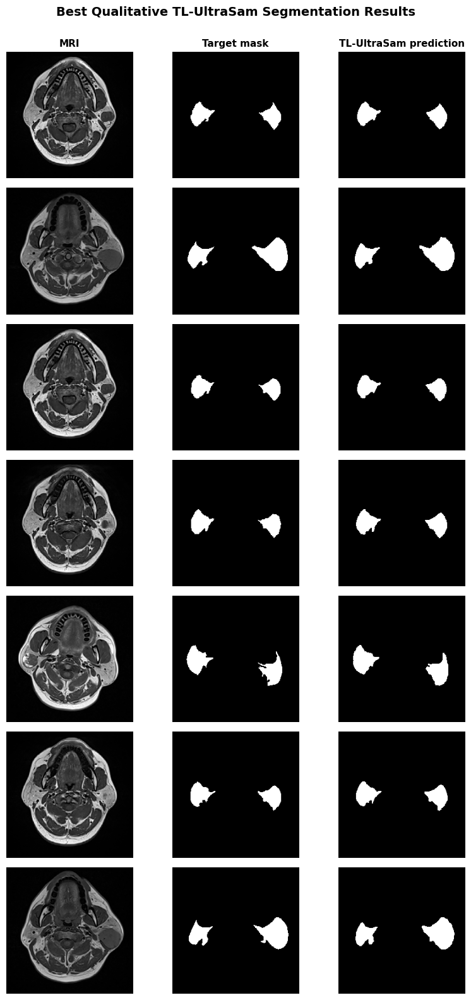


TL-UltraSam BEST QUALITATIVE RESULTS — 55 OUTPUT FILES
01. best_01_benign_28.1.4_GT_overlay.png
02. best_01_benign_28.1.4_MRI.png
03. best_01_benign_28.1.4_prediction.png
04. best_01_benign_28.1.4_prediction_overlay.png
05. best_01_benign_28.1.4_target.png
06. best_01_benign_28.1.4_TL_UltraSam_prediction_overlay.png
07. best_01_benign_28.1.4_triptych.png
08. best_02_benign_207-1-12_GT_overlay.png
09. best_02_benign_207-1-12_MRI.png
10. best_02_benign_207-1-12_prediction.png
11. best_02_benign_207-1-12_prediction_overlay.png
12. best_02_benign_207-1-12_target.png
13. best_02_benign_207-1-12_TL_UltraSam_prediction_overlay.png
14. best_02_benign_207-1-12_triptych.png
15. best_03_benign_1.70.9_GT_overlay.png
16. best_03_benign_1.70.9_MRI.png
17. best_03_benign_1.70.9_prediction.png
18. best_03_benign_1.70.9_prediction_overlay.png
19. best_03_benign_1.70.9_target.png
20. best_03_benign_1.70.9_TL_UltraSam_prediction_overlay.png
21. best_03_benign_1.70.9_triptych.png
22. best_04_benign_1.70.

In [15]:
# ============================================================
# FIGURE 7 — BEST QUALITATIVE RESULTS
# TL-UltraSam
#
# Select the 7 HIGHEST-DICE non-normal test images from the
# already executed TL-UltraSam test results.
#
# OUTPUT:
#   - Individual MRI panels
#   - Individual target masks
#   - Individual prediction masks
#   - MRI | Target | Prediction triptychs
#   - Combined publication panel
#   - CSV ranking
#   - JSON summary
#
# IMPORTANT:
#   - NO NEW INFERENCE IS PERFORMED
#   - Existing saved predictions are used
#   - Works after a kernel restart
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

import os
import json
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. SETTINGS
# ============================================================

N_BEST = 7

DISPLAY_MODEL_NAME = "TL-UltraSam"


EVAL_SIZE = int(
    globals().get(
        "CMP_SIZE",
        224
    )
)


# ============================================================
# 2. RESTORE RUN DIRECTORY
# ============================================================

if "run_dir" not in globals():

    run_dir = (
        r"C:\Users\pro\Pretoid Dataset Models"
        r"\Pretoid Dataset Models"
        r"\parotid_pg_benchmark"
        r"\ultrasam_box_prompt_partial_finetune"
        r"\seed42"
    )


run_dir = Path(
    run_dir
)


if not run_dir.exists():

    raise FileNotFoundError(
        "TL-UltraSam run directory was not found:\n"
        f"{run_dir}"
    )


print(
    "=" * 100
)

print(
    "FIGURE 7 — BEST QUALITATIVE TL-UltraSam RESULTS"
)

print(
    "=" * 100
)

print(
    "\nRun directory:"
)

print(
    run_dir
)


# ============================================================
# 3. OUTPUT DIRECTORY
# ============================================================

BEST_DIR = (
    run_dir
    / "figures"
    / "Figure7_best_results"
)


BEST_DIR.mkdir(
    parents=True,
    exist_ok=True
)


print(
    "\nFigure 7 output directory:"
)

print(
    BEST_DIR
)


# ============================================================
# 4. RESTORE MASK CONFIGURATION
# ============================================================

if "MASK_TARGET" not in globals():

    MASK_TARGET = "whole_parotid"


if "WHOLE_PAROTID_THRESHOLD" not in globals():

    WHOLE_PAROTID_THRESHOLD = 127


if "LESION_THRESHOLD" not in globals():

    LESION_THRESHOLD = 250


# ============================================================
# 5. RESTORE label_to_binary()
# ============================================================

if "label_to_binary" not in globals():

    def label_to_binary(
        mask,
        target=None
    ):

        """
        Convert original grayscale label to binary target mask.
        """

        if target is None:

            target = MASK_TARGET


        mask = np.asarray(
            mask
        )


        if target == "whole_parotid":

            return (
                mask
                >= WHOLE_PAROTID_THRESHOLD
            ).astype(
                np.uint8
            )


        elif target == "lesion_only":

            return (
                mask
                >= LESION_THRESHOLD
            ).astype(
                np.uint8
            )


        else:

            raise ValueError(
                f"Unknown MASK_TARGET: {target}"
            )


    print(
        "\nRestored label_to_binary()."
    )


# ============================================================
# 6. FIND per_image_metrics.csv
# ============================================================

if (
    "per_image" in globals()
    and
    isinstance(
        per_image,
        pd.DataFrame
    )
    and
    len(
        per_image
    ) > 0
):

    metrics_df = (
        per_image.copy()
    )


    print(
        "\nUsing per_image metrics from notebook memory."
    )


else:

    candidate_results_dirs = [

        run_dir
        / "official_test_transfer",

        run_dir
        / "results",

        run_dir
        / "test_results",

        run_dir,
    ]


    metrics_path = None


    for candidate_dir in candidate_results_dirs:

        candidate_file = (
            candidate_dir
            / "per_image_metrics.csv"
        )


        if candidate_file.exists():

            metrics_path = (
                candidate_file
            )

            break


    if metrics_path is None:

        found_metrics = sorted(
            run_dir.rglob(
                "per_image_metrics.csv"
            )
        )


        if len(
            found_metrics
        ) > 0:

            metrics_path = (
                found_metrics[
                    0
                ]
            )


    if metrics_path is None:

        raise FileNotFoundError(
            "Could not locate per_image_metrics.csv.\n\n"
            f"Searched inside:\n{run_dir}\n\n"
            "The TL-UltraSam test evaluation must have been "
            "completed and saved before Figure 7 is created."
        )


    results_dir = (
        metrics_path.parent
    )


    print(
        "\nResults directory:"
    )

    print(
        results_dir
    )


    print(
        "\nLoading per-image metrics:"
    )

    print(
        metrics_path
    )


    metrics_df = pd.read_csv(
        metrics_path
    )


# ============================================================
# 7. VALIDATE METRICS TABLE
# ============================================================

required_metric_columns = {

    "image",
    "category",
    "f1",
    "jaccard",
    "precision",
    "recall",
    "acc",
    "hd95",
}


missing_metric_columns = sorted(
    required_metric_columns
    -
    set(
        metrics_df.columns
    )
)


if missing_metric_columns:

    raise RuntimeError(
        "per_image_metrics.csv is missing required columns:\n"
        f"{missing_metric_columns}\n\n"
        "Available columns:\n"
        f"{list(metrics_df.columns)}"
    )


numeric_columns = [

    "f1",
    "jaccard",
    "precision",
    "recall",
    "acc",
    "hd95",
]


for column in numeric_columns:

    metrics_df[
        column
    ] = pd.to_numeric(
        metrics_df[
            column
        ],
        errors="coerce"
    )


metrics_df = (
    metrics_df
    .dropna(
        subset=[
            "f1"
        ]
    )
    .reset_index(
        drop=True
    )
)


print(
    f"\nLoaded {len(metrics_df)} evaluated test images."
)


# ============================================================
# 8. RESTORE ULTRA_COCO_ROOT
# ============================================================

def find_test_manifest_root(
    root
):

    root = Path(
        root
    )


    direct_candidates = [

        root
        / "coco",

        root
        / "UltraSAM_COCO",

        root
        / "ultrasam_coco",

        root
        / "coco_dataset",
    ]


    for candidate in direct_candidates:

        if (
            candidate
            / "test"
            / "manifest.json"
        ).exists():

            return candidate


    manifests = sorted(
        root.rglob(
            "manifest.json"
        )
    )


    for manifest in manifests:

        if (
            manifest.parent.name.lower()
            == "test"
        ):

            return (
                manifest
                .parent
                .parent
            )


    return None


if "ULTRA_COCO_ROOT" not in globals():

    ULTRA_COCO_ROOT = (
        find_test_manifest_root(
            run_dir
        )
    )


if ULTRA_COCO_ROOT is None:

    raise FileNotFoundError(
        "Could not locate the TL-UltraSam test manifest.\n\n"
        f"Searched inside:\n{run_dir}"
    )


ULTRA_COCO_ROOT = Path(
    ULTRA_COCO_ROOT
)


manifest_path = (
    ULTRA_COCO_ROOT
    / "test"
    / "manifest.json"
)


if not manifest_path.exists():

    raise FileNotFoundError(
        "Test manifest not found:\n"
        f"{manifest_path}"
    )


print(
    "\nTest manifest:"
)

print(
    manifest_path
)


# ============================================================
# 9. LOAD TEST MANIFEST
# ============================================================

with open(
    manifest_path,
    "r",
    encoding="utf-8"
) as f:

    test_manifest = json.load(
        f
    )


if len(
    test_manifest
) == 0:

    raise RuntimeError(
        "Test manifest is empty."
    )


print(
    "Manifest test images:",
    len(
        test_manifest
    )
)


# ============================================================
# 10. FIND SAVED PREDICTION DIRECTORY
# ============================================================

prediction_candidates = []


if "pred_mask_dir" in globals():

    prediction_candidates.append(
        Path(
            pred_mask_dir
        )
    )


prediction_candidates.extend(
    [

        run_dir
        / "official_test_transfer"
        / "pred_masks",

        run_dir
        / "pred_masks",

        run_dir
        / "test_predictions",

        run_dir
        / "predictions",
    ]
)


prediction_dir = None


for candidate in prediction_candidates:

    if (
        candidate.exists()
        and
        candidate.is_dir()
    ):

        png_files = list(
            candidate.glob(
                "*.png"
            )
        )


        if len(
            png_files
        ) > 0:

            prediction_dir = (
                candidate
            )

            break


if prediction_dir is None:

    possible_pred_dirs = []


    for p in run_dir.rglob(
        "*"
    ):

        if not p.is_dir():
            continue


        low = p.name.lower()


        if (
            "pred" in low
            and
            len(
                list(
                    p.glob(
                        "*.png"
                    )
                )
            ) > 0
        ):

            possible_pred_dirs.append(
                p
            )


    if possible_pred_dirs:

        prediction_dir = (
            possible_pred_dirs[
                0
            ]
        )


if prediction_dir is None:

    raise FileNotFoundError(
        "Could not locate saved TL-UltraSam prediction masks.\n\n"
        f"Searched inside:\n{run_dir}"
    )


pred_mask_dir = (
    prediction_dir
)


print(
    "\nPrediction directory:"
)

print(
    prediction_dir
)


print(
    "Saved TL-UltraSam prediction masks:",
    len(
        list(
            prediction_dir.glob(
                "*.png"
            )
        )
    )
)


# ============================================================
# 11. IMAGE READING HELPERS
# ============================================================

def imread_gray(
    path
):

    path = Path(
        path
    )


    if not path.exists():

        raise FileNotFoundError(
            path
        )


    data = np.fromfile(
        str(
            path
        ),
        dtype=np.uint8
    )


    image = cv2.imdecode(
        data,
        cv2.IMREAD_GRAYSCALE
    )


    if image is None:

        raise RuntimeError(
            f"Could not decode image:\n{path}"
        )


    return image


def imread_bgr(
    path
):

    path = Path(
        path
    )


    if not path.exists():

        raise FileNotFoundError(
            path
        )


    data = np.fromfile(
        str(
            path
        ),
        dtype=np.uint8
    )


    image = cv2.imdecode(
        data,
        cv2.IMREAD_COLOR
    )


    if image is None:

        raise RuntimeError(
            f"Could not decode image:\n{path}"
        )


    return image


def normalize_rel(
    path
):

    return (
        str(
            path
        )
        .replace(
            "\\",
            "/"
        )
        .lower()
        .strip()
    )


# ============================================================
# 12. CREATE MANIFEST LOOKUP TABLES
# ============================================================

manifest_by_rel = {}

manifest_by_filename = {}


for item in test_manifest:

    rel = normalize_rel(
        item.get(
            "rel_image",
            ""
        )
    )


    if rel:

        manifest_by_rel[
            rel
        ] = item


    if "image_path" not in item:

        continue


    filename = (
        Path(
            item[
                "image_path"
            ]
        )
        .name
        .lower()
    )


    manifest_by_filename.setdefault(
        filename,
        []
    ).append(
        item
    )


# ============================================================
# 13. SELECT 7 HIGHEST-DICE NON-NORMAL TEST IMAGES
# ============================================================

eligible_metrics = (
    metrics_df[
        metrics_df[
            "category"
        ]
        .astype(
            str
        )
        .str.lower()
        != "normal"
    ]
    .copy()
)


if len(
    eligible_metrics
) == 0:

    raise RuntimeError(
        "No non-normal test images found "
        "in per_image_metrics.csv."
    )


best = (
    eligible_metrics
    .nlargest(
        N_BEST,
        "f1"
    )
    .copy()
    .reset_index(
        drop=True
    )
)


print(
    "\n"
    + "=" * 100
)

print(
    f"TOP {len(best)} HIGHEST-DICE "
    f"{DISPLAY_MODEL_NAME} TEST IMAGES"
)

print(
    "=" * 100
)


preview_columns = [

    "image",
    "category",
    "f1",
    "jaccard",
    "precision",
    "recall",
]


print(
    best[
        preview_columns
    ]
    .to_string(
        index=False
    )
)


# ============================================================
# 14. EXPORT EACH BEST CASE
# ============================================================

export_rows = []


for rank, row in best.iterrows():

    rank_num = (
        rank
        +
        1
    )


    rel = normalize_rel(
        row[
            "image"
        ]
    )


    item = manifest_by_rel.get(
        rel
    )


    if item is None:

        filename = (
            Path(
                row[
                    "image"
                ]
            )
            .name
            .lower()
        )


        candidates = (
            manifest_by_filename.get(
                filename,
                []
            )
        )


        metric_category = str(
            row[
                "category"
            ]
        ).lower()


        candidates_same_category = [

            x

            for x
            in candidates

            if str(
                x.get(
                    "category",
                    ""
                )
            ).lower()
            ==
            metric_category
        ]


        if len(
            candidates_same_category
        ) > 0:

            candidates = (
                candidates_same_category
            )


        if len(
            candidates
        ) == 0:

            raise RuntimeError(
                "Could not match metrics row "
                "to test manifest:\n"
                f"{row['image']}"
            )


        item = (
            candidates[
                0
            ]
        )


    image_id = int(
        item[
            "image_id"
        ]
    )


    image_path = Path(
        item[
            "image_path"
        ]
    )


    mask_path = Path(
        item[
            "mask_path"
        ]
    )


    pred_path = (
        prediction_dir
        / f"{image_id}.png"
    )


    if not pred_path.exists():

        raise FileNotFoundError(
            "Saved TL-UltraSam prediction not found:\n"
            f"{pred_path}"
        )


    # ========================================================
    # 15. LOAD MRI
    # ========================================================

    image_bgr = imread_bgr(
        image_path
    )


    image_224 = cv2.resize(
        image_bgr,
        (
            EVAL_SIZE,
            EVAL_SIZE
        ),
        interpolation=cv2.INTER_LINEAR
    )


    image_rgb = cv2.cvtColor(
        image_224,
        cv2.COLOR_BGR2RGB
    )


    # ========================================================
    # 16. LOAD TARGET MASK
    # ========================================================

    gt_raw = imread_gray(
        mask_path
    )


    gt_binary = (
        label_to_binary(
            gt_raw
        )
        >
        0
    ).astype(
        np.uint8
    )


    gt_224 = cv2.resize(
        gt_binary,
        (
            EVAL_SIZE,
            EVAL_SIZE
        ),
        interpolation=cv2.INTER_NEAREST
    )


    gt_224 = (
        gt_224
        >
        0
    ).astype(
        np.uint8
    )


    # ========================================================
    # 17. LOAD SAVED TL-UltraSam PREDICTION
    # ========================================================

    pred_native = (
        imread_gray(
            pred_path
        )
        >
        127
    ).astype(
        np.uint8
    )


    pred_224 = cv2.resize(
        pred_native,
        (
            EVAL_SIZE,
            EVAL_SIZE
        ),
        interpolation=cv2.INTER_NEAREST
    )


    pred_224 = (
        pred_224
        >
        0
    ).astype(
        np.uint8
    )


    # ========================================================
    # 18. BASE OUTPUT NAME
    # ========================================================

    safe_category = (
        str(
            row[
                "category"
            ]
        )
        .replace(
            " ",
            "_"
        )
    )


    base = (
        f"best_{rank_num:02d}_"
        f"{safe_category}_"
        f"{image_path.stem}"
    )


    # ========================================================
    # 19. SAVE INDIVIDUAL PANELS
    # ========================================================

    cv2.imwrite(
        str(
            BEST_DIR
            / f"{base}_MRI.png"
        ),
        image_224
    )


    cv2.imwrite(
        str(
            BEST_DIR
            / f"{base}_target.png"
        ),
        gt_224
        *
        255
    )


    cv2.imwrite(
        str(
            BEST_DIR
            / f"{base}_prediction.png"
        ),
        pred_224
        *
        255
    )


    # ========================================================
    # 20. CREATE MRI | TARGET | TL-UltraSam PREDICTION
    # ========================================================

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(
            7.4,
            2.65
        )
    )


    axes[
        0
    ].imshow(
        image_rgb
    )


    axes[
        0
    ].set_title(
        "MRI",
        fontsize=10,
        fontweight="bold"
    )


    axes[
        1
    ].imshow(
        gt_224,
        cmap="gray",
        vmin=0,
        vmax=1
    )


    axes[
        1
    ].set_title(
        "Target mask",
        fontsize=10,
        fontweight="bold"
    )


    axes[
        2
    ].imshow(
        pred_224,
        cmap="gray",
        vmin=0,
        vmax=1
    )


    # --------------------------------------------------------
    # NEW DISPLAY NAME
    # --------------------------------------------------------

    axes[
        2
    ].set_title(
        f"{DISPLAY_MODEL_NAME} prediction",
        fontsize=10,
        fontweight="bold"
    )


    for ax in axes:

        ax.axis(
            "off"
        )


    fig.suptitle(
        (
            f"Rank {rank_num} | "
            f"{row['category']} | "
            f"{image_path.name} | "
            f"Dice = {100 * row['f1']:.2f}%"
        ),
        fontsize=10.5,
        fontweight="bold"
    )


    plt.tight_layout()


    triptych_path = (
        BEST_DIR
        / f"{base}_triptych.png"
    )


    plt.savefig(
        triptych_path,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )


    plt.close(
        fig
    )


    # ========================================================
    # 21. OVERLAYS
    # ========================================================

    gt_overlay = (
        image_224
        .astype(
            np.float32
        )
        .copy()
    )


    pred_overlay = (
        image_224
        .astype(
            np.float32
        )
        .copy()
    )


    gt_color = np.array(
        [
            255,
            80,
            80
        ],
        dtype=np.float32
    )


    pred_color = np.array(
        [
            80,
            220,
            80
        ],
        dtype=np.float32
    )


    alpha = 0.45


    gt_fg = (
        gt_224
        >
        0
    )


    pred_fg = (
        pred_224
        >
        0
    )


    gt_overlay[
        gt_fg
    ] = (

        (
            1
            -
            alpha
        )
        *
        gt_overlay[
            gt_fg
        ]

        +

        alpha
        *
        gt_color
    )


    pred_overlay[
        pred_fg
    ] = (

        (
            1
            -
            alpha
        )
        *
        pred_overlay[
            pred_fg
        ]

        +

        alpha
        *
        pred_color
    )


    gt_overlay = np.clip(
        gt_overlay,
        0,
        255
    ).astype(
        np.uint8
    )


    pred_overlay = np.clip(
        pred_overlay,
        0,
        255
    ).astype(
        np.uint8
    )


    cv2.imwrite(
        str(
            BEST_DIR
            / f"{base}_GT_overlay.png"
        ),
        gt_overlay
    )


    cv2.imwrite(
        str(
            BEST_DIR
            / f"{base}_TL_UltraSam_prediction_overlay.png"
        ),
        pred_overlay
    )


    # ========================================================
    # 22. STORE RESULTS
    # ========================================================

    export_rows.append(
        {

            "rank":
                int(
                    rank_num
                ),

            "image_id":
                int(
                    image_id
                ),

            "filename":
                image_path.name,

            "category":
                str(
                    row[
                        "category"
                    ]
                ),

            "model":
                DISPLAY_MODEL_NAME,

            "dice":
                float(
                    row[
                        "f1"
                    ]
                ),

            "dice_percent":
                float(
                    100
                    *
                    row[
                        "f1"
                    ]
                ),

            "iou":
                float(
                    row[
                        "jaccard"
                    ]
                ),

            "iou_percent":
                float(
                    100
                    *
                    row[
                        "jaccard"
                    ]
                ),

            "precision":
                float(
                    row[
                        "precision"
                    ]
                ),

            "recall":
                float(
                    row[
                        "recall"
                    ]
                ),

            "accuracy":
                float(
                    row[
                        "acc"
                    ]
                ),

            "hd95":
                float(
                    row[
                        "hd95"
                    ]
                ),

            "gt_area":
                int(
                    gt_224.sum()
                ),

            "pred_area":
                int(
                    pred_224.sum()
                ),
        }
    )


# ============================================================
# 23. RESULTS TABLE
# ============================================================

best_table = pd.DataFrame(
    export_rows
)


best_table.to_csv(
    BEST_DIR
    / "best_7_TL_UltraSam_results.csv",
    index=False
)


# ============================================================
# 24. PRINT RANKING TABLE
# ============================================================

print(
    "\n"
    + "=" * 110
)

print(
    f"BEST 7 QUALITATIVE RESULTS — {DISPLAY_MODEL_NAME}"
)

print(
    "=" * 110
)


print(
    best_table[
        [
            "rank",
            "filename",
            "category",
            "dice_percent",
            "iou_percent",
            "precision",
            "recall",
            "hd95",
        ]
    ]
    .round(
        {

            "dice_percent":
                2,

            "iou_percent":
                2,

            "precision":
                4,

            "recall":
                4,

            "hd95":
                2,
        }
    )
    .to_string(
        index=False
    )
)


print(
    "=" * 110
)


# ============================================================
# 25. COMBINED PUBLICATION PANEL
#
# 7 rows × 3 columns
#
# MRI | Target mask | TL-UltraSam prediction
# ============================================================

n_rows = len(
    export_rows
)


fig, axes = plt.subplots(
    n_rows,
    3,
    figsize=(
        8.5,
        2.25
        *
        n_rows
    )
)


axes = np.atleast_2d(
    axes
)


for row_idx, info in enumerate(
    export_rows
):


    item = next(

        x

        for x
        in test_manifest

        if int(
            x[
                "image_id"
            ]
        )
        ==
        int(
            info[
                "image_id"
            ]
        )
    )


    # --------------------------------------------------------
    # MRI
    # --------------------------------------------------------

    image = cv2.resize(
        imread_bgr(
            item[
                "image_path"
            ]
        ),
        (
            EVAL_SIZE,
            EVAL_SIZE
        ),
        interpolation=cv2.INTER_LINEAR
    )


    image = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )


    # --------------------------------------------------------
    # GT
    # --------------------------------------------------------

    gt = (
        label_to_binary(
            imread_gray(
                item[
                    "mask_path"
                ]
            )
        )
        >
        0
    ).astype(
        np.uint8
    )


    gt = cv2.resize(
        gt,
        (
            EVAL_SIZE,
            EVAL_SIZE
        ),
        interpolation=cv2.INTER_NEAREST
    )


    # --------------------------------------------------------
    # TL-UltraSam prediction
    # --------------------------------------------------------

    pred = (
        imread_gray(
            prediction_dir
            /
            f"{info['image_id']}.png"
        )
        >
        127
    ).astype(
        np.uint8
    )


    pred = cv2.resize(
        pred,
        (
            EVAL_SIZE,
            EVAL_SIZE
        ),
        interpolation=cv2.INTER_NEAREST
    )


    axes[
        row_idx,
        0
    ].imshow(
        image
    )


    axes[
        row_idx,
        1
    ].imshow(
        gt,
        cmap="gray",
        vmin=0,
        vmax=1
    )


    axes[
        row_idx,
        2
    ].imshow(
        pred,
        cmap="gray",
        vmin=0,
        vmax=1
    )


    axes[
        row_idx,
        0
    ].set_ylabel(
        (
            f"#{info['rank']}\n"
            f"{info['filename']}\n"
            f"Dice {info['dice_percent']:.1f}%"
        ),
        fontsize=8.5,
        fontweight="bold"
    )


    for col in range(
        3
    ):

        axes[
            row_idx,
            col
        ].axis(
            "off"
        )


axes[
    0,
    0
].set_title(
    "MRI",
    fontsize=11,
    fontweight="bold"
)


axes[
    0,
    1
].set_title(
    "Target mask",
    fontsize=11,
    fontweight="bold"
)


# ============================================================
# IMPORTANT NAME CHANGE
# ============================================================

axes[
    0,
    2
].set_title(
    f"{DISPLAY_MODEL_NAME} prediction",
    fontsize=11,
    fontweight="bold"
)


fig.suptitle(
    (
        f"Best Qualitative {DISPLAY_MODEL_NAME} "
        "Segmentation Results"
    ),
    fontsize=14,
    fontweight="bold",
    y=1.002
)


plt.tight_layout()


combined_path = (
    BEST_DIR
    / "best_7_TL_UltraSam_combined_panel.png"
)


plt.savefig(
    combined_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)


plt.show()


plt.close(
    fig
)


# ============================================================
# 26. SAVE JSON SUMMARY
# ============================================================

summary = {

    "model_display_name":
        DISPLAY_MODEL_NAME,

    "selection":
        "Seven highest-Dice non-normal test images",

    "ranking_metric":
        "Dice / F1",

    "evaluation_resolution":
        [
            int(
                EVAL_SIZE
            ),
            int(
                EVAL_SIZE
            ),
        ],

    "number_of_examples":
        int(
            len(
                export_rows
            )
        ),

    "mask_target":
        str(
            MASK_TARGET
        ),

    "metrics_source":
        (
            str(
                metrics_path
            )
            if "metrics_path" in locals()
            else
            "in-memory per_image dataframe"
        ),

    "test_manifest":
        str(
            manifest_path
        ),

    "prediction_directory":
        str(
            prediction_dir
        ),

    "examples":
        export_rows,
}


with open(
    BEST_DIR
    / "best_7_TL_UltraSam_results.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        summary,
        f,
        indent=4,
        ensure_ascii=False
    )


# ============================================================
# 27. ZIP FIGURE 7 ASSETS
# ============================================================

zip_base = (
    run_dir
    / "figures"
    / "Figure7_best_results_TL_UltraSam"
)


zip_path = shutil.make_archive(
    str(
        zip_base
    ),
    "zip",
    root_dir=str(
        BEST_DIR
    )
)


# ============================================================
# 28. PRINT OUTPUT FILES
# ============================================================

files = sorted(
    BEST_DIR.iterdir()
)


print(
    "\n"
    + "=" * 100
)

print(
    f"{DISPLAY_MODEL_NAME} BEST QUALITATIVE RESULTS — "
    f"{len(files)} OUTPUT FILES"
)

print(
    "=" * 100
)


for i, file in enumerate(
    files,
    start=1
):

    print(
        f"{i:02d}. {file.name}"
    )


print(
    "=" * 100
)


print(
    "\nOUTPUT FOLDER:"
)

print(
    BEST_DIR
)


print(
    "\nZIP FILE:"
)

print(
    zip_path
)


print(
    "\n"
    + "=" * 100
)

print(
    f"DONE — {DISPLAY_MODEL_NAME} FIGURE 7 EXPORTED"
)

print(
    "=" * 100
)

FIGURE 7 — BEST MALIGNANT TL-UltraSam RESULTS

Run directory:
C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models\parotid_pg_benchmark\ultrasam_box_prompt_partial_finetune\seed42

Output directory:
C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models\parotid_pg_benchmark\ultrasam_box_prompt_partial_finetune\seed42\figures\Figure7_best_malignant_results_TL_UltraSam

Loading metrics:
C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models\parotid_pg_benchmark\ultrasam_box_prompt_partial_finetune\seed42\results\per_image_metrics.csv

Loaded 179 evaluated test images.

Malignant evaluated test images: 25

TOP 7 HIGHEST-DICE MALIGNANT TL-UltraSam TEST IMAGES
                      image  category     f1  jaccard  precision  recall   hd95
malignant PG/IMAGE/1.16.png malignant 0.9256   0.8615     0.9032  0.9492 1.0000
malignant PG/IMAGE/1.13.png malignant 0.8444   0.7308     0.7451  0.9744 1.3521
 malignant PG/IMAGE/1.8.png malignant 0.8406   0.7250     0.8286  0.8529 1.0828
ma

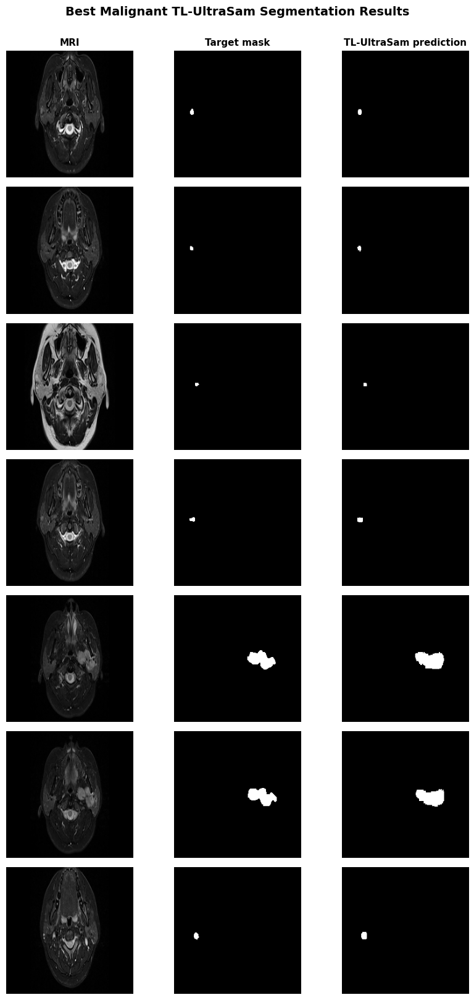


BEST MALIGNANT TL-UltraSam RESULTS — 45 OUTPUT FILES
01. best_malignant_TL_UltraSam_combined_panel.png
02. best_malignant_TL_UltraSam_results.csv
03. best_malignant_TL_UltraSam_results.json
04. malignant_best_01_1.16_GT_overlay.png
05. malignant_best_01_1.16_MRI.png
06. malignant_best_01_1.16_target.png
07. malignant_best_01_1.16_TL_UltraSam_prediction.png
08. malignant_best_01_1.16_TL_UltraSam_prediction_overlay.png
09. malignant_best_01_1.16_triptych.png
10. malignant_best_02_1.13_GT_overlay.png
11. malignant_best_02_1.13_MRI.png
12. malignant_best_02_1.13_target.png
13. malignant_best_02_1.13_TL_UltraSam_prediction.png
14. malignant_best_02_1.13_TL_UltraSam_prediction_overlay.png
15. malignant_best_02_1.13_triptych.png
16. malignant_best_03_1.8_GT_overlay.png
17. malignant_best_03_1.8_MRI.png
18. malignant_best_03_1.8_target.png
19. malignant_best_03_1.8_TL_UltraSam_prediction.png
20. malignant_best_03_1.8_TL_UltraSam_prediction_overlay.png
21. malignant_best_03_1.8_triptych.png
22

In [16]:
# ============================================================
# FIGURE 7 — BEST MALIGNANT QUALITATIVE RESULTS
# TL-UltraSam
#
# Select the N_BEST HIGHEST-DICE MALIGNANT test images from
# the already executed TL-UltraSam test results.
#
# OUTPUT:
#   - Individual MRI panels
#   - Individual target masks
#   - Individual TL-UltraSam prediction masks
#   - MRI | Target | Prediction triptychs
#   - GT and prediction overlays
#   - Combined publication panel
#   - CSV ranking
#   - JSON summary
#   - ZIP archive
#
# IMPORTANT:
#   - MALIGNANT CASES ONLY
#   - NO NEW INFERENCE IS PERFORMED
#   - Existing saved predictions are used
#   - Works after a kernel restart
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

import os
import json
import shutil
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. SETTINGS
# ============================================================

N_BEST = 7

TARGET_CATEGORY = "malignant"

DISPLAY_MODEL_NAME = "TL-UltraSam"


EVAL_SIZE = int(
    globals().get(
        "CMP_SIZE",
        224
    )
)


# ============================================================
# 2. RESTORE RUN DIRECTORY
# ============================================================

if "run_dir" not in globals():

    run_dir = (
        r"C:\Users\pro\Pretoid Dataset Models"
        r"\Pretoid Dataset Models"
        r"\parotid_pg_benchmark"
        r"\ultrasam_box_prompt_partial_finetune"
        r"\seed42"
    )


run_dir = Path(
    run_dir
)


if not run_dir.exists():

    raise FileNotFoundError(
        "TL-UltraSam run directory was not found:\n"
        f"{run_dir}"
    )


print(
    "=" * 100
)

print(
    "FIGURE 7 — BEST MALIGNANT TL-UltraSam RESULTS"
)

print(
    "=" * 100
)

print(
    "\nRun directory:"
)

print(
    run_dir
)


# ============================================================
# 3. OUTPUT DIRECTORY
# ============================================================

BEST_DIR = (
    run_dir
    / "figures"
    / "Figure7_best_malignant_results_TL_UltraSam"
)


BEST_DIR.mkdir(
    parents=True,
    exist_ok=True
)


print(
    "\nOutput directory:"
)

print(
    BEST_DIR
)


# ============================================================
# 4. RESTORE MASK CONFIGURATION
# ============================================================

if "MASK_TARGET" not in globals():

    MASK_TARGET = "whole_parotid"


if "WHOLE_PAROTID_THRESHOLD" not in globals():

    WHOLE_PAROTID_THRESHOLD = 127


if "LESION_THRESHOLD" not in globals():

    LESION_THRESHOLD = 250


# ============================================================
# 5. RESTORE label_to_binary()
# ============================================================

if "label_to_binary" not in globals():

    def label_to_binary(
        mask,
        target=None
    ):

        if target is None:

            target = MASK_TARGET


        mask = np.asarray(
            mask
        )


        if target == "whole_parotid":

            return (
                mask
                >= WHOLE_PAROTID_THRESHOLD
            ).astype(
                np.uint8
            )


        elif target == "lesion_only":

            return (
                mask
                >= LESION_THRESHOLD
            ).astype(
                np.uint8
            )


        else:

            raise ValueError(
                f"Unknown MASK_TARGET: {target}"
            )


    print(
        "\nRestored label_to_binary()."
    )


# ============================================================
# 6. LOAD TEST METRICS
# ============================================================

metrics_path = None


if (
    "per_image" in globals()
    and
    isinstance(
        per_image,
        pd.DataFrame
    )
    and
    len(
        per_image
    ) > 0
):

    metrics_df = (
        per_image.copy()
    )


    print(
        "\nUsing per_image metrics from notebook memory."
    )


else:

    candidate_results_dirs = [

        run_dir
        / "official_test_transfer",

        run_dir
        / "results",

        run_dir
        / "test_results",

        run_dir,
    ]


    for candidate_dir in candidate_results_dirs:

        candidate_file = (
            candidate_dir
            / "per_image_metrics.csv"
        )


        if candidate_file.exists():

            metrics_path = (
                candidate_file
            )

            break


    # --------------------------------------------------------
    # Recursive fallback
    # --------------------------------------------------------

    if metrics_path is None:

        found_metrics = sorted(
            run_dir.rglob(
                "per_image_metrics.csv"
            )
        )


        if len(
            found_metrics
        ) > 0:

            metrics_path = (
                found_metrics[
                    0
                ]
            )


    if metrics_path is None:

        raise FileNotFoundError(
            "Could not locate per_image_metrics.csv.\n\n"
            f"Searched inside:\n{run_dir}"
        )


    print(
        "\nLoading metrics:"
    )

    print(
        metrics_path
    )


    metrics_df = pd.read_csv(
        metrics_path
    )


print(
    f"\nLoaded {len(metrics_df)} evaluated test images."
)


# ============================================================
# 7. VALIDATE METRICS
# ============================================================

required_metric_columns = {

    "image",
    "category",
    "f1",
    "jaccard",
    "precision",
    "recall",
    "acc",
    "hd95",
}


missing_metric_columns = sorted(
    required_metric_columns
    -
    set(
        metrics_df.columns
    )
)


if missing_metric_columns:

    raise RuntimeError(
        "Metrics table is missing required columns:\n"
        f"{missing_metric_columns}\n\n"
        "Available columns:\n"
        f"{list(metrics_df.columns)}"
    )


numeric_columns = [

    "f1",
    "jaccard",
    "precision",
    "recall",
    "acc",
    "hd95",
]


for column in numeric_columns:

    metrics_df[
        column
    ] = pd.to_numeric(
        metrics_df[
            column
        ],
        errors="coerce"
    )


metrics_df = (
    metrics_df
    .dropna(
        subset=[
            "f1"
        ]
    )
    .reset_index(
        drop=True
    )
)


# ============================================================
# 8. FILTER MALIGNANT CASES ONLY
# ============================================================

malignant_metrics = (
    metrics_df[
        metrics_df[
            "category"
        ]
        .astype(
            str
        )
        .str.strip()
        .str.lower()
        ==
        TARGET_CATEGORY
    ]
    .copy()
)


print(
    "\nMalignant evaluated test images:",
    len(
        malignant_metrics
    )
)


if len(
    malignant_metrics
) == 0:

    raise RuntimeError(
        "No malignant test images were found "
        "in per_image_metrics.csv."
    )


# ============================================================
# 9. SELECT HIGHEST-DICE MALIGNANT CASES
# ============================================================

actual_n = min(
    N_BEST,
    len(
        malignant_metrics
    )
)


best = (
    malignant_metrics
    .nlargest(
        actual_n,
        "f1"
    )
    .copy()
    .reset_index(
        drop=True
    )
)


print(
    "\n"
    + "=" * 105
)

print(
    f"TOP {len(best)} HIGHEST-DICE MALIGNANT "
    f"{DISPLAY_MODEL_NAME} TEST IMAGES"
)

print(
    "=" * 105
)


print(
    best[
        [
            "image",
            "category",
            "f1",
            "jaccard",
            "precision",
            "recall",
            "hd95",
        ]
    ]
    .round(
        4
    )
    .to_string(
        index=False
    )
)


# ============================================================
# 10. RESTORE ULTRA_COCO_ROOT
# ============================================================

def find_test_manifest_root(
    root
):

    root = Path(
        root
    )


    direct_candidates = [

        root
        / "coco",

        root
        / "UltraSAM_COCO",

        root
        / "ultrasam_coco",

        root
        / "coco_dataset",
    ]


    for candidate in direct_candidates:

        if (
            candidate
            / "test"
            / "manifest.json"
        ).exists():

            return candidate


    manifests = sorted(
        root.rglob(
            "manifest.json"
        )
    )


    for manifest in manifests:

        if (
            manifest.parent.name.lower()
            == "test"
        ):

            return (
                manifest
                .parent
                .parent
            )


    return None


if "ULTRA_COCO_ROOT" not in globals():

    ULTRA_COCO_ROOT = (
        find_test_manifest_root(
            run_dir
        )
    )


if ULTRA_COCO_ROOT is None:

    raise FileNotFoundError(
        "Could not locate the TL-UltraSam "
        "test manifest."
    )


ULTRA_COCO_ROOT = Path(
    ULTRA_COCO_ROOT
)


manifest_path = (
    ULTRA_COCO_ROOT
    / "test"
    / "manifest.json"
)


if not manifest_path.exists():

    raise FileNotFoundError(
        manifest_path
    )


# ============================================================
# 11. LOAD TEST MANIFEST
# ============================================================

with open(
    manifest_path,
    "r",
    encoding="utf-8"
) as f:

    test_manifest = json.load(
        f
    )


if len(
    test_manifest
) == 0:

    raise RuntimeError(
        "Test manifest is empty."
    )


print(
    "\nTest manifest images:",
    len(
        test_manifest
    )
)


# ============================================================
# 12. FIND SAVED PREDICTION DIRECTORY
# ============================================================

prediction_candidates = []


if "pred_mask_dir" in globals():

    prediction_candidates.append(
        Path(
            pred_mask_dir
        )
    )


prediction_candidates.extend(
    [

        run_dir
        / "official_test_transfer"
        / "pred_masks",

        run_dir
        / "pred_masks",

        run_dir
        / "test_predictions",

        run_dir
        / "predictions",
    ]
)


prediction_dir = None


for candidate in prediction_candidates:

    if (
        candidate.exists()
        and
        candidate.is_dir()
        and
        len(
            list(
                candidate.glob(
                    "*.png"
                )
            )
        ) > 0
    ):

        prediction_dir = (
            candidate
        )

        break


if prediction_dir is None:

    # Recursive fallback

    for directory in run_dir.rglob(
        "*"
    ):

        if not directory.is_dir():

            continue


        if "pred" not in directory.name.lower():

            continue


        if len(
            list(
                directory.glob(
                    "*.png"
                )
            )
        ) > 0:

            prediction_dir = (
                directory
            )

            break


if prediction_dir is None:

    raise FileNotFoundError(
        "Could not locate saved "
        "TL-UltraSam prediction masks."
    )


print(
    "\nPrediction directory:"
)

print(
    prediction_dir
)


# ============================================================
# 13. IMAGE READING HELPERS
# ============================================================

def imread_gray(
    path
):

    path = Path(
        path
    )


    if not path.exists():

        raise FileNotFoundError(
            path
        )


    data = np.fromfile(
        str(
            path
        ),
        dtype=np.uint8
    )


    image = cv2.imdecode(
        data,
        cv2.IMREAD_GRAYSCALE
    )


    if image is None:

        raise RuntimeError(
            f"Could not decode:\n{path}"
        )


    return image


def imread_bgr(
    path
):

    path = Path(
        path
    )


    if not path.exists():

        raise FileNotFoundError(
            path
        )


    data = np.fromfile(
        str(
            path
        ),
        dtype=np.uint8
    )


    image = cv2.imdecode(
        data,
        cv2.IMREAD_COLOR
    )


    if image is None:

        raise RuntimeError(
            f"Could not decode:\n{path}"
        )


    return image


def normalize_rel(
    path
):

    return (
        str(
            path
        )
        .replace(
            "\\",
            "/"
        )
        .lower()
        .strip()
    )


# ============================================================
# 14. BUILD MANIFEST LOOKUPS
# ============================================================

manifest_by_rel = {}

manifest_by_filename = {}


for item in test_manifest:

    rel = normalize_rel(
        item.get(
            "rel_image",
            ""
        )
    )


    if rel:

        manifest_by_rel[
            rel
        ] = item


    if "image_path" in item:

        filename = (
            Path(
                item[
                    "image_path"
                ]
            )
            .name
            .lower()
        )


        manifest_by_filename.setdefault(
            filename,
            []
        ).append(
            item
        )


# ============================================================
# 15. EXPORT EACH MALIGNANT CASE
# ============================================================

export_rows = []


for rank, row in best.iterrows():

    rank_num = (
        rank
        +
        1
    )


    rel = normalize_rel(
        row[
            "image"
        ]
    )


    # --------------------------------------------------------
    # Try exact relative-path match.
    # --------------------------------------------------------

    item = manifest_by_rel.get(
        rel
    )


    # --------------------------------------------------------
    # Fallback to filename/category.
    # --------------------------------------------------------

    if item is None:

        filename = (
            Path(
                row[
                    "image"
                ]
            )
            .name
            .lower()
        )


        candidates = (
            manifest_by_filename.get(
                filename,
                []
            )
        )


        candidates = [

            x

            for x
            in candidates

            if str(
                x.get(
                    "category",
                    ""
                )
            )
            .strip()
            .lower()
            ==
            TARGET_CATEGORY
        ]


        if len(
            candidates
        ) == 0:

            raise RuntimeError(
                "Could not match malignant metrics row "
                "to test manifest:\n"
                f"{row['image']}"
            )


        item = (
            candidates[
                0
            ]
        )


    # --------------------------------------------------------
    # Verify the manifest category.
    # --------------------------------------------------------

    manifest_category = str(
        item.get(
            "category",
            ""
        )
    ).strip().lower()


    if manifest_category != TARGET_CATEGORY:

        raise RuntimeError(
            "Matched manifest item is not malignant:\n"
            f"{item}"
        )


    # --------------------------------------------------------
    # Paths
    # --------------------------------------------------------

    image_id = int(
        item[
            "image_id"
        ]
    )


    image_path = Path(
        item[
            "image_path"
        ]
    )


    mask_path = Path(
        item[
            "mask_path"
        ]
    )


    pred_path = (
        prediction_dir
        / f"{image_id}.png"
    )


    if not pred_path.exists():

        raise FileNotFoundError(
            "Saved TL-UltraSam prediction "
            "not found:\n"
            f"{pred_path}"
        )


    # ========================================================
    # 16. LOAD MRI
    # ========================================================

    image_bgr = imread_bgr(
        image_path
    )


    image_eval = cv2.resize(
        image_bgr,
        (
            EVAL_SIZE,
            EVAL_SIZE
        ),
        interpolation=cv2.INTER_LINEAR
    )


    image_rgb = cv2.cvtColor(
        image_eval,
        cv2.COLOR_BGR2RGB
    )


    # ========================================================
    # 17. LOAD GROUND-TRUTH TARGET
    # ========================================================

    gt_raw = imread_gray(
        mask_path
    )


    gt_binary = (
        label_to_binary(
            gt_raw
        )
        >
        0
    ).astype(
        np.uint8
    )


    gt_eval = cv2.resize(
        gt_binary,
        (
            EVAL_SIZE,
            EVAL_SIZE
        ),
        interpolation=cv2.INTER_NEAREST
    )


    gt_eval = (
        gt_eval
        >
        0
    ).astype(
        np.uint8
    )


    # ========================================================
    # 18. LOAD TL-UltraSam PREDICTION
    # ========================================================

    pred_native = (
        imread_gray(
            pred_path
        )
        >
        127
    ).astype(
        np.uint8
    )


    pred_eval = cv2.resize(
        pred_native,
        (
            EVAL_SIZE,
            EVAL_SIZE
        ),
        interpolation=cv2.INTER_NEAREST
    )


    pred_eval = (
        pred_eval
        >
        0
    ).astype(
        np.uint8
    )


    # ========================================================
    # 19. OUTPUT BASE NAME
    # ========================================================

    base = (
        f"malignant_best_{rank_num:02d}_"
        f"{image_path.stem}"
    )


    # ========================================================
    # 20. SAVE MRI / TARGET / PREDICTION
    # ========================================================

    cv2.imwrite(
        str(
            BEST_DIR
            / f"{base}_MRI.png"
        ),
        image_eval
    )


    cv2.imwrite(
        str(
            BEST_DIR
            / f"{base}_target.png"
        ),
        gt_eval
        *
        255
    )


    cv2.imwrite(
        str(
            BEST_DIR
            / f"{base}_TL_UltraSam_prediction.png"
        ),
        pred_eval
        *
        255
    )


    # ========================================================
    # 21. CREATE GT OVERLAY
    # ========================================================

    gt_overlay = (
        image_eval
        .copy()
        .astype(
            np.float32
        )
    )


    gt_fg = (
        gt_eval
        >
        0
    )


    gt_colour = np.array(
        [
            255,
            80,
            80
        ],
        dtype=np.float32
    )


    gt_overlay[
        gt_fg
    ] = (

        0.55
        *
        gt_overlay[
            gt_fg
        ]

        +

        0.45
        *
        gt_colour
    )


    gt_overlay = np.clip(
        gt_overlay,
        0,
        255
    ).astype(
        np.uint8
    )


    cv2.imwrite(
        str(
            BEST_DIR
            / f"{base}_GT_overlay.png"
        ),
        gt_overlay
    )


    # ========================================================
    # 22. CREATE PREDICTION OVERLAY
    # ========================================================

    pred_overlay = (
        image_eval
        .copy()
        .astype(
            np.float32
        )
    )


    pred_fg = (
        pred_eval
        >
        0
    )


    pred_colour = np.array(
        [
            80,
            220,
            80
        ],
        dtype=np.float32
    )


    pred_overlay[
        pred_fg
    ] = (

        0.55
        *
        pred_overlay[
            pred_fg
        ]

        +

        0.45
        *
        pred_colour
    )


    pred_overlay = np.clip(
        pred_overlay,
        0,
        255
    ).astype(
        np.uint8
    )


    cv2.imwrite(
        str(
            BEST_DIR
            /
            f"{base}_TL_UltraSam_prediction_overlay.png"
        ),
        pred_overlay
    )


    # ========================================================
    # 23. CREATE TRIPTYCH
    # ========================================================

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(
            7.6,
            2.75
        )
    )


    axes[
        0
    ].imshow(
        image_rgb
    )


    axes[
        0
    ].set_title(
        "MRI",
        fontsize=10,
        fontweight="bold"
    )


    axes[
        1
    ].imshow(
        gt_eval,
        cmap="gray",
        vmin=0,
        vmax=1
    )


    axes[
        1
    ].set_title(
        "Target mask",
        fontsize=10,
        fontweight="bold"
    )


    axes[
        2
    ].imshow(
        pred_eval,
        cmap="gray",
        vmin=0,
        vmax=1
    )


    axes[
        2
    ].set_title(
        f"{DISPLAY_MODEL_NAME} prediction",
        fontsize=10,
        fontweight="bold"
    )


    for ax in axes:

        ax.axis(
            "off"
        )


    fig.suptitle(
        (
            f"Malignant rank {rank_num} | "
            f"{image_path.name} | "
            f"Dice = {100 * row['f1']:.2f}%"
        ),
        fontsize=10.5,
        fontweight="bold"
    )


    plt.tight_layout()


    triptych_path = (
        BEST_DIR
        /
        f"{base}_triptych.png"
    )


    plt.savefig(
        triptych_path,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )


    plt.close(
        fig
    )


    # ========================================================
    # 24. SAVE METRICS
    # ========================================================

    export_rows.append(
        {

            "rank":
                int(
                    rank_num
                ),

            "image_id":
                int(
                    image_id
                ),

            "filename":
                image_path.name,

            "category":
                "malignant",

            "model":
                DISPLAY_MODEL_NAME,

            "dice":
                float(
                    row[
                        "f1"
                    ]
                ),

            "dice_percent":
                float(
                    100
                    *
                    row[
                        "f1"
                    ]
                ),

            "iou":
                float(
                    row[
                        "jaccard"
                    ]
                ),

            "iou_percent":
                float(
                    100
                    *
                    row[
                        "jaccard"
                    ]
                ),

            "precision":
                float(
                    row[
                        "precision"
                    ]
                ),

            "recall":
                float(
                    row[
                        "recall"
                    ]
                ),

            "accuracy":
                float(
                    row[
                        "acc"
                    ]
                ),

            "hd95":
                float(
                    row[
                        "hd95"
                    ]
                ),

            "gt_area":
                int(
                    gt_eval.sum()
                ),

            "pred_area":
                int(
                    pred_eval.sum()
                ),
        }
    )


# ============================================================
# 25. RESULTS TABLE
# ============================================================

best_table = pd.DataFrame(
    export_rows
)


csv_path = (
    BEST_DIR
    /
    "best_malignant_TL_UltraSam_results.csv"
)


best_table.to_csv(
    csv_path,
    index=False
)


# ============================================================
# 26. PRINT MALIGNANT RESULTS
# ============================================================

print(
    "\n"
    + "=" * 110
)

print(
    f"BEST {len(best_table)} MALIGNANT "
    f"{DISPLAY_MODEL_NAME} RESULTS"
)

print(
    "=" * 110
)


print(
    best_table[
        [
            "rank",
            "filename",
            "category",
            "dice_percent",
            "iou_percent",
            "precision",
            "recall",
            "hd95",
        ]
    ]
    .round(
        {

            "dice_percent":
                2,

            "iou_percent":
                2,

            "precision":
                4,

            "recall":
                4,

            "hd95":
                2,
        }
    )
    .to_string(
        index=False
    )
)


print(
    "=" * 110
)


# ============================================================
# 27. COMBINED PUBLICATION PANEL
#
# Rows = best malignant cases
# Columns:
#
# MRI | Target mask | TL-UltraSam prediction
# ============================================================

n_rows = len(
    export_rows
)


fig, axes = plt.subplots(
    n_rows,
    3,
    figsize=(
        8.8,
        2.30
        *
        n_rows
    )
)


axes = np.atleast_2d(
    axes
)


for row_idx, info in enumerate(
    export_rows
):


    item = next(

        x

        for x
        in test_manifest

        if int(
            x[
                "image_id"
            ]
        )
        ==
        int(
            info[
                "image_id"
            ]
        )
    )


    # MRI
    image = cv2.resize(
        imread_bgr(
            item[
                "image_path"
            ]
        ),
        (
            EVAL_SIZE,
            EVAL_SIZE
        ),
        interpolation=cv2.INTER_LINEAR
    )


    image = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )


    # GT
    gt = (
        label_to_binary(
            imread_gray(
                item[
                    "mask_path"
                ]
            )
        )
        >
        0
    ).astype(
        np.uint8
    )


    gt = cv2.resize(
        gt,
        (
            EVAL_SIZE,
            EVAL_SIZE
        ),
        interpolation=cv2.INTER_NEAREST
    )


    # Prediction
    pred = (
        imread_gray(
            prediction_dir
            /
            f"{info['image_id']}.png"
        )
        >
        127
    ).astype(
        np.uint8
    )


    pred = cv2.resize(
        pred,
        (
            EVAL_SIZE,
            EVAL_SIZE
        ),
        interpolation=cv2.INTER_NEAREST
    )


    axes[
        row_idx,
        0
    ].imshow(
        image
    )


    axes[
        row_idx,
        1
    ].imshow(
        gt,
        cmap="gray",
        vmin=0,
        vmax=1
    )


    axes[
        row_idx,
        2
    ].imshow(
        pred,
        cmap="gray",
        vmin=0,
        vmax=1
    )


    axes[
        row_idx,
        0
    ].set_ylabel(
        (
            f"#{info['rank']}\n"
            f"{info['filename']}\n"
            f"Dice {info['dice_percent']:.1f}%"
        ),
        fontsize=8.5,
        fontweight="bold"
    )


    for col in range(
        3
    ):

        axes[
            row_idx,
            col
        ].axis(
            "off"
        )


axes[
    0,
    0
].set_title(
    "MRI",
    fontsize=11,
    fontweight="bold"
)


axes[
    0,
    1
].set_title(
    "Target mask",
    fontsize=11,
    fontweight="bold"
)


axes[
    0,
    2
].set_title(
    f"{DISPLAY_MODEL_NAME} prediction",
    fontsize=11,
    fontweight="bold"
)


fig.suptitle(
    (
        f"Best Malignant {DISPLAY_MODEL_NAME} "
        "Segmentation Results"
    ),
    fontsize=14,
    fontweight="bold",
    y=1.002
)


plt.tight_layout()


combined_path = (
    BEST_DIR
    /
    "best_malignant_TL_UltraSam_combined_panel.png"
)


plt.savefig(
    combined_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)


plt.show()


plt.close(
    fig
)


# ============================================================
# 28. SAVE JSON SUMMARY
# ============================================================

summary = {

    "model_display_name":
        DISPLAY_MODEL_NAME,

    "category":
        "malignant",

    "selection":
        (
            f"Top {len(export_rows)} highest-Dice "
            "malignant test images"
        ),

    "ranking_metric":
        "Dice / F1",

    "evaluation_resolution":
        [
            int(
                EVAL_SIZE
            ),
            int(
                EVAL_SIZE
            ),
        ],

    "available_malignant_test_images":
        int(
            len(
                malignant_metrics
            )
        ),

    "number_of_exported_examples":
        int(
            len(
                export_rows
            )
        ),

    "mask_target":
        str(
            MASK_TARGET
        ),

    "metrics_source":
        (
            str(
                metrics_path
            )

            if metrics_path is not None

            else
            "in-memory per_image dataframe"
        ),

    "test_manifest":
        str(
            manifest_path
        ),

    "prediction_directory":
        str(
            prediction_dir
        ),

    "examples":
        export_rows,
}


json_path = (
    BEST_DIR
    /
    "best_malignant_TL_UltraSam_results.json"
)


with open(
    json_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        summary,
        f,
        indent=4,
        ensure_ascii=False
    )


# ============================================================
# 29. ZIP ALL MALIGNANT ASSETS
# ============================================================

zip_base = (
    run_dir
    / "figures"
    / "Figure7_best_malignant_results_TL_UltraSam"
)


zip_path = shutil.make_archive(
    str(
        zip_base
    ),
    "zip",
    root_dir=str(
        BEST_DIR
    )
)


# ============================================================
# 30. FINAL OUTPUT
# ============================================================

files = sorted(
    BEST_DIR.iterdir()
)


print(
    "\n"
    + "=" * 100
)

print(
    f"BEST MALIGNANT {DISPLAY_MODEL_NAME} RESULTS — "
    f"{len(files)} OUTPUT FILES"
)

print(
    "=" * 100
)


for i, file in enumerate(
    files,
    start=1
):

    print(
        f"{i:02d}. "
        f"{file.name}"
    )


print(
    "\nOUTPUT FOLDER:"
)

print(
    BEST_DIR
)


print(
    "\nCOMBINED FIGURE:"
)

print(
    combined_path
)


print(
    "\nCSV:"
)

print(
    csv_path
)


print(
    "\nJSON:"
)

print(
    json_path
)


print(
    "\nZIP:"
)

print(
    zip_path
)


print(
    "\n"
    + "=" * 100
)

print(
    f"DONE — BEST MALIGNANT "
    f"{DISPLAY_MODEL_NAME} RESULTS EXPORTED"
)

print(
    "=" * 100
)

FIGURE 4 — EIGHT LOWEST-F1 NON-NORMAL TEST EXAMPLES

Run directory:
C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models\parotid_pg_benchmark\ultrasam_box_prompt_partial_finetune\seed42

Output directory:
C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models\parotid_pg_benchmark\ultrasam_box_prompt_partial_finetune\seed42\figures\Figure4_lowest_F1_malignant_results

Loading recorded per-image metrics:
C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models\parotid_pg_benchmark\ultrasam_box_prompt_partial_finetune\seed42\results\per_image_metrics.csv

Loaded 179 evaluated test images.

EXECUTED CELL-40 SELECTION — 8 LOWEST-F1 NON-NORMAL TEST IMAGES
                      image  category     f1  jaccard  precision  recall   hd95
malignant PG/IMAGE/9.15.png malignant 0.6201   0.4493     0.4920  0.8384 8.0280
malignant PG/IMAGE/9.14.png malignant 0.6437   0.4746     0.4891  0.9412 5.3779
 malignant PG/IMAGE/9.4.png malignant 0.6694   0.5031     0.5094  0.9759 7.0000
malignant 

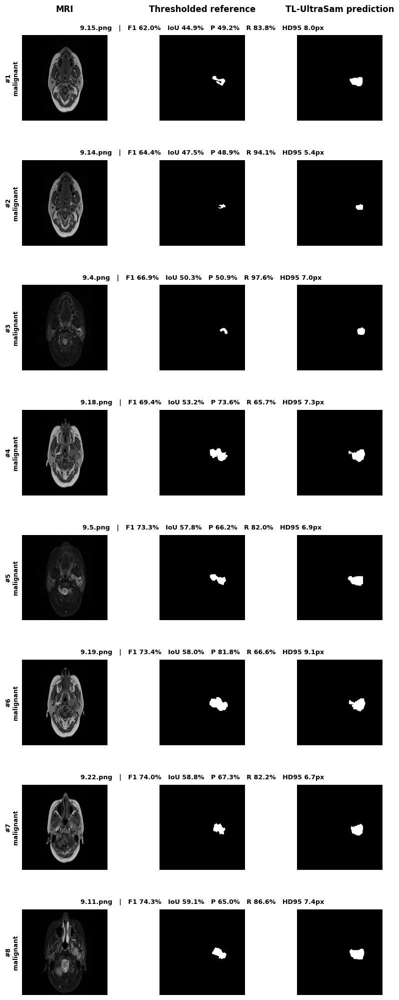


CAPTION VALIDATION
8 lowest-F1 non-normal cases: True
All malignant: True
All one inferred case: True
Evaluation size: 224 × 224
Metrics shown are the recorded per-image metrics: True

PASS:
The executed results support your proposed Figure 4 description.

FIGURE 4 EXPORT COMPLETE — 37 FILES
01. eight_lowest_F1_non_normal_results.csv
02. fig4_lowest_F1_malignant.pdf
03. fig4_lowest_F1_malignant.png
04. fig4_lowest_F1_malignant.svg
05. figure4_lowest_F1_summary.json
06. lowest_F1_01_malignant_9.15_MRI_224.png
07. lowest_F1_01_malignant_9.15_prediction_224.png
08. lowest_F1_01_malignant_9.15_reference_224.png
09. lowest_F1_01_malignant_9.15_triptych.png
10. lowest_F1_02_malignant_9.14_MRI_224.png
11. lowest_F1_02_malignant_9.14_prediction_224.png
12. lowest_F1_02_malignant_9.14_reference_224.png
13. lowest_F1_02_malignant_9.14_triptych.png
14. lowest_F1_03_malignant_9.4_MRI_224.png
15. lowest_F1_03_malignant_9.4_prediction_224.png
16. lowest_F1_03_malignant_9.4_reference_224.png
17. low

In [17]:
# ============================================================
# FIGURE 4 — EIGHT LOWEST-F1 NON-NORMAL TEST EXAMPLES
# TL-UltraSam
#
# Reproduces the selection rule from executed notebook Cell 40:
#
# worst = per_image[
#     per_image["category"] != "normal"
# ].nsmallest(8, "f1")
#
# Each row:
# MRI | thresholded reference | TL-UltraSam prediction
#
# Evaluation / display resolution:
# 224 × 224
#
# IMPORTANT
# ------------------------------------------------------------
# - NO new model inference
# - Existing saved predictions are used
# - Uses the RECORDED per-image metrics
# - Verifies that the 8 selected images are malignant
# - Verifies whether they belong to one inferred case
# - Works after a kernel restart
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

import os
import json
import shutil
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. SETTINGS
# ============================================================

N_WORST = 8

DISPLAY_MODEL_NAME = "TL-UltraSam"

EVAL_SIZE = int(
    globals().get(
        "CMP_SIZE",
        224
    )
)


# ============================================================
# 2. RESTORE RUN DIRECTORY
# ============================================================

if "run_dir" not in globals():

    run_dir = (
        r"C:\Users\pro\Pretoid Dataset Models"
        r"\Pretoid Dataset Models"
        r"\parotid_pg_benchmark"
        r"\ultrasam_box_prompt_partial_finetune"
        r"\seed42"
    )


run_dir = Path(
    run_dir
)


if not run_dir.exists():

    raise FileNotFoundError(
        "TL-UltraSam run directory was not found:\n"
        f"{run_dir}"
    )


print(
    "=" * 110
)

print(
    "FIGURE 4 — EIGHT LOWEST-F1 NON-NORMAL TEST EXAMPLES"
)

print(
    "=" * 110
)

print(
    "\nRun directory:"
)

print(
    run_dir
)


# ============================================================
# 3. OUTPUT DIRECTORY
# ============================================================

FIG4_DIR = (
    run_dir
    / "figures"
    / "Figure4_lowest_F1_malignant_results"
)


FIG4_DIR.mkdir(
    parents=True,
    exist_ok=True
)


print(
    "\nOutput directory:"
)

print(
    FIG4_DIR
)


# ============================================================
# 4. RESTORE MASK CONFIGURATION
# ============================================================

if "MASK_TARGET" not in globals():

    MASK_TARGET = "whole_parotid"


if "WHOLE_PAROTID_THRESHOLD" not in globals():

    WHOLE_PAROTID_THRESHOLD = 127


if "LESION_THRESHOLD" not in globals():

    LESION_THRESHOLD = 250


# ============================================================
# 5. RESTORE label_to_binary()
# ============================================================

if "label_to_binary" not in globals():

    def label_to_binary(
        mask,
        target=None
    ):

        """
        Convert original grayscale annotation to
        the binary segmentation target used by the notebook.
        """

        if target is None:

            target = MASK_TARGET


        mask = np.asarray(
            mask
        )


        if target == "whole_parotid":

            return (
                mask
                >= WHOLE_PAROTID_THRESHOLD
            ).astype(
                np.uint8
            )


        elif target == "lesion_only":

            return (
                mask
                >= LESION_THRESHOLD
            ).astype(
                np.uint8
            )


        else:

            raise ValueError(
                f"Unknown MASK_TARGET: {target}"
            )


    print(
        "\nRestored label_to_binary()."
    )


# ============================================================
# 6. LOAD per_image_metrics.csv
# ============================================================
#
# Prefer the DataFrame already in memory.
# Otherwise search the executed run directory.
# ============================================================

metrics_path = None


if (
    "per_image" in globals()
    and
    isinstance(
        per_image,
        pd.DataFrame
    )
    and
    len(
        per_image
    ) > 0
):

    metrics_df = (
        per_image.copy()
    )


    print(
        "\nUsing per_image metrics from notebook memory."
    )


else:

    candidate_metric_files = [

        run_dir
        / "results"
        / "per_image_metrics.csv",

        run_dir
        / "official_test_transfer"
        / "per_image_metrics.csv",

        run_dir
        / "test_results"
        / "per_image_metrics.csv",

        run_dir
        / "per_image_metrics.csv",
    ]


    for candidate in candidate_metric_files:

        if candidate.exists():

            metrics_path = candidate

            break


    # --------------------------------------------------------
    # Recursive fallback
    # --------------------------------------------------------

    if metrics_path is None:

        found_metrics = sorted(
            run_dir.rglob(
                "per_image_metrics.csv"
            )
        )


        if len(
            found_metrics
        ) > 0:

            # Prefer a file inside /results/
            preferred = [
                p
                for p in found_metrics
                if p.parent.name.lower()
                == "results"
            ]


            if preferred:

                metrics_path = (
                    preferred[0]
                )

            else:

                metrics_path = (
                    found_metrics[0]
                )


    if metrics_path is None:

        raise FileNotFoundError(
            "Could not locate per_image_metrics.csv.\n\n"
            "Run the comparable test-metrics cell first.\n\n"
            f"Searched inside:\n{run_dir}"
        )


    print(
        "\nLoading recorded per-image metrics:"
    )

    print(
        metrics_path
    )


    metrics_df = pd.read_csv(
        metrics_path
    )


print(
    f"\nLoaded {len(metrics_df)} evaluated test images."
)


# ============================================================
# 7. VALIDATE METRIC COLUMNS
# ============================================================

required_columns = {

    "image",
    "category",
    "f1",
    "jaccard",
    "precision",
    "recall",
    "acc",
    "hd95",
}


missing_columns = sorted(
    required_columns
    -
    set(
        metrics_df.columns
    )
)


if missing_columns:

    raise RuntimeError(
        "per_image_metrics.csv is missing columns:\n"
        f"{missing_columns}\n\n"
        "Available columns:\n"
        f"{list(metrics_df.columns)}"
    )


numeric_columns = [

    "f1",
    "jaccard",
    "precision",
    "recall",
    "acc",
    "hd95",
]


for column in numeric_columns:

    metrics_df[
        column
    ] = pd.to_numeric(
        metrics_df[
            column
        ],
        errors="coerce"
    )


metrics_df = (
    metrics_df
    .dropna(
        subset=[
            "f1"
        ]
    )
    .reset_index(
        drop=True
    )
)


# ============================================================
# 8. EXACT CELL-40 SELECTION
# ============================================================
#
# IMPORTANT:
# We DO NOT pre-filter malignant.
#
# We reproduce Cell 40:
#
#   non-normal -> lowest 8 F1
#
# Then we verify whether all selected cases are malignant.
# ============================================================

non_normal_metrics = (
    metrics_df[
        metrics_df[
            "category"
        ]
        .astype(str)
        .str.strip()
        .str.lower()
        != "normal"
    ]
    .copy()
)


if len(
    non_normal_metrics
) == 0:

    raise RuntimeError(
        "No non-normal test images found."
    )


worst = (
    non_normal_metrics
    .nsmallest(
        N_WORST,
        "f1"
    )
    .copy()
    .reset_index(
        drop=True
    )
)


print(
    "\n"
    + "=" * 110
)

print(
    "EXECUTED CELL-40 SELECTION — 8 LOWEST-F1 NON-NORMAL TEST IMAGES"
)

print(
    "=" * 110
)


preview_columns = [

    "image",
    "category",
    "f1",
    "jaccard",
    "precision",
    "recall",
    "hd95",
]


print(
    worst[
        preview_columns
    ]
    .round(
        4
    )
    .to_string(
        index=False
    )
)


# ============================================================
# 9. VERIFY ALL ARE MALIGNANT
# ============================================================

selected_categories = (

    worst[
        "category"
    ]
    .astype(str)
    .str.strip()
    .str.lower()
    .tolist()
)


all_malignant = all(
    category
    == "malignant"

    for category
    in selected_categories
)


print(
    "\nAll eight selected images malignant:",
    all_malignant
)


if not all_malignant:

    print(
        "\nWARNING:"
    )

    print(
        "The current executed results do NOT support the "
        "caption statement that all eight are malignant."
    )

    print(
        "Selected categories:",
        selected_categories
    )


# ============================================================
# 10. FIND TEST MANIFEST ROOT
# ============================================================

def find_test_manifest_root(
    root
):

    root = Path(
        root
    )


    direct_candidates = [

        root
        / "coco",

        root
        / "UltraSAM_COCO",

        root
        / "ultrasam_coco",

        root
        / "coco_dataset",
    ]


    for candidate in direct_candidates:

        if (
            candidate
            / "test"
            / "manifest.json"
        ).exists():

            return candidate


    manifests = sorted(
        root.rglob(
            "manifest.json"
        )
    )


    for manifest in manifests:

        if (
            manifest.parent.name.lower()
            == "test"
        ):

            return (
                manifest
                .parent
                .parent
            )


    return None


if "ULTRA_COCO_ROOT" not in globals():

    ULTRA_COCO_ROOT = (
        find_test_manifest_root(
            run_dir
        )
    )


if ULTRA_COCO_ROOT is None:

    raise FileNotFoundError(
        "Could not locate the TL-UltraSam "
        "test manifest."
    )


ULTRA_COCO_ROOT = Path(
    ULTRA_COCO_ROOT
)


manifest_path = (
    ULTRA_COCO_ROOT
    / "test"
    / "manifest.json"
)


if not manifest_path.exists():

    raise FileNotFoundError(
        manifest_path
    )


print(
    "\nTest manifest:"
)

print(
    manifest_path
)


# ============================================================
# 11. LOAD TEST MANIFEST
# ============================================================

with open(
    manifest_path,
    "r",
    encoding="utf-8"
) as f:

    test_manifest = json.load(
        f
    )


if len(
    test_manifest
) == 0:

    raise RuntimeError(
        "Test manifest is empty."
    )


print(
    "\nManifest test images:",
    len(
        test_manifest
    )
)


# ============================================================
# 12. FIND SAVED PREDICTION DIRECTORY
# ============================================================

prediction_candidates = []


if "pred_mask_dir" in globals():

    prediction_candidates.append(
        Path(
            pred_mask_dir
        )
    )


prediction_candidates.extend(
    [

        run_dir
        / "official_test_transfer"
        / "pred_masks",

        run_dir
        / "pred_masks",

        run_dir
        / "test_predictions",

        run_dir
        / "predictions",
    ]
)


prediction_dir = None


for candidate in prediction_candidates:

    if (
        candidate.exists()
        and
        candidate.is_dir()
        and
        len(
            list(
                candidate.glob(
                    "*.png"
                )
            )
        ) > 0
    ):

        prediction_dir = candidate

        break


# ------------------------------------------------------------
# Recursive fallback
# ------------------------------------------------------------

if prediction_dir is None:

    possible_dirs = []


    for directory in run_dir.rglob(
        "*"
    ):

        if not directory.is_dir():

            continue


        if "pred" not in directory.name.lower():

            continue


        pngs = list(
            directory.glob(
                "*.png"
            )
        )


        if len(
            pngs
        ) > 0:

            possible_dirs.append(
                directory
            )


    if possible_dirs:

        prediction_dir = (
            possible_dirs[0]
        )


if prediction_dir is None:

    raise FileNotFoundError(
        "Could not locate saved TL-UltraSam "
        "prediction masks."
    )


print(
    "\nPrediction directory:"
)

print(
    prediction_dir
)


# ============================================================
# 13. IMAGE HELPERS
# ============================================================

def imread_gray(
    path
):

    path = Path(
        path
    )


    if not path.exists():

        raise FileNotFoundError(
            path
        )


    data = np.fromfile(
        str(
            path
        ),
        dtype=np.uint8
    )


    image = cv2.imdecode(
        data,
        cv2.IMREAD_GRAYSCALE
    )


    if image is None:

        raise RuntimeError(
            f"Could not decode:\n{path}"
        )


    return image


def imread_bgr(
    path
):

    path = Path(
        path
    )


    if not path.exists():

        raise FileNotFoundError(
            path
        )


    data = np.fromfile(
        str(
            path
        ),
        dtype=np.uint8
    )


    image = cv2.imdecode(
        data,
        cv2.IMREAD_COLOR
    )


    if image is None:

        raise RuntimeError(
            f"Could not decode:\n{path}"
        )


    return image


def normalize_rel(
    path
):

    return (
        str(
            path
        )
        .replace(
            "\\",
            "/"
        )
        .lower()
        .strip()
    )


# ============================================================
# 14. MANIFEST LOOKUPS
# ============================================================

manifest_by_rel = {}

manifest_by_filename = {}


for item in test_manifest:

    rel = normalize_rel(
        item.get(
            "rel_image",
            ""
        )
    )


    if rel:

        manifest_by_rel[
            rel
        ] = item


    if "image_path" not in item:

        continue


    filename = (
        Path(
            item[
                "image_path"
            ]
        )
        .name
        .lower()
    )


    manifest_by_filename.setdefault(
        filename,
        []
    ).append(
        item
    )


# ============================================================
# 15. LOAD SPLIT/GROUP TABLE
# ============================================================
#
# Needed to verify:
#
# "all belong to one inferred case"
# ============================================================

group_df = None


if (
    "df" in globals()
    and
    isinstance(
        df,
        pd.DataFrame
    )
    and
    {
        "Rel_Image",
        "Initial_Group"
    }.issubset(
        df.columns
    )
):

    group_df = (
        df.copy()
    )


else:

    split_candidates = []


    if "split_csv" in globals():

        split_candidates.append(
            Path(
                split_csv
            )
        )


    # Notebook saves:
    # benchmark_root/splits/
    # split_patient_group_noleak_seed42.csv

    split_candidates.extend(
        sorted(
            run_dir
            .parent
            .parent
            .rglob(
                "split_patient_group_noleak_seed*.csv"
            )
        )
    )


    split_path = None


    for candidate in split_candidates:

        if candidate.exists():

            split_path = candidate

            break


    if split_path is not None:

        print(
            "\nLoading inferred-case assignments:"
        )

        print(
            split_path
        )


        group_df = pd.read_csv(
            split_path
        )


    else:

        print(
            "\nWARNING:"
            " split/group CSV not found."
        )


# ============================================================
# 16. FIND INFERRED CASE FOR EACH SELECTED IMAGE
# ============================================================

def find_initial_group(
    metric_row
):

    if group_df is None:

        return None


    metric_rel = normalize_rel(
        metric_row[
            "image"
        ]
    )


    # --------------------------------------------------------
    # Preferred exact relative-path match
    # --------------------------------------------------------

    if "Rel_Image" in group_df.columns:

        rel_series = (
            group_df[
                "Rel_Image"
            ]
            .astype(str)
            .map(
                normalize_rel
            )
        )


        match = (
            group_df[
                rel_series
                ==
                metric_rel
            ]
        )


        if len(
            match
        ) == 1:

            return str(
                match.iloc[
                    0
                ][
                    "Initial_Group"
                ]
            )


    # --------------------------------------------------------
    # Fallback by category + filename
    # --------------------------------------------------------

    filename = (
        Path(
            metric_row[
                "image"
            ]
        )
        .name
        .lower()
    )


    subset = group_df.copy()


    if "Category" in subset.columns:

        subset = subset[
            subset[
                "Category"
            ]
            .astype(str)
            .str.strip()
            .str.lower()
            ==
            str(
                metric_row[
                    "category"
                ]
            )
            .strip()
            .lower()
        ]


    if "Rel_Image" in subset.columns:

        match = subset[
            subset[
                "Rel_Image"
            ]
            .astype(str)
            .map(
                lambda p:
                Path(p)
                .name
                .lower()
            )
            ==
            filename
        ]


        if len(
            match
        ) == 1:

            return str(
                match.iloc[
                    0
                ][
                    "Initial_Group"
                ]
            )


    return None


worst[
    "Initial_Group"
] = worst.apply(
    find_initial_group,
    axis=1
)


resolved_groups = (

    worst[
        "Initial_Group"
    ]
    .dropna()
    .astype(str)
    .unique()
    .tolist()
)


all_one_inferred_case = (
    len(
        resolved_groups
    )
    == 1
    and
    worst[
        "Initial_Group"
    ]
    .notna()
    .all()
)


print(
    "\nAll eight belong to one inferred case:",
    all_one_inferred_case
)


print(
    "Resolved inferred case group(s):",
    resolved_groups
)


if not all_one_inferred_case:

    print(
        "\nWARNING:"
    )

    print(
        "The current data do not verify the statement "
        "'all belong to one inferred case'."
    )


# ============================================================
# 17. EXPORT EACH LOWEST-F1 CASE
# ============================================================

export_rows = []

loaded_cases = []


for rank, row in worst.iterrows():

    rank_num = (
        rank
        + 1
    )


    rel = normalize_rel(
        row[
            "image"
        ]
    )


    # --------------------------------------------------------
    # Manifest lookup
    # --------------------------------------------------------

    item = manifest_by_rel.get(
        rel
    )


    if item is None:

        filename = (
            Path(
                row[
                    "image"
                ]
            )
            .name
            .lower()
        )


        candidates = (
            manifest_by_filename.get(
                filename,
                []
            )
        )


        metric_category = (
            str(
                row[
                    "category"
                ]
            )
            .strip()
            .lower()
        )


        same_category = [

            candidate

            for candidate
            in candidates

            if (
                str(
                    candidate.get(
                        "category",
                        ""
                    )
                )
                .strip()
                .lower()
                ==
                metric_category
            )
        ]


        if same_category:

            candidates = (
                same_category
            )


        if len(
            candidates
        ) == 0:

            raise RuntimeError(
                "Could not match metrics row "
                "to test manifest:\n"
                f"{row['image']}"
            )


        item = (
            candidates[0]
        )


    # --------------------------------------------------------
    # Paths
    # --------------------------------------------------------

    image_id = int(
        item[
            "image_id"
        ]
    )


    image_path = Path(
        item[
            "image_path"
        ]
    )


    mask_path = Path(
        item[
            "mask_path"
        ]
    )


    pred_path = (
        prediction_dir
        / f"{image_id}.png"
    )


    if not pred_path.exists():

        raise FileNotFoundError(
            "Saved TL-UltraSam prediction "
            "not found:\n"
            f"{pred_path}"
        )


    # ========================================================
    # 18. MRI AT 224 × 224
    # ========================================================

    image_bgr = imread_bgr(
        image_path
    )


    image_eval = cv2.resize(
        image_bgr,
        (
            EVAL_SIZE,
            EVAL_SIZE
        ),
        interpolation=cv2.INTER_LINEAR
    )


    image_rgb = cv2.cvtColor(
        image_eval,
        cv2.COLOR_BGR2RGB
    )


    # ========================================================
    # 19. THRESHOLDED REFERENCE AT 224 × 224
    # ========================================================

    gt_raw = imread_gray(
        mask_path
    )


    gt_binary = (
        label_to_binary(
            gt_raw
        )
        > 0
    ).astype(
        np.uint8
    )


    gt_eval = cv2.resize(
        gt_binary,
        (
            EVAL_SIZE,
            EVAL_SIZE
        ),
        interpolation=cv2.INTER_NEAREST
    )


    gt_eval = (
        gt_eval
        > 0
    ).astype(
        np.uint8
    )


    # ========================================================
    # 20. SAVED TL-ULTRASAM PREDICTION AT 224 × 224
    # ========================================================

    pred_native = (
        imread_gray(
            pred_path
        )
        > 127
    ).astype(
        np.uint8
    )


    pred_eval = cv2.resize(
        pred_native,
        (
            EVAL_SIZE,
            EVAL_SIZE
        ),
        interpolation=cv2.INTER_NEAREST
    )


    pred_eval = (
        pred_eval
        > 0
    ).astype(
        np.uint8
    )


    # ========================================================
    # 21. FILE PREFIX
    # ========================================================

    base = (
        f"lowest_F1_{rank_num:02d}_"
        f"{row['category']}_"
        f"{image_path.stem}"
    )


    # ========================================================
    # 22. SAVE INDIVIDUAL MRI / GT / PREDICTION
    # ========================================================

    cv2.imwrite(
        str(
            FIG4_DIR
            / f"{base}_MRI_224.png"
        ),
        image_eval
    )


    cv2.imwrite(
        str(
            FIG4_DIR
            / f"{base}_reference_224.png"
        ),
        gt_eval
        * 255
    )


    cv2.imwrite(
        str(
            FIG4_DIR
            / f"{base}_prediction_224.png"
        ),
        pred_eval
        * 255
    )


    # ========================================================
    # 23. INDIVIDUAL 3-PANEL RESULT
    # ========================================================

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(
            8.0,
            2.85
        )
    )


    axes[
        0
    ].imshow(
        image_rgb
    )


    axes[
        0
    ].set_title(
        "MRI",
        fontsize=10,
        fontweight="bold"
    )


    axes[
        1
    ].imshow(
        gt_eval,
        cmap="gray",
        vmin=0,
        vmax=1
    )


    axes[
        1
    ].set_title(
        "Thresholded reference",
        fontsize=10,
        fontweight="bold"
    )


    axes[
        2
    ].imshow(
        pred_eval,
        cmap="gray",
        vmin=0,
        vmax=1
    )


    axes[
        2
    ].set_title(
        f"{DISPLAY_MODEL_NAME} prediction",
        fontsize=10,
        fontweight="bold"
    )


    for ax in axes:

        ax.axis(
            "off"
        )


    # --------------------------------------------------------
    # RECORDED metrics only
    # --------------------------------------------------------

    title = (
        f"{image_path.name} | "
        f"F1 {100 * row['f1']:.1f}% | "
        f"IoU {100 * row['jaccard']:.1f}% | "
        f"P {100 * row['precision']:.1f}% | "
        f"R {100 * row['recall']:.1f}% | "
        f"HD95 {row['hd95']:.1f}px"
    )


    fig.suptitle(
        title,
        fontsize=10.2,
        fontweight="bold"
    )


    plt.tight_layout()


    triptych_path = (
        FIG4_DIR
        / f"{base}_triptych.png"
    )


    plt.savefig(
        triptych_path,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )


    plt.close(
        fig
    )


    # ========================================================
    # 24. STORE FOR FINAL COMBINED FIGURE
    # ========================================================

    loaded_cases.append(
        {

            "rank":
                rank_num,

            "MRI":
                image_rgb,

            "GT":
                gt_eval,

            "Prediction":
                pred_eval,

            "filename":
                image_path.name,

            "row":
                row,
        }
    )


    export_rows.append(
        {

            "rank":
                int(
                    rank_num
                ),

            "image_id":
                int(
                    image_id
                ),

            "filename":
                image_path.name,

            "category":
                str(
                    row[
                        "category"
                    ]
                ),

            "Initial_Group":
                row[
                    "Initial_Group"
                ],

            "f1":
                float(
                    row[
                        "f1"
                    ]
                ),

            "f1_percent":
                float(
                    100
                    *
                    row[
                        "f1"
                    ]
                ),

            "jaccard":
                float(
                    row[
                        "jaccard"
                    ]
                ),

            "iou_percent":
                float(
                    100
                    *
                    row[
                        "jaccard"
                    ]
                ),

            "precision":
                float(
                    row[
                        "precision"
                    ]
                ),

            "recall":
                float(
                    row[
                        "recall"
                    ]
                ),

            "accuracy":
                float(
                    row[
                        "acc"
                    ]
                ),

            "hd95":
                float(
                    row[
                        "hd95"
                    ]
                ),

            "gt_area_224":
                int(
                    gt_eval.sum()
                ),

            "pred_area_224":
                int(
                    pred_eval.sum()
                ),
        }
    )


# ============================================================
# 25. SAVE EXACT RANKING TABLE
# ============================================================

worst_table = pd.DataFrame(
    export_rows
)


csv_path = (
    FIG4_DIR
    / "eight_lowest_F1_non_normal_results.csv"
)


worst_table.to_csv(
    csv_path,
    index=False
)


# ============================================================
# 26. PRINT EXACT RECORDED RESULTS
# ============================================================

print(
    "\n"
    + "=" * 125
)

print(
    "EIGHT LOWEST-F1 NON-NORMAL TEST EXAMPLES"
)

print(
    "=" * 125
)


print_table = (
    worst_table[
        [
            "rank",
            "filename",
            "category",
            "Initial_Group",
            "f1_percent",
            "iou_percent",
            "precision",
            "recall",
            "hd95",
        ]
    ]
    .copy()
)


print_table[
    "f1_percent"
] = (
    print_table[
        "f1_percent"
    ]
    .round(
        2
    )
)


print_table[
    "iou_percent"
] = (
    print_table[
        "iou_percent"
    ]
    .round(
        2
    )
)


print_table[
    "precision"
] = (
    100
    *
    print_table[
        "precision"
    ]
).round(
    2
)


print_table[
    "recall"
] = (
    100
    *
    print_table[
        "recall"
    ]
).round(
    2
)


print_table[
    "hd95"
] = (
    print_table[
        "hd95"
    ]
    .round(
        2
    )
)


print(
    print_table.to_string(
        index=False
    )
)


print(
    "=" * 125
)


# ============================================================
# 27. FINAL COMBINED PUBLICATION FIGURE
#
# 8 rows × 3 columns
#
# MRI | Thresholded reference | Prediction
#
# Row titles use RECORDED metrics.
# ============================================================

n_rows = len(
    loaded_cases
)


fig, axes = plt.subplots(
    n_rows,
    3,
    figsize=(
        9.0,
        2.55
        * n_rows
    )
)


axes = np.atleast_2d(
    axes
)


for row_idx, case in enumerate(
    loaded_cases
):

    metric = (
        case[
            "row"
        ]
    )


    # --------------------------------------------------------
    # MRI
    # --------------------------------------------------------

    axes[
        row_idx,
        0
    ].imshow(
        case[
            "MRI"
        ]
    )


    # --------------------------------------------------------
    # Reference
    # --------------------------------------------------------

    axes[
        row_idx,
        1
    ].imshow(
        case[
            "GT"
        ],
        cmap="gray",
        vmin=0,
        vmax=1
    )


    # --------------------------------------------------------
    # Prediction
    # --------------------------------------------------------

    axes[
        row_idx,
        2
    ].imshow(
        case[
            "Prediction"
        ],
        cmap="gray",
        vmin=0,
        vmax=1
    )


    # --------------------------------------------------------
    # Remove ticks
    # --------------------------------------------------------

    for column in range(
        3
    ):

        axes[
            row_idx,
            column
        ].set_xticks(
            []
        )

        axes[
            row_idx,
            column
        ].set_yticks(
            []
        )


        for spine in (
            axes[
                row_idx,
                column
            ]
            .spines
            .values()
        ):

            spine.set_visible(
                False
            )


    # --------------------------------------------------------
    # Recorded per-image metrics above each row
    # --------------------------------------------------------

    row_title = (
        f"{case['filename']}   |   "
        f"F1 {100 * metric['f1']:.1f}%   "
        f"IoU {100 * metric['jaccard']:.1f}%   "
        f"P {100 * metric['precision']:.1f}%   "
        f"R {100 * metric['recall']:.1f}%   "
        f"HD95 {metric['hd95']:.1f}px"
    )


    axes[
        row_idx,
        1
    ].set_title(
        row_title,
        fontsize=9.2,
        fontweight="bold",
        pad=8
    )


    # --------------------------------------------------------
    # Rank + category at left
    # --------------------------------------------------------

    axes[
        row_idx,
        0
    ].set_ylabel(
        (
            f"#{case['rank']}\n"
            f"malignant"
        ),
        fontsize=8.8,
        fontweight="bold"
    )


# ============================================================
# 28. COLUMN HEADERS
# ============================================================

axes[
    0,
    0
].text(
    0.5,
    1.25,
    "MRI",
    transform=axes[
        0,
        0
    ].transAxes,
    ha="center",
    va="bottom",
    fontsize=12,
    fontweight="bold"
)


axes[
    0,
    1
].text(
    0.5,
    1.25,
    "Thresholded reference",
    transform=axes[
        0,
        1
    ].transAxes,
    ha="center",
    va="bottom",
    fontsize=12,
    fontweight="bold"
)


axes[
    0,
    2
].text(
    0.5,
    1.25,
    f"{DISPLAY_MODEL_NAME} prediction",
    transform=axes[
        0,
        2
    ].transAxes,
    ha="center",
    va="bottom",
    fontsize=12,
    fontweight="bold"
)


# ============================================================
# 29. LAYOUT
# ============================================================

plt.subplots_adjust(
    left=0.09,
    right=0.99,
    top=0.96,
    bottom=0.02,
    wspace=0.06,
    hspace=0.46
)


# ============================================================
# 30. SAVE FINAL FIGURE
# ============================================================

final_png = (
    FIG4_DIR
    / "fig4_lowest_F1_malignant.png"
)


final_pdf = (
    FIG4_DIR
    / "fig4_lowest_F1_malignant.pdf"
)


final_svg = (
    FIG4_DIR
    / "fig4_lowest_F1_malignant.svg"
)


plt.savefig(
    final_png,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)


plt.savefig(
    final_pdf,
    bbox_inches="tight",
    facecolor="white"
)


plt.savefig(
    final_svg,
    bbox_inches="tight",
    facecolor="white"
)


plt.show()


plt.close(
    fig
)


# ============================================================
# 31. SAVE JSON SUMMARY
# ============================================================

summary_json = {

    "figure":
        "Figure 4",

    "selection_rule":
        (
            'per_image[per_image["category"] '
            '!= "normal"].nsmallest(8, "f1")'
        ),

    "selection_source":
        "executed notebook Cell 40",

    "evaluation_resolution":
        [
            EVAL_SIZE,
            EVAL_SIZE
        ],

    "number_of_examples":
        int(
            len(
                worst_table
            )
        ),

    "all_malignant":
        bool(
            all_malignant
        ),

    "all_one_inferred_case":
        bool(
            all_one_inferred_case
        ),

    "resolved_inferred_case_groups":
        resolved_groups,

    "results":
        export_rows,
}


json_path = (
    FIG4_DIR
    / "figure4_lowest_F1_summary.json"
)


with open(
    json_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        summary_json,
        f,
        indent=4,
        ensure_ascii=False
    )


# ============================================================
# 32. CAPTION VALIDATION
# ============================================================

print(
    "\n"
    + "=" * 110
)

print(
    "CAPTION VALIDATION"
)

print(
    "=" * 110
)


print(
    "8 lowest-F1 non-normal cases:",
    len(
        worst_table
    )
    == 8
)


print(
    "All malignant:",
    all_malignant
)


print(
    "All one inferred case:",
    all_one_inferred_case
)


print(
    "Evaluation size:",
    f"{EVAL_SIZE} × {EVAL_SIZE}"
)


print(
    "Metrics shown are the recorded per-image metrics:",
    True
)


print(
    "=" * 110
)


if (
    all_malignant
    and
    all_one_inferred_case
):

    print(
        "\nPASS:"
    )

    print(
        "The executed results support your proposed "
        "Figure 4 description."
    )

else:

    print(
        "\nWARNING:"
    )

    print(
        "Do not use the current caption unchanged "
        "until the failed statement above is corrected."
    )


# ============================================================
# 33. ZIP ALL OUTPUTS
# ============================================================

zip_base = (
    run_dir
    / "figures"
    / "Figure4_lowest_F1_malignant_results"
)


zip_path = shutil.make_archive(
    str(
        zip_base
    ),
    "zip",
    root_dir=str(
        FIG4_DIR
    )
)


# ============================================================
# 34. SHOW OUTPUT LIST
# ============================================================

output_files = sorted(
    [
        p
        for p
        in FIG4_DIR.iterdir()
        if p.is_file()
    ]
)


print(
    "\n"
    + "=" * 110
)

print(
    f"FIGURE 4 EXPORT COMPLETE — "
    f"{len(output_files)} FILES"
)

print(
    "=" * 110
)


for index, path in enumerate(
    output_files,
    start=1
):

    print(
        f"{index:02d}. {path.name}"
    )


print(
    "\nZIP FILE:"
)

print(
    zip_path
)


print(
    "\nDONE."
)

Created lowest malignant cases from malignant_metrics.

Selected 7 lowest-F1 malignant cases.


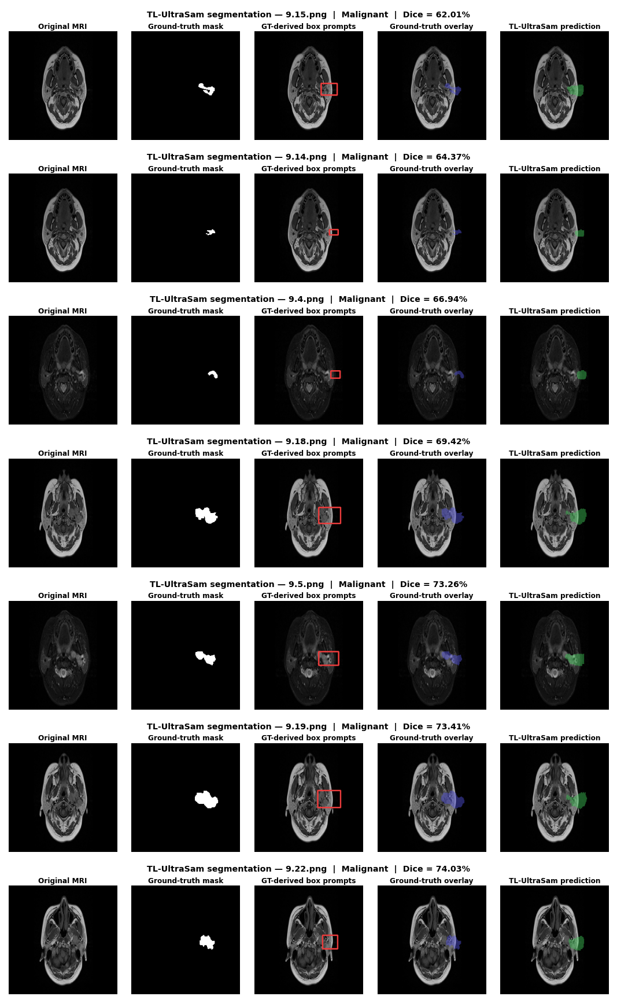


EIGHT LOWEST-F1 MALIGNANT EXAMPLES
 rank filename  category  dice_percent  iou_percent  precision  recall  hd95
    1 9.15.png Malignant         62.01        44.93     0.4920  0.8384  8.03
    2 9.14.png Malignant         64.37        47.46     0.4891  0.9412  5.38
    3  9.4.png Malignant         66.94        50.31     0.5094  0.9759  7.00
    4 9.18.png Malignant         69.42        53.16     0.7361  0.6568  7.28
    5  9.5.png Malignant         73.26        57.81     0.6619  0.8202  6.94
    6 9.19.png Malignant         73.41        58.00     0.8182  0.6658  9.06
    7 9.22.png Malignant         74.03        58.77     0.6733  0.8221  6.71

Saved PDF:
C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models\parotid_pg_benchmark\ultrasam_box_prompt_partial_finetune\seed42\figures\Figure_lowest_F1_malignant_benign_style\lowest_F1_malignant_benign_style.pdf

Saved PNG:
C:\Users\pro\Pretoid Dataset Models\Pretoid Dataset Models\parotid_pg_benchmark\ultrasam_box_prompt_partial_finetun

In [19]:
# ============================================================
# FIGURE — EIGHT LOWEST-F1 MALIGNANT CASES
# BENIGN-STYLE 5-COLUMN QUALITATIVE DISPLAY
#
# Columns:
#   1. Original MRI
#   2. Ground-truth mask
#   3. GT-derived box prompts
#   4. Ground-truth overlay
#   5. TL-UltraSam prediction overlay
#
# Rows:
#   8 lowest-F1 malignant test examples
#
# NO NEW INFERENCE.
# Uses saved notebook predictions + recorded per-image metrics.
# ============================================================

from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. SETTINGS
# ============================================================

N_LOWEST = 7

DISPLAY_MODEL_NAME = "TL-UltraSam"

EVAL_SIZE = int(
    globals().get(
        "CMP_SIZE",
        224
    )
)


# ============================================================
# 2. SELECT LOWEST-F1 MALIGNANT CASES
# ============================================================

# If you already created lowest_F1_malignant,
# use exactly that DataFrame.

if (
    "lowest_F1_malignant" in globals()
    and
    isinstance(
        lowest_F1_malignant,
        pd.DataFrame
    )
    and
    len(
        lowest_F1_malignant
    ) > 0
):

    lowest = (
        lowest_F1_malignant
        .copy()
        .reset_index(
            drop=True
        )
    )

    print(
        "Using existing lowest_F1_malignant DataFrame."
    )


# Otherwise construct it from malignant_metrics.

elif (
    "malignant_metrics" in globals()
    and
    isinstance(
        malignant_metrics,
        pd.DataFrame
    )
):

    lowest = (
        malignant_metrics
        .nsmallest(
            N_LOWEST,
            "f1"
        )
        .copy()
        .reset_index(
            drop=True
        )
    )

    print(
        "Created lowest malignant cases from malignant_metrics."
    )


# Final fallback: construct directly from metrics_df.

elif (
    "metrics_df" in globals()
    and
    isinstance(
        metrics_df,
        pd.DataFrame
    )
):

    lowest = (
        metrics_df[
            metrics_df[
                "category"
            ]
            .astype(str)
            .str.strip()
            .str.lower()
            ==
            "malignant"
        ]
        .nsmallest(
            N_LOWEST,
            "f1"
        )
        .copy()
        .reset_index(
            drop=True
        )
    )

    print(
        "Created lowest malignant cases from metrics_df."
    )


else:

    raise RuntimeError(
        "Could not find lowest_F1_malignant, "
        "malignant_metrics, or metrics_df."
    )


# Keep maximum eight.

lowest = (
    lowest
    .head(
        N_LOWEST
    )
    .copy()
)


print(
    f"\nSelected {len(lowest)} lowest-F1 malignant cases."
)


# ============================================================
# 3. OUTPUT DIRECTORY
# ============================================================

LOWEST_DIR = (
    Path(run_dir)
    / "figures"
    / "Figure_lowest_F1_malignant_benign_style"
)


LOWEST_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 4. HELPER FUNCTIONS
# ============================================================

def safe_imread_gray(
    path
):

    path = Path(
        path
    )

    data = np.fromfile(
        str(path),
        dtype=np.uint8
    )

    image = cv2.imdecode(
        data,
        cv2.IMREAD_GRAYSCALE
    )

    if image is None:

        raise RuntimeError(
            f"Could not read:\n{path}"
        )

    return image


def safe_imread_bgr(
    path
):

    path = Path(
        path
    )

    data = np.fromfile(
        str(path),
        dtype=np.uint8
    )

    image = cv2.imdecode(
        data,
        cv2.IMREAD_COLOR
    )

    if image is None:

        raise RuntimeError(
            f"Could not read:\n{path}"
        )

    return image


def normalize_rel(
    path
):

    return (
        str(path)
        .replace(
            "\\",
            "/"
        )
        .strip()
        .lower()
    )


def normalize_boxes(
    boxes
):

    if boxes is None:

        return []


    # Single box [x,y,w,h]

    if (
        isinstance(
            boxes,
            list
        )
        and
        len(boxes) == 4
        and
        all(
            isinstance(
                x,
                (int, float)
            )
            for x in boxes
        )
    ):

        boxes = [
            boxes
        ]


    output = []


    for box in boxes:

        if (
            isinstance(
                box,
                (list, tuple)
            )
            and
            len(box) == 4
        ):

            output.append(
                [
                    int(
                        round(v)
                    )
                    for v in box
                ]
            )


    return output


# ============================================================
# 5. BUILD MANIFEST LOOKUP
# ============================================================

manifest_by_rel = {}

manifest_by_filename = {}


for item in test_manifest:

    rel = normalize_rel(
        item.get(
            "rel_image",
            ""
        )
    )


    if rel:

        manifest_by_rel[
            rel
        ] = item


    filename = (
        Path(
            item[
                "image_path"
            ]
        )
        .name
        .lower()
    )


    manifest_by_filename.setdefault(
        filename,
        []
    ).append(
        item
    )


# ============================================================
# 6. MATCH LOWEST CASES TO MANIFEST
# ============================================================

display_cases = []


for rank, row in lowest.iterrows():

    metric_rel = normalize_rel(
        row[
            "image"
        ]
    )


    item = manifest_by_rel.get(
        metric_rel
    )


    # --------------------------------------------------------
    # Fallback: filename + malignant category
    # --------------------------------------------------------

    if item is None:

        filename = (
            Path(
                row[
                    "image"
                ]
            )
            .name
            .lower()
        )


        candidates = (
            manifest_by_filename
            .get(
                filename,
                []
            )
        )


        candidates = [

            x

            for x in candidates

            if str(
                x.get(
                    "category",
                    ""
                )
            )
            .strip()
            .lower()
            ==
            "malignant"
        ]


        if len(
            candidates
        ) == 0:

            raise RuntimeError(
                "Could not match lowest-F1 case "
                "to the test manifest:\n"
                f"{row['image']}"
            )


        item = candidates[
            0
        ]


    # --------------------------------------------------------
    # Paths
    # --------------------------------------------------------

    image_id = int(
        item[
            "image_id"
        ]
    )


    image_path = Path(
        item[
            "image_path"
        ]
    )


    mask_path = Path(
        item[
            "mask_path"
        ]
    )


    pred_path = (
        Path(
            prediction_dir
        )
        /
        f"{image_id}.png"
    )


    if not pred_path.exists():

        raise FileNotFoundError(
            f"Prediction not found:\n{pred_path}"
        )


    # ========================================================
    # 7. MRI
    # ========================================================

    image_bgr_native = safe_imread_bgr(
        image_path
    )


    native_h, native_w = (
        image_bgr_native.shape[:2]
    )


    image_bgr = cv2.resize(
        image_bgr_native,
        (
            EVAL_SIZE,
            EVAL_SIZE
        ),
        interpolation=cv2.INTER_LINEAR
    )


    image_rgb = cv2.cvtColor(
        image_bgr,
        cv2.COLOR_BGR2RGB
    )


    # ========================================================
    # 8. GROUND-TRUTH MASK
    # ========================================================

    gt_raw = safe_imread_gray(
        mask_path
    )


    gt_native = (
        label_to_binary(
            gt_raw
        )
        >
        0
    ).astype(
        np.uint8
    )


    gt_eval = cv2.resize(
        gt_native,
        (
            EVAL_SIZE,
            EVAL_SIZE
        ),
        interpolation=cv2.INTER_NEAREST
    )


    gt_eval = (
        gt_eval > 0
    ).astype(
        np.uint8
    )


    # ========================================================
    # 9. SAVED TL-ULTRASAM PREDICTION
    # ========================================================

    pred_native = (
        safe_imread_gray(
            pred_path
        )
        >
        127
    ).astype(
        np.uint8
    )


    pred_eval = cv2.resize(
        pred_native,
        (
            EVAL_SIZE,
            EVAL_SIZE
        ),
        interpolation=cv2.INTER_NEAREST
    )


    pred_eval = (
        pred_eval > 0
    ).astype(
        np.uint8
    )


    # ========================================================
    # 10. GT-DERIVED BOX PROMPTS
    # ========================================================

    boxes_native = normalize_boxes(
        item.get(
            "bbox_xywh",
            []
        )
    )


    # If manifest has no boxes, derive them from GT components.

    if len(
        boxes_native
    ) == 0:

        n_labels, labels, stats, _ = (
            cv2.connectedComponentsWithStats(
                gt_native.astype(
                    np.uint8
                ),
                connectivity=8
            )
        )


        boxes_native = []


        for label_idx in range(
            1,
            n_labels
        ):

            area = int(
                stats[
                    label_idx,
                    cv2.CC_STAT_AREA
                ]
            )


            if area <= 0:

                continue


            x = int(
                stats[
                    label_idx,
                    cv2.CC_STAT_LEFT
                ]
            )

            y = int(
                stats[
                    label_idx,
                    cv2.CC_STAT_TOP
                ]
            )

            bw = int(
                stats[
                    label_idx,
                    cv2.CC_STAT_WIDTH
                ]
            )

            bh = int(
                stats[
                    label_idx,
                    cv2.CC_STAT_HEIGHT
                ]
            )


            boxes_native.append(
                [
                    x,
                    y,
                    bw,
                    bh
                ]
            )


    # --------------------------------------------------------
    # Scale native boxes to 224 × 224
    # --------------------------------------------------------

    sx = (
        EVAL_SIZE
        /
        native_w
    )

    sy = (
        EVAL_SIZE
        /
        native_h
    )


    boxes_eval = []


    for (
        x,
        y,
        bw,
        bh
    ) in boxes_native:

        boxes_eval.append(
            [
                int(
                    round(
                        x * sx
                    )
                ),
                int(
                    round(
                        y * sy
                    )
                ),
                int(
                    round(
                        bw * sx
                    )
                ),
                int(
                    round(
                        bh * sy
                    )
                )
            ]
        )


    # ========================================================
    # 11. BOX-PROMPT PANEL
    # ========================================================

    box_panel = (
        image_rgb.copy()
    )


    for (
        x,
        y,
        bw,
        bh
    ) in boxes_eval:

        cv2.rectangle(
            box_panel,
            (
                x,
                y
            ),
            (
                x + bw - 1,
                y + bh - 1
            ),
            (
                235,
                60,
                60
            ),
            2
        )


    # ========================================================
    # 12. GROUND-TRUTH OVERLAY
    # ========================================================

    gt_overlay = (
        image_rgb
        .astype(
            np.float32
        )
        .copy()
    )


    gt_fg = (
        gt_eval > 0
    )


    # Purple / blue overlay similar to attached example.

    gt_colour = np.array(
        [
            85,
            85,
            230
        ],
        dtype=np.float32
    )


    alpha = 0.45


    gt_overlay[
        gt_fg
    ] = (

        (
            1
            -
            alpha
        )
        *
        gt_overlay[
            gt_fg
        ]

        +

        alpha
        *
        gt_colour
    )


    gt_overlay = np.clip(
        gt_overlay,
        0,
        255
    ).astype(
        np.uint8
    )


    # ========================================================
    # 13. TL-ULTRASAM PREDICTION OVERLAY
    # ========================================================

    pred_overlay = (
        image_rgb
        .astype(
            np.float32
        )
        .copy()
    )


    pred_fg = (
        pred_eval > 0
    )


    pred_colour = np.array(
        [
            65,
            205,
            90
        ],
        dtype=np.float32
    )


    pred_overlay[
        pred_fg
    ] = (

        (
            1
            -
            alpha
        )
        *
        pred_overlay[
            pred_fg
        ]

        +

        alpha
        *
        pred_colour
    )


    pred_overlay = np.clip(
        pred_overlay,
        0,
        255
    ).astype(
        np.uint8
    )


    # ========================================================
    # 14. STORE FOR FIGURE
    # ========================================================

    display_cases.append(
        {

            "rank":
                rank + 1,

            "filename":
                image_path.name,

            "category":
                "Malignant",

            "dice":
                float(
                    row[
                        "f1"
                    ]
                ),

            "iou":
                float(
                    row[
                        "jaccard"
                    ]
                ),

            "precision":
                float(
                    row[
                        "precision"
                    ]
                ),

            "recall":
                float(
                    row[
                        "recall"
                    ]
                ),

            "hd95":
                float(
                    row[
                        "hd95"
                    ]
                ),

            "MRI":
                image_rgb,

            "GT":
                gt_eval,

            "BOX":
                box_panel,

            "GT_OVERLAY":
                gt_overlay,

            "PRED_OVERLAY":
                pred_overlay,
        }
    )


# ============================================================
# 15. BUILD BENIGN-STYLE PUBLICATION FIGURE
#
# For every malignant case:
#
#          centered row title
#
# MRI | GT mask | GT boxes | GT overlay | TL-UltraSam pred.
# ============================================================

n_rows = len(
    display_cases
)


# Every case uses two grid rows:
#   thin row for title
#   large row for images

height_ratios = []


for _ in range(
    n_rows
):

    height_ratios.extend(
        [
            0.17,
            1.0
        ]
    )


fig = plt.figure(
    figsize=(
        10.8,
        2.48 * n_rows
    ),
    facecolor="white"
)


gs = fig.add_gridspec(
    nrows=(
        n_rows
        * 2
    ),
    ncols=5,
    height_ratios=height_ratios,
    hspace=0.12,
    wspace=0.08
)


column_titles = [

    "Original MRI",

    "Ground-truth mask",

    "GT-derived box prompts",

    "Ground-truth overlay",

    "TL-UltraSam prediction",
]


# ============================================================
# 16. DRAW EACH MALIGNANT ROW
# ============================================================

for row_idx, case in enumerate(
    display_cases
):

    # --------------------------------------------------------
    # Full-width row title
    # --------------------------------------------------------

    title_ax = fig.add_subplot(
        gs[
            row_idx * 2,
            :
        ]
    )


    title_ax.axis(
        "off"
    )


    title_ax.text(
        0.5,
        0.50,
        (
            f"{DISPLAY_MODEL_NAME} segmentation — "
            f"{case['filename']}  |  "
            f"Malignant  |  "
            f"Dice = {100 * case['dice']:.2f}%"
        ),
        ha="center",
        va="center",
        fontsize=10.3,
        fontweight="bold"
    )


    # --------------------------------------------------------
    # Five panels
    # --------------------------------------------------------

    panels = [

        case[
            "MRI"
        ],

        case[
            "GT"
        ],

        case[
            "BOX"
        ],

        case[
            "GT_OVERLAY"
        ],

        case[
            "PRED_OVERLAY"
        ],
    ]


    for col_idx in range(
        5
    ):

        ax = fig.add_subplot(
            gs[
                row_idx * 2 + 1,
                col_idx
            ]
        )


        panel = panels[
            col_idx
        ]


        if panel.ndim == 2:

            ax.imshow(
                panel,
                cmap="gray",
                vmin=0,
                vmax=1
            )

        else:

            ax.imshow(
                panel
            )


        ax.set_title(
            column_titles[
                col_idx
            ],
            fontsize=8.7,
            fontweight="bold",
            pad=4
        )


        ax.axis(
            "off"
        )


# ============================================================
# 17. SAVE FIGURE
# ============================================================

plt.subplots_adjust(
    left=0.015,
    right=0.985,
    top=0.995,
    bottom=0.01
)


pdf_path = (
    LOWEST_DIR
    /
    "lowest_F1_malignant_benign_style.pdf"
)


png_path = (
    LOWEST_DIR
    /
    "lowest_F1_malignant_benign_style.png"
)


tiff_path = (
    LOWEST_DIR
    /
    "lowest_F1_malignant_benign_style_600dpi.tiff"
)


plt.savefig(
    pdf_path,
    bbox_inches="tight",
    pad_inches=0.03,
    facecolor="white"
)


plt.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.03,
    facecolor="white"
)


plt.savefig(
    tiff_path,
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.03,
    facecolor="white"
)


plt.show()

plt.close(
    fig
)


# ============================================================
# 18. SAVE METRICS TABLE
# ============================================================

lowest_display_table = pd.DataFrame(
    [
        {

            "rank":
                case[
                    "rank"
                ],

            "filename":
                case[
                    "filename"
                ],

            "category":
                case[
                    "category"
                ],

            "dice_percent":
                100
                *
                case[
                    "dice"
                ],

            "iou_percent":
                100
                *
                case[
                    "iou"
                ],

            "precision":
                case[
                    "precision"
                ],

            "recall":
                case[
                    "recall"
                ],

            "hd95":
                case[
                    "hd95"
                ],

        }

        for case in display_cases
    ]
)


lowest_display_table.to_csv(
    LOWEST_DIR
    /
    "lowest_F1_malignant_metrics.csv",
    index=False
)


# ============================================================
# 19. PRINT RESULTS
# ============================================================

print(
    "\n"
    + "=" * 115
)

print(
    "EIGHT LOWEST-F1 MALIGNANT EXAMPLES"
)

print(
    "=" * 115
)


print(
    lowest_display_table
    .round(
        {

            "dice_percent":
                2,

            "iou_percent":
                2,

            "precision":
                4,

            "recall":
                4,

            "hd95":
                2,
        }
    )
    .to_string(
        index=False
    )
)


print(
    "=" * 115
)


print(
    "\nSaved PDF:"
)

print(
    pdf_path
)


print(
    "\nSaved PNG:"
)

print(
    png_path
)


print(
    "\nSaved TIFF:"
)

print(
    tiff_path
)